# 04 — Forecasting the queue: will a request be built, and when

The completion and timing engine. Entry-time models (Cox, discrete-time logit and LightGBM, the all-regions model), the fair lookup baseline and the utility-scale cohort, the ten entry rules, the cohort level and its repair, the labelled leakage ablation, the dated milestones, the landmark models two years in, and the MISO/SPP extension. Criteria C6–C8, C12–C14 are registered in their parts before anything is scored.

**Inputs → Outputs**

| Part | Was | What it does |
|---|---|---|
| A | notebook 05 | Baseline predictor and cause-specific Cox models |
| B | notebook 06 | Discrete-time hazard models |
| C | notebook 07 | The all-regions model (Track B): will a request ever be built? |
| D | notebook 11 | A fair baseline and the utility-scale cohort |
| E | notebook 09 §4b | Ten entry rules a company applies by hand (F21) |
| F | notebook 01b §5 | The newest evidence on the level: 2020–2022 entrants of the 2026 edition |
| G | notebook 12 | The level: cohort drift and its repair |
| H | notebook 08 §9 | What post-entry information would add: the labelled leakage ablation |
| I | notebook 13 | Milestones after entry: the ISO queue files and the agreement dates |
| J | notebook 14 | Landmark models: what a later decision point knows |
| K | notebook 19 | MISO and SPP: timing models on the 2026 file (a registered extension) |

*Execution order:* Runs after notebook 03. Paths are relative to the repository root.

*Part A*

| | Path | Notes |
|---|---|---|
| in | `data/interim/trackA.parquet` | notebook 04 |
| out | `results/baseline_cells.csv` | baseline P(operation by 3/5/7 yr) per region × technology cell |
| out | `results/cox_penalizer_tuning.csv`, `results/cox_hazard_ratios.csv` | tuning; hazard ratios with 95% CI and p, both causes, main and sensitivity fits |
| out | `results/cox_ph_tests.csv`, `results/cox_validation_calibration.csv`, `results/cox_checks.csv` | diagnostics, validation check, acceptance checks |
| out | `data/interim/predictions_05.parquet` | baseline and Cox P(operation by 3/5/7 yr) for validation and test requests |
| out | `figures/04_forecast_queue/*.png|svg` (incl. `diag_*`), `report/figure_notes.md` | 10 figures |

*Part B*

| | Path | Notes |
|---|---|---|
| in | `data/interim/queue_clean.parquet` | notebook 02 — every request, for the yearly congestion count |
| in | `data/interim/trackA.parquet` | notebook 04 — Track A requests with entry-time features and `entry_years` |
| in | `data/interim/predictions_05.parquet`, `results/cox_validation_calibration.csv` | notebook 05 — baseline and Cox predictions, 2016 check |
| out | `results/dt_rows_summary.csv`, `results/dt_life_table.csv`, `results/dt_queue_gw.csv` | project-year sample, yearly hazards, GW waiting over time |
| out | `results/dt_cv_logit.csv`, `results/dt_cv_lgbm.csv`, `results/dt_early_stopping.csv`, `results/dt_tuning.json` | grouped cross-validation and early stopping |
| out | `results/dt_validation_2016.csv` | 2016 cohort: mean predicted vs observed, four models, frozen vs realised congestion |
| out | `results/dt_logit_odds_ratios.csv`, `results/dt_lgbm_importance.csv`, `results/dt_reference_request.csv` | what the fitted models say |
| out | `results/dt_band_check.csv`, `results/dt_cohort_check.csv`, `results/dt_checks.csv` | acceptance checks (the band check is also `tests/test_discrete_time.py`) |
| out | `data/processed/predictions_trackA.parquet` | baseline, Cox, discrete-time logit and LightGBM P(operation by 3/5/7 yr) for validation and test requests |
| out | `figures/04_forecast_queue/*.png|svg`, `report/figure_notes.md` | 17 figures |

*Part C*

| | Path | Notes |
|---|---|---|
| in | `data/interim/trackB.parquet` | notebook 04 — resolved requests entering up to 2017, all regions |
| in | `data/interim/queue_events.parquet` | notebook 04 — every request, for the share still unresolved |
| in | `data/processed/predictions_trackA.parquet` | notebook 06 — to compare the two tracks on shared requests |
| out | `results/trackB_samples.csv`, `results/trackB_base_rates.csv` | sample by region and split; region × technology base rates |
| out | `results/trackB_cv_logit.csv`, `results/trackB_cv_lgbm.csv`, `results/trackB_tuning.json` | tuning |
| out | `results/trackB_validation.csv`, `results/trackB_calibration.csv` | 2016 cohort: AUC/Brier with intervals; reliability by decile |
| out | `results/trackB_by_region.csv` | per-region calibration on 2016 and leave-one-region-out results |
| out | `results/trackB_odds_ratios.csv`, `results/trackB_lgbm_importance.csv`, `results/trackB_checks.csv` | what the models say; checks |
| out | `data/processed/predictions_trackB.parquet` | base rate, logit and LightGBM P(built), raw and calibrated, for 2016 and 2017 requests |
| out | `figures/04_forecast_queue/*.png|svg`, `report/figure_notes.md` | 13 figures |

*Part D*

| | Path | Notes |
|---|---|---|
| in | `data/interim/trackA.parquet`, `data/interim/queue_clean.parquet` | notebooks 02/04 — requests and the full clean table (congestion) |
| in | `results/dt_tuning.json` | notebook 06 — settings reused unchanged |
| in | `data/processed/predictions_trackA.parquet` | notebook 06 — the v1 predictions (K0 reference, v1 baseline) |
| in | `results/success_criteria_registered.json` | notebook 08 — bootstrap settings and seeds, reused |
| out | `results/success_criteria_v2.csv`, `results/success_criteria_v2_registered.json`, `docs/decisions.md` (#52) | the v2 criteria, written before any test metric |
| out | `results/fair_baseline_cells.csv` | every region × technology × size cell of the training data |
| out | `results/variant_choice_2016.csv` | the candidates' 2016 log loss; the choice |
| out | `results/metrics_v2.csv`, `results/metrics_v2_by_size.csv` | test metrics by cohort, against both baselines, with intervals |
| out | `results/size_check_monotone.csv` | mean P(operation by 5 years) by size band per candidate |
| out | `data/processed/predictions_v2.parquet` | test predictions of every model and baseline |
| out | `figures/F10_gains_over_baselines.*`, `figures/04_forecast_queue/*` | F10 and the notebook's figures |
| out | `results/scale_checks.csv` | this notebook's checks |

*Part E*

| | Path | Notes |
|---|---|---|
| out | `results/segments.csv`, `results/segments_by_request.csv`, `figures/F21_segments.*` | ten entry-time rules with fitting-cohort and later-cohort rates; each test request's segment (for the entry gate of notebook 09) |

*Part F*

| | Path | Notes |
|---|---|---|
| out | `results/early_incidence_2020_2022.csv` | P(operation by 1 and 2 years) of the 2020–2022 entrants, both editions |

*Part G*

| | Path | Notes |
|---|---|---|
| in | `data/interim/trackA.parquet`, `data/interim/queue_clean.parquet`, `results/dt_tuning.json` | notebooks 02/04/06 |
| in | `data/processed/predictions_v2.parquet`, `results/variant_chosen.json` | notebook 11 — the v2 model and both baselines on the test cohort |
| in | `results/early_incidence_2020_2022.csv` | notebook 01b — observed 1- and 2-year incidence of the 2020–2022 entrants, both editions |
| in | `results/success_criteria_v2_registered.json` | notebook 11 — bootstrap settings |
| out | `results/drift_by_cohort.csv`, `results/drift_by_cohort_region.csv`, `results/drift_hazards_by_cohort.csv` | the diagnosis |
| out | `results/recalibration.csv` | the rolling intercepts per scored year and region |
| out | `results/level_repair_metrics.csv` | slope and intercept with intervals, per option and cohort (C7's inputs) |
| out | `results/early_hazards_2020_2022.csv` | predicted against observed P(operation by 1 and 2 years), 2020–2022 entrants |
| out | `data/processed/predictions_v2_recalibrated.parquet` | the v2 model's raw and recalibrated test predictions |
| out | `figures/F11_level_by_entry_year.*`, `figures/04_forecast_queue/*` | F11 and the notebook's figures |
| out | `results/level_checks.csv` | this notebook's checks |

*Part H*

| | Path | Notes |
|---|---|---|
| out | `results/ablation.csv`, `figures/04_forecast_queue/08_16_leakage_ablation.*` | the labelled leakage ablation (CAISO and ERCOT): AUC and Brier with and without post-entry columns |

*Part I*

| | Path | Notes |
|---|---|---|
| in | `data/interim/trackA.parquet` | notebook 04 — the requests (2025 edition) |
| in | `data/interim/queue_clean_2026.parquet` | notebook 01b — the 2026 edition, cleaned |
| in | `data/raw/iso/caiso_queue_2026-10-06.parquet` | CAISO's public queue report via `gridstatus`, SHA-256 in `data/raw/iso/SHA256.txt` |
| in | `data/raw/iso/pjm_queue_2026-10-07.xml` | PJM's queue export (`PlanningQueues.xml`), SHA-256 recorded |
| in | `data/raw/iso/ercot_gis_2026-10-07.xlsx` | ERCOT's GIS report, September 2026 activity, SHA-256 recorded |
| out | `data/interim/milestones.parquet` | one row per Track A request: agreement date (best of both editions), phase reached, CAISO cluster and statuses |
| out | `results/iso_file_contents.csv` | what the PJM and ERCOT files date after entry for the 2017–2019 cohort, by outcome |
| out | `results/iso_join_rates.csv`, `results/milestone_coverage.csv`, `results/ia_date_agreement.csv` | join and coverage rates, honestly |
| out | `figures/04_forecast_queue/*` | the notebook's figures |
| out | `results/milestone_checks.csv` | this notebook's checks |

*Part J*

| | Path | Notes |
|---|---|---|
| in | `data/interim/trackA.parquet`, `data/interim/queue_clean.parquet`, `results/dt_tuning.json` | notebooks 02/04/06 |
| in | `data/interim/milestones.parquet` | notebook 13 — dated agreements |
| in | `results/ablation.csv` | notebook 08 — the leakage ablation's AUC (C12's ceiling) |
| in | `results/success_criteria_v2_registered.json` | notebook 11 — bootstrap settings |
| out | `results/landmark_coverage.csv` | risk sets and outcomes at each landmark |
| out | `results/landmark_metrics.csv` | Uno's C, AUC, Brier, calibration per landmark, horizon and view, with intervals and paired differences |
| out | `data/processed/predictions_landmark.parquet` | every view's prediction for every request in every risk set |
| out | `figures/F12_landmark_models.*`, `figures/04_forecast_queue/*` | F12 and the notebook's figures |
| out | `results/landmark_checks.csv` | this notebook's checks, including the leakage guard |

*Part K*

| | Path | Notes |
|---|---|---|
| in | `data/interim/queue_clean_2026.parquet` | notebook 01b — the 2026 edition through rules R2–R9 |
| in | `results/dt_tuning.json`, `results/success_criteria_v2_registered.json` | notebooks 06/11 — settings and bootstrap parameters, reused unchanged |
| out | `results/success_criteria_v3.csv`, `docs/decisions.md` (#54) | criteria C13–C14, written before any metric |
| out | `results/miso_spp_date_coverage.csv`, `results/miso_spp_samples.csv` | what the 2026 file gives each region |
| out | `results/miso_spp_metrics.csv`, `results/success_criteria_v3_scored.csv` | the metrics with intervals and the scored lines |
| out | `data/processed/predictions_miso_spp.parquet` | test predictions |
| out | `figures/F17_miso_spp.*`, `figures/04_forecast_queue/*` | F17 and the notebook's figures |
| out | `results/miso_spp_checks.csv` | this notebook's checks |

# Part A — Baseline predictor and cause-specific Cox models (was notebook 05)

This notebook builds the "industry average" baseline (region × technology
completion rates) and two cause-specific Cox models — one for reaching
operation, one for withdrawing — tunes them on the 2016 cohort, checks the
proportional-hazards assumption, and writes predictions for the validation
and test cohorts. No test outcome is looked at here; scoring is notebook 08's
job, after its success criteria are written down.

## Setup

The baseline and the Cox helpers are in `src/survival_tools.py`:
`baseline_cif` (Aalen–Johansen per cell), `cox_design` (indicator coding with
reference levels PJM, Solar, 20–<100 MW, NRIS) and `cause_specific_cif`
(turns the two cause-specific hazards into P(operation by t)). Region enters
as a covariate, not a stratum (decision #24), and ERCOT uses delayed entry
(decision #21).

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append(str(Path.cwd().resolve().parent))  # notebooks run from notebooks/; src/ is one level up
from src import config, paths, plots, survival_tools

paths.ensure_dirs()
plots.set_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

NOTEBOOK = "04_forecast_queue"
TRACK_A = config.TRACK_A_REGIONS


def save(fig, name, caption):
    """Save a figure of this notebook under figures/04_forecast_queue/ with its caption stub."""
    return plots.save_fig(fig, name, caption, NOTEBOOK, folder=NOTEBOOK)


def pct(x, digits=1):
    """Format a share as a percentage string."""
    return f"{100 * x:.{digits}f}%"

import warnings

from lifelines import CoxPHFitter
from lifelines.statistics import proportional_hazard_test

warnings.filterwarnings("ignore", category=FutureWarning)
HORIZONS = config.HORIZONS
PENALIZERS = [0.0001, 0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0, 30.0, 100.0]
CAUSES = {"operation": 1, "withdrawal": 2}


def cox_frame(frame, cause, delayed=True):
    """Design matrix plus duration, cause-specific event flag and entry time."""
    X = survival_tools.cox_design(frame)
    entry = frame["entry_years"] if delayed else pd.Series(0.0, index=frame.index)
    return X.assign(T=frame["duration_years"], E=(frame["event"] == CAUSES[cause]).astype(int), entry=entry)


def fit_cox(frame, cause, penalizer, delayed=True):
    """Fit one cause-specific Cox model (other cause treated as censoring)."""
    data = cox_frame(frame, cause, delayed)
    if delayed:
        data = data[data["T"] > data["entry"]]  # left before the window opened
        return CoxPHFitter(penalizer=penalizer).fit(data, "T", "E", entry_col="entry")
    return CoxPHFitter(penalizer=penalizer).fit(data.drop(columns="entry"), "T", "E")

## 1. Samples and splits

Tuning fits use entrants up to 2015 and are scored on the 2016 entrants; the
final fits use entrants up to 2016; predictions are made for the 2017–2019
test entrants. Under delayed entry, ERCOT projects that had already left the
queue by 2018-08-29 drop out of the fits — the table counts them.

In [2]:
track_a = pd.read_parquet(paths.DATA_INTERIM / "trackA.parquet")
track_a["tech"] = track_a["type_clean"].map(plots.tech_group)
tune = track_a[track_a["q_year"] <= config.TUNE_MAX_YEAR]
valid = track_a[track_a["q_year"] == config.VALIDATION_YEAR]
final = track_a[track_a["q_year"] <= config.TRAIN_MAX_YEAR]
test = track_a[track_a["q_year"].between(*config.TEST_YEARS)]

dropped = final[final["duration_years"] <= final["entry_years"]]
summary = pd.DataFrame({
    "requests": final.groupby("region").size(),
    "operation": final[final["event"] == 1].groupby("region").size(),
    "withdrawal": final[final["event"] == 2].groupby("region").size(),
    "left before window (delayed entry)": dropped.groupby("region").size(),
    "of which built": dropped[dropped["event"] == 1].groupby("region").size(),
}).reindex(TRACK_A).fillna(0).astype(int)
print(f"tune {len(tune):,} | validation {len(valid):,} | final fit {len(final):,} | test {len(test):,}")
summary

tune 4,725 | validation 573 | final fit 5,298 | test 2,268


,requests,operation,withdrawal,left before window (delayed entry),of which built
region,,,,,
ERCOT,732,221,483,607,176
PJM,3192,918,2228,0,0
CAISO,1374,191,1113,0,0


**Reading this.** The final fits use 5,298 requests that entered up to 2016 (tuning: 4,725 up to 2015; validation: 573 from 2016); predictions are made for 2,268 test requests. Delayed entry has a real cost: 607 of ERCOT's 732 training requests had left the queue before 2018-08-29 and so drop out of the fits — including 176 of its 221 completions. The ERCOT terms therefore rest on 125 requests observed after the window opened, while the shape of the first years in the queue is borrowed from PJM and CAISO. That is the price of not inventing withdrawal times (decision #21), and it shows in the wide ERCOT confidence interval below.

## 2. The baseline: what the industry uses today

For each request, the Aalen–Johansen probability of operation by 3, 5 and 7
years among training requests of the same region and technology; cells with
fewer than 50 training requests fall back to the region's rate.

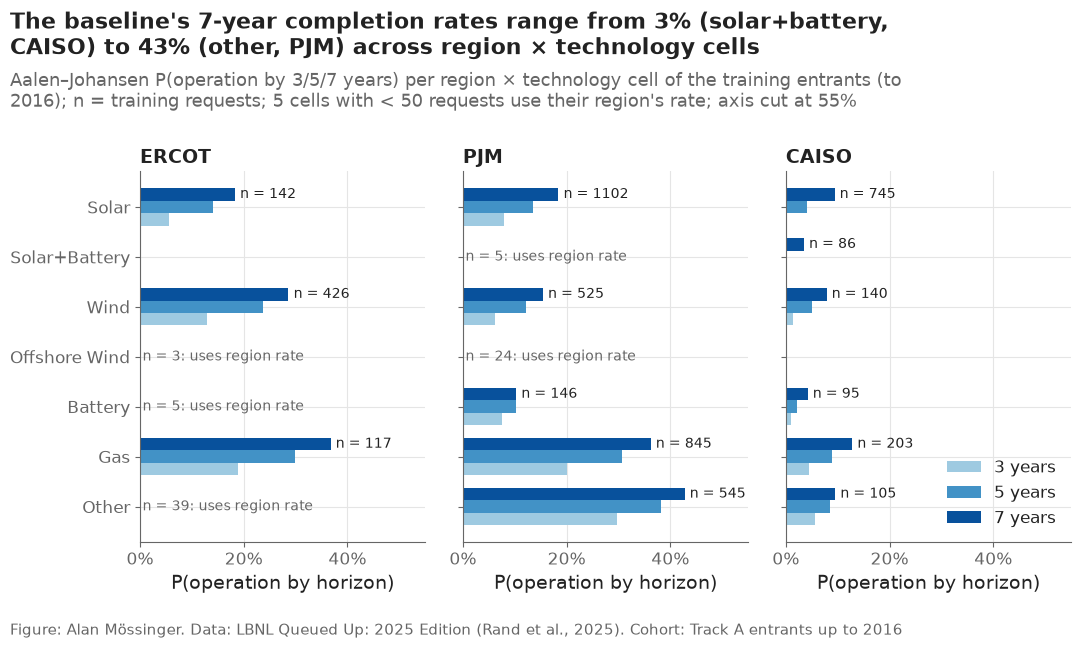

,region,tech,3,5,7,cell,n_train
1685,CAISO,Gas,0.044,0.089,0.128,region × technology,203
1682,CAISO,Other,0.057,0.086,0.095,region × technology,105
1694,CAISO,Wind,0.014,0.050,0.079,region × technology,140
1683,CAISO,Solar,0.003,0.042,0.094,region × technology,745
1690,CAISO,Battery,0.011,0.021,0.042,region × technology,95
35223,CAISO,Solar+Battery,0.000,0.000,0.035,region × technology,86
29829,ERCOT,Gas,0.188,0.299,0.368,region × technology,117
29802,ERCOT,Wind,0.129,0.237,0.286,region × technology,426
32402,ERCOT,Other,0.122,0.223,0.273,region,39
32532,ERCOT,Offshore Wind,0.122,0.223,0.273,region,3


In [3]:
baseline_final = survival_tools.baseline_cif(final, final.drop_duplicates(["region", "tech"]), HORIZONS)
cells = final.drop_duplicates(["region", "tech"])[["region", "tech"]].join(baseline_final)
cells["n_train"] = cells.apply(lambda r: int(((final["region"] == r["region"]) & (final["tech"] == r["tech"])).sum()), axis=1)
cells = cells.sort_values(["region", 5], ascending=[True, False])
cells.to_csv(paths.RESULTS / "baseline_cells.csv", index=False)

tech_order = [t for t in config.TECH_COLORS if t in set(cells["tech"])][::-1]
fig, axes = plt.subplots(1, 3, sharey=True)
shades = {3: "#9ECAE1", 5: "#4292C6", 7: "#08519C"}  # one hue, light → dark for longer horizons
for ax, region in zip(axes, TRACK_A):
    part = cells[cells["region"] == region].set_index("tech")
    for y, tech in enumerate(tech_order):
        if tech not in part.index:
            continue
        row = part.loc[tech]
        if row["cell"] == "region":
            ax.text(0.005, y, f"n = {row['n_train']}: uses region rate", va="center", fontsize=10, color=plots.MUTED)
            continue
        for offset, h in zip([-0.25, 0, 0.25], HORIZONS):
            ax.barh(y + offset, row[h], height=0.25, color=shades[h], label=f"{h} years" if y == 0 else None)
        ax.text(row[7] + 0.01, y + 0.25, f"n = {row['n_train']}", va="center", fontsize=10)
    ax.set_title(region)
    ax.set_xlim(0, 0.55)
    ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
    ax.set_xlabel("P(operation by horizon)")
axes[0].set_yticks(range(len(tech_order)), tech_order)
handles = [plt.Rectangle((0, 0), 1, 1, color=shades[h]) for h in HORIZONS]
axes[-1].legend(handles, [f"{h} years" for h in HORIZONS], loc="lower right")
fallback = cells[cells["cell"] == "region"]
own = cells[cells["cell"] == "region × technology"]
lowest, highest = own.loc[own[7].idxmin()], own.loc[own[7].idxmax()]
plots.finish(fig,
             f"The baseline's 7-year completion rates range from {lowest[7]:.0%} ({lowest['tech'].lower()}, "
             f"{lowest['region']}) to {highest[7]:.0%} ({highest['tech'].lower()}, {highest['region']}) across "
             "region × technology cells",
             "Aalen–Johansen P(operation by 3/5/7 years) per region × technology cell of the training entrants "
             f"(to {config.TRAIN_MAX_YEAR}); n = training requests; {len(fallback)} cells with < 50 requests use "
             "their region's rate; axis cut at 55%",
             f"Track A entrants up to {config.TRAIN_MAX_YEAR}")
save(fig, "05_01_baseline_cells", "Baseline P(operation by 3, 5 and 7 years) for each region × technology cell of the training data.")
plt.show()
cells.round(3)

**Reading this.** The baseline gives each request the historical P(operation by t) of its region × technology cell. By 7 years these rates run from 3.5% (solar+battery in CAISO) to 42.8% ("Other" in PJM). Five cells have fewer than 50 training requests and use their region's rate: "Other", offshore wind and batteries in ERCOT, solar+battery and offshore wind in PJM. This is a demanding benchmark rather than a straw man: it already knows region and technology, the two strongest signals in notebook 03.

## 3. Tuning the penalty on the 2016 cohort

Each cause-specific model is fitted on entrants up to 2015 with a ridge
penalty from a grid and scored by its average log partial likelihood on the
2016 entrants; the best penalty per cause is kept.

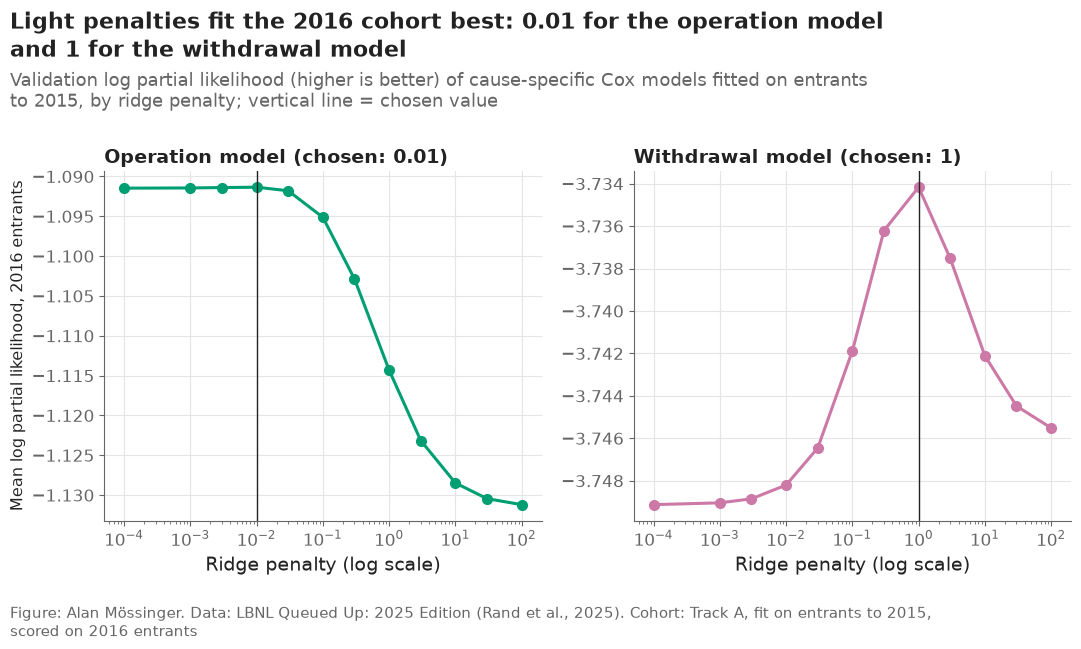

cause,operation,withdrawal
penalizer,,
0.0001,-1.0915,-3.7491
0.0010,-1.0914,-3.7490
0.0030,-1.0914,-3.7489
0.0100,-1.0913,-3.7482
0.0300,-1.0918,-3.7465
0.1000,-1.0951,-3.7419
0.3000,-1.1029,-3.7362
1.0000,-1.1143,-3.7342
3.0000,-1.1231,-3.7375


In [4]:
tuning_rows = []
for cause in CAUSES:
    valid_data = cox_frame(valid, cause)
    valid_data = valid_data[valid_data["T"] > valid_data["entry"]]
    for penalizer in PENALIZERS:
        model = fit_cox(tune, cause, penalizer)
        tuning_rows.append({"cause": cause, "penalizer": penalizer,
                            "validation_log_likelihood": model.score(valid_data, scoring_method="log_likelihood")})
tuning = pd.DataFrame(tuning_rows)
tuning.to_csv(paths.RESULTS / "cox_penalizer_tuning.csv", index=False)
best = tuning.loc[tuning.groupby("cause")["validation_log_likelihood"].idxmax()].set_index("cause")["penalizer"]

fig, axes = plt.subplots(1, 2)
for ax, cause in zip(axes, CAUSES):
    part = tuning[tuning["cause"] == cause]
    ax.plot(part["penalizer"], part["validation_log_likelihood"], color=config.OUTCOME_COLORS[cause], marker="o")
    ax.axvline(best[cause], color=plots.INK, linewidth=1)
    ax.set_xscale("log")
    ax.set_title(f"{cause.capitalize()} model (chosen: {best[cause]:g})")
    ax.set_xlabel("Ridge penalty (log scale)")
axes[0].set_ylabel("Mean log partial likelihood, 2016 entrants")
plots.finish(fig,
             f"Light penalties fit the 2016 cohort best: {best['operation']:g} for the operation model and "
             f"{best['withdrawal']:g} for the withdrawal model",
             "Validation log partial likelihood (higher is better) of cause-specific Cox models fitted on entrants to "
             "2015, by ridge penalty; vertical line = chosen value",
             "Track A, fit on entrants to 2015, scored on 2016 entrants")
save(fig, "05_02_penalizer_tuning", "Validation log partial likelihood of the cause-specific Cox models by ridge penalty.")
plt.show()
tuning.pivot(index="penalizer", columns="cause", values="validation_log_likelihood").round(4)

**Reading this.** The validation log partial likelihood barely moves for the operation model until the penalty passes 0.03 (−1.0913 at the best value, 0.01), so the operation coefficients are not being overfitted. The withdrawal model prefers a much stronger penalty (best 1.0, an interior optimum of the extended grid): its covariates explain little about when projects withdraw, and shrinking them towards zero predicts the 2016 cohort better.

## 4. The fitted models: hazard ratios

Final fits on entrants up to 2016 with the chosen penalties. A hazard ratio
above 1 means a higher yearly chance of that exit, other covariates equal;
operation and withdrawal are separate models, so a characteristic can raise
both (it speeds the queue up) or move them in opposite directions.

In [5]:
models = {cause: fit_cox(final, cause, best[cause]) for cause in CAUSES}
sensitivity = {cause: fit_cox(final, cause, best[cause], delayed=False) for cause in CAUSES}
hr_rows = []
for version, fitted in [("main (ERCOT delayed entry)", models), ("sensitivity (dates as recorded)", sensitivity)]:
    for cause, model in fitted.items():
        s = model.summary
        hr_rows.append(pd.DataFrame({"version": version, "cause": cause, "covariate": s.index,
                                     "hazard_ratio": s["exp(coef)"].to_numpy(),
                                     "ci_low": s["exp(coef) lower 95%"].to_numpy(),
                                     "ci_high": s["exp(coef) upper 95%"].to_numpy(), "p": s["p"].to_numpy()}))
hazard_ratios = pd.concat(hr_rows, ignore_index=True)
hazard_ratios.to_csv(paths.RESULTS / "cox_hazard_ratios.csv", index=False)
main_hr = hazard_ratios[hazard_ratios["version"].str.startswith("main")]
main_hr.pivot(index="covariate", columns="cause", values=["hazard_ratio", "p"]).round(3)

hazard_ratio                    p           
cause                 operation withdrawal operation withdrawal
covariate                                                      
congestion_rank           0.614      0.901     0.001      0.016
log_congestion_gw         0.991      1.139     0.905      0.000
q_year_5                  0.843      1.020     0.001      0.154
region_CAISO              0.523      1.098     0.000      0.000
region_ERCOT              1.658      0.910     0.032      0.216
service_ERIS              0.698      1.022     0.001      0.538
service_missing           1.075      1.165     0.684      0.000
size_100–<200             0.693      0.923     0.000      0.023
size_200–<500             0.514      0.993     0.000      0.839
size_5–<20                1.339      1.027     0.000      0.336
size_<5                   1.852      1.060     0.000      0.092
size_≥500                 0.306      1.101     0.000      0.009
tech_Battery              0.676      1.021     0.046      0.683
tech_Gas                  2.564      0.950     0.000      0.067
tech_Offshore Wind        0.173      0.990     0.024      0.947
tech_Other                1.743      0.925     0.000      0.019
tech_Solar+Battery        0.673      0.546     0.070      0.000
tech_Wind                 0.666      0.923     0.000      0.010

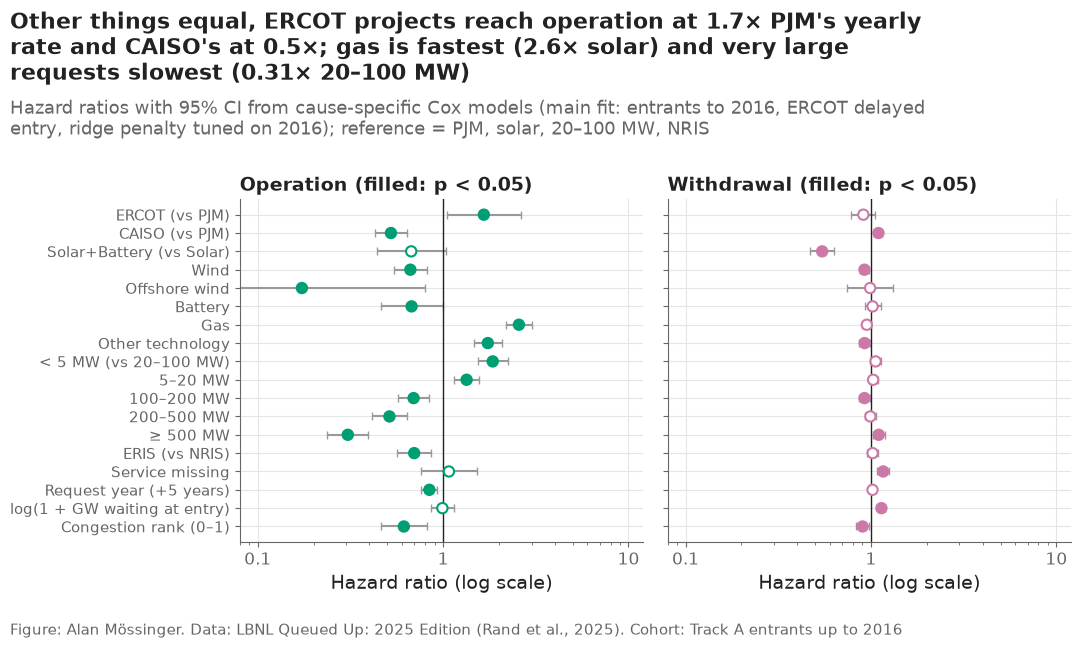

In [6]:
LABELS = {"region_ERCOT": "ERCOT (vs PJM)", "region_CAISO": "CAISO (vs PJM)",
          "tech_Solar+Battery": "Solar+Battery (vs Solar)", "tech_Wind": "Wind", "tech_Offshore Wind": "Offshore wind",
          "tech_Battery": "Battery", "tech_Gas": "Gas", "tech_Other": "Other technology",
          "size_<5": "< 5 MW (vs 20–100 MW)", "size_5–<20": "5–20 MW", "size_100–<200": "100–200 MW",
          "size_200–<500": "200–500 MW", "size_≥500": "≥ 500 MW", "service_ERIS": "ERIS (vs NRIS)",
          "service_missing": "Service missing",
          "q_year_5": "Request year (+5 years)", "log_congestion_gw": "log(1 + GW waiting at entry)",
          "congestion_rank": "Congestion rank (0–1)"}
order = list(LABELS)
fig, axes = plt.subplots(1, 2, sharey=True)
for ax, cause in zip(axes, CAUSES):
    part = main_hr[main_hr["cause"] == cause].set_index("covariate").reindex(order)
    y = np.arange(len(order))[::-1]
    significant = part["p"] < 0.05
    ax.errorbar(part["hazard_ratio"], y, xerr=[part["hazard_ratio"] - part["ci_low"], part["ci_high"] - part["hazard_ratio"]],
                fmt="none", color="#999999", linewidth=1.5, capsize=3)
    ax.scatter(part["hazard_ratio"], y, s=55, zorder=3,
               color=np.where(significant, config.OUTCOME_COLORS[cause], "white"),
               edgecolors=config.OUTCOME_COLORS[cause], linewidths=1.5)
    ax.axvline(1, color=plots.INK, linewidth=1)
    ax.set_xscale("log")
    ax.set_xlim(0.08, 12)
    ax.xaxis.set_major_formatter(lambda x, _: f"{x:g}")
    ax.set_title(f"{cause.capitalize()} (filled: p < 0.05)")
    ax.set_xlabel("Hazard ratio (log scale)")
axes[0].set_yticks(np.arange(len(order))[::-1], [LABELS[c] for c in order], fontsize=11)
op = main_hr[main_hr["cause"] == "operation"].set_index("covariate")["hazard_ratio"]
plots.finish(fig,
             f"Other things equal, ERCOT projects reach operation at {op['region_ERCOT']:.1f}× PJM's yearly rate and "
             f"CAISO's at {op['region_CAISO']:.1f}×; gas is fastest ({op['tech_Gas']:.1f}× solar) and very large "
             f"requests slowest ({op['size_≥500']:.2f}× 20–100 MW)",
             "Hazard ratios with 95% CI from cause-specific Cox models (main fit: entrants to 2016, ERCOT delayed "
             "entry, ridge penalty tuned on 2016); reference = PJM, solar, 20–100 MW, NRIS",
             f"Track A entrants up to {config.TRAIN_MAX_YEAR}")
save(fig, "05_03_hazard_ratios", "Hazard ratios of the cause-specific Cox models for operation and withdrawal (forest plot).")
plt.show()

**Reading this.** For reaching operation, other things equal: ERCOT projects have 1.66× PJM's yearly rate (95% CI 1.04–2.64) and CAISO projects 0.52× (0.43–0.64). Gas runs at 2.56× solar's rate and "Other" at 1.74×; wind (0.67×), batteries (0.68×) and offshore wind (0.17×) are slower than solar. Size has a clear gradient: under 5 MW 1.85×, 5–20 MW 1.34×, then 0.69×, 0.51× and 0.31× for the three classes above 100 MW, all against 20–100 MW. Energy-only (ERIS) requests are slower (0.70×). Each later 5 years of request date lowers the rate (0.84×). Congestion in GW adds nothing once request year is in the model (0.99×, p = 0.90), but a request entering a queue that is crowded *relative to its region's history* is slower (rank 0.61× from least to most crowded). For withdrawal, the covariates matter far less, as the tuning suggested: hybrids (0.55×) and wind (0.92×) withdraw more slowly, CAISO slightly faster (1.10×), and more GW waiting at entry speeds withdrawal (1.14× per log unit). The developer-facing message: a small gas or "Other" project in ERCOT is the fastest profile; a large storage-heavy project in CAISO the slowest.

## 5. Do the hazard ratios have the expected signs?

PLAN.md's check: for operation, ERCOT > PJM > CAISO, and requests of 20 MW or
more are slower than smaller ones.

In [7]:
op = main_hr[main_hr["cause"] == "operation"].set_index("covariate")
sign_checks = pd.DataFrame([
    ("ERCOT faster than PJM (HR > 1)", op.loc["region_ERCOT", "hazard_ratio"], op.loc["region_ERCOT", "hazard_ratio"] > 1),
    ("CAISO slower than PJM (HR < 1)", op.loc["region_CAISO", "hazard_ratio"], op.loc["region_CAISO", "hazard_ratio"] < 1),
    ("< 5 MW faster than 20–100 MW", op.loc["size_<5", "hazard_ratio"], op.loc["size_<5", "hazard_ratio"] > 1),
    ("5–20 MW faster than 20–100 MW", op.loc["size_5–<20", "hazard_ratio"], op.loc["size_5–<20", "hazard_ratio"] > 1),
], columns=["check", "hazard_ratio", "passed"])
sign_checks

,check,hazard_ratio,passed
0,ERCOT faster than PJM (HR > 1),1.658347,True
1,CAISO slower than PJM (HR < 1),0.523311,True
2,< 5 MW faster than 20–100 MW,1.851728,True
3,5–20 MW faster than 20–100 MW,1.339173,True


**Reading this.** All four of the plan's sign checks pass: ERCOT is faster than PJM and CAISO slower (1.66 and 0.52), and both size classes under 20 MW are faster than 20–100 MW (1.85 and 1.34). Under the as-recorded dates the ERCOT ratio would be 0.64 and the check would fail (section 7) — the stamped withdrawals distort exactly this coefficient.

## 6. Proportional hazards: diagnostics

A Cox hazard ratio is one number for the whole wait, which is only fair if
the effect is roughly constant over time in the queue. The test correlates
each covariate's scaled Schoenfeld residuals with (rank-transformed) time;
small p-values mean the effect changes with time. It runs on the as-recorded
fit (decision #25).

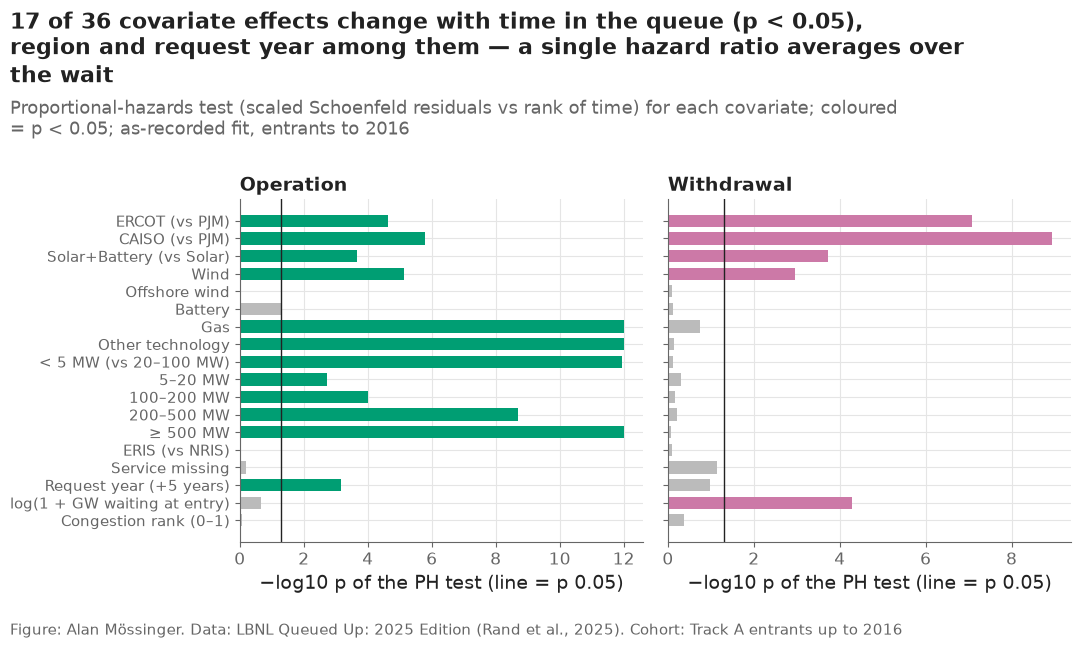

cause,operation,withdrawal
covariate,,
region_ERCOT,0.0000,0.0000
region_CAISO,0.0000,0.0000
tech_Solar+Battery,0.0002,0.0002
tech_Wind,0.0000,0.0011
tech_Offshore Wind,0.9866,0.7981
tech_Battery,0.0513,0.7762
tech_Gas,0.0000,0.1780
tech_Other,0.0000,0.7230
size_<5,0.0000,0.7490


In [8]:
ph_rows, residuals = [], {}
for cause in CAUSES:
    data = cox_frame(final, cause, delayed=False).drop(columns="entry")
    test_result = proportional_hazard_test(sensitivity[cause], data, time_transform="rank")
    table = test_result.summary.reset_index().rename(columns={"index": "covariate"})
    table["cause"] = cause
    ph_rows.append(table[["cause", "covariate", "test_statistic", "p"]])
    residuals[cause] = (sensitivity[cause].compute_residuals(data, kind="scaled_schoenfeld"), data)
ph_tests = pd.concat(ph_rows, ignore_index=True)
ph_tests.to_csv(paths.RESULTS / "cox_ph_tests.csv", index=False)

fig, axes = plt.subplots(1, 2, sharey=True)
for ax, cause in zip(axes, CAUSES):
    part = ph_tests[ph_tests["cause"] == cause].set_index("covariate").reindex(order)
    y = np.arange(len(order))[::-1]
    score = -np.log10(part["p"].clip(lower=1e-12))
    ax.barh(y, score, color=np.where(part["p"] < 0.05, config.OUTCOME_COLORS[cause], "#BBBBBB"), height=0.7)
    ax.axvline(-np.log10(0.05), color=plots.INK, linewidth=1)
    ax.set_title(cause.capitalize())
    ax.set_xlabel("−log10 p of the PH test (line = p 0.05)")
axes[0].set_yticks(np.arange(len(order))[::-1], [LABELS[c] for c in order], fontsize=11)
violations = ph_tests[ph_tests["p"] < 0.05]
plots.finish(fig,
             f"{len(violations)} of {len(ph_tests)} covariate effects change with time in the queue (p < 0.05), "
             "region and request year among them — a single hazard ratio averages over the wait",
             "Proportional-hazards test (scaled Schoenfeld residuals vs rank of time) for each covariate; coloured = "
             "p < 0.05; as-recorded fit, entrants to 2016",
             f"Track A entrants up to {config.TRAIN_MAX_YEAR}")
save(fig, "05_04_ph_tests", "Proportional-hazards test p-values for each covariate of the two cause-specific Cox models.")
plt.show()
ph_tests.pivot(index="covariate", columns="cause", values="p").reindex(order).round(4)

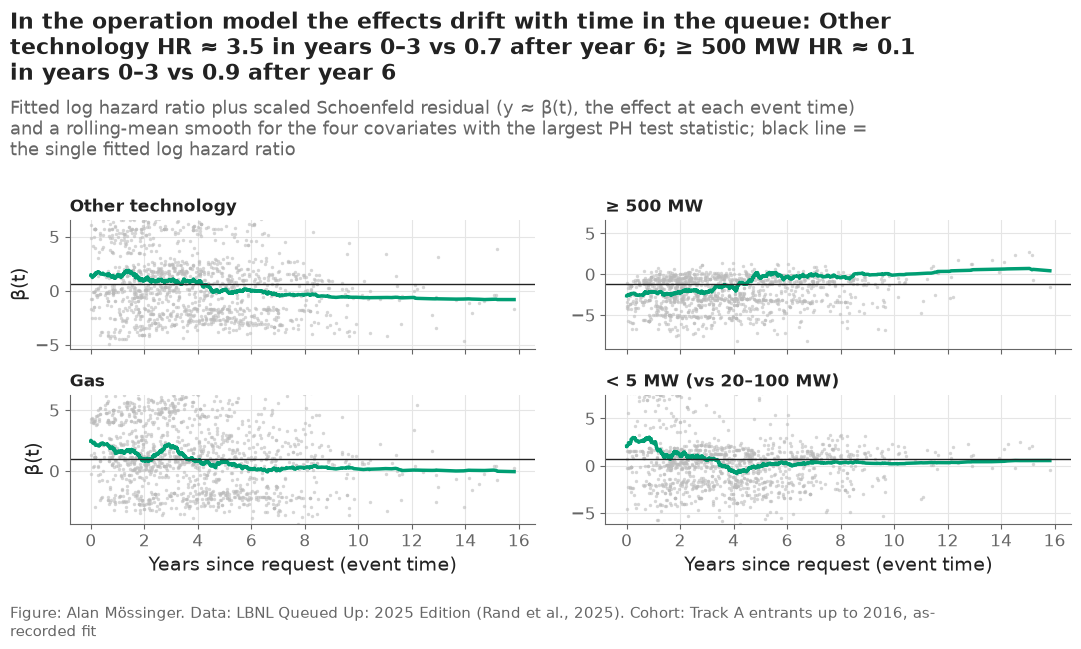

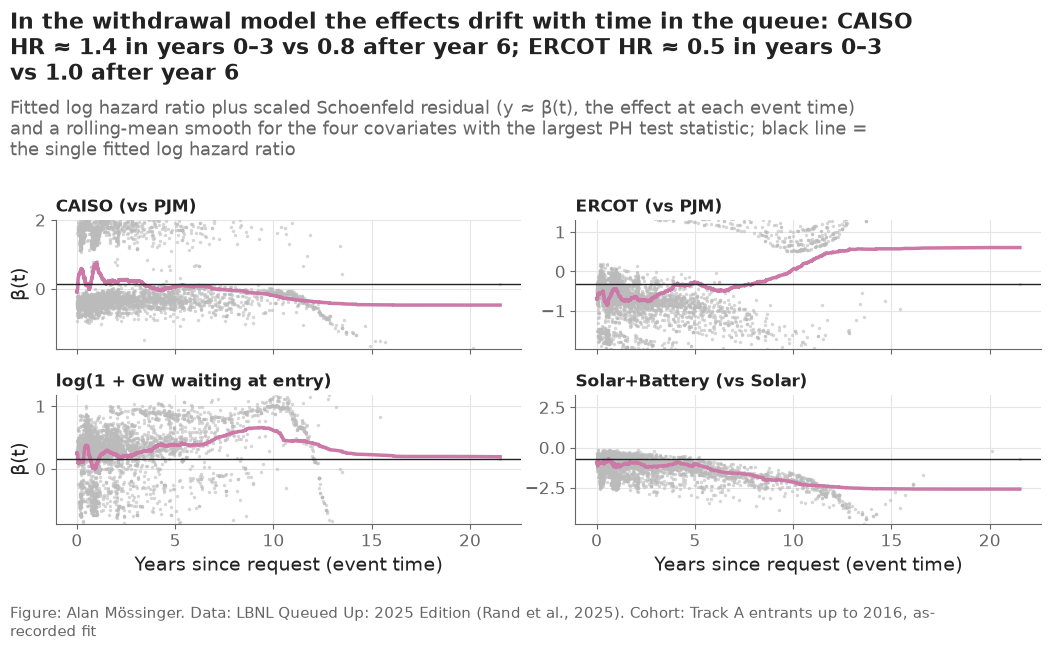

,cause,covariate,hr_years_0_3,hr_after_year_6,hr_fitted
0,operation,tech_Other,3.51,0.72,1.79
1,operation,size_≥500,0.11,0.91,0.29
2,operation,tech_Gas,4.72,1.18,2.59
3,operation,size_<5,4.45,1.35,1.98
4,withdrawal,region_CAISO,1.38,0.81,1.13
5,withdrawal,region_ERCOT,0.53,0.99,0.72
6,withdrawal,log_congestion_gw,1.20,1.53,1.16
7,withdrawal,tech_Solar+Battery,0.37,0.13,0.48


In [9]:
drift_rows = []
for cause in CAUSES:
    scaled, data = residuals[cause]
    worst = (ph_tests[ph_tests["cause"] == cause].sort_values("test_statistic", ascending=False)["covariate"].head(4).tolist())
    times = data.loc[scaled.index, "T"].to_numpy()
    fig, axes = plt.subplots(2, 2, sharex=True)
    for ax, covariate in zip(axes.flat, worst):
        coef = sensitivity[cause].params_[covariate]
        values = scaled[covariate].to_numpy() + coef  # lifelines' scaled residuals average 0; β(t) ≈ β + residual
        ax.scatter(times, values, s=6, color="#BBBBBB", alpha=0.6, linewidths=0)
        order_t = np.argsort(times)
        window = max(25, len(times) // 10)  # rolling mean over ~10% of the events, in time order
        smooth = pd.Series(values[order_t]).rolling(window, center=True, min_periods=window // 2).mean()
        ax.plot(times[order_t], smooth, color=config.OUTCOME_COLORS[cause], linewidth=2.5)
        ax.axhline(coef, color=plots.INK, linewidth=1)
        ax.set_ylim(coef - 4 * values.std() / 2, coef + 4 * values.std() / 2)
        ax.set_title(LABELS[covariate], fontsize=12)
    for ax in axes[-1]:
        ax.set_xlabel("Years since request (event time)")
    for ax in axes[:, 0]:
        ax.set_ylabel("β(t)")
    params = sensitivity[cause].params_
    early = {c: np.exp(params[c] + scaled.loc[times < 3, c].mean()) for c in worst}
    late = {c: np.exp(params[c] + scaled.loc[times >= 6, c].mean()) for c in worst}
    drift_rows.extend({"cause": cause, "covariate": c, "hr_years_0_3": early[c], "hr_after_year_6": late[c],
                       "hr_fitted": np.exp(sensitivity[cause].params_[c])} for c in worst)
    plots.finish(fig,
                 f"In the {cause} model the effects drift with time in the queue: "
                 + "; ".join(f"{LABELS[c].split(' (')[0]} HR ≈ {early[c]:.1f} in years 0–3 vs {late[c]:.1f} after year 6"
                             for c in worst[:2]),
                 f"Fitted log hazard ratio plus scaled Schoenfeld residual (y ≈ β(t), the effect at each event time) and a rolling-mean smooth for the four "
                 f"covariates with the largest PH test statistic; black line = the single fitted log hazard ratio",
                 f"Track A entrants up to {config.TRAIN_MAX_YEAR}, as-recorded fit")
    save(fig, f"diag_schoenfeld_{cause}",
         f"Scaled Schoenfeld residuals over time for the covariates with the strongest evidence of non-proportional "
         f"hazards in the {cause} model.")
    plt.show()
pd.DataFrame(drift_rows).round(2)

**Reading this.** 17 of 36 covariate effects fail the proportional-hazards test at p < 0.05, including region, every size class and the main technologies in the operation model. The drift has a consistent shape: what makes a project fast does so early. Gas runs at about 4.7× solar's rate in its first three years but about 1.2× after year 6; "Other" goes from 3.5× to 0.7×; requests under 5 MW from 4.5× to 1.4×; and requests of 500 MW or more start at about 0.11× and are roughly even (0.91×) after year 6. In the withdrawal model, CAISO's extra withdrawal risk is concentrated early (1.38× in years 0–3) and ERCOT's lower risk early (0.53×). So the single hazard ratios above are averages over the wait, fine for ranking which attributes matter but too coarse for timing. Notebook 06 handles this by giving every year in the queue its own effect and letting the effects vary with it.

## 7. Sensitivity: ERCOT dates as recorded

The same models fitted with ERCOT's stamped withdrawals taken at face value.
Covariates whose hazard ratio barely moves are robust to the choice in
decision #21.

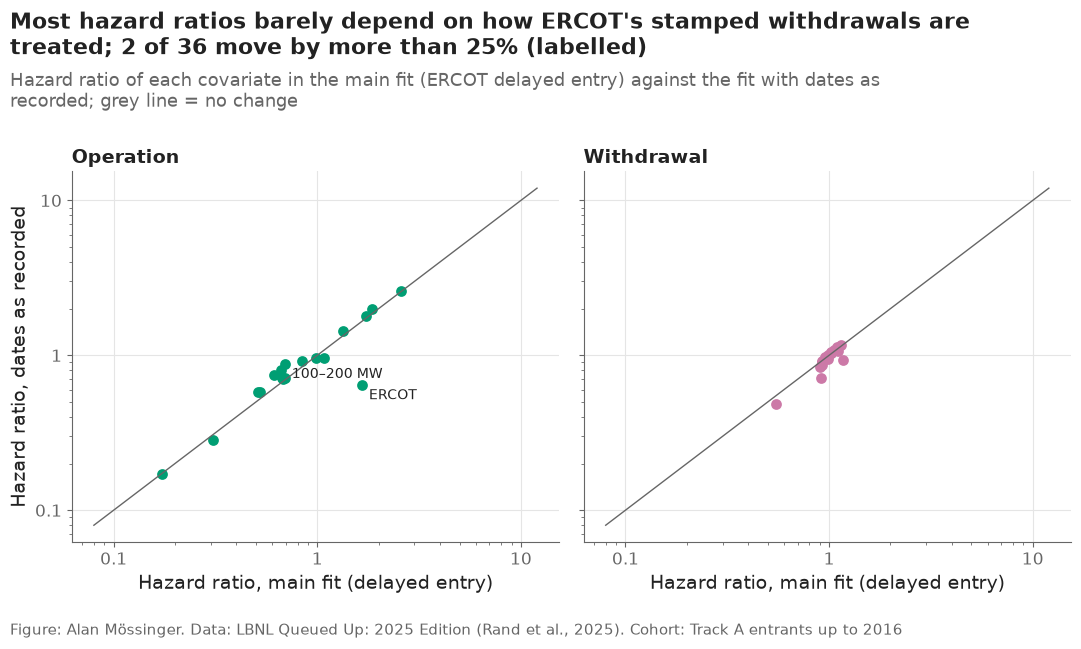

main  as_recorded  ratio
cause      covariate                                    
operation  congestion_rank     0.614        0.741  1.206
           log_congestion_gw   0.991        0.961  0.969
           q_year_5            0.843        0.917  1.087
           region_CAISO        0.523        0.577  1.103
           region_ERCOT        1.658        0.640  0.386
           service_ERIS        0.698        0.716  1.025
           service_missing     1.075        0.956  0.889
           size_100–<200       0.693        0.878  1.267
           size_200–<500       0.514        0.577  1.123
           size_5–<20          1.339        1.440  1.076
           size_<5             1.852        1.976  1.067
           size_≥500           0.306        0.286  0.933
           tech_Battery        0.676        0.707  1.045
           tech_Gas            2.564        2.591  1.010
           tech_Offshore Wind  0.173        0.172  0.992
           tech_Other          1.743        1.791  1.028
           tech_Solar+Battery  0.673        0.711  1.056
           tech_Wind           0.666        0.807  1.212
withdrawal congestion_rank     0.901        0.841  0.934
           log_congestion_gw   1.139        1.163  1.021
           q_year_5            1.020        1.034  1.014
           region_CAISO        1.098        1.133  1.032
           region_ERCOT        0.910        0.718  0.789
           service_ERIS        1.022        1.028  1.006
           service_missing     1.165        0.926  0.795
           size_100–<200       0.923        0.912  0.988
           size_200–<500       0.993        0.942  0.948
           size_5–<20          1.027        1.055  1.027
           size_<5             1.060        1.086  1.024
           size_≥500           1.101        1.062  0.964
           tech_Battery        1.021        1.028  1.007
           tech_Gas            0.950        0.975  1.026
           tech_Offshore Wind  0.990        1.012  1.022
           tech_Other          0.925        0.914  0.987
           tech_Solar+Battery  0.546        0.482  0.883
           tech_Wind           0.923        0.871  0.944

In [10]:
compare = hazard_ratios.pivot_table(index=["cause", "covariate"], columns="version", values="hazard_ratio")
compare.columns = ["main", "as_recorded"]
compare["ratio"] = compare["as_recorded"] / compare["main"]
fig, axes = plt.subplots(1, 2, sharex=True, sharey=True)
for ax, cause in zip(axes, CAUSES):
    part = compare.loc[cause]
    ax.scatter(part["main"], part["as_recorded"], color=config.OUTCOME_COLORS[cause], s=60, edgecolors="white")
    ax.plot([0.08, 12], [0.08, 12], color=plots.MUTED, linewidth=1)
    moved = part[(part["ratio"] - 1).abs() > 0.25]
    for covariate, row in moved.iterrows():
        ax.annotate(LABELS[covariate].split(" (")[0], (row["main"], row["as_recorded"]), xytext=(5, -10),
                    textcoords="offset points", fontsize=10)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_title(cause.capitalize())
    ax.set_xlabel("Hazard ratio, main fit (delayed entry)")
    for axis in (ax.xaxis, ax.yaxis):
        axis.set_major_formatter(lambda v, _: f"{v:g}")
axes[0].set_ylabel("Hazard ratio, dates as recorded")
n_moved = int(((compare["ratio"] - 1).abs() > 0.25).sum())
plots.finish(fig,
             f"Most hazard ratios barely depend on how ERCOT's stamped withdrawals are treated; {n_moved} of "
             f"{len(compare)} move by more than 25% (labelled)",
             "Hazard ratio of each covariate in the main fit (ERCOT delayed entry) against the fit with dates as "
             "recorded; grey line = no change",
             f"Track A entrants up to {config.TRAIN_MAX_YEAR}")
save(fig, "05_05_sensitivity_ercot_dates", "Hazard ratios of the main Cox fit against the fit with ERCOT's withdrawal dates as recorded.")
plt.show()
compare.round(3)

**Reading this.** Only 2 of 36 hazard ratios move by more than 25% when ERCOT's stamped withdrawals are taken at face value, and the big one is the ERCOT effect itself: 1.66 under delayed entry against 0.64 as recorded. The as-recorded number cannot be right — it would say ERCOT builds more slowly than PJM, against the Aalen–Johansen curves of notebook 03, which are unaffected by the stamp. The other move is 100–200 MW (0.69 → 0.88). Everything a developer would read off the table except the ERCOT term is robust to this data problem.

## 8. A check on the 2016 cohort

Validation outcomes may be used: the 2016 entrants were held out of the tuning
fits and are not the test set. Mean predicted P(operation by t) of the
baseline and of the Cox models (both fitted on entrants to 2015) against the
observed Aalen–Johansen estimate, by region.

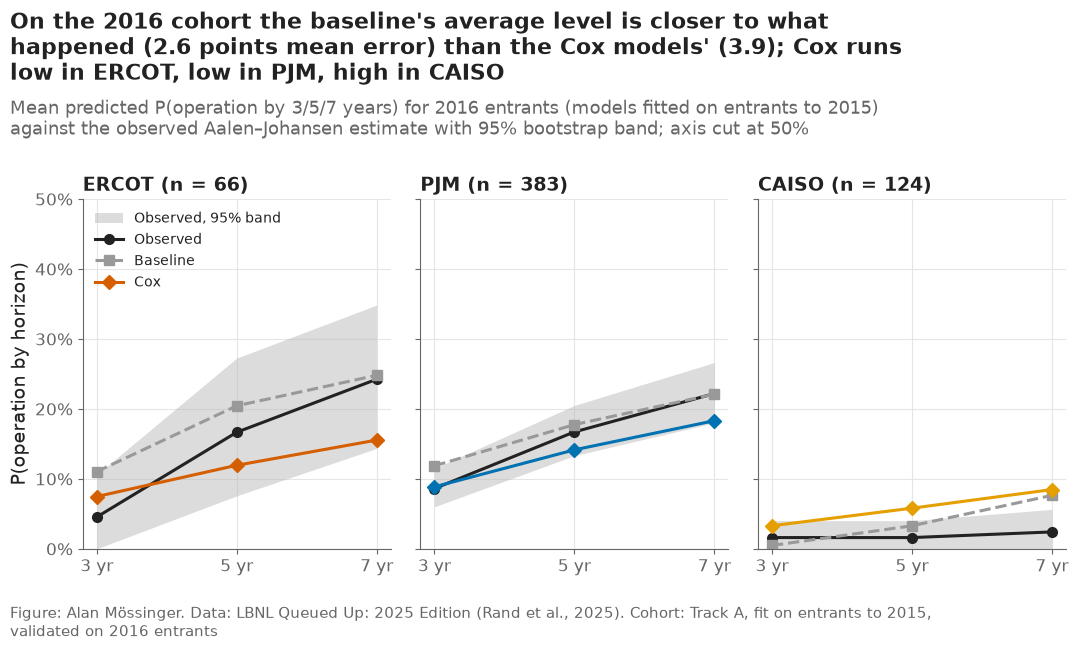

,region,n,horizon,observed,low,high,baseline,cox
0,ERCOT,66,3,0.045,0.000,0.106,0.110,0.075
1,ERCOT,66,5,0.167,0.076,0.273,0.205,0.119
2,ERCOT,66,7,0.242,0.144,0.348,0.248,0.155
3,PJM,383,3,0.086,0.060,0.115,0.119,0.089
4,PJM,383,5,0.167,0.133,0.205,0.178,0.141
5,PJM,383,7,0.222,0.180,0.266,0.221,0.183
6,CAISO,124,3,0.016,0.000,0.040,0.005,0.033
7,CAISO,124,5,0.016,0.000,0.040,0.033,0.058
8,CAISO,124,7,0.024,0.000,0.056,0.076,0.085


In [11]:
baseline_tune = survival_tools.baseline_cif(tune, valid, HORIZONS)
tune_models = {cause: fit_cox(tune, cause, best[cause]) for cause in CAUSES}
cox_valid = survival_tools.cause_specific_cif(tune_models["operation"], tune_models["withdrawal"],
                                              survival_tools.cox_design(valid), HORIZONS)
val_rows = []
for i, region in enumerate(TRACK_A):
    part = valid[valid["region"] == region]
    fit = survival_tools.aalen_johansen(part["duration_years"], part["event"], HORIZONS)
    band = survival_tools.bootstrap_bands(part["duration_years"], part["event"], HORIZONS, n_boot=500, seed=500 + i)
    for j, h in enumerate(HORIZONS):
        val_rows.append({"region": region, "n": len(part), "horizon": h, "observed": fit["cif_operation"].iloc[j],
                         "low": band["cif_operation_low"].iloc[j], "high": band["cif_operation_high"].iloc[j],
                         "baseline": baseline_tune.loc[part.index, h].mean(), "cox": cox_valid.loc[part.index, h].mean()})
validation = pd.DataFrame(val_rows)
validation.to_csv(paths.RESULTS / "cox_validation_calibration.csv", index=False)

fig, axes = plt.subplots(1, 3, sharey=True)
for ax, region in zip(axes, TRACK_A):
    part = validation[validation["region"] == region]
    ax.fill_between(part["horizon"], part["low"], part["high"], color="#BBBBBB", alpha=0.5, linewidth=0,
                    label="Observed, 95% band")
    ax.plot(part["horizon"], part["observed"], color=plots.INK, marker="o", label="Observed")
    ax.plot(part["horizon"], part["baseline"], color="#999999", marker="s", linestyle="--", label="Baseline")
    ax.plot(part["horizon"], part["cox"], color=plots.region_color(region), marker="D", label="Cox")
    ax.set_title(f"{region} (n = {part['n'].iloc[0]})")
    ax.set_xticks(HORIZONS, [f"{h} yr" for h in HORIZONS])
    ax.set_ylim(0, 0.5)
    ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
axes[0].set_ylabel("P(operation by horizon)")
axes[0].legend(loc="upper left", fontsize=10)
gap = validation.assign(cox_err=(validation["cox"] - validation["observed"]).abs(),
                        base_err=(validation["baseline"] - validation["observed"]).abs())
direction = (validation["cox"] - validation["observed"]).groupby(validation["region"]).mean()
plots.finish(fig,
             f"On the 2016 cohort the baseline's average level is closer to what happened "
             f"({100 * gap['base_err'].mean():.1f} points mean error) than the Cox models' "
             f"({100 * gap['cox_err'].mean():.1f}); Cox runs "
             + ", ".join(f"{'low' if direction[r] < 0 else 'high'} in {r}" for r in TRACK_A),
             "Mean predicted P(operation by 3/5/7 years) for 2016 entrants (models fitted on entrants to 2015) against "
             "the observed Aalen–Johansen estimate with 95% bootstrap band; axis cut at 50%",
             "Track A, fit on entrants to 2015, validated on 2016 entrants")
save(fig, "05_06_validation_check", "Mean predicted versus observed P(operation by 3, 5 and 7 years) on the 2016 validation cohort, by region.")
plt.show()
validation.round(3)

**Reading this.** On the 2016 cohort the baseline's average level is closer to what happened than the Cox models' — 2.6 against 3.9 points of mean absolute error, and the baseline is closer in every region (ERCOT 3.6 vs 5.4, PJM 1.5 vs 2.2, CAISO 2.7 vs 4.0). The Cox models run low for ERCOT and PJM at 5 and 7 years (ERCOT 11.9% vs an observed 16.7% at 5 years) and high for CAISO, whose 2016 entrants reached only 2.4% by seven years. Two causes are visible: the request-year trend (0.84× per 5 years) pulls predictions down, and ERCOT's effect rests on 125 post-window requests. This compares averages only; whether Cox *ranks* projects better than the baseline is the question notebook 08 answers on the test set. With 66 ERCOT and 124 CAISO requests, the bands are wide.

## 9. What the model says about a typical request

P(operation by t) over seven years for one reference request — solar,
20–100 MW, NRIS, requested in 2016 at its region's median congestion — in
each region, from the final Cox models.

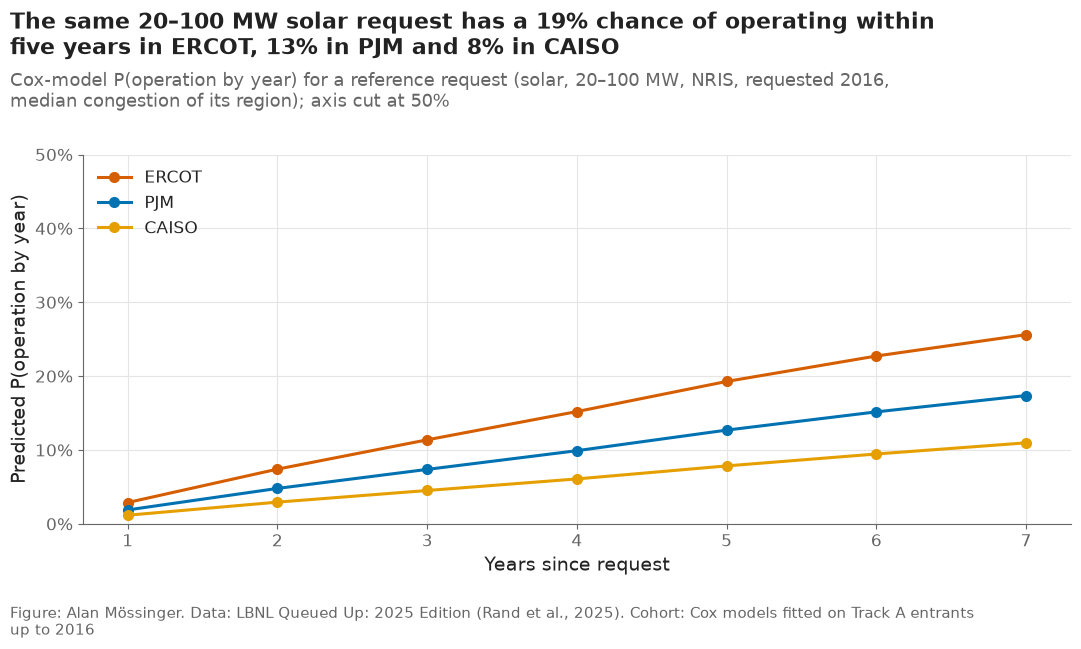

,1,2,3,4,5,6,7
ERCOT,0.029,0.074,0.114,0.152,0.193,0.227,0.256
PJM,0.019,0.048,0.074,0.099,0.127,0.152,0.174
CAISO,0.012,0.029,0.045,0.061,0.078,0.095,0.110


In [12]:
grid_years = np.arange(1, 8)
fig, ax = plt.subplots()
typical_rows = []
for region in TRACK_A:
    reference = final[final["region"] == region]
    row = pd.DataFrame([{"region": region, "tech": "Solar", "size_regime": "20–<100", "service": "NRIS",
                         "q_year": 2016, "congestion_gw": reference["congestion_gw"].median(),
                         "congestion_rank": reference["congestion_rank"].median()}])
    curve = survival_tools.cause_specific_cif(models["operation"], models["withdrawal"],
                                              survival_tools.cox_design(row), list(grid_years)).iloc[0]
    ax.plot(grid_years, curve.to_numpy(), color=plots.region_color(region), marker="o", label=region)
    typical_rows.append(curve.rename(region))
ax.set_ylim(0, 0.5)
ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
ax.set_xlabel("Years since request")
ax.set_ylabel("Predicted P(operation by year)")
ax.legend(loc="upper left")
typical = pd.DataFrame(typical_rows)
plots.finish(fig,
             f"The same 20–100 MW solar request has a {typical.loc['ERCOT', 5]:.0%} chance of operating within five "
             f"years in ERCOT, {typical.loc['PJM', 5]:.0%} in PJM and {typical.loc['CAISO', 5]:.0%} in CAISO",
             "Cox-model P(operation by year) for a reference request (solar, 20–100 MW, NRIS, requested 2016, median "
             "congestion of its region); axis cut at 50%",
             f"Cox models fitted on Track A entrants up to {config.TRAIN_MAX_YEAR}")
save(fig, "05_07_reference_request", "Predicted P(operation by year) for the same reference solar request in each region.")
plt.show()
typical.round(3)

**Reading this.** For one reference request — 20–100 MW solar, NRIS, requested in 2016 at its region's median congestion — the Cox models give a 19.3% chance of operating within five years in ERCOT, 12.7% in PJM and 7.8% in CAISO, rising to 25.6%, 17.4% and 11.0% by seven years. For a developer choosing where to place the same project, the region alone moves the five-year odds by a factor of about 2.5.

## 10. Predictions for the validation and test cohorts

Baseline and Cox predictions from the final fits are written for every
validation and test request. Only predictions are produced here — their
outcomes are not touched until notebook 08 has written its success criteria.

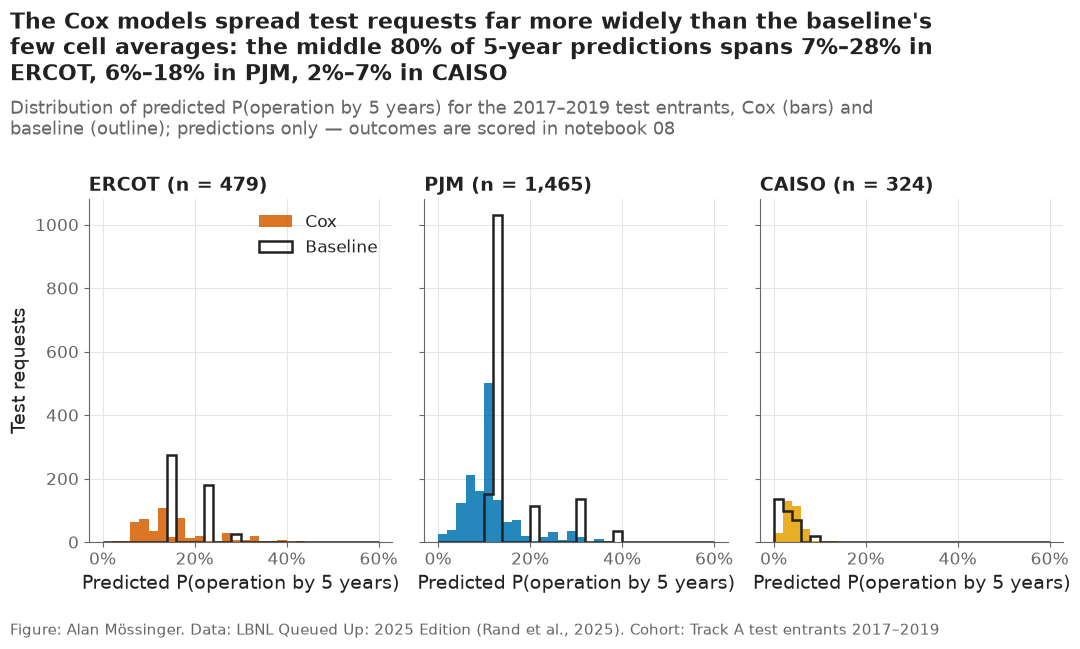

cox_3  cox_5  cox_7  baseline_3  baseline_5  baseline_7
split      region                                                         
test       CAISO   0.023  0.042  0.064       0.008       0.021       0.053
           ERCOT   0.095  0.153  0.196       0.090       0.183       0.230
           PJM     0.068  0.114  0.154       0.100       0.159       0.203
validation CAISO   0.033  0.061  0.089       0.007       0.032       0.072
           ERCOT   0.076  0.126  0.167       0.100       0.197       0.245
           PJM     0.093  0.154  0.200       0.111       0.176       0.223

In [13]:
targets = pd.concat([valid, test])
baseline_pred = survival_tools.baseline_cif(final, targets, HORIZONS)
cox_pred = survival_tools.cause_specific_cif(models["operation"], models["withdrawal"],
                                             survival_tools.cox_design(targets), HORIZONS)
predictions = pd.DataFrame({"project_key": targets["project_key"], "region": targets["region"],
                            "q_year": targets["q_year"], "split": np.where(targets["q_year"] == config.VALIDATION_YEAR,
                                                                           "validation", "test"),
                            "baseline_cell": baseline_pred["cell"]}, index=targets.index)
for h in HORIZONS:
    predictions[f"baseline_{h}"] = baseline_pred[h]
    predictions[f"cox_{h}"] = cox_pred[h]
predictions.to_parquet(paths.DATA_INTERIM / "predictions_05.parquet")

test_pred = predictions[predictions["split"] == "test"]
fig, axes = plt.subplots(1, 3, sharey=True)
bins = np.linspace(0, 0.6, 31)
for ax, region in zip(axes, TRACK_A):
    part = test_pred[test_pred["region"] == region]
    ax.hist(part["cox_5"], bins=bins, color=plots.region_color(region), alpha=0.85, label="Cox")
    ax.hist(part["baseline_5"], bins=bins, histtype="step", color=plots.INK, linewidth=1.8, label="Baseline")
    ax.set_title(f"{region} (n = {len(part):,})")
    ax.set_xlabel("Predicted P(operation by 5 years)")
    ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
axes[0].set_ylabel("Test requests")
axes[0].legend(loc="upper right")
spread = test_pred.groupby("region")["cox_5"].quantile([0.1, 0.9]).unstack()
plots.finish(fig,
             "The Cox models spread test requests far more widely than the baseline's few cell averages: the middle "
             "80% of 5-year predictions spans " + ", ".join(
                 f"{spread.loc[r, 0.1]:.0%}–{spread.loc[r, 0.9]:.0%} in {r}" for r in TRACK_A),
             "Distribution of predicted P(operation by 5 years) for the 2017–2019 test entrants, Cox (bars) and baseline "
             "(outline); predictions only — outcomes are scored in notebook 08",
             "Track A test entrants 2017–2019")
save(fig, "05_08_test_prediction_spread", "Distribution of 5-year predictions for the test entrants, Cox models versus baseline.")
plt.show()
predictions.groupby(["split", "region"])[[f"cox_{h}" for h in HORIZONS] + [f"baseline_{h}" for h in HORIZONS]].mean().round(3)

**Reading this.** Predictions exist for all 573 validation and 2,268 test requests at 3, 5 and 7 years. The Cox models spread test requests much more widely than the baseline's handful of cell averages: the middle 80% of five-year predictions spans 7%–28% in ERCOT, 6%–18% in PJM and 2%–7% in CAISO. On average the Cox predictions for the test cohort are lower than the baseline's in ERCOT (15.3% vs 18.3% at five years) and PJM (11.4% vs 15.9%) and higher in CAISO (4.2% vs 2.1%). No test outcome has been looked at.

## 11. Checks

In [14]:
figure_files = [paths.FIGURES / NOTEBOOK / f"diag_schoenfeld_{c}.png" for c in CAUSES]
checks = pd.DataFrame([
    ("region hazard ratios for operation in the expected order (ERCOT > PJM > CAISO)",
     bool(sign_checks["passed"].iloc[:2].all())),
    ("requests of 20 MW or more slower than smaller ones (operation)", bool(sign_checks["passed"].iloc[2:].all())),
    ("PH diagnostics saved (tests and Schoenfeld plots)",
     (paths.RESULTS / "cox_ph_tests.csv").exists() and all(f.exists() for f in figure_files)),
    ("hazard-ratio table has HR, 95% CI and p for both causes",
     set(hazard_ratios["cause"]) == set(CAUSES) and hazard_ratios[["ci_low", "ci_high", "p"]].notna().all().all()),
    ("predictions for every validation and test request at 3/5/7 years",
     bool(predictions[[f"cox_{h}" for h in HORIZONS]].notna().all().all()) and len(predictions) == len(targets)),
], columns=["check", "passed"])
checks["result"] = np.where(checks["passed"], "PASS", "FAIL")
checks.to_csv(paths.RESULTS / "cox_checks.csv", index=False)
checks[["check", "result"]]

,check,result
0,region hazard ratios for operation in the expe...,PASS
1,requests of 20 MW or more slower than smaller ...,PASS
2,PH diagnostics saved (tests and Schoenfeld plots),PASS
3,"hazard-ratio table has HR, 95% CI and p for bo...",PASS
4,predictions for every validation and test requ...,PASS


**Reading this.** All five checks pass: the region hazard ratios are in the expected order, small requests are faster, the PH diagnostics are saved (tests in `results/cox_ph_tests.csv`, Schoenfeld plots as `diag_schoenfeld_*`), the hazard-ratio table has estimates, intervals and p-values for both causes, and every validation and test request has a prediction.

## Takeaways — Part A

- The baseline (region × technology completion rates, 3.5%–42.8% by seven years) is a strong benchmark: it was closer than the Cox models to the average outcome of the 2016 cohort (2.6 vs 3.9 points).
- Cox hazard ratios for operation, other things equal: ERCOT 1.66× and CAISO 0.52× PJM; gas 2.56× and "Other" 1.74× solar; under 5 MW 1.85× and 500 MW and up 0.31× the 20–100 MW class; each later 5 years of request 0.84×. Withdrawal is much less predictable from entry-time attributes.
- Proportional hazards fails for 17 of 36 effects: fast profiles (gas, small) are fast early and the advantage fades after about six years. This is the case for the discrete-time models of notebook 06.
- Delayed entry for ERCOT drops 607 of its 732 training requests (176 completions) from the fits; the ERCOT effect is the one estimate that depends strongly on the treatment (1.66 vs 0.64 as recorded).

**What goes to the report:** the hazard-ratio table (via F6 in notebook 09), one sentence each on the PH drift (diag_schoenfeld_operation) and on the ERCOT sensitivity (05_05), and 05_07 as the plain-language example for developers.

# Part B — Discrete-time hazard models (was notebook 06)

This notebook expands each Track A request into one row per year in the
queue, fits a multinomial logit and a LightGBM model of the yearly chance of
staying, reaching operation or withdrawing, and turns those hazards into
P(operation by 3, 5 and 7 years) and an expected time to operation for every
validation and test request. No test outcome is looked at here; scoring is
notebook 08's job, after its success criteria are written down.

## Setup

The model code is in `src/discrete_time.py`: `project_years` (rows with
delayed entry and yearly congestion), `prediction_rows` (years 1–10 as known
at entry), `encode_state` (state target encoding inside the training rows
only), `logit_design` / `lgbm_design`, `fit_logit` / `fit_lgbm` and
`cif_table` (hazards → P(operation by t) and expected time). The hazard →
incidence formula is `survival_tools.cif_from_hazards`.

In [15]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append(str(Path.cwd().resolve().parent))  # notebooks run from notebooks/; src/ is one level up
from src import config, discrete_time, features, paths, plots, survival_tools

paths.ensure_dirs()
plots.set_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

NOTEBOOK = "04_forecast_queue"
TRACK_A = config.TRACK_A_REGIONS


def save(fig, name, caption):
    """Save a figure of this notebook under figures/04_forecast_queue/ with its caption stub."""
    return plots.save_fig(fig, name, caption, NOTEBOOK, folder=NOTEBOOK)


def pct(x, digits=1):
    """Format a share as a percentage string."""
    return f"{100 * x:.{digits}f}%"

import time
import warnings

from sklearn.model_selection import GroupKFold

warnings.filterwarnings("ignore", category=FutureWarning)
START = time.time()
HORIZONS = config.HORIZONS
YEARS = np.arange(1, discrete_time.MAX_YEARS + 1)
LOGIT_C = [0.003, 0.01, 0.03, 0.1, 0.3, 1.0, 3.0]  # inverse ridge strength on standardised columns
LGBM_GRID = [{"num_leaves": leaves, "min_data_in_leaf": min_leaf} for leaves in [4, 8, 16, 32, 64] for min_leaf in [10, 20, 50]]
CV_ROUNDS = 1000  # LightGBM rounds recorded in each fold and on 2016 (learning rate 0.05)
OUTCOME_NAMES = {1: "operation", 2: "withdrawal"}
MODEL_LABELS = {"baseline": "Baseline", "cox": "Cox", "dt_logit": "Discrete-time logit", "dt_lgbm": "Discrete-time LightGBM"}
MODEL_STYLE = {"baseline": dict(color="#999999", marker="s", linestyle="--"),
               "cox": dict(color="#555555", marker="D", linestyle=":"),
               "dt_logit": dict(color="#009E73", marker="o"),
               "dt_lgbm": dict(color="#CC79A7", marker="^")}

## 1. Samples and project-year rows

Tuning fits use entrants up to 2015, validation uses the 2016 entrants, the
final fits use entrants up to 2016, and predictions are made for the
2017–2019 test entrants — the same split as notebook 05. Each request becomes
one row per year in the queue (year k covers k − 1 to k years after the
request), up to year 10; the row of the year it leaves carries the outcome.

**Delayed entry in years.** ERCOT requests made before 2018-08-29 are watched
only from that day (decision #21). In a yearly model a year is kept only if
it starts on or after that day (`year − 1 ≥ entry_years`), so every row is a
full year (decision #26). The table below compares this with keeping the
year that *contains* the entry date.

In [16]:
clean = pd.read_parquet(paths.DATA_INTERIM / "queue_clean.parquet")
track_a = pd.read_parquet(paths.DATA_INTERIM / "trackA.parquet")
track_a["tech"] = track_a["type_clean"].map(plots.tech_group)
tune = track_a[track_a["q_year"] <= config.TUNE_MAX_YEAR]
valid = track_a[track_a["q_year"] == config.VALIDATION_YEAR]
final = track_a[track_a["q_year"] <= config.TRAIN_MAX_YEAR]
test = track_a[track_a["q_year"].between(*config.TEST_YEARS)]

rows_tune = discrete_time.project_years(tune, clean)
rows_valid = discrete_time.project_years(valid, clean)
rows_final = discrete_time.project_years(final, clean)
print(f"project-years: tuning {len(rows_tune):,} | validation {len(rows_valid):,} | final {len(rows_final):,}")

by_region = rows_final.groupby("region")
summary = pd.DataFrame({
    "requests to 2016": final.groupby("region").size(),
    "requests with rows": by_region["project"].nunique(),
    "project-years": by_region.size(),
    "operations": rows_final[rows_final["outcome"] == 1].groupby("region").size(),
    "withdrawals": rows_final[rows_final["outcome"] == 2].groupby("region").size(),
}).reindex(TRACK_A)
summary.loc["all"] = summary.sum()
summary.to_csv(paths.RESULTS / "dt_rows_summary.csv")
summary

project-years: tuning 12,836 | validation 1,817 | final 14,653


,requests to 2016,requests with rows,project-years,operations,withdrawals
region,,,,,
ERCOT,732,98,288,36,33
PJM,3192,3192,10036,909,2198
CAISO,1374,1374,4329,171,1102
all,5298,4664,14653,1116,3333


In [17]:
# The alternative rule: keep the year that contains the entry date (after dropping requests that left before entry)
ercot = final[(final["region"] == "ERCOT") & (final["duration_years"] > final["entry_years"])]
partial = survival_tools.expand_project_years(ercot, max_years=discrete_time.MAX_YEARS)
partial = partial[partial["year_in_queue"].to_numpy() > ercot.loc[partial["project"], "entry_years"].to_numpy()]
first_kept = partial.groupby("project")["year_in_queue"].transform("min") == partial["year_in_queue"]
full = rows_final[rows_final["region"] == "ERCOT"]
rule_table = pd.DataFrame({
    "ERCOT project-years": [len(partial), len(full)],
    "of which partly watched": [int(first_kept.sum()), 0],
    "operation hazard": [(partial["outcome"] == 1).mean(), (full["outcome"] == 1).mean()],
    "withdrawal hazard": [(partial["outcome"] == 2).mean(), (full["outcome"] == 2).mean()],
}, index=["year containing entry kept", "full years only (used)"])
print("operation / withdrawal hazard in the partly watched years:",
      round((partial.loc[first_kept, "outcome"] == 1).mean(), 3), "/", round((partial.loc[first_kept, "outcome"] == 2).mean(), 3))
print("ERCOT rows by year in queue (used):", full["year_in_queue"].value_counts().sort_index().to_dict())
rule_table.round(3)

operation / withdrawal hazard in the partly watched years: 0.057 / 0.131
ERCOT rows by year in queue (used): {3: 24, 4: 40, 5: 52, 6: 54, 7: 45, 8: 35, 9: 23, 10: 15}


,ERCOT project-years,of which partly watched,operation hazard,withdrawal hazard
year containing entry kept,410,122,0.105,0.120
full years only (used),288,0,0.125,0.115


**Reading this.** The final fits use 14,653 project-years (tuning: 12,836 from entrants to 2015; validation: 1,817 from the 2016 entrants). PJM and CAISO contribute every request; ERCOT contributes only 98 of its 732 training requests, 288 project-years, 36 operations and 33 withdrawals, and is first seen in year 3 (24 rows). That is decision #21's cost, made slightly larger by the full-year rule of decision #26: keeping the year that contains 2018-08-29 would add 122 partly watched ERCOT years (410 instead of 288), but in those years the operation hazard is 0.057 against 0.125 in full years, because a project watched for a few months has fewer months in which to reach operation. Mixing the two would pull ERCOT's yearly hazards down. ERCOT's effect in this notebook therefore rests on a small sample, and its early years are borrowed from PJM and CAISO.

## 2. Yearly hazards in the data

Before any model: the share of requests still waiting at the start of year k
that reach operation, or withdraw, during year k (a life table), by region,
with 95% intervals. This is the shape the year-in-queue effects must
reproduce.

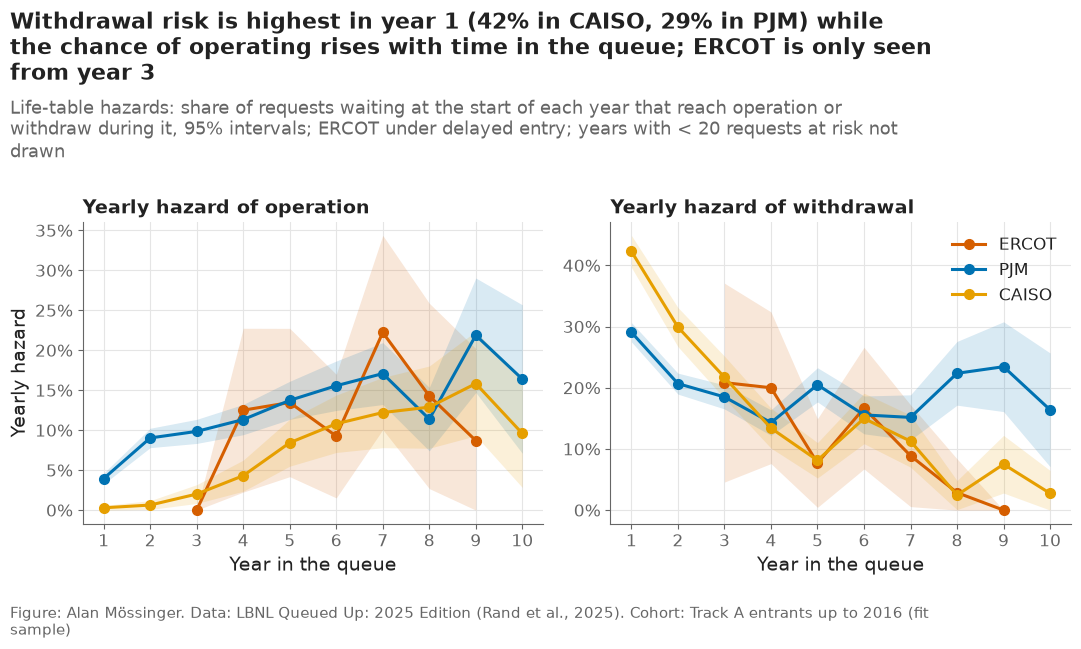

withdrawal hazard, years 1–3 pooled: {'CAISO': 0.345, 'ERCOT': 0.208, 'PJM': 0.241}


at_risk               h_operation               h_withdrawal              
region          CAISO ERCOT     PJM       CAISO  ERCOT    PJM        CAISO  ERCOT    PJM
year_in_queue                                                                           
1              1374.0   NaN  3192.0       0.003    NaN  0.039        0.423    NaN  0.291
2               789.0   NaN  2138.0       0.006    NaN  0.090        0.299    NaN  0.207
3               548.0  24.0  1503.0       0.020  0.000  0.098        0.217  0.208  0.185
4               418.0  40.0  1077.0       0.043  0.125  0.113        0.134  0.200  0.143
5               344.0  52.0   801.0       0.084  0.135  0.137        0.081  0.077  0.205
6               287.0  54.0   527.0       0.108  0.093  0.156        0.150  0.167  0.156
7               213.0  45.0   363.0       0.122  0.222  0.171        0.113  0.089  0.152
8               163.0  35.0   246.0       0.129  0.143  0.114        0.025  0.029  0.224
9               120.0  23.0   128.0       0.158  0.087  0.219        0.075  0.000  0.234
10               73.0  15.0    61.0       0.096  0.133  0.164        0.027  0.133  0.164

In [18]:
life = rows_final.groupby(["region", "year_in_queue"])["outcome"].agg(
    at_risk="size", h_operation=lambda s: (s == 1).mean(), h_withdrawal=lambda s: (s == 2).mean()).reset_index()
life.to_csv(paths.RESULTS / "dt_life_table.csv", index=False)

fig, axes = plt.subplots(1, 2, sharex=True)
for ax, cause in zip(axes, ["operation", "withdrawal"]):
    for region in TRACK_A:
        part = life[(life["region"] == region) & (life["at_risk"] >= 20)]
        h = part[f"h_{cause}"]
        se = np.sqrt(h * (1 - h) / part["at_risk"])
        ax.fill_between(part["year_in_queue"], (h - 1.96 * se).clip(lower=0), h + 1.96 * se,
                        color=plots.region_color(region), alpha=0.15, linewidth=0)
        ax.plot(part["year_in_queue"], h, color=plots.region_color(region), marker="o", label=region)
    ax.set_title(f"Yearly hazard of {cause}")
    ax.set_xlabel("Year in the queue")
    ax.set_xticks(YEARS)
    ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
axes[0].set_ylabel("Yearly hazard")
axes[1].legend(loc="upper right")
early_wd = life[life["year_in_queue"] <= 3].groupby("region").apply(
    lambda p: (p["h_withdrawal"] * p["at_risk"]).sum() / p["at_risk"].sum(), include_groups=False)
year1 = life[life["year_in_queue"] == 1].set_index("region")
plots.finish(fig,
             f"Withdrawal risk is highest in year 1 ({year1.loc['CAISO', 'h_withdrawal']:.0%} in CAISO, "
             f"{year1.loc['PJM', 'h_withdrawal']:.0%} in PJM) while the chance of operating rises with time in the queue; "
             f"ERCOT is only seen from year {int(life.loc[life['region'] == 'ERCOT', 'year_in_queue'].min())}",
             "Life-table hazards: share of requests waiting at the start of each year that reach operation or withdraw "
             "during it, 95% intervals; ERCOT under delayed entry; years with < 20 requests at risk not drawn",
             f"Track A entrants up to {config.TRAIN_MAX_YEAR} (fit sample)")
save(fig, "06_01_life_table_hazards", "Yearly hazards of operation and withdrawal by year in the queue and region (life table of the fit sample).")
plt.show()
print("withdrawal hazard, years 1–3 pooled:", early_wd.round(3).to_dict())
life.pivot_table(index="year_in_queue", columns="region", values=["at_risk", "h_operation", "h_withdrawal"]).round(3)

**Reading this.** Withdrawal is the dominant exit early: in year 1, 42.3% of waiting CAISO requests and 29.1% of PJM requests withdraw (years 1–3 pooled: 34.5% and 24.1%; ERCOT's year 3, the first it is seen, 20.8%). The operation hazard starts near zero (0.3% in CAISO's first year, 3.9% in PJM's) and climbs to 17.1% (PJM) and 12.2% (CAISO) by year 7. So the two exits have opposite shapes over the wait — exactly what a single proportional hazard ratio cannot represent and why every year gets its own effect here. PJM's withdrawal hazard stays high in years 8 and 9 (22.4% and 23.4%), probably including the 2024-12-18 withdrawal cluster kept as recorded (decision #23). ERCOT's points rest on 15–54 requests per year, hence the wide intervals.

## 3. Time-varying congestion

Congestion at entry (notebook 04) is a snapshot. Here it is recounted on the
first day of every project-year: GW of same-region requests that entered
before that day and had not left, minus the project itself. First the
queues themselves over calendar time; then how far a project's congestion in
year k drifts from its value at entry — which matters because a prediction
made at entry must hold congestion at its entry value (section 7 measures
the cost).

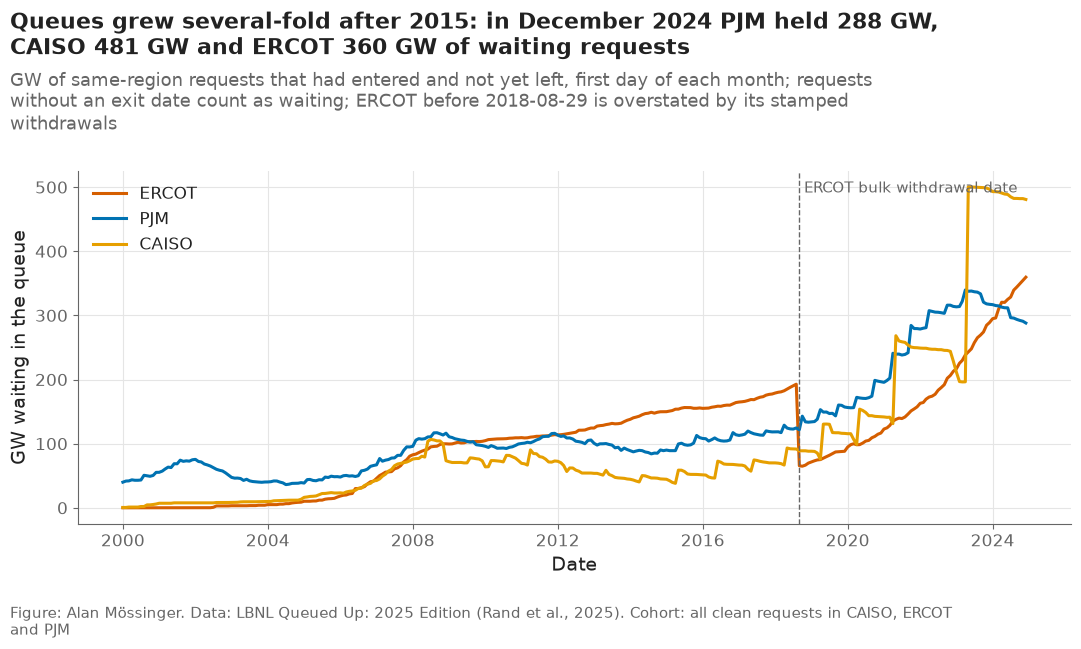

,ERCOT,PJM,CAISO
date,,,
2005-01-01,10.0,39.0,16.0
2010-01-01,105.0,96.0,64.0
2015-01-01,150.0,90.0,45.0
2018-01-01,179.0,119.0,70.0
2020-01-01,95.0,156.0,116.0
2024-01-01,295.0,317.0,493.0
2024-12-01,360.0,288.0,481.0


In [19]:
months = pd.date_range("2000-01-01", config.CENSOR_DATE, freq="MS")
queue_gw = pd.DataFrame({region: features.congestion_on_dates(clean, [region] * len(months), months)["congestion_gw"].to_numpy()
                         for region in TRACK_A}, index=months)
queue_gw.index.name = "date"
queue_gw.to_csv(paths.RESULTS / "dt_queue_gw.csv")

fig, ax = plt.subplots()
for region in TRACK_A:
    ax.plot(queue_gw.index, queue_gw[region], color=plots.region_color(region), label=region)
stamp = pd.Timestamp(config.ERCOT_BULK_WD_DATE)
ax.axvline(stamp, color=plots.MUTED, linewidth=1, linestyle="--")
ax.text(stamp, ax.get_ylim()[1] * 0.97, " ERCOT bulk withdrawal date", fontsize=11, color=plots.MUTED, va="top")
ax.set_xlabel("Date")
ax.set_ylabel("GW waiting in the queue")
ax.legend(loc="upper left")
snap = queue_gw.loc[[pd.Timestamp(f"{y}-01-01") for y in [2005, 2010, 2015, 2018, 2020, 2024]] + [queue_gw.index[-1]]]
end = queue_gw.iloc[-1]
plots.finish(fig,
             f"Queues grew several-fold after 2015: in {queue_gw.index[-1]:%B %Y} PJM held {end['PJM']:.0f} GW, CAISO "
             f"{end['CAISO']:.0f} GW and ERCOT {end['ERCOT']:.0f} GW of waiting requests",
             "GW of same-region requests that had entered and not yet left, first day of each month; requests without an "
             "exit date count as waiting; ERCOT before 2018-08-29 is overstated by its stamped withdrawals",
             "all clean requests in CAISO, ERCOT and PJM")
save(fig, "06_02_queue_gw_over_time", "GW waiting in each Track A queue, monthly, 2000–2024.")
plt.show()
snap.round(0)

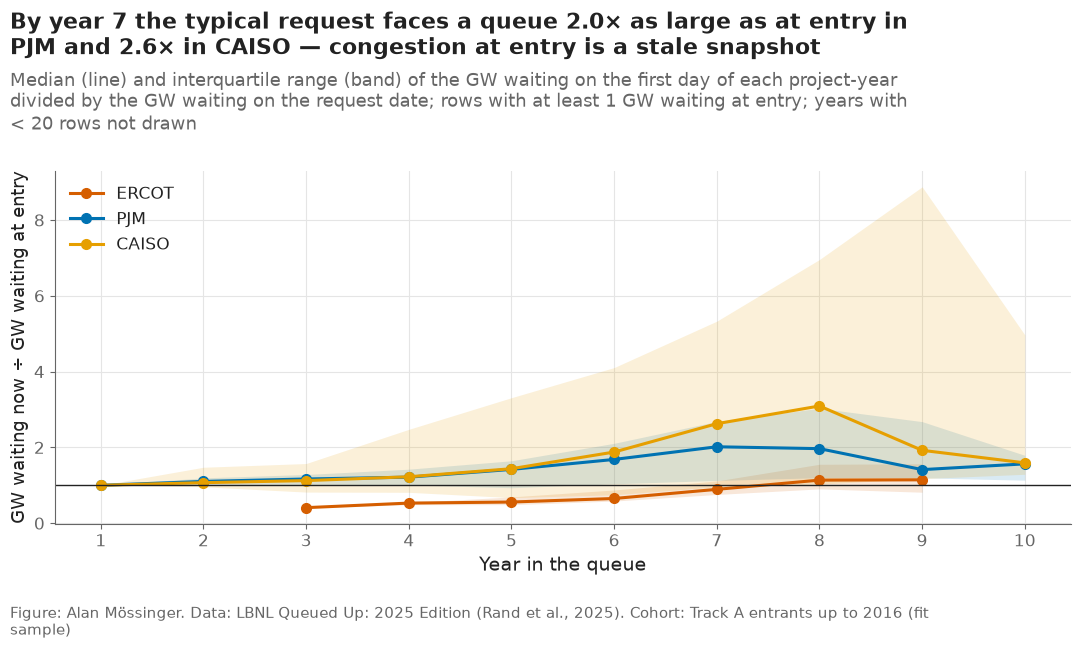

region,CAISO,ERCOT,PJM
year_in_queue,,,
1,1.00,NaN,1.00
2,1.07,NaN,1.10
3,1.12,0.41,1.17
4,1.22,0.53,1.21
5,1.44,0.56,1.42
6,1.88,0.65,1.68
7,2.63,0.89,2.02
8,3.09,1.14,1.97
9,1.92,1.14,1.41


In [20]:
entry_gw = final.loc[rows_final["project"], "congestion_gw"].to_numpy()
drift = rows_final.assign(entry_gw=entry_gw)
drift = drift[drift["entry_gw"] >= 1]  # ratios are meaningless when almost nothing was waiting at entry
drift["ratio"] = drift["congestion_gw"] / drift["entry_gw"]
drift_table = drift.groupby(["region", "year_in_queue"])["ratio"].quantile([0.25, 0.5, 0.75]).unstack()
fig, ax = plt.subplots()
for region in TRACK_A:
    part = drift_table.loc[region]
    part = part[drift.groupby(["region", "year_in_queue"]).size().loc[region] >= 20]
    ax.fill_between(part.index, part[0.25], part[0.75], color=plots.region_color(region), alpha=0.15, linewidth=0)
    ax.plot(part.index, part[0.5], color=plots.region_color(region), marker="o", label=region)
ax.axhline(1, color=plots.INK, linewidth=1)
ax.set_xlabel("Year in the queue")
ax.set_ylabel("GW waiting now ÷ GW waiting at entry")
ax.set_xticks(YEARS)
ax.legend(loc="upper left")
med = drift_table[0.5]
plots.finish(fig,
             f"By year 7 the typical request faces a queue {med.loc[('PJM', 7)]:.1f}× as large as at entry in PJM and "
             f"{med.loc[('CAISO', 7)]:.1f}× in CAISO — congestion at entry is a stale snapshot",
             "Median (line) and interquartile range (band) of the GW waiting on the first day of each project-year divided "
             "by the GW waiting on the request date; rows with at least 1 GW waiting at entry; years with < 20 rows not drawn",
             f"Track A entrants up to {config.TRAIN_MAX_YEAR} (fit sample)")
save(fig, "06_03_congestion_drift", "Ratio of yearly congestion to congestion at entry, by year in the queue and region.")
plt.show()
med.unstack("region").round(2)

**Reading this.** The queues these projects wait in changed a lot while they waited. PJM held 90 GW of waiting requests on 2015-01-01, 317 GW on 2024-01-01 and 288 GW in December 2024; CAISO went from 45 GW to 493 GW and 481 GW. ERCOT's line before 2018-08-29 is not real (its stamped withdrawals count as waiting until that day, then drop out at once), which is also why ERCOT's ratio in the second chart sits below 1: its entry congestion is overstated. For PJM and CAISO, the median request faces 1.4× its entry congestion by year 5 (1.42 and 1.44) and 2.0× and 2.6× by year 7. A prediction made at entry cannot know this, so predictions hold congestion at its entry value; section 7 measures what that costs.

## 4. Grouped cross-validation: the multinomial logit

Five folds on the tuning rows (entrants to 2015), **grouped by project** so
that no request has years in both the fitting and the scoring part. Inside
each fold the state is target-encoded on the fitting part only (its own rows
out of fold), then the logit is fitted for each ridge strength C, with and
without the "early" interactions (CAISO, technology and size in years 1–3,
the drift notebook 05 found). Score: mean log loss of the observed outcome
of each held-out project-year (lower is better).

projects shared between a fold's fitting and scoring parts: 0


no-information log loss (class shares only): 0.7923
chosen: interactions=True, C=0.1, CV log loss 0.7195


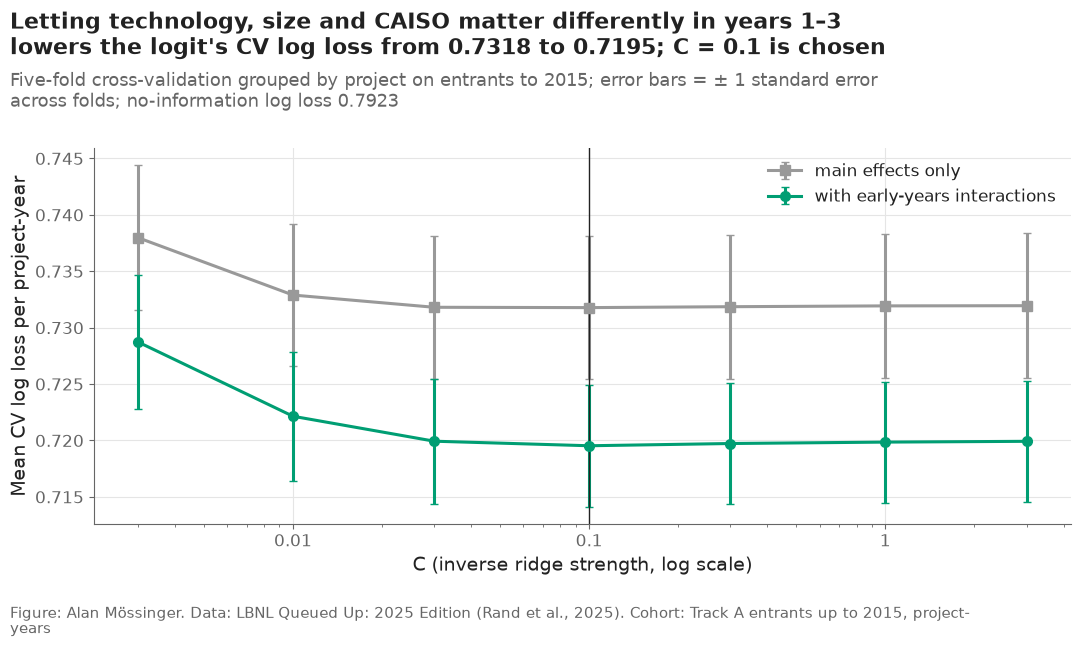

interactions,False,True
C,,
0.003,0.7380,0.7287
0.010,0.7329,0.7221
0.030,0.7318,0.7199
0.100,0.7318,0.7195
0.300,0.7319,0.7197
1.000,0.7319,0.7199
3.000,0.7319,0.7199


In [21]:
folds = list(GroupKFold(n_splits=5, shuffle=True, random_state=0).split(rows_tune, groups=rows_tune["project"]))
overlap = sum(len(set(rows_tune["project"].iloc[a]) & set(rows_tune["project"].iloc[b])) for a, b in folds)
print("projects shared between a fold's fitting and scoring parts:", overlap)
fold_data = [discrete_time.encode_state(rows_tune.iloc[fit_idx], [rows_tune.iloc[held_idx]]) for fit_idx, held_idx in folds]
null_loss = np.mean([discrete_time.multiclass_log_loss(
    held["outcome"], np.tile(np.bincount(fit["outcome"], minlength=3) / len(fit), (len(held), 1))) for fit, held in fold_data])

logit_rows = []
for interactions in [False, True]:
    for C in LOGIT_C:
        for i, (fit_rows, held_rows) in enumerate(fold_data):
            model = discrete_time.fit_logit(discrete_time.logit_design(fit_rows, interactions), fit_rows["outcome"], C)
            probs = model.predict_proba(discrete_time.logit_design(held_rows, interactions))
            logit_rows.append({"interactions": interactions, "C": C, "fold": i,
                               "log_loss": discrete_time.multiclass_log_loss(held_rows["outcome"], probs)})
logit_cv = pd.DataFrame(logit_rows)
logit_cv.to_csv(paths.RESULTS / "dt_cv_logit.csv", index=False)
logit_mean = logit_cv.groupby(["interactions", "C"])["log_loss"].agg(["mean", "std"]).reset_index()
best_logit = logit_mean.loc[logit_mean["mean"].idxmin()]
INTERACTIONS, LOGIT_BEST_C = bool(best_logit["interactions"]), float(best_logit["C"])
print(f"no-information log loss (class shares only): {null_loss:.4f}")
print(f"chosen: interactions={INTERACTIONS}, C={LOGIT_BEST_C:g}, CV log loss {best_logit['mean']:.4f}")

fig, ax = plt.subplots()
for interactions, style in [(False, dict(color="#999999", marker="s")), (True, dict(color="#009E73", marker="o"))]:
    part = logit_mean[logit_mean["interactions"] == interactions]
    ax.errorbar(part["C"], part["mean"], yerr=part["std"] / np.sqrt(len(folds)), capsize=3,
                label="with early-years interactions" if interactions else "main effects only", **style)
ax.axvline(LOGIT_BEST_C, color=plots.INK, linewidth=1)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(lambda x, _: f"{x:g}")
ax.set_xlabel("C (inverse ridge strength, log scale)")
ax.set_ylabel("Mean CV log loss per project-year")
ax.legend(loc="upper right")
plain = logit_mean[~logit_mean["interactions"]]["mean"].min()
plots.finish(fig,
             f"Letting technology, size and CAISO matter differently in years 1–3 lowers the logit's CV log loss from "
             f"{plain:.4f} to {logit_mean[logit_mean['interactions']]['mean'].min():.4f}; C = {LOGIT_BEST_C:g} is chosen",
             f"Five-fold cross-validation grouped by project on entrants to {config.TUNE_MAX_YEAR}; error bars = ± 1 standard "
             f"error across folds; no-information log loss {null_loss:.4f}",
             f"Track A entrants up to {config.TUNE_MAX_YEAR}, project-years")
save(fig, "06_04_logit_cv", "Grouped cross-validation log loss of the multinomial logit by ridge strength, with and without early-years interactions.")
plt.show()
logit_mean.pivot(index="C", columns="interactions", values="mean").round(4)

**Reading this.** Every logit beats the no-information log loss of 0.7923 by a wide margin. Letting CAISO, technology and size have separate effects in years 1–3 lowers the cross-validated log loss from 0.7318 to 0.7195 — a larger gain than any change in the penalty, and the same direction as notebook 05's Schoenfeld diagnostics. The penalty barely matters once it is not very strong (0.7195–0.7199 for C between 0.03 and 3), so C = 0.1 with interactions is a stable choice, not a knife-edge one.

## 5. Grouped cross-validation: LightGBM

The same folds and the same encoded states. For each of 15 tree settings
(leaves per tree × minimum rows per leaf) LightGBM is run for 1,000 rounds and
the held-out log loss is recorded after every round. The plan was to choose
the setting here; section 6 explains why the choice is made on the 2016
cohort instead (decision #27), and this section keeps the cross-validation
as the evidence for that.

best in cross-validation: 64 leaves, min. 10 rows per leaf, 109 rounds, CV log loss 0.6591 (logit: 0.7195, no information: 0.7923)


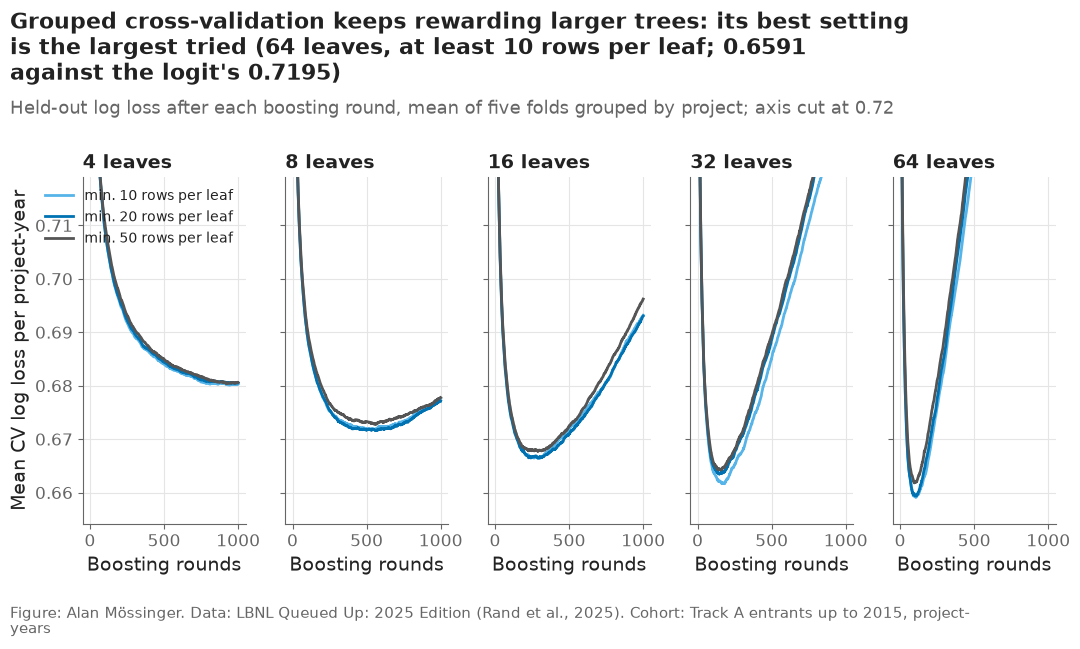

,num_leaves,min_data_in_leaf,cv_rounds,cv_log_loss
12,64,10,109,0.6591
13,64,20,110,0.6594
9,32,10,180,0.6617
14,64,50,96,0.6618
10,32,20,146,0.6634
11,32,50,160,0.6642
6,16,10,295,0.6664
7,16,20,242,0.6665
8,16,50,292,0.6678
4,8,20,561,0.6716


In [22]:
curves, boosters = {}, {}
for params in LGBM_GRID:
    key = (params["num_leaves"], params["min_data_in_leaf"])
    fold_curves = []
    for i, (fit_rows, held_rows) in enumerate(fold_data):
        record = {}
        boosters[(key, i)] = discrete_time.fit_lgbm(
            discrete_time.lgbm_design(fit_rows), fit_rows["outcome"], params, CV_ROUNDS,
            valid=(discrete_time.lgbm_design(held_rows), held_rows["outcome"]), record=record)
        fold_curves.append(record["valid"]["multi_logloss"])
    curves[key] = np.mean(fold_curves, axis=0)
lgbm_cv = pd.DataFrame([{"num_leaves": k[0], "min_data_in_leaf": k[1], "cv_rounds": int(c.argmin() + 1),
                         "cv_log_loss": float(c.min())} for k, c in curves.items()])
cv_best = lgbm_cv.loc[lgbm_cv["cv_log_loss"].idxmin()]
print(f"best in cross-validation: {int(cv_best['num_leaves'])} leaves, min. {int(cv_best['min_data_in_leaf'])} rows per "
      f"leaf, {int(cv_best['cv_rounds'])} rounds, CV log loss {cv_best['cv_log_loss']:.4f} "
      f"(logit: {best_logit['mean']:.4f}, no information: {null_loss:.4f})")

fig, axes = plt.subplots(1, 5, sharey=True)
shades = {10: "#56B4E9", 20: "#0072B2", 50: "#555555"}
for ax, leaves in zip(axes, [4, 8, 16, 32, 64]):
    for min_leaf, color in shades.items():
        ax.plot(np.arange(1, CV_ROUNDS + 1), curves[(leaves, min_leaf)], color=color, linewidth=2,
                label=f"min. {min_leaf} rows per leaf")
    ax.set_title(f"{leaves} leaves")
    ax.set_xlabel("Boosting rounds")
ax_low = min(c.min() for c in curves.values())
axes[0].set_ylim(ax_low - 0.005, ax_low + 0.06)
axes[0].set_ylabel("Mean CV log loss per project-year")
axes[0].legend(loc="upper right", fontsize=10)
plots.finish(fig,
             f"Grouped cross-validation keeps rewarding larger trees: its best setting is the largest tried "
             f"({int(cv_best['num_leaves'])} leaves, at least {int(cv_best['min_data_in_leaf'])} rows per leaf; "
             f"{cv_best['cv_log_loss']:.4f} against the logit's {best_logit['mean']:.4f})",
             f"Held-out log loss after each boosting round, mean of five folds grouped by project; axis cut at "
             f"{ax_low + 0.06:.2f}",
             f"Track A entrants up to {config.TUNE_MAX_YEAR}, project-years")
save(fig, "06_05_lgbm_cv", "Grouped cross-validation log loss of LightGBM by boosting round for 15 tree settings.")
plt.show()
lgbm_cv.sort_values("cv_log_loss").round(4)

**Reading this.** In grouped cross-validation every LightGBM setting beats the logit (0.6591–0.6805 against 0.7195), and the larger the trees the better: the best setting is the largest tried, 64 leaves with at least 10 rows per leaf (0.6591 after 109 rounds) — again at the edge of the grid, as in a first, smaller grid that stopped at 32 leaves. A search that always ends at its own edge is a warning sign rather than an answer. Folds are grouped by project, but all folds share the same calendar years, so a tree can learn "what happened to everybody in year X" from the fitting folds and be rewarded for it in the scoring fold. Such events do not carry forward to later entrants. Section 6 tests this on the 2016 cohort.

## 6. Choosing LightGBM on the 2016 cohort (early stopping)

Every tree setting is fitted on all tuning rows (entrants to 2015) and
watched on the project-years of the 2016 entrants, which lie ahead in time.
The setting and the number of rounds with the lowest 2016 log loss are kept
for the final refit — the same use of the 2016 cohort as the Cox penalty in
notebook 05. Grouped folds keep a project's years together but not a
calendar year's: projects in different folds share the same years in the
queue's history, so cross-validation can reward trees that learn year-
specific events that do not carry forward. The chosen logit is scored on the
same rows for comparison.

chosen on 2016: {'num_leaves': 8, 'min_data_in_leaf': 10}, 331 rounds, 2016 log loss 0.6493; the CV's choice scores 0.6658 on 2016
Spearman correlation of the 15 settings' CV and 2016 log losses: -0.65


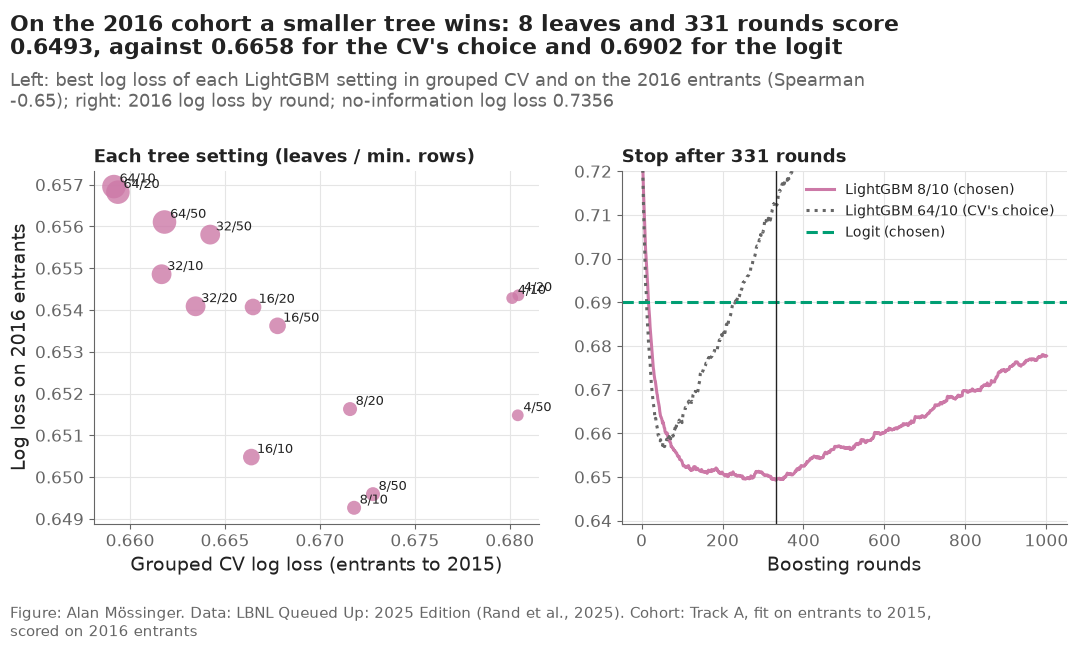

no information              0.7356
dt_logit                    0.6902
dt_lgbm (chosen on 2016)    0.6493
dt_lgbm (CV's choice)       0.6658
dtype: float64

In [23]:
tune_enc, valid_enc = discrete_time.encode_state(rows_tune, [rows_valid])
valid_curves = {}
for params in LGBM_GRID:
    record = {}
    discrete_time.fit_lgbm(discrete_time.lgbm_design(tune_enc), tune_enc["outcome"], params, CV_ROUNDS,
                           valid=(discrete_time.lgbm_design(valid_enc), valid_enc["outcome"]), record=record)
    valid_curves[(params["num_leaves"], params["min_data_in_leaf"])] = np.array(record["valid"]["multi_logloss"])
lgbm_cv["valid_rounds"] = [int(valid_curves[(r.num_leaves, r.min_data_in_leaf)].argmin() + 1) for r in lgbm_cv.itertuples()]
lgbm_cv["valid_log_loss"] = [float(valid_curves[(r.num_leaves, r.min_data_in_leaf)].min()) for r in lgbm_cv.itertuples()]
lgbm_cv.to_csv(paths.RESULTS / "dt_cv_lgbm.csv", index=False)
chosen = lgbm_cv.loc[lgbm_cv["valid_log_loss"].idxmin()]
LGBM_PARAMS = {"num_leaves": int(chosen["num_leaves"]), "min_data_in_leaf": int(chosen["min_data_in_leaf"])}
N_ROUNDS = int(chosen["valid_rounds"])
CHOSEN_CV_ROUNDS = int(chosen["cv_rounds"])
es_curve = valid_curves[(LGBM_PARAMS["num_leaves"], LGBM_PARAMS["min_data_in_leaf"])]
pd.DataFrame({"round": np.arange(1, CV_ROUNDS + 1), "valid_log_loss": es_curve}).to_csv(
    paths.RESULTS / "dt_early_stopping.csv", index=False)
cv_on_2016 = float(valid_curves[(int(cv_best["num_leaves"]), int(cv_best["min_data_in_leaf"]))][int(cv_best["cv_rounds"]) - 1])
rank_agreement = lgbm_cv[["cv_log_loss", "valid_log_loss"]].corr(method="spearman").iloc[0, 1]
print(f"chosen on 2016: {LGBM_PARAMS}, {N_ROUNDS} rounds, 2016 log loss {chosen['valid_log_loss']:.4f}; "
      f"the CV's choice scores {cv_on_2016:.4f} on 2016")
print(f"Spearman correlation of the 15 settings' CV and 2016 log losses: {rank_agreement:.2f}")

logit_tune = discrete_time.fit_logit(discrete_time.logit_design(tune_enc, INTERACTIONS), tune_enc["outcome"], LOGIT_BEST_C)
lgbm_tune = discrete_time.fit_lgbm(discrete_time.lgbm_design(tune_enc), tune_enc["outcome"], LGBM_PARAMS, N_ROUNDS)
valid_loss = {
    "no information": discrete_time.multiclass_log_loss(
        valid_enc["outcome"], np.tile(np.bincount(tune_enc["outcome"], minlength=3) / len(tune_enc), (len(valid_enc), 1))),
    "dt_logit": discrete_time.multiclass_log_loss(
        valid_enc["outcome"], logit_tune.predict_proba(discrete_time.logit_design(valid_enc, INTERACTIONS))),
    "dt_lgbm (chosen on 2016)": float(chosen["valid_log_loss"]),
    "dt_lgbm (CV's choice)": cv_on_2016,
}
tuning = {"logit": {"interactions": INTERACTIONS, "C": LOGIT_BEST_C, "cv_log_loss": float(best_logit["mean"])},
          "lgbm": {**LGBM_PARAMS, "rounds": N_ROUNDS, "valid_log_loss": float(chosen["valid_log_loss"]),
                   "cv_log_loss_of_this_setting": float(chosen["cv_log_loss"]),
                   "cv_choice": {"num_leaves": int(cv_best["num_leaves"]),
                                 "min_data_in_leaf": int(cv_best["min_data_in_leaf"]),
                                 "rounds": int(cv_best["cv_rounds"]), "cv_log_loss": float(cv_best["cv_log_loss"])}},
          "validation_log_loss_2016": valid_loss}
(paths.RESULTS / "dt_tuning.json").write_text(json.dumps(tuning, indent=2), encoding="utf-8")

fig, axes = plt.subplots(1, 2)
ax = axes[0]
ax.scatter(lgbm_cv["cv_log_loss"], lgbm_cv["valid_log_loss"], s=12 * np.sqrt(lgbm_cv["num_leaves"]) * 3,
           color=MODEL_STYLE["dt_lgbm"]["color"], alpha=0.8, edgecolors="white")
for r in lgbm_cv.itertuples():
    ax.annotate(f"{r.num_leaves}/{r.min_data_in_leaf}", (r.cv_log_loss, r.valid_log_loss), xytext=(4, 3),
                textcoords="offset points", fontsize=9)
ax.set_xlabel("Grouped CV log loss (entrants to 2015)")
ax.set_ylabel("Log loss on 2016 entrants")
ax.set_title("Each tree setting (leaves / min. rows)", fontsize=13)
ax = axes[1]
ax.plot(np.arange(1, CV_ROUNDS + 1), es_curve, color=MODEL_STYLE["dt_lgbm"]["color"],
        label=f"LightGBM {LGBM_PARAMS['num_leaves']}/{LGBM_PARAMS['min_data_in_leaf']} (chosen)")
cv_curve = valid_curves[(int(cv_best["num_leaves"]), int(cv_best["min_data_in_leaf"]))]
ax.plot(np.arange(1, CV_ROUNDS + 1), cv_curve, color=plots.MUTED, linestyle=":",
        label=f"LightGBM {int(cv_best['num_leaves'])}/{int(cv_best['min_data_in_leaf'])} (CV's choice)")
ax.axhline(valid_loss["dt_logit"], color=MODEL_STYLE["dt_logit"]["color"], linestyle="--", label="Logit (chosen)")
ax.axvline(N_ROUNDS, color=plots.INK, linewidth=1)
ax.set_ylim(es_curve.min() - 0.01, valid_loss["dt_logit"] + 0.03)
ax.set_xlabel("Boosting rounds")
ax.set_title(f"Stop after {N_ROUNDS} rounds", fontsize=13)
ax.legend(loc="upper right", fontsize=10)
plots.finish(fig,
             f"On the 2016 cohort {'a smaller tree wins' if LGBM_PARAMS['num_leaves'] < cv_best['num_leaves'] else 'the ranking holds'}: "
             f"{LGBM_PARAMS['num_leaves']} leaves and {N_ROUNDS} rounds score "
             f"{chosen['valid_log_loss']:.4f}, against {cv_on_2016:.4f} for the CV's choice and {valid_loss['dt_logit']:.4f} "
             f"for the logit",
             f"Left: best log loss of each LightGBM setting in grouped CV and on the 2016 entrants (Spearman {rank_agreement:.2f}); "
             f"right: 2016 log loss by round; no-information log loss {valid_loss['no information']:.4f}",
             f"Track A, fit on entrants to {config.TUNE_MAX_YEAR}, scored on 2016 entrants")
save(fig, "06_06_early_stopping", "LightGBM tree settings scored in grouped cross-validation and on the 2016 cohort, and the 2016 log loss by round.")
plt.show()
pd.Series(valid_loss).round(4)

**Reading this.** On the 2016 entrants — later in time than every fitting row — the ranking of the 15 settings is close to reversed (Spearman −0.65 between their CV and 2016 log losses). The CV's choice (64 leaves) scores 0.6658 on 2016, while 8 leaves with at least 10 rows per leaf, stopped after 331 rounds, scores 0.6493, the best of the grid; the logit scores 0.6902 and no information 0.7356. Following the plan literally would have picked the setting that generalises worst forward in time. LightGBM's setting and round count are therefore chosen on the 2016 cohort (decision #27), as notebook 05 chose the Cox penalty, and the cross-validation is kept as the evidence. The cost is that the 2016 cohort is no longer fully independent for LightGBM: the section 7 check on it is partly in-sample for the round count and setting.

## 7. A check on the 2016 cohort: predicted vs observed incidence

Log loss per project-year says which model ranks hazards better; what a
developer sees is P(operation by t). The tuning fits (entrants to 2015)
predict each 2016 request from its entry date, **with congestion frozen at
its entry value**, and the mean prediction per region is set against the
observed Aalen–Johansen estimate and its 95% bootstrap band. The baseline
and Cox numbers are notebook 05's (also fitted on entrants to 2015).

mean absolute error of the mean prediction, points (9 region × horizon cells): {'baseline': 2.6, 'cox': 3.9, 'dt_logit': 1.8, 'dt_lgbm': 1.7, 'dt_logit_realised': 1.9, 'dt_lgbm_realised': 2.5}


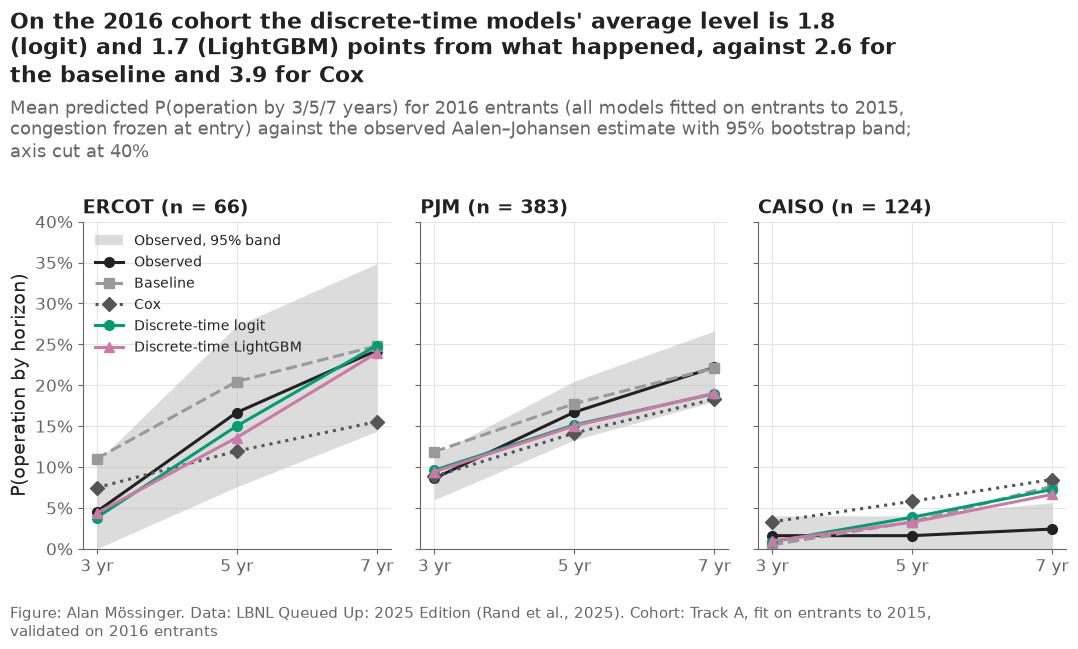

,region,horizon,observed,low,high,baseline,cox,dt_logit,dt_lgbm
0,ERCOT,3,0.045,0.000,0.106,0.110,0.075,0.038,0.044
1,ERCOT,5,0.167,0.076,0.273,0.205,0.119,0.150,0.136
2,ERCOT,7,0.242,0.144,0.348,0.248,0.155,0.249,0.239
3,PJM,3,0.086,0.060,0.115,0.119,0.089,0.096,0.094
4,PJM,5,0.167,0.133,0.205,0.178,0.141,0.151,0.150
5,PJM,7,0.222,0.180,0.266,0.221,0.183,0.190,0.190
6,CAISO,3,0.016,0.000,0.040,0.005,0.033,0.009,0.010
7,CAISO,5,0.016,0.000,0.040,0.033,0.058,0.039,0.032
8,CAISO,7,0.024,0.000,0.056,0.076,0.085,0.072,0.066


In [24]:
def predict(frame, fit_rows, logit_model, lgbm_model, horizons=HORIZONS, realised=False):
    """P(operation by each horizon) and expected time from both discrete-time models, as known at entry."""
    rows = discrete_time.prediction_rows(frame)
    if realised:  # diagnostic only: the queue as it actually turned out, which is not known at entry
        rows["congestion_gw"] = discrete_time.yearly_congestion(rows, frame, clean)
        rows["log_congestion_gw"] = np.log1p(rows["congestion_gw"])
    _, rows = discrete_time.encode_state(fit_rows, [rows])
    return {
        "dt_logit": discrete_time.cif_table(*discrete_time.predict_hazards(
            logit_model, discrete_time.logit_design(rows, INTERACTIONS)), frame.index, horizons),
        "dt_lgbm": discrete_time.cif_table(*discrete_time.predict_hazards(
            lgbm_model, discrete_time.lgbm_design(rows)), frame.index, horizons),
    }


valid_frozen = predict(valid, rows_tune, logit_tune, lgbm_tune)
valid_realised = predict(valid, rows_tune, logit_tune, lgbm_tune, realised=True)
check05 = pd.read_csv(paths.RESULTS / "cox_validation_calibration.csv")
val_rows = []
for _, row in check05.iterrows():
    index = valid.index[valid["region"] == row["region"]]
    entry = row.to_dict()
    for model in ["dt_logit", "dt_lgbm"]:
        entry[model] = valid_frozen[model].loc[index, row["horizon"]].mean()
        entry[f"{model}_realised"] = valid_realised[model].loc[index, row["horizon"]].mean()
    val_rows.append(entry)
validation = pd.DataFrame(val_rows)
validation.to_csv(paths.RESULTS / "dt_validation_2016.csv", index=False)
errors = pd.Series({model: 100 * (validation[model] - validation["observed"]).abs().mean()
                    for model in ["baseline", "cox", "dt_logit", "dt_lgbm", "dt_logit_realised", "dt_lgbm_realised"]})
print("mean absolute error of the mean prediction, points (9 region × horizon cells):", errors.round(1).to_dict())

fig, axes = plt.subplots(1, 3, sharey=True)
for ax, region in zip(axes, TRACK_A):
    part = validation[validation["region"] == region]
    ax.fill_between(part["horizon"], part["low"], part["high"], color="#BBBBBB", alpha=0.5, linewidth=0,
                    label="Observed, 95% band")
    ax.plot(part["horizon"], part["observed"], color=plots.INK, marker="o", label="Observed")
    for model in ["baseline", "cox", "dt_logit", "dt_lgbm"]:
        ax.plot(part["horizon"], part[model], label=MODEL_LABELS[model], **MODEL_STYLE[model])
    ax.set_title(f"{region} (n = {int(part['n'].iloc[0])})")
    ax.set_xticks(HORIZONS, [f"{h} yr" for h in HORIZONS])
    ax.set_ylim(0, 0.4)
    ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
axes[0].set_ylabel("P(operation by horizon)")
axes[0].legend(loc="upper left", fontsize=10)
plots.finish(fig,
             f"On the 2016 cohort the discrete-time models' average level is {errors['dt_logit']:.1f} (logit) and "
             f"{errors['dt_lgbm']:.1f} (LightGBM) points from what happened, against {errors['baseline']:.1f} for the "
             f"baseline and {errors['cox']:.1f} for Cox",
             "Mean predicted P(operation by 3/5/7 years) for 2016 entrants (all models fitted on entrants to 2015, congestion "
             "frozen at entry) against the observed Aalen–Johansen estimate with 95% bootstrap band; axis cut at 40%",
             "Track A, fit on entrants to 2015, validated on 2016 entrants")
save(fig, "06_07_validation_2016", "Mean predicted versus observed P(operation by 3, 5 and 7 years) on the 2016 cohort for the four models, by region.")
plt.show()
validation[["region", "horizon", "observed", "low", "high", "baseline", "cox", "dt_logit", "dt_lgbm"]].round(3)

largest change, frozen vs realised congestion: 4.2 points


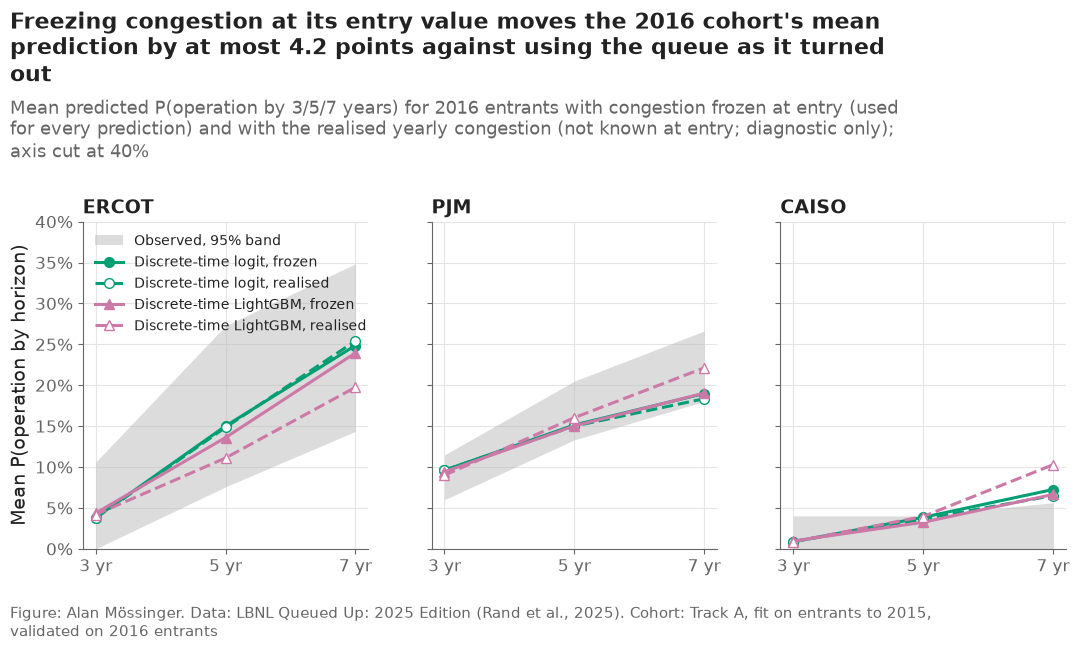

,region,horizon,dt_logit,dt_logit_realised,dt_lgbm,dt_lgbm_realised
0,ERCOT,3,0.038,0.038,0.044,0.042
1,ERCOT,5,0.150,0.148,0.136,0.111
2,ERCOT,7,0.249,0.254,0.239,0.197
3,PJM,3,0.096,0.096,0.094,0.090
4,PJM,5,0.151,0.150,0.150,0.160
5,PJM,7,0.190,0.184,0.190,0.221
6,CAISO,3,0.009,0.009,0.010,0.009
7,CAISO,5,0.039,0.036,0.032,0.039
8,CAISO,7,0.072,0.065,0.066,0.103


In [25]:
fig, axes = plt.subplots(1, 3, sharey=True)
for ax, region in zip(axes, TRACK_A):
    part = validation[validation["region"] == region]
    ax.fill_between(part["horizon"], part["low"], part["high"], color="#BBBBBB", alpha=0.5, linewidth=0,
                    label="Observed, 95% band")
    for model in ["dt_logit", "dt_lgbm"]:
        style = MODEL_STYLE[model]
        ax.plot(part["horizon"], part[model], color=style["color"], marker=style["marker"],
                label=f"{MODEL_LABELS[model]}, frozen")
        ax.plot(part["horizon"], part[f"{model}_realised"], color=style["color"], marker=style["marker"],
                markerfacecolor="white", linestyle="--", label=f"{MODEL_LABELS[model]}, realised")
    ax.set_title(region)
    ax.set_xticks(HORIZONS, [f"{h} yr" for h in HORIZONS])
    ax.set_ylim(0, 0.4)
    ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
axes[0].set_ylabel("Mean P(operation by horizon)")
axes[0].legend(loc="upper left", fontsize=10)
shift = 100 * pd.concat([(validation[f"{m}_realised"] - validation[m]).abs() for m in ["dt_logit", "dt_lgbm"]]).max()
print(f"largest change, frozen vs realised congestion: {shift:.1f} points")
plots.finish(fig,
             f"Freezing congestion at its entry value moves the 2016 cohort's mean prediction by at most {shift:.1f} points "
             f"against using the queue as it turned out",
             "Mean predicted P(operation by 3/5/7 years) for 2016 entrants with congestion frozen at entry (used for every "
             "prediction) and with the realised yearly congestion (not known at entry; diagnostic only); axis cut at 40%",
             "Track A, fit on entrants to 2015, validated on 2016 entrants")
save(fig, "06_08_frozen_vs_realised_congestion", "Effect of freezing congestion at its entry value on the 2016 cohort's mean predictions.")
plt.show()
validation[["region", "horizon", "dt_logit", "dt_logit_realised", "dt_lgbm", "dt_lgbm_realised"]].round(3)

**Reading this.** Set against what happened to the 2016 entrants, both discrete-time models are closer on average than notebook 05's models: mean absolute error over the nine region × horizon cells is 1.8 points for the logit and 1.7 for LightGBM, against 2.6 for the baseline and 3.9 for Cox. In ERCOT the logit hits the 7-year level exactly (24.9% predicted, 24.2% observed) where Cox predicted 15.5%. CAISO is the shared failure: its 2016 entrants reached operation only 2.4% of the time by year 7, below the band of every model (baseline 7.6%, Cox 8.5%, logit 7.2%, LightGBM 6.6%). Freezing congestion at entry, as every real prediction must, is not a handicap: with the realised yearly congestion the errors would be 1.9 and 2.5 points, i.e. no better, and the largest shift between the two versions is 4.2 points (LightGBM, ERCOT, 7 years: 23.9% frozen vs 19.7% realised). LightGBM is the more sensitive model because it uses yearly congestion more.

## 8. The final models and what they say

Both models are refitted on entrants up to 2016 with the chosen settings
(LightGBM for the early-stopping round count). The logit's coefficients are
odds ratios against staying in the queue for one more year; with the early
interactions each attribute has one odds ratio for years 1–3 and one for
years 4–10. Intervals come from 200 bootstrap resamples of projects.

In [26]:
final_enc = discrete_time.encode_state(rows_final)[0]
X_final = discrete_time.logit_design(final_enc, INTERACTIONS)
logit_final = discrete_time.fit_logit(X_final, final_enc["outcome"], LOGIT_BEST_C)
lgbm_final = discrete_time.fit_lgbm(discrete_time.lgbm_design(final_enc), final_enc["outcome"], LGBM_PARAMS, N_ROUNDS)


def log_odds(model, columns):
    """Per-unit log odds of operation and of withdrawal against staying, from a fitted pipeline."""
    scale = model[0].scale_
    coef = model[-1].coef_ / scale  # back from standardised to original units
    return pd.DataFrame({"operation": coef[1] - coef[0], "withdrawal": coef[2] - coef[0]}, index=columns)


point = log_odds(logit_final, X_final.columns)
rng = np.random.default_rng(6)
projects = final_enc["project"].unique()
row_groups = final_enc.groupby("project").indices
draws = []
for _ in range(200):
    pick = np.concatenate([row_groups[p] for p in rng.choice(projects, len(projects))])
    model = discrete_time.fit_logit(X_final.iloc[pick], final_enc["outcome"].iloc[pick], LOGIT_BEST_C)
    draws.append(log_odds(model, X_final.columns))
draws = np.stack([d.to_numpy() for d in draws])

ATTRIBUTES = {"region_CAISO": "CAISO (vs PJM)", "region_ERCOT": "ERCOT (vs PJM)",
              "tech_Solar+Battery": "Solar+Battery (vs Solar)", "tech_Wind": "Wind", "tech_Offshore Wind": "Offshore wind",
              "tech_Battery": "Battery", "tech_Gas": "Gas", "tech_Other": "Other technology",
              "size_<5": "< 5 MW (vs 20–100 MW)", "size_5–<20": "5–20 MW", "size_100–<200": "100–200 MW",
              "size_200–<500": "200–500 MW", "size_≥500": "≥ 500 MW", "service_ERIS": "ERIS (vs NRIS)",
              "service_missing": "Service missing", "log_mw": "log MW (+1)",
              "q_year": "Request year (+1)", "log_congestion_gw": "log(1 + GW waiting) (+1)",
              "congestion_rank": "Congestion rank at entry (0 → 1)", "state_operation": "State operation rate (+1 point)",
              "state_withdrawal": "State withdrawal rate (+1 point)"}
or_rows = []
for column, label in ATTRIBUTES.items():
    unit = 0.01 if column.startswith("state_") else 1.0
    early_column = f"early × {column}"
    j = list(X_final.columns).index(column)
    k = list(X_final.columns).index(early_column) if early_column in X_final.columns else None
    for cause_i, cause in enumerate(["operation", "withdrawal"]):
        for period in ["years 4–10", "years 1–3"]:
            if period == "years 1–3" and k is None:
                continue
            value = point.iloc[j][cause] + (point.iloc[k][cause] if period == "years 1–3" else 0)
            sample = draws[:, j, cause_i] + (draws[:, k, cause_i] if period == "years 1–3" else 0)
            or_rows.append({"attribute": column, "label": label, "cause": cause, "period": period,
                            "odds_ratio": np.exp(unit * value), "ci_low": np.exp(unit * np.quantile(sample, 0.025)),
                            "ci_high": np.exp(unit * np.quantile(sample, 0.975))})
odds = pd.DataFrame(or_rows)
odds.to_csv(paths.RESULTS / "dt_logit_odds_ratios.csv", index=False)
odds.pivot_table(index="label", columns=["cause", "period"], values="odds_ratio", sort=False).round(2)

cause                             operation           withdrawal          
period                           years 4–10 years 1–3 years 4–10 years 1–3
label                                                                     
CAISO (vs PJM)                         1.11      0.39       0.64      1.26
ERCOT (vs PJM)                         1.34       NaN       0.56       NaN
Solar+Battery (vs Solar)               0.23      2.59       0.14      0.16
Wind                                   0.47      1.08       1.32      0.74
Offshore wind                          0.11      0.03       0.70      0.81
Battery                                0.41      0.87       0.70      0.87
Gas                                    2.04      5.48       1.09      0.72
Other technology                       0.93      3.48       0.91      0.85
< 5 MW (vs 20–100 MW)                  0.67      2.76       2.07      0.99
5–20 MW                                1.00      1.56       1.44      1.02
100–200 MW                             0.94      0.27       0.83      0.91
200–500 MW                             0.71      0.15       0.97      1.19
≥ 500 MW                               0.51      0.06       1.12      1.54
ERIS (vs NRIS)                         0.73       NaN       1.01       NaN
Service missing                        1.20       NaN       1.67       NaN
log MW (+1)                            0.91       NaN       1.00       NaN
Request year (+1)                      0.94       NaN       1.01       NaN
log(1 + GW waiting) (+1)               1.10       NaN       1.28       NaN
Congestion rank at entry (0 → 1)       0.41       NaN       0.60       NaN
State operation rate (+1 point)        1.14       NaN       1.01       NaN
State withdrawal rate (+1 point)       1.00       NaN       1.06       NaN

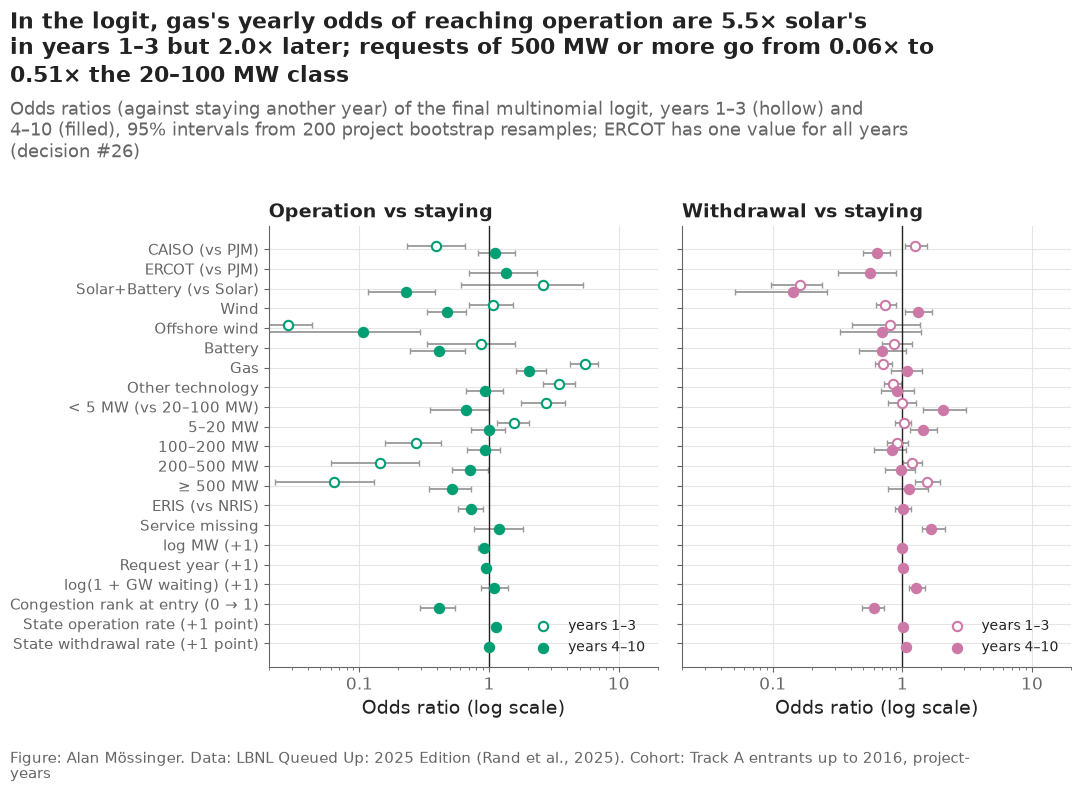

In [27]:
fig, axes = plt.subplots(1, 2, sharey=True, figsize=(11, 8))
labels = list(ATTRIBUTES.values())
y_pos = {label: len(labels) - 1 - i for i, label in enumerate(labels)}
for ax, cause in zip(axes, ["operation", "withdrawal"]):
    for period, offset, face in [("years 1–3", 0.18, "white"), ("years 4–10", -0.18, config.OUTCOME_COLORS[cause])]:
        part = odds[(odds["cause"] == cause) & (odds["period"] == period)]
        y = part["label"].map(y_pos) + offset
        ax.errorbar(part["odds_ratio"], y, xerr=[part["odds_ratio"] - part["ci_low"], part["ci_high"] - part["odds_ratio"]],
                    fmt="none", color="#999999", linewidth=1.3, capsize=2)
        ax.scatter(part["odds_ratio"], y, s=45, zorder=3, color=face, edgecolors=config.OUTCOME_COLORS[cause],
                   linewidths=1.5, label=period)
    ax.axvline(1, color=plots.INK, linewidth=1)
    ax.set_xscale("log")
    ax.set_xlim(0.02, 20)
    ax.xaxis.set_major_formatter(lambda x, _: f"{x:g}")
    ax.set_title(f"{cause.capitalize()} vs staying")
    ax.set_xlabel("Odds ratio (log scale)")
    ax.legend(loc="lower right", fontsize=10)
axes[0].set_yticks(list(y_pos.values()), list(y_pos.keys()), fontsize=10.5)
op = odds[odds["cause"] == "operation"].set_index(["attribute", "period"])["odds_ratio"]
plots.finish(fig,
             f"In the logit, gas's yearly odds of reaching operation are {op[('tech_Gas', 'years 1–3')]:.1f}× solar's in years "
             f"1–3 but {op[('tech_Gas', 'years 4–10')]:.1f}× later; requests of 500 MW or more go from "
             f"{op[('size_≥500', 'years 1–3')]:.2f}× to {op[('size_≥500', 'years 4–10')]:.2f}× the 20–100 MW class",
             "Odds ratios (against staying another year) of the final multinomial logit, years 1–3 (hollow) and 4–10 "
             "(filled), 95% intervals from 200 project bootstrap resamples; ERCOT has one value for all years (decision #26)",
             f"Track A entrants up to {config.TRAIN_MAX_YEAR}, project-years")
save(fig, "06_09_logit_odds_ratios", "Odds ratios of the final multinomial logit for operation and withdrawal, early and late years in the queue.")
plt.show()

**Reading this.** The logit's odds ratios confirm and sharpen notebook 05's hazard ratios. The fast profiles are fast early: gas's yearly odds of reaching operation are 5.48× solar's in years 1–3 and 2.04× afterwards; requests under 5 MW 2.76× the 20–100 MW class early and 0.67× later; requests of 500 MW or more 0.06× early and 0.51× later. CAISO's disadvantage is all early (0.39× PJM in years 1–3, 1.11× afterwards), and CAISO requests are more likely to withdraw early (1.26×) and less likely later (0.64×). ERCOT, with one value for all years, has 1.34× PJM's odds of operating and 0.56× its odds of withdrawing (Cox: 1.66× for operation). More GW waiting in a given year raises the odds of withdrawing (1.28× per log unit) more than those of operating (1.10×), and a request that entered a queue crowded relative to its region's history has lower odds of both (0.41× and 0.60×). Solar+Battery's early value (2.59×) rests on few early completions and its interval in the figure is wide; it should not be read as a finding.

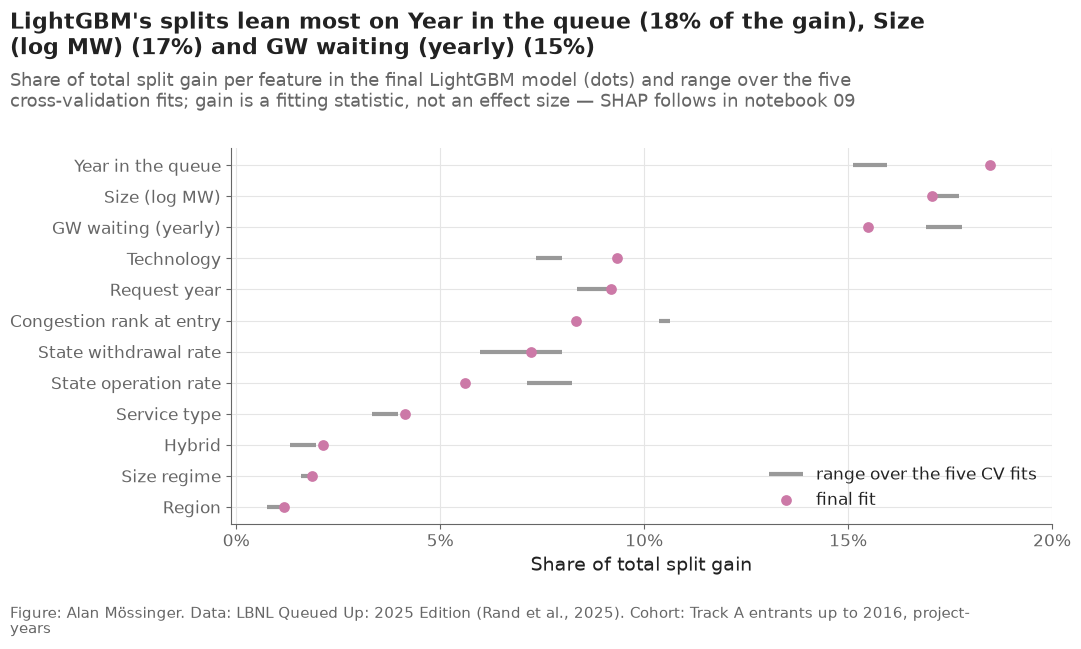

,fold 0,fold 1,fold 2,fold 3,fold 4,final
year_in_queue,0.156,0.158,0.160,0.158,0.151,0.185
log_mw,0.175,0.173,0.171,0.177,0.173,0.171
log_congestion_gw,0.173,0.178,0.169,0.172,0.177,0.155
tech,0.077,0.076,0.074,0.074,0.080,0.093
q_year,0.084,0.092,0.093,0.089,0.089,0.092
congestion_rank,0.104,0.104,0.105,0.104,0.106,0.083
state_withdrawal,0.080,0.070,0.071,0.068,0.060,0.072
state_operation,0.074,0.076,0.071,0.078,0.082,0.056
service,0.033,0.035,0.040,0.036,0.038,0.041
hybrid,0.020,0.013,0.019,0.019,0.018,0.021


In [28]:
importance_rows = []
names = list(discrete_time.lgbm_design(fold_data[0][0].iloc[:5]).columns)
for i in range(len(folds)):
    gains = boosters[((LGBM_PARAMS["num_leaves"], LGBM_PARAMS["min_data_in_leaf"]), i)].feature_importance(
        "gain", iteration=CHOSEN_CV_ROUNDS)
    importance_rows.append(pd.Series(gains / gains.sum(), index=names, name=f"fold {i}"))
importance = pd.concat(importance_rows, axis=1)
final_gain = lgbm_final.feature_importance("gain")
importance["final"] = final_gain / final_gain.sum()
importance = importance.sort_values("final")
importance.to_csv(paths.RESULTS / "dt_lgbm_importance.csv")
FEATURE_LABELS = {"year_in_queue": "Year in the queue", "region": "Region", "tech": "Technology", "size_regime": "Size regime",
                  "service": "Service type", "hybrid": "Hybrid", "log_mw": "Size (log MW)", "q_year": "Request year",
                  "log_congestion_gw": "GW waiting (yearly)", "congestion_rank": "Congestion rank at entry",
                  "state_operation": "State operation rate", "state_withdrawal": "State withdrawal rate"}

fig, ax = plt.subplots()
fold_cols = [c for c in importance.columns if c.startswith("fold")]
y = np.arange(len(importance))
ax.hlines(y, importance[fold_cols].min(axis=1), importance[fold_cols].max(axis=1), color="#999999", linewidth=3,
          label="range over the five CV fits")
ax.scatter(importance["final"], y, color=MODEL_STYLE["dt_lgbm"]["color"], s=60, zorder=3, label="final fit")
ax.set_yticks(y, [FEATURE_LABELS[f] for f in importance.index])
ax.set_xticks(np.arange(0, importance.to_numpy().max() + 0.05, 0.05))
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.set_xlabel("Share of total split gain")
ax.legend(loc="lower right")
top = importance["final"].sort_values(ascending=False)
plots.finish(fig,
             f"LightGBM's splits lean most on {FEATURE_LABELS[top.index[0]]} ({top.iloc[0]:.0%} of the gain), "
             f"{FEATURE_LABELS[top.index[1]]} ({top.iloc[1]:.0%}) and {FEATURE_LABELS[top.index[2]]} "
             f"({top.iloc[2]:.0%})",
             "Share of total split gain per feature in the final LightGBM model (dots) and range over the five "
             "cross-validation fits; gain is a fitting statistic, not an effect size — SHAP follows in notebook 09",
             f"Track A entrants up to {config.TRAIN_MAX_YEAR}, project-years")
save(fig, "06_10_lgbm_importance", "Split-gain importance of each feature in the LightGBM hazard model.")
plt.show()
importance.round(3).iloc[::-1]

**Reading this.** LightGBM's splits use the year in the queue most (18.5% of the gain in the final fit), then size (17.1%) and the yearly GW waiting (15.5%); region carries only 1.2%. That does not mean region does not matter: the state rates, congestion and technology mix already differ by region, so the trees reach regional differences through them. The five cross-validation fits give similar shares (e.g. size 17.1–17.7%), so the ranking is stable. Gain says where the trees split, not how much a feature moves a prediction; SHAP in notebook 09 answers that.

### Year-in-queue profiles for a reference request

The yearly hazards each model gives one reference request — solar,
20–100 MW (50 MW), NRIS, not hybrid, requested in 2016 at its region's
median congestion, in its region's most common state — by region; then the
operation hazard for the same request in PJM with each technology. The
second view shows whether the models let technologies differ in *when* they
reach operation, not only in how often.

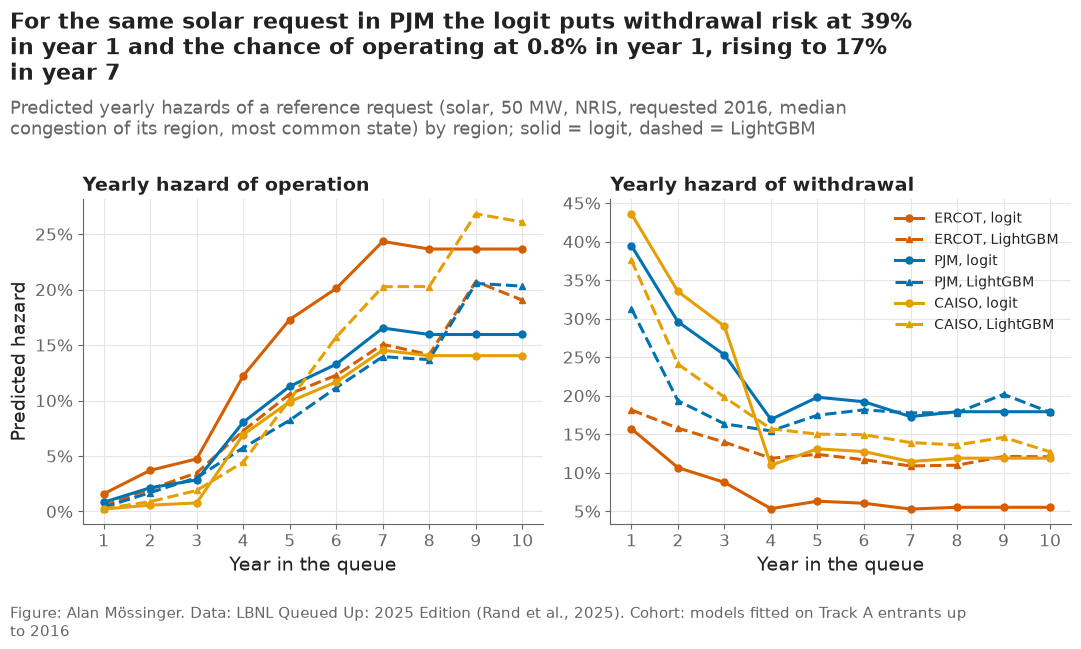

,dt_logit operation ERCOT,dt_logit operation PJM,dt_logit operation CAISO,dt_logit withdrawal ERCOT,dt_logit withdrawal PJM,dt_logit withdrawal CAISO,dt_lgbm operation ERCOT,dt_lgbm operation PJM,dt_lgbm operation CAISO,dt_lgbm withdrawal ERCOT,dt_lgbm withdrawal PJM,dt_lgbm withdrawal CAISO
year_in_queue,,,,,,,,,,,,
1,0.016,0.008,0.002,0.157,0.395,0.436,0.005,0.004,0.002,0.181,0.313,0.376
2,0.037,0.021,0.006,0.107,0.296,0.335,0.020,0.017,0.009,0.158,0.193,0.241
3,0.047,0.028,0.008,0.087,0.253,0.290,0.035,0.030,0.019,0.140,0.163,0.198
4,0.122,0.080,0.069,0.053,0.169,0.110,0.073,0.057,0.044,0.119,0.154,0.157
5,0.173,0.113,0.099,0.063,0.198,0.131,0.106,0.082,0.101,0.124,0.175,0.150
6,0.201,0.133,0.117,0.060,0.192,0.127,0.123,0.112,0.157,0.117,0.182,0.149
7,0.243,0.165,0.145,0.053,0.173,0.114,0.151,0.140,0.203,0.109,0.178,0.139
8,0.237,0.160,0.140,0.055,0.179,0.119,0.141,0.137,0.203,0.110,0.178,0.136
9,0.237,0.160,0.140,0.055,0.179,0.119,0.207,0.206,0.268,0.121,0.202,0.146


In [29]:
def reference(region, tech="Solar", n=1):
    """A synthetic reference request in `region` (entry-time features only)."""
    part = final[final["region"] == region]
    return pd.DataFrame([{"region": region, "tech": tech, "size_regime": "20–<100", "service": "NRIS", "hybrid": False,
                          "log_mw": np.log(50), "q_year": 2016, "q_date": pd.Timestamp("2016-07-01"),
                          "congestion_gw": part["congestion_gw"].median(), "congestion_rank": part["congestion_rank"].median(),
                          "state": part["state"].mode().iloc[0]}] * n, index=[f"{region}|{tech}"] * n)


def hazards_of(frame):
    """Yearly hazards (operation, withdrawal) of both final models for each request of `frame`, years 1–10."""
    rows = discrete_time.prediction_rows(frame)
    _, rows = discrete_time.encode_state(rows_final, [rows])
    out = {}
    for model, X in [("dt_logit", discrete_time.logit_design(rows, INTERACTIONS)), ("dt_lgbm", discrete_time.lgbm_design(rows))]:
        h_op, h_wd = discrete_time.predict_hazards(logit_final if model == "dt_logit" else lgbm_final, X)
        out[model] = (h_op.reshape(len(frame), -1), h_wd.reshape(len(frame), -1))
    return out


refs = pd.concat([reference(region) for region in TRACK_A])
ref_h = hazards_of(refs)
fig, axes = plt.subplots(1, 2, sharex=True)
for ax, (cause_i, cause) in zip(axes, enumerate(["operation", "withdrawal"])):
    for r_i, region in enumerate(TRACK_A):
        for model, style in [("dt_logit", "-"), ("dt_lgbm", "--")]:
            ax.plot(YEARS, ref_h[model][cause_i][r_i], color=plots.region_color(region), linestyle=style,
                    marker="o" if model == "dt_logit" else "^", markersize=5,
                    label=f"{region}, {'logit' if model == 'dt_logit' else 'LightGBM'}")
    ax.set_title(f"Yearly hazard of {cause}")
    ax.set_xlabel("Year in the queue")
    ax.set_xticks(YEARS)
    ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
axes[0].set_ylabel("Predicted hazard")
axes[1].legend(loc="upper right", fontsize=10, ncol=1)
ref_table = pd.DataFrame({f"{model} {cause} {region}": ref_h[model][c_i][r_i]
                          for model in ["dt_logit", "dt_lgbm"] for c_i, cause in enumerate(["operation", "withdrawal"])
                          for r_i, region in enumerate(TRACK_A)}, index=YEARS)
ref_table.index.name = "year_in_queue"
ref_table.to_csv(paths.RESULTS / "dt_reference_request.csv")
pjm_i = TRACK_A.index("PJM")
plots.finish(fig,
             f"For the same solar request in PJM the logit puts withdrawal risk at {ref_h['dt_logit'][1][pjm_i][0]:.0%} in "
             f"year 1 and the chance of operating at {ref_h['dt_logit'][0][pjm_i][0]:.1%} in year 1, rising to "
             f"{ref_h['dt_logit'][0][pjm_i][6]:.0%} in year 7",
             "Predicted yearly hazards of a reference request (solar, 50 MW, NRIS, requested 2016, median congestion of its "
             "region, most common state) by region; solid = logit, dashed = LightGBM",
             f"models fitted on Track A entrants up to {config.TRAIN_MAX_YEAR}")
save(fig, "06_11_reference_hazards", "Predicted yearly hazards of operation and withdrawal for a reference solar request in each region, both models.")
plt.show()
ref_table.round(3)

LightGBM gas ÷ solar yearly operation hazard, years 1–10: [5.1, 5.5, 4.8, 3.7, 2.7, 2.2, 1.9, 1.9, 1.7, 1.7]


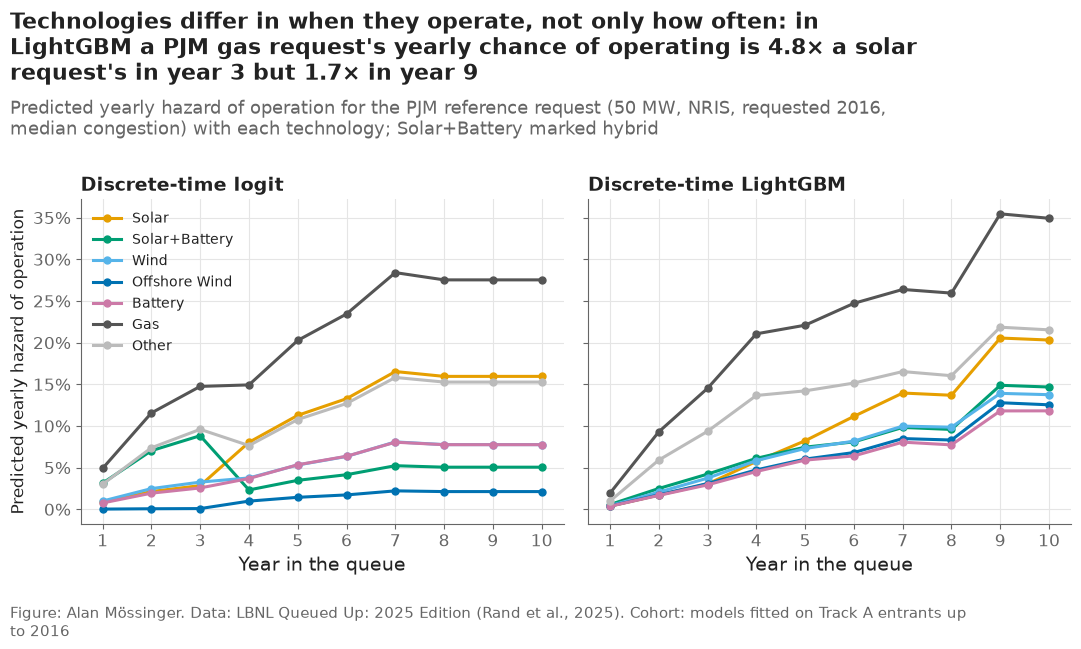

,dt_logit Solar,dt_logit Solar+Battery,dt_logit Wind,dt_logit Offshore Wind,dt_logit Battery,dt_logit Gas,dt_logit Other,dt_lgbm Solar,dt_lgbm Solar+Battery,dt_lgbm Wind,dt_lgbm Offshore Wind,dt_lgbm Battery,dt_lgbm Gas,dt_lgbm Other
1,0.008,0.031,0.010,0.000,0.008,0.049,0.030,0.004,0.006,0.004,0.004,0.004,0.019,0.010
2,0.021,0.070,0.025,0.001,0.019,0.116,0.074,0.017,0.025,0.021,0.017,0.017,0.093,0.059
3,0.028,0.088,0.033,0.001,0.026,0.147,0.096,0.030,0.042,0.037,0.031,0.029,0.145,0.094
4,0.080,0.023,0.038,0.010,0.037,0.149,0.076,0.057,0.061,0.058,0.047,0.045,0.211,0.137
5,0.113,0.035,0.053,0.014,0.053,0.203,0.108,0.082,0.075,0.073,0.060,0.059,0.221,0.142
6,0.133,0.042,0.063,0.017,0.064,0.234,0.127,0.112,0.081,0.082,0.068,0.064,0.247,0.152
7,0.165,0.052,0.081,0.022,0.081,0.284,0.158,0.140,0.098,0.100,0.085,0.081,0.264,0.165
8,0.160,0.051,0.078,0.021,0.078,0.275,0.153,0.137,0.096,0.099,0.083,0.077,0.259,0.160
9,0.160,0.051,0.078,0.021,0.078,0.275,0.153,0.206,0.149,0.139,0.128,0.118,0.355,0.219
10,0.160,0.051,0.078,0.021,0.078,0.275,0.153,0.203,0.147,0.138,0.125,0.118,0.349,0.215


In [30]:
techs = discrete_time.TECH_LEVELS
tech_refs = pd.concat([reference("PJM", tech) for tech in techs])
tech_refs["hybrid"] = tech_refs["tech"] == "Solar+Battery"
tech_h = hazards_of(tech_refs)
fig, axes = plt.subplots(1, 2, sharey=True)
for ax, model in zip(axes, ["dt_logit", "dt_lgbm"]):
    for t_i, tech in enumerate(techs):
        ax.plot(YEARS, tech_h[model][0][t_i], color=config.TECH_COLORS[tech], marker="o", markersize=5, label=tech)
    ax.set_title(MODEL_LABELS[model])
    ax.set_xlabel("Year in the queue")
    ax.set_xticks(YEARS)
    ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
axes[0].set_ylabel("Predicted yearly hazard of operation")
axes[0].legend(loc="upper left", fontsize=10)
tech_table = pd.DataFrame({f"{model} {tech}": tech_h[model][0][t_i] for model in ["dt_logit", "dt_lgbm"]
                           for t_i, tech in enumerate(techs)}, index=YEARS)
gas, solar = (tech_h["dt_lgbm"][0][techs.index(t)] for t in ["Gas", "Solar"])
print("LightGBM gas ÷ solar yearly operation hazard, years 1–10:", np.round(gas / solar, 1).tolist())
plots.finish(fig,
             f"Technologies differ in when they operate, not only how often: in LightGBM a PJM gas request's yearly chance "
             f"of operating is {gas[2] / solar[2]:.1f}× a solar request's in year 3 but {gas[8] / solar[8]:.1f}× in year 9",
             "Predicted yearly hazard of operation for the PJM reference request (50 MW, NRIS, requested 2016, median "
             "congestion) with each technology; Solar+Battery marked hybrid",
             f"models fitted on Track A entrants up to {config.TRAIN_MAX_YEAR}")
save(fig, "06_12_technology_profiles", "Predicted yearly hazard of operation by year in the queue for each technology, PJM reference request, both models.")
plt.show()
tech_table.round(3)

**Reading this.** For the same 50 MW solar request, the logit puts PJM's yearly withdrawal risk at 39.5% in year 1 and its yearly chance of operating at 0.8% in year 1, rising to 16.5% in year 7; in ERCOT the operation hazard is higher in every year (1.6% in year 1, 24.3% in year 7) and the withdrawal risk lower (15.7% in year 1). LightGBM gives ERCOT and PJM nearly the same operation hazards (e.g. 15.1% and 14.0% in year 7), so the two models disagree on how much faster ERCOT is — unsurprising, since ERCOT's effect rests on 288 project-years. Across technologies, LightGBM lets the gas advantage fade smoothly: a PJM gas request's yearly hazard is 5.1× solar's in year 1, 4.8× in year 3, 2.2× in year 6 and 1.7× in year 9. The logit can only switch between a years 1–3 and a years 4–10 value, which shows as jumps at year 4 (Solar+Battery falls from 8.8% to 2.3%); that step is a property of the design, not of the data, and one reason to prefer the smoother LightGBM profile for timing.

## 9. Acceptance check: do the models reproduce the observed incidence?

PLAN.md §6: the model's P(operation by t), averaged by region, must lie
inside the Aalen–Johansen 95% bootstrap band. For PJM and CAISO the
comparison is made on the entrants the final models were fitted on (to 2016),
with the same estimator and 500 resamples as notebook 03 — not on notebook
03's all-years curves, which contain the 2017–2019 test outcomes. Each request
is predicted from its entry date with congestion frozen there, exactly as test
requests will be.

**ERCOT is checked on its 2016 entrants** (section 7: models fitted on
entrants to 2015, band from 500 resamples), not on all its entrants to 2016
(decision #28, Alan, 2026-10-04). Under delayed entry the models never see
ERCOT before 2018-08-29, so ERCOT's earlier entrants — most of whom had left
the queue by that day — cannot be reproduced by construction; the 2016
entrants are the ERCOT cohort closest to the regime the models learn from.
The rule was changed after the first run showed ERCOT's all-entrants averages
below the band; that result stays in the table and the figure, marked as
reported, not checked. The test
`tests/test_discrete_time.py::test_model_cif_inside_aj_bands` reads the rows
marked `counts`.

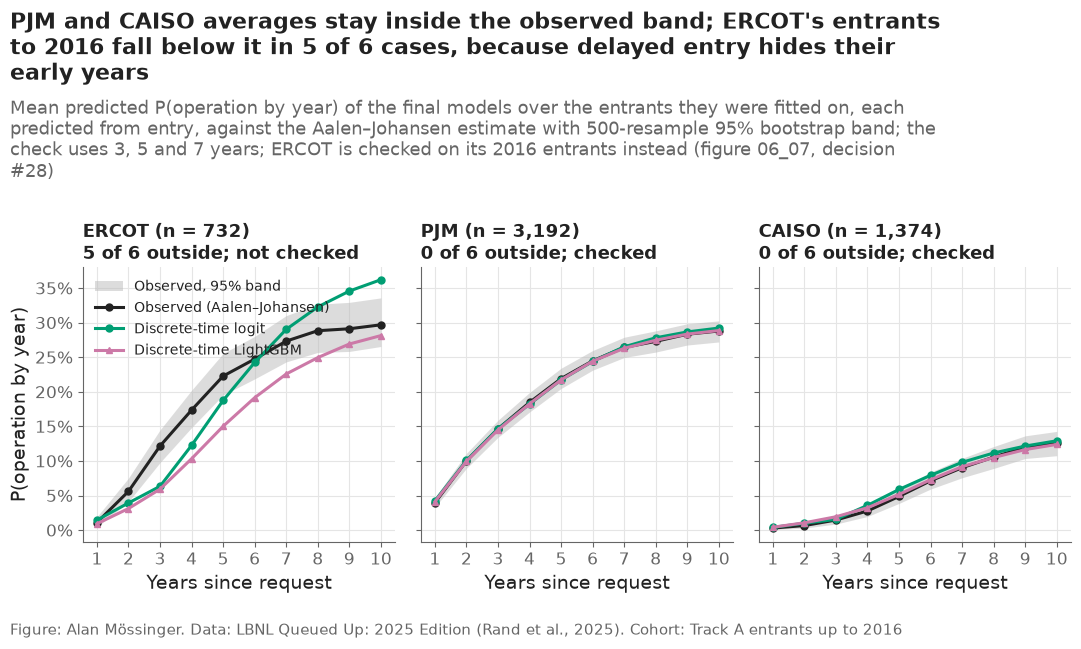

checked rows inside the band: 18 of 18


,region,cohort,counts,model,horizon,observed,band_low,band_high,predicted,inside
0,ERCOT,entrants to 2016 (final fit),False,dt_logit,3,0.122,0.098,0.145,0.063,False
1,ERCOT,entrants to 2016 (final fit),False,dt_lgbm,3,0.122,0.098,0.145,0.059,False
2,ERCOT,entrants to 2016 (final fit),False,dt_logit,5,0.223,0.195,0.255,0.187,False
3,ERCOT,entrants to 2016 (final fit),False,dt_lgbm,5,0.223,0.195,0.255,0.150,False
4,ERCOT,entrants to 2016 (final fit),False,dt_logit,7,0.273,0.243,0.310,0.290,True
5,ERCOT,entrants to 2016 (final fit),False,dt_lgbm,7,0.273,0.243,0.310,0.226,False
6,PJM,entrants to 2016 (final fit),True,dt_logit,3,0.146,0.134,0.159,0.147,True
7,PJM,entrants to 2016 (final fit),True,dt_lgbm,3,0.146,0.134,0.159,0.145,True
8,PJM,entrants to 2016 (final fit),True,dt_logit,5,0.219,0.205,0.234,0.217,True
9,PJM,entrants to 2016 (final fit),True,dt_lgbm,5,0.219,0.205,0.234,0.217,True


In [31]:
fit_pred = predict(final, rows_final, logit_final, lgbm_final, horizons=list(YEARS))
band_rows, curve_rows = [], []
for i, region in enumerate(TRACK_A):
    part = final[final["region"] == region]
    observed = survival_tools.aalen_johansen(part["duration_years"], part["event"], YEARS)
    band = survival_tools.bootstrap_bands(part["duration_years"], part["event"], YEARS, n_boot=500, seed=600 + i)
    for j, year in enumerate(YEARS):
        entry = {"region": region, "n": len(part), "year": year, "observed": observed["cif_operation"].iloc[j],
                 "band_low": band["cif_operation_low"].iloc[j], "band_high": band["cif_operation_high"].iloc[j]}
        for model in ["dt_logit", "dt_lgbm"]:
            entry[model] = fit_pred[model].loc[part.index, year].mean()
        curve_rows.append(entry)
curves_fit = pd.DataFrame(curve_rows)
for _, row in curves_fit[curves_fit["year"].isin(HORIZONS)].iterrows():
    for model in ["dt_logit", "dt_lgbm"]:
        band_rows.append({"region": row["region"], "cohort": f"entrants to {config.TRAIN_MAX_YEAR} (final fit)",
                          "counts": row["region"] != "ERCOT", "model": model, "horizon": int(row["year"]),
                          "observed": row["observed"], "band_low": row["band_low"], "band_high": row["band_high"],
                          "predicted": row[model]})
for _, row in validation[validation["region"] == "ERCOT"].iterrows():  # decision #28
    for model in ["dt_logit", "dt_lgbm"]:
        band_rows.append({"region": "ERCOT", "cohort": f"{config.VALIDATION_YEAR} entrants (fit to {config.TUNE_MAX_YEAR})",
                          "counts": True, "model": model, "horizon": int(row["horizon"]), "observed": row["observed"],
                          "band_low": row["low"], "band_high": row["high"], "predicted": row[model]})
band_check = pd.DataFrame(band_rows)
band_check["inside"] = (band_check["band_low"] <= band_check["predicted"]) & (band_check["predicted"] <= band_check["band_high"])
counted = band_check[band_check["counts"]]
band_check.to_csv(paths.RESULTS / "dt_band_check.csv", index=False)

fig, axes = plt.subplots(1, 3, sharey=True)
for ax, region in zip(axes, TRACK_A):
    part = curves_fit[curves_fit["region"] == region]
    ax.fill_between(part["year"], part["band_low"], part["band_high"], color="#BBBBBB", alpha=0.5, linewidth=0,
                    label="Observed, 95% band")
    ax.plot(part["year"], part["observed"], color=plots.INK, marker="o", markersize=5, label="Observed (Aalen–Johansen)")
    for model in ["dt_logit", "dt_lgbm"]:
        ax.plot(part["year"], part[model], label=MODEL_LABELS[model], **{**MODEL_STYLE[model], "markersize": 5})
    shown = band_check[(band_check["region"] == region) & band_check["cohort"].str.startswith("entrants")]
    status = "checked" if region != "ERCOT" else "not checked"
    ax.set_title(f"{region} (n = {int(part['n'].iloc[0]):,})\n{int((~shown['inside']).sum())} of 6 outside; {status}", fontsize=13)
    ax.set_xlabel("Years since request")
    ax.set_xticks(YEARS)
    ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
axes[0].set_ylabel("P(operation by year)")
axes[0].legend(loc="upper left", fontsize=10)
ercot_all = band_check[(band_check["region"] == "ERCOT") & ~band_check["counts"]]
pjm_caiso_inside = bool(counted.loc[counted["region"] != "ERCOT", "inside"].all())
plots.finish(fig,
             f"PJM and CAISO averages {'stay inside' if pjm_caiso_inside else 'do not all stay inside'} the observed band; "
             f"ERCOT's entrants to 2016 fall below it in {int((~ercot_all['inside']).sum())} of 6 cases, because delayed "
             "entry hides their early years",
             "Mean predicted P(operation by year) of the final models over the entrants they were fitted on, each predicted from "
             "entry, against the Aalen–Johansen estimate with 500-resample 95% bootstrap band; the check uses 3, 5 and 7 years; "
             "ERCOT is checked on its 2016 entrants instead (figure 06_07, decision #28)",
             f"Track A entrants up to {config.TRAIN_MAX_YEAR}")
save(fig, "06_13_band_check", "Model-averaged P(operation by year) against the Aalen–Johansen estimate and bootstrap band, by region (acceptance check).")
plt.show()
print(f"checked rows inside the band: {int(counted['inside'].sum())} of {len(counted)}")
band_check.round(3)

Where the averages miss, the entry cohorts show why. The same comparison by
entry cohort, at 3 and 5 years (200 resamples per cohort band).

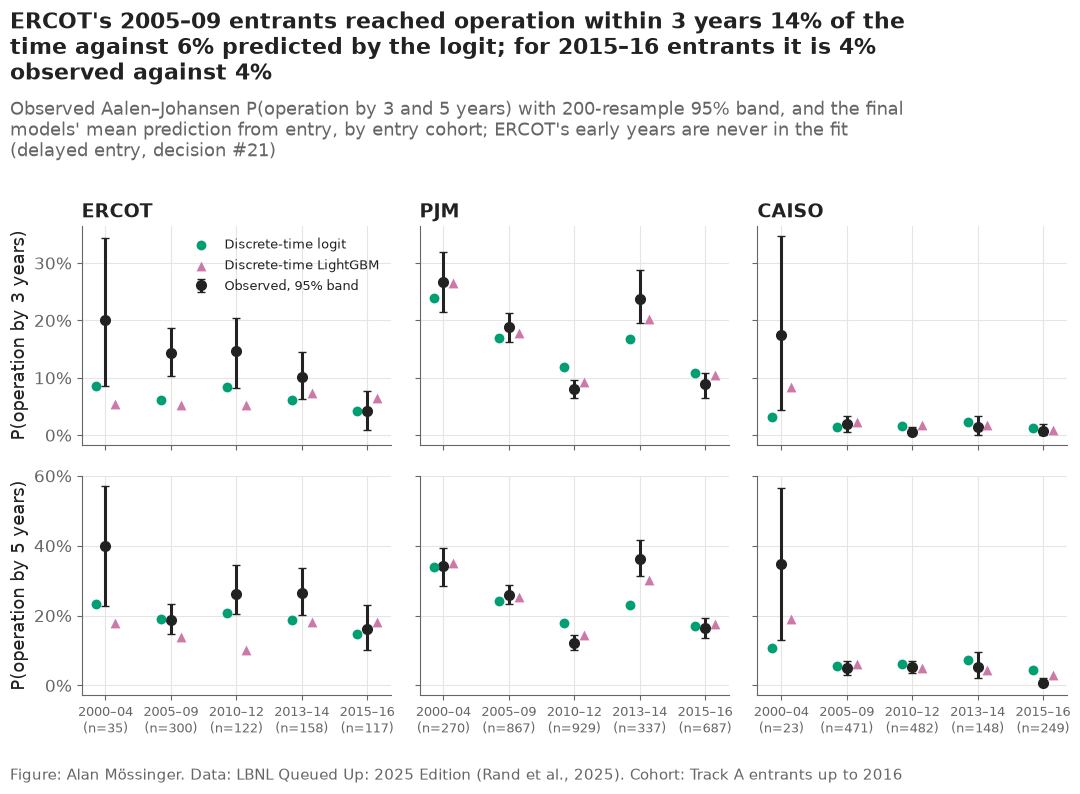

,region,cohort,n,horizon,observed,low,high,dt_logit,dt_lgbm
0,CAISO,2000–04,23,3,0.174,0.043,0.348,0.033,0.084
1,CAISO,2000–04,23,5,0.348,0.130,0.565,0.107,0.191
2,CAISO,2005–09,471,3,0.019,0.006,0.034,0.014,0.023
3,CAISO,2005–09,471,5,0.049,0.030,0.070,0.055,0.060
4,CAISO,2010–12,482,3,0.006,0.000,0.015,0.015,0.019
5,CAISO,2010–12,482,5,0.054,0.035,0.071,0.062,0.050
6,CAISO,2013–14,148,3,0.014,0.000,0.034,0.023,0.018
7,CAISO,2013–14,148,5,0.054,0.020,0.095,0.072,0.045
8,CAISO,2015–16,249,3,0.008,0.000,0.020,0.013,0.009
9,CAISO,2015–16,249,5,0.008,0.000,0.020,0.045,0.030


In [32]:
cohort_bins = [1999, 2004, 2009, 2012, 2014, 2016]
cohort_labels = ["2000–04", "2005–09", "2010–12", "2013–14", "2015–16"]
cohorts = pd.cut(final["q_year"].astype(float), cohort_bins, labels=cohort_labels)
cohort_rows = []
for i, ((region, cohort), part) in enumerate(final.groupby([final["region"], cohorts], observed=True)):
    observed = survival_tools.aalen_johansen(part["duration_years"], part["event"], [3, 5])
    band = survival_tools.bootstrap_bands(part["duration_years"], part["event"], [3, 5], n_boot=200, seed=700 + i)
    for j, h in enumerate([3, 5]):
        cohort_rows.append({"region": region, "cohort": cohort, "n": len(part), "horizon": h,
                            "observed": observed["cif_operation"].iloc[j], "low": band["cif_operation_low"].iloc[j],
                            "high": band["cif_operation_high"].iloc[j],
                            "dt_logit": fit_pred["dt_logit"].loc[part.index, h].mean(),
                            "dt_lgbm": fit_pred["dt_lgbm"].loc[part.index, h].mean()})
cohort_check = pd.DataFrame(cohort_rows)
cohort_check.to_csv(paths.RESULTS / "dt_cohort_check.csv", index=False)

fig, axes = plt.subplots(2, 3, sharey="row", figsize=(11, 8))
for row_i, h in enumerate([3, 5]):
    for ax, region in zip(axes[row_i], TRACK_A):
        part = cohort_check[(cohort_check["region"] == region) & (cohort_check["horizon"] == h)]
        x = np.arange(len(part))
        ax.errorbar(x, part["observed"], yerr=[part["observed"] - part["low"], part["high"] - part["observed"]],
                    fmt="o", color=plots.INK, capsize=3, label="Observed, 95% band")
        for model, dx in [("dt_logit", -0.15), ("dt_lgbm", 0.15)]:
            style = MODEL_STYLE[model]
            ax.scatter(x + dx, part[model], color=style["color"], marker=style["marker"], s=50, zorder=3,
                       label=MODEL_LABELS[model])
        ax.set_xticks(x, [f"{c}\n(n={n})" for c, n in zip(part["cohort"], part["n"])] if row_i == 1 else [], fontsize=9)
        ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
        if row_i == 0:
            ax.set_title(region)
    axes[row_i, 0].set_ylabel(f"P(operation by {h} years)")
axes[0, 0].legend(loc="upper right", fontsize=9.5)
ercot3 = cohort_check[(cohort_check["region"] == "ERCOT") & (cohort_check["horizon"] == 3)].set_index("cohort")
plots.finish(fig,
             f"ERCOT's 2005–09 entrants reached operation within 3 years {ercot3.loc['2005–09', 'observed']:.0%} of the "
             f"time against {ercot3.loc['2005–09', 'dt_logit']:.0%} predicted by the logit; for 2015–16 entrants it is "
             f"{ercot3.loc['2015–16', 'observed']:.0%} observed against {ercot3.loc['2015–16', 'dt_logit']:.0%}",
             "Observed Aalen–Johansen P(operation by 3 and 5 years) with 200-resample 95% band, and the final models' mean "
             "prediction from entry, by entry cohort; ERCOT's early years are never in the fit (delayed entry, decision #21)",
             f"Track A entrants up to {config.TRAIN_MAX_YEAR}")
save(fig, "06_14_cohort_check", "Observed versus predicted P(operation by 3 and 5 years) by entry cohort and region.")
plt.show()
cohort_check.round(3)

**Reading this.** With the check as decided (decision #28), it passes for both models. In PJM and CAISO the mean P(operation by 3, 5 and 7 years) over all entrants to 2016 lies inside the observed 95% band (e.g. PJM at 5 years: 21.7% for both models against 21.9% observed); for ERCOT's 2016 entrants, predicted by models that never saw them, both models are inside the band at every horizon (section 7: logit 3.8%, 15.0%, 24.9%; LightGBM 4.4%, 13.6%, 23.9%; observed 4.5%, 16.7%, 24.2%). That ERCOT check is weak: the 2016 cohort has only 66 ERCOT requests, so its band is wide (0–10.6% at 3 years, 14.4–34.8% at 7), and passing it shows the models are not far off, not that they are right. The ERCOT rule was changed after the first run, and the result it replaced is kept: over all ERCOT entrants to 2016, 5 of 6 values are below the band — the logit predicts 6.3% by year 3 against 12.2% observed (band 9.8–14.5%) and 18.7% by year 5 against 22.3%, LightGBM 5.9%, 15.0% and 22.6%. The cohort view shows why: ERCOT's 2005–09 entrants reached operation within 3 years 14.3% of the time against 6.1% (logit) and 5.3% (LightGBM) predicted, its 2010–12 entrants 14.8% against 8.4% and 5.3%, but its 2015–16 entrants 4.3% against 4.3% and 6.5%. Those earlier entrants finished fast in years delayed entry never shows the models (decision #21), so the models describe ERCOT as it behaved after 2018 — the regime the 2017–2019 test entrants face. That is a limitation for the report, and the reason the ERCOT sensitivity runs in notebook 08 matter. PJM's cohorts show what no entry-time model can capture: 2013–14 entrants did far better than predicted (23.7% by 3 years against 16.8% and 20.3%) and 2010–12 entrants worse (8.1% against 11.8% and 9.3%), offsetting in the regional average.

## 10. Predictions for the validation and test cohorts

Final models, every validation and test request predicted from its entry
date with congestion frozen there. They are merged with the baseline and Cox
predictions of notebook 05 into one long table (one row per request ×
horizon) in `data/processed/`. The observed event and duration are carried
along for notebook 08; nothing below summarises them.

In [33]:
targets = pd.concat([valid, test])
target_pred = predict(targets, rows_final, logit_final, lgbm_final)
pred05 = pd.read_parquet(paths.DATA_INTERIM / "predictions_05.parquet")
assert pred05.index.equals(targets.index), "notebook 05 predicted a different set of requests"
long_rows = []
for h in HORIZONS:
    long_rows.append(pd.DataFrame({
        "project_key": targets["project_key"].astype(str), "region": targets["region"].astype(str),
        "q_year": targets["q_year"].astype(int), "split": pred05["split"], "horizon": h,
        "baseline": pred05[f"baseline_{h}"], "baseline_cell": pred05["baseline_cell"], "cox": pred05[f"cox_{h}"],
        "dt_logit": target_pred["dt_logit"][h], "dt_lgbm": target_pred["dt_lgbm"][h],
        "dt_logit_expected_years": target_pred["dt_logit"]["expected_years"],
        "dt_lgbm_expected_years": target_pred["dt_lgbm"]["expected_years"],
        "event": targets["event"], "duration_years": targets["duration_years"],
        "entry_years": targets["entry_years"], "wd_bulk_date": targets["wd_bulk_date"].astype(bool)}))
predictions = pd.concat(long_rows, ignore_index=True)
out_file = paths.DATA_PROCESSED / "predictions_trackA.parquet"
predictions.to_parquet(out_file, index=False)
print(f"{out_file.name}: {len(predictions):,} rows ({predictions['project_key'].nunique():,} requests × {len(HORIZONS)} horizons), "
      f"{out_file.stat().st_size / 1e6:.2f} MB")
predictions.groupby(["split", "region", "horizon"])[["baseline", "cox", "dt_logit", "dt_lgbm"]].mean().round(3)

predictions_trackA.parquet: 8,523 rows (2,841 requests × 3 horizons), 0.32 MB


baseline    cox  dt_logit  dt_lgbm
split      region horizon                                    
test       CAISO  3           0.008  0.023     0.008    0.012
                  5           0.021  0.042     0.026    0.036
                  7           0.053  0.064     0.050    0.073
           ERCOT  3           0.090  0.095     0.060    0.080
                  5           0.183  0.153     0.164    0.176
                  7           0.230  0.196     0.244    0.250
           PJM    3           0.100  0.068     0.061    0.077
                  5           0.159  0.114     0.112    0.145
                  7           0.203  0.154     0.156    0.204
validation CAISO  3           0.007  0.033     0.009    0.008
                  5           0.032  0.061     0.040    0.027
                  7           0.072  0.089     0.073    0.053
           ERCOT  3           0.100  0.076     0.036    0.062
                  5           0.197  0.126     0.139    0.182
                  7           0.245  0.167     0.224    0.296
           PJM    3           0.111  0.093     0.097    0.091
                  5           0.176  0.154     0.162    0.158
                  7           0.223  0.200     0.211    0.207

distinct baseline values per region: {'CAISO': 7, 'ERCOT': 4, 'PJM': 6}


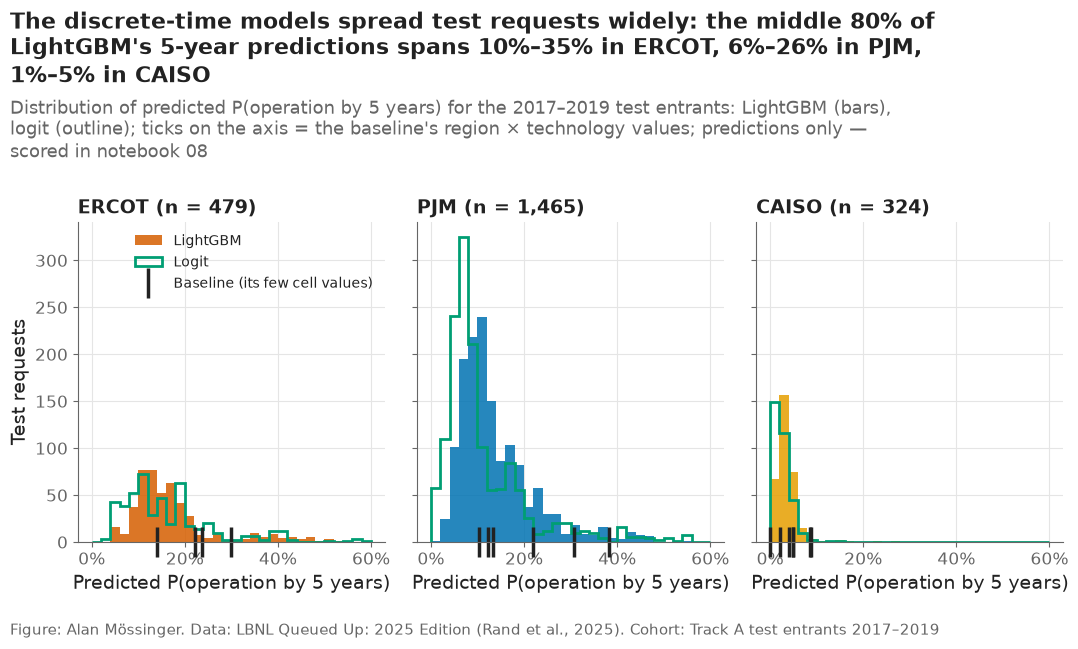

dt_logit        dt_lgbm       
            0.1    0.9     0.1    0.9
region                               
CAISO     0.009  0.051   0.015  0.053
ERCOT     0.061  0.320   0.096  0.345
PJM       0.037  0.212   0.062  0.256

In [34]:
test_pred = predictions[(predictions["split"] == "test") & (predictions["horizon"] == 5)]
fig, axes = plt.subplots(1, 3, sharey=True)
bins = np.linspace(0, 0.6, 31)
for ax, region in zip(axes, TRACK_A):
    part = test_pred[test_pred["region"] == region]
    ax.hist(part["dt_lgbm"], bins=bins, color=plots.region_color(region), alpha=0.85, label="LightGBM")
    ax.hist(part["dt_logit"], bins=bins, histtype="step", color=MODEL_STYLE["dt_logit"]["color"], linewidth=2, label="Logit")
    cells = part["baseline"].round(4).unique()
    ax.plot(cells, np.zeros(len(cells)), linestyle="none", marker="|", markersize=22, markeredgewidth=2.5,
            color=plots.INK, label="Baseline (its few cell values)", clip_on=False)
    ax.set_title(f"{region} (n = {len(part):,})")
    ax.set_xlabel("Predicted P(operation by 5 years)")
    ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
axes[0].set_ylabel("Test requests")
axes[0].legend(loc="upper right", fontsize=10)
print("distinct baseline values per region:", test_pred.groupby("region")["baseline"].nunique().to_dict())
spread = test_pred.groupby("region")[["dt_logit", "dt_lgbm"]].quantile([0.1, 0.9]).unstack()
plots.finish(fig,
             "The discrete-time models spread test requests widely: the middle 80% of LightGBM's 5-year predictions spans "
             + ", ".join(f"{spread.loc[r, ('dt_lgbm', 0.1)]:.0%}–{spread.loc[r, ('dt_lgbm', 0.9)]:.0%} in {r}" for r in TRACK_A),
             "Distribution of predicted P(operation by 5 years) for the 2017–2019 test entrants: LightGBM (bars), logit "
             "(outline); ticks on the axis = the baseline's region × technology values; predictions only — scored in notebook 08",
             "Track A test entrants 2017–2019")
save(fig, "06_15_test_prediction_spread", "Distribution of 5-year predictions for the test entrants: discrete-time models versus baseline.")
plt.show()
spread.round(3)

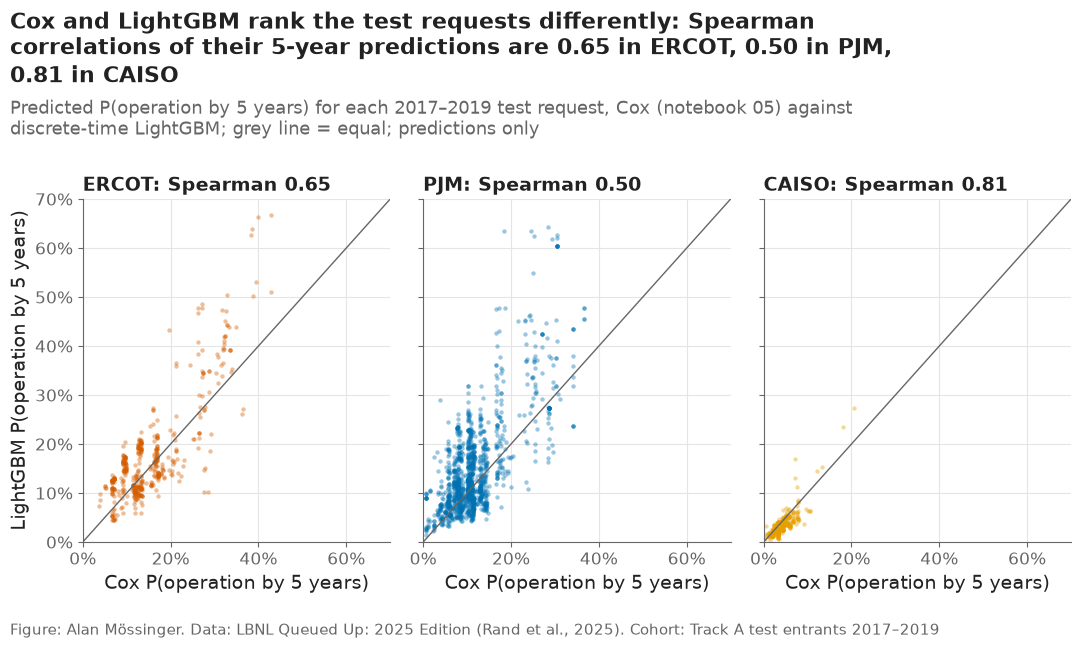

,dt_logit,dt_lgbm,dt_logit vs dt_lgbm
ERCOT,0.98,0.65,0.71
PJM,0.80,0.50,0.77
CAISO,0.95,0.81,0.81


In [35]:
fig, axes = plt.subplots(1, 3, sharex=True, sharey=True)
agreement = {}
for ax, region in zip(axes, TRACK_A):
    part = test_pred[test_pred["region"] == region]
    ax.scatter(part["cox"], part["dt_lgbm"], s=10, alpha=0.4, color=plots.region_color(region), linewidths=0)
    ax.plot([0, 0.7], [0, 0.7], color=plots.MUTED, linewidth=1)
    ranks = part[["cox", "dt_logit", "dt_lgbm"]].corr(method="spearman")
    rho = {"dt_logit": ranks.loc["cox", "dt_logit"], "dt_lgbm": ranks.loc["cox", "dt_lgbm"],
           "dt_logit vs dt_lgbm": ranks.loc["dt_logit", "dt_lgbm"]}
    agreement[region] = rho
    ax.set_title(f"{region}: Spearman {rho['dt_lgbm']:.2f}")
    ax.set_xlabel("Cox P(operation by 5 years)")
    ax.set_xlim(0, 0.7)
    ax.set_ylim(0, 0.7)
    ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
    ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
axes[0].set_ylabel("LightGBM P(operation by 5 years)")
agreement = pd.DataFrame(agreement).T
plots.finish(fig,
             "Cox and LightGBM rank the test requests differently: Spearman correlations of their 5-year predictions are "
             + ", ".join(f"{agreement.loc[r, 'dt_lgbm']:.2f} in {r}" for r in TRACK_A),
             "Predicted P(operation by 5 years) for each 2017–2019 test request, Cox (notebook 05) against discrete-time "
             "LightGBM; grey line = equal; predictions only",
             "Track A test entrants 2017–2019")
save(fig, "06_16_cox_vs_lgbm_test", "Cox versus discrete-time LightGBM 5-year predictions for each test request.")
plt.show()
agreement.round(2)

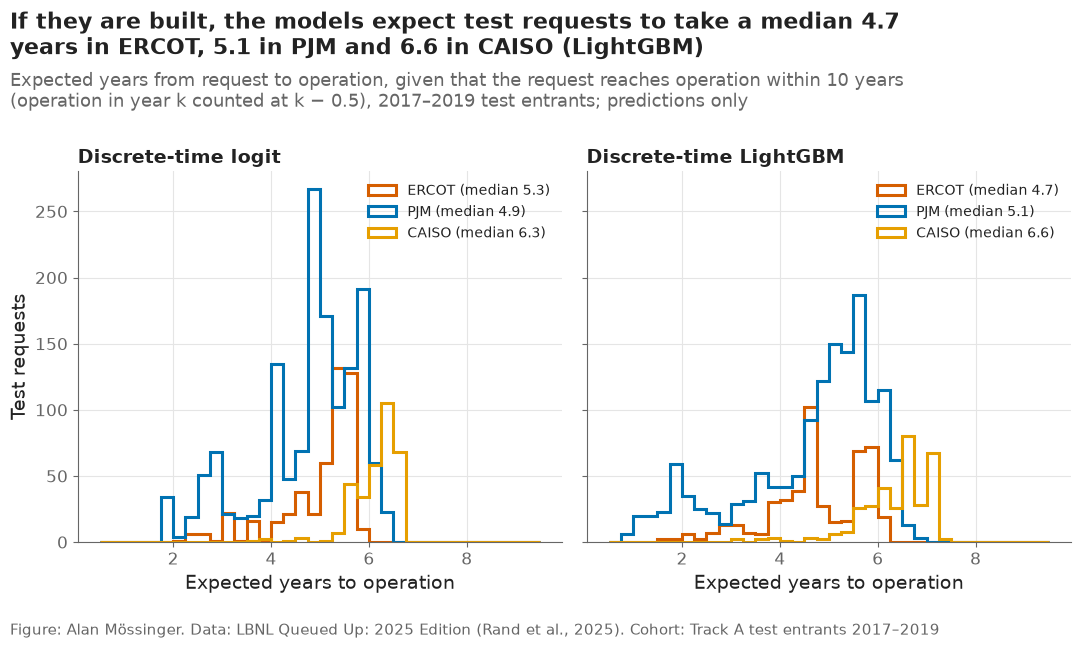

,dt_logit_expected_years,dt_lgbm_expected_years
region,,
CAISO,6.34,6.55
ERCOT,5.32,4.69
PJM,4.92,5.08


In [36]:
test_once = predictions[(predictions["split"] == "test") & (predictions["horizon"] == HORIZONS[0])]
fig, axes = plt.subplots(1, 2, sharey=True)
bins = np.linspace(0.5, 9.5, 37)
for ax, model in zip(axes, ["dt_logit", "dt_lgbm"]):
    for region in TRACK_A:
        values = test_once.loc[test_once["region"] == region, f"{model}_expected_years"]
        ax.hist(values, bins=bins, histtype="step", linewidth=2.2, color=plots.region_color(region),
                label=f"{region} (median {values.median():.1f})")
    ax.set_title(MODEL_LABELS[model])
    ax.set_xlabel("Expected years to operation")
    ax.legend(loc="upper right", fontsize=10)
axes[0].set_ylabel("Test requests")
medians = test_once.groupby("region")[["dt_logit_expected_years", "dt_lgbm_expected_years"]].median()
plots.finish(fig,
             f"If they are built, the models expect test requests to take a median {medians.loc['ERCOT', 'dt_lgbm_expected_years']:.1f} "
             f"years in ERCOT, {medians.loc['PJM', 'dt_lgbm_expected_years']:.1f} in PJM and "
             f"{medians.loc['CAISO', 'dt_lgbm_expected_years']:.1f} in CAISO (LightGBM)",
             "Expected years from request to operation, given that the request reaches operation within 10 years (operation in "
             "year k counted at k − 0.5), 2017–2019 test entrants; predictions only",
             "Track A test entrants 2017–2019")
save(fig, "06_17_expected_time", "Distribution of the expected time to operation (among requests built within 10 years) for the test entrants.")
plt.show()
medians.round(2)

**Reading this.** Predictions for all 2,841 validation and test requests are in `data/processed/predictions_trackA.parquet` (8,523 rows, 0.32 MB) together with notebook 05's baseline and Cox values. On the test entrants the mean 5-year predictions of the four models are close in ERCOT (17.6% LightGBM, 16.4% logit, 15.3% Cox, 18.3% baseline) but differ in PJM (14.5%, 11.2%, 11.4%, 15.9%) — the logit and Cox, both linear in request year, project PJM's declining trend further than LightGBM, which cannot extrapolate. Within a region the discrete-time models spread requests widely (middle 80% of LightGBM's 5-year values: 9.6–34.5% in ERCOT, 6.2–25.6% in PJM, 1.5–5.3% in CAISO) where the baseline has only 4, 6 and 7 distinct values. LightGBM's ranking differs from Cox's (Spearman 0.65 in ERCOT, 0.50 in PJM, 0.81 in CAISO) while the logit's barely does (0.98, 0.80, 0.95), so LightGBM is the model that could change a developer's ordering of projects — whether for the better is notebook 08's question. If they are built, test requests are expected to take a median 4.7 years in ERCOT, 5.1 in PJM and 6.6 in CAISO (LightGBM; the logit gives 5.3, 4.9 and 6.3).

## 11. Checks

In [37]:
allowed = {"year_in_queue", "region", "tech", "size_regime", "service", "hybrid", "log_mw", "q_year",
           "log_congestion_gw", "congestion_rank", "state_operation", "state_withdrawal"}
lgbm_columns = set(discrete_time.lgbm_design(final_enc.iloc[:5]).columns)
cif_cols = [h for h in HORIZONS]
cif_ok = all(((p[cif_cols].diff(axis=1).iloc[:, 1:] >= -1e-12).all().all()
              and p[cif_cols].ge(0).all().all()
              and (p[HORIZONS[-1]] + p[f"withdrawal_{HORIZONS[-1]}"] <= 1 + 1e-9).all())
             for p in target_pred.values())
runtime = time.time() - START
checks = pd.DataFrame([
    ("predictions for every validation and test request at 3/5/7 years, all four models",
     len(predictions) == len(targets) * len(HORIZONS)
     and bool(predictions[["baseline", "cox", "dt_logit", "dt_lgbm"]].notna().all().all())),
    ("P(operation by t) within [0, 1], rising with t, operation + withdrawal ≤ 1", bool(cif_ok)),
    ("grouped folds: no project in both parts of a fold", overlap == 0),
    ("features are entry-time only (plus year in queue and yearly congestion)", lgbm_columns == allowed),
    ("logit: mean predicted P(operation by 3/5/7 yr) inside the Aalen–Johansen band in every region (ERCOT: 2016 entrants)",
     bool(counted.loc[counted["model"] == "dt_logit", "inside"].all())),
    ("LightGBM: mean predicted P(operation by 3/5/7 yr) inside the Aalen–Johansen band in every region (ERCOT: 2016 entrants)",
     bool(counted.loc[counted["model"] == "dt_lgbm", "inside"].all())),
    ("notebook runs in under 10 minutes", runtime < 600),
], columns=["check", "passed"])
checks["result"] = np.where(checks["passed"], "PASS", "FAIL")
checks.to_csv(paths.RESULTS / "dt_checks.csv", index=False)
print(f"run time: {runtime / 60:.1f} minutes")
checks[["check", "result"]]

run time: 4.0 minutes


,check,result
0,predictions for every validation and test requ...,PASS
1,"P(operation by t) within [0, 1], rising with t...",PASS
2,grouped folds: no project in both parts of a fold,PASS
3,features are entry-time only (plus year in que...,PASS
4,logit: mean predicted P(operation by 3/5/7 yr)...,PASS
5,LightGBM: mean predicted P(operation by 3/5/7 ...,PASS
6,notebook runs in under 10 minutes,PASS


**Reading this.** All seven checks pass: complete predictions, valid probabilities, grouped folds without leakage, entry-time features only, the band check for both models (PJM and CAISO on the entrants to 2016, ERCOT on its 2016 entrants, decision #28) and a run time under 10 minutes (3–5 minutes on this laptop, depending on load). `pytest` runs the same band check in `test_model_cif_inside_aj_bands`.

## Takeaways — Part B

- The discrete-time models reproduce the observed incidence in PJM and CAISO at 3, 5 and 7 years and, on the 2016 cohort, are closer to what happened than the baseline and Cox (1.8 and 1.7 points mean error, against 2.6 and 3.9).
- ERCOT is checked on its 2016 entrants, where both models are inside the band (decision #28). Over all ERCOT entrants to 2016 they fall below it (5 of 6 values): earlier entrants completed fast in years delayed entry hides from the models — a limitation to state in the report.
- Effects change over the wait: gas is 5.48× solar's odds early and 2.04× later; very large requests 0.06× early and 0.51× later; CAISO's disadvantage is all in years 1–3.
- Grouped cross-validation rewarded ever larger trees that did worse on the later 2016 cohort (Spearman −0.65 between the two rankings); LightGBM was chosen on the 2016 cohort (8 leaves, 331 rounds; decision #27).
- Freezing congestion at entry costs nothing measurable on the 2016 cohort, although queues doubled within seven years of entry.

**What goes to the report:** 06_13 (band check) with 06_14 as the ERCOT explanation in the limitations; one sentence and 06_12 on how technology effects fade over the wait; the CV-versus-forward-validation finding (06_06) in the method section; predictions feed F4/F5 in notebook 08.

# Part C — The all-regions model (Track B): will a request ever be built? (was notebook 07)

This notebook fits a logistic regression and a LightGBM classifier of
P(built) for resolved requests from all nine regions, calibrates them with
isotonic regression on the 2016 cohort, checks them region by region and with
each region held out, and writes predictions for the 2016 and 2017 cohorts.
The 2017 cohort is the test set: its outcomes are not looked at here; scoring
is notebook 08's job, after its success criteria are written down.

## Setup

Track B helpers are in `src/track_b.py`: `encode_state` (state rate inside
the training rows only), `logit_design` / `lgbm_design`, `fit_lgbm`,
`base_rates` (the region × technology benchmark), `technology_rates` (the
benchmark for a region the model has not seen), `isotonic` (isotonic
regression on bins of at least 50 requests, decision #30) /
`cross_fit_isotonic` and `wilson` (interval for a share). The logistic fit
is `discrete_time.fit_logit`.

**Split and calibration.** Tuning uses entrants up to 2015 (five-fold
cross-validation) and the 2016 cohort (decision #27); the final models are
the fits on entrants up to 2015, with an isotonic map fitted on the 2016
cohort, so that the calibration step is fitted on requests the models have
not seen. The 2017 cohort — the last one Track B can use — is predicted and
left for notebook 08 (decision #29).

In [38]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append(str(Path.cwd().resolve().parent))  # notebooks run from notebooks/; src/ is one level up
from src import config, discrete_time, paths, plots, track_b

paths.ensure_dirs()
plots.set_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

NOTEBOOK = "04_forecast_queue"
TRACK_A = config.TRACK_A_REGIONS


def save(fig, name, caption):
    """Save a figure of this notebook under figures/04_forecast_queue/ with its caption stub."""
    return plots.save_fig(fig, name, caption, NOTEBOOK, folder=NOTEBOOK)


def pct(x, digits=1):
    """Format a share as a percentage string."""
    return f"{100 * x:.{digits}f}%"

import time
import warnings

from sklearn.metrics import brier_score_loss, log_loss, roc_auc_score
from sklearn.model_selection import StratifiedKFold

warnings.filterwarnings("ignore", category=FutureWarning)
START = time.time()
REGIONS = config.ALL_REGIONS
LOGIT_C = [0.01, 0.03, 0.1, 0.3, 1.0, 3.0]
LGBM_GRID = [{"num_leaves": leaves, "min_data_in_leaf": min_leaf} for leaves in [2, 4, 8, 16, 32, 64] for min_leaf in [20, 50, 100]]
ROUNDS = 800  # LightGBM rounds recorded in each fold and on 2016 (learning rate 0.05)
N_BOOT = 200  # bootstrap resamples for intervals on metrics and odds ratios
MODEL_LABELS = {"baseline": "Base rate (region × technology)", "logit": "Logit", "lgbm": "LightGBM",
                "logit_cal": "Logit, calibrated", "lgbm_cal": "LightGBM, calibrated"}
MODEL_COLORS = {"baseline": "#999999", "logit": "#009E73", "lgbm": "#CC79A7", "logit_cal": "#009E73", "lgbm_cal": "#CC79A7"}


def region_color(region):
    """Track A regions keep their colors; the other six are grey."""
    return plots.region_color(region)


def auc_brier(y, p):
    """AUC and Brier score of one set of predictions."""
    return roc_auc_score(y, p), brier_score_loss(y, p)


def bootstrap_metrics(y, preds, n_boot=N_BOOT, seed=7):
    """Point estimate and 95% percentile interval of AUC and Brier for each model, same resamples for all."""
    y = np.asarray(y)
    rng = np.random.default_rng(seed)
    draws = {m: [] for m in preds}
    for _ in range(n_boot):
        idx = rng.integers(0, len(y), len(y))
        if y[idx].min() == y[idx].max():
            continue
        for m, p in preds.items():
            draws[m].append(auc_brier(y[idx], np.asarray(p)[idx]))
    rows = []
    for m, p in preds.items():
        auc, brier = auc_brier(y, p)
        d = np.array(draws[m])
        rows.append({"model": m, "auc": auc, "auc_low": np.quantile(d[:, 0], 0.025), "auc_high": np.quantile(d[:, 0], 0.975),
                     "brier": brier, "brier_low": np.quantile(d[:, 1], 0.025), "brier_high": np.quantile(d[:, 1], 0.975)})
    return pd.DataFrame(rows)

## 1. The sample: resolved requests, and what that leaves out

Track B keeps requests that entered up to 2017 and were either built or
withdrawn by the end of 2024. The table counts them by region and split and
gives the share built in the training and validation cohorts (with 95%
Wilson intervals). The test cohort's share is not shown.

tuning 11,644 | validation 1,446 | test 1,534 resolved requests


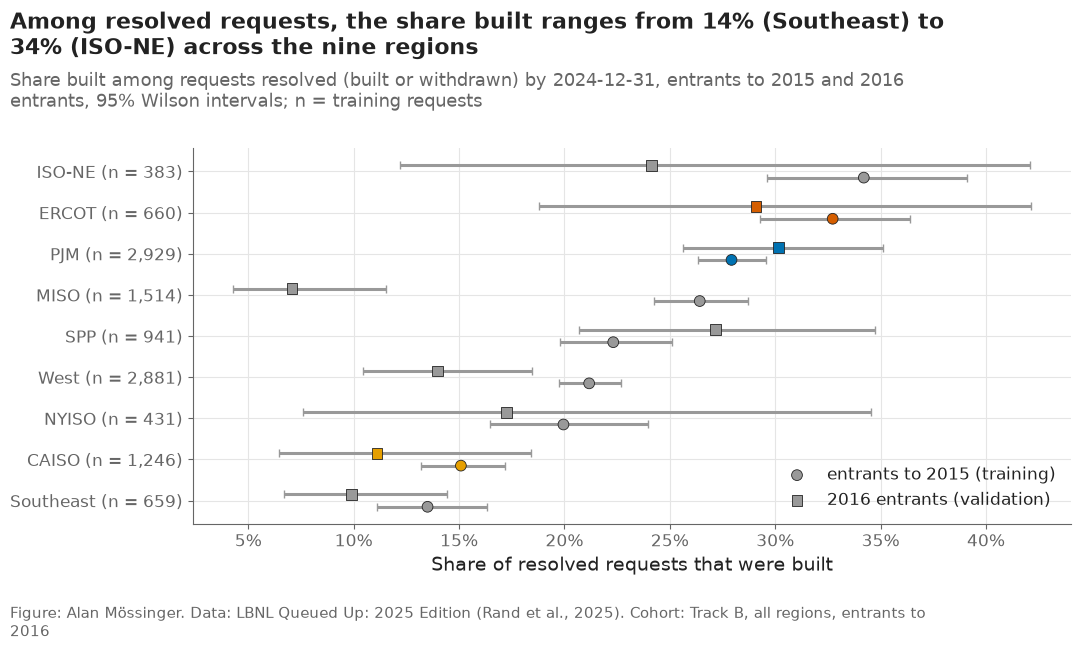

split,test,train,validation,built_train,built_validation
region,,,,,
ERCOT,87,660,55,0.327,0.291
PJM,303,2929,358,0.279,0.302
CAISO,74,1246,108,0.151,0.111
MISO,155,1514,198,0.264,0.071
SPP,167,941,151,0.223,0.272
NYISO,67,431,29,0.200,0.172
ISO-NE,51,383,29,0.342,0.241
West,338,2881,286,0.212,0.140
Southeast,292,659,232,0.135,0.099


In [39]:
requests_b = pd.read_parquet(paths.DATA_INTERIM / "trackB.parquet")
requests_b["tech"] = requests_b["type_clean"].map(plots.tech_group)
tune = requests_b[requests_b["split"] == "train"]
valid = requests_b[requests_b["split"] == "validation"]
test = requests_b[requests_b["split"] == "test"]
print(f"tuning {len(tune):,} | validation {len(valid):,} | test {len(test):,} resolved requests")

rows = []
for region in REGIONS:
    for split, part in [("train", tune), ("validation", valid)]:
        part = part[part["region"] == region]
        low, high = track_b.wilson(part["built"].sum(), len(part)) if len(part) else (np.nan, np.nan)
        rows.append({"region": region, "split": split, "n": len(part), "built_share": part["built"].mean(),
                     "low": low, "high": high})
    rows.append({"region": region, "split": "test", "n": int((test["region"] == region).sum())})
samples = pd.DataFrame(rows)
samples.to_csv(paths.RESULTS / "trackB_samples.csv", index=False)

fig, ax = plt.subplots()
order = samples[samples["split"] == "train"].sort_values("built_share")["region"].tolist()
for offset, split, marker in [(-0.15, "train", "o"), (0.15, "validation", "s")]:
    part = samples[samples["split"] == split].set_index("region").loc[order]
    y = np.arange(len(order)) + offset
    ax.errorbar(part["built_share"], y, xerr=[part["built_share"] - part["low"], part["high"] - part["built_share"]],
                fmt="none", color="#999999", capsize=3)
    ax.scatter(part["built_share"], y, marker=marker, s=60, zorder=3,
               color=[region_color(r) for r in order], edgecolors=plots.INK, linewidths=0.6,
               label="entrants to 2015 (training)" if split == "train" else "2016 entrants (validation)")
ax.set_yticks(np.arange(len(order)), [f"{r} (n = {samples[(samples['region'] == r) & (samples['split'] == 'train')]['n'].iloc[0]:,})"
                                      for r in order])
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.set_xlabel("Share of resolved requests that were built")
ax.legend(loc="lower right")
train_rates = samples[samples["split"] == "train"].set_index("region")["built_share"]
plots.finish(fig,
             f"Among resolved requests, the share built ranges from {train_rates.min():.0%} ({train_rates.idxmin()}) to "
             f"{train_rates.max():.0%} ({train_rates.idxmax()}) across the nine regions",
             "Share built among requests resolved (built or withdrawn) by 2024-12-31, entrants to 2015 and 2016 entrants, "
             "95% Wilson intervals; n = training requests",
             "Track B, all regions, entrants to 2016")
save(fig, "07_01_built_share_by_region", "Share built among resolved requests by region, training and validation cohorts.")
plt.show()
samples.pivot(index="region", columns="split", values="n").reindex(REGIONS).join(
    samples[samples["split"] != "test"].pivot(index="region", columns="split", values="built_share").add_prefix("built_")).round(3)

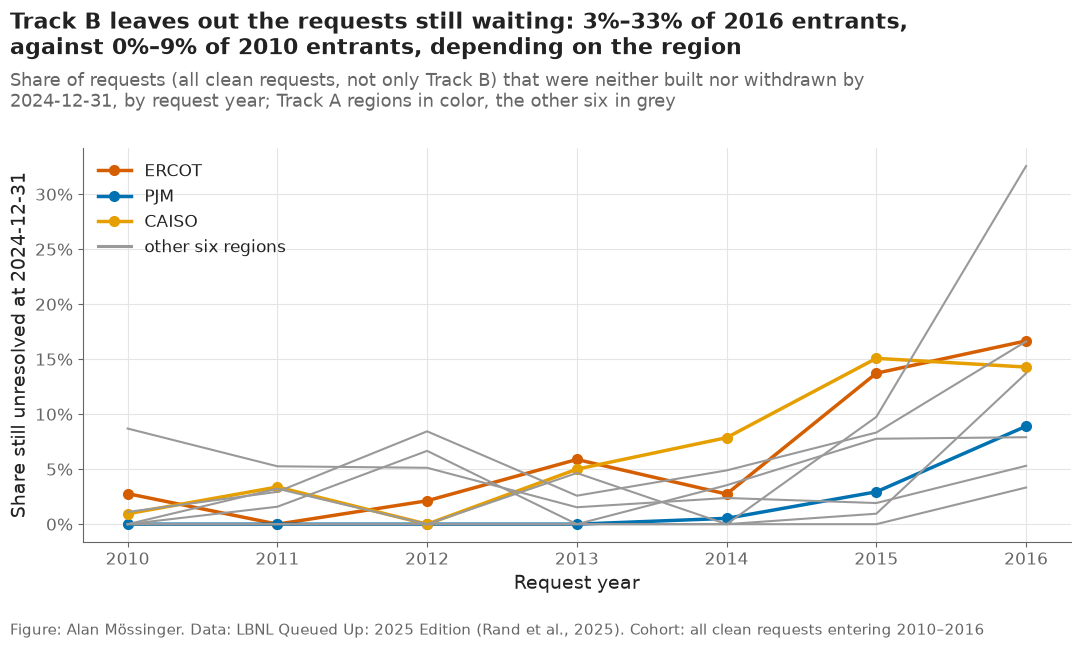

region,ERCOT,PJM,CAISO,MISO,SPP,NYISO,ISO-NE,West,Southeast
q_year,,,,,,,,,
2010,0.028,0.000,0.009,0.000,0.000,0.000,0.000,0.011,0.087
2011,0.000,0.000,0.034,0.016,0.032,0.000,0.000,0.029,0.053
2012,0.021,0.000,0.000,0.067,0.000,0.000,0.000,0.084,0.051
2013,0.059,0.000,0.050,0.000,0.047,0.000,0.000,0.026,0.015
2014,0.027,0.005,0.079,0.035,0.000,0.000,0.000,0.049,0.024
2015,0.137,0.029,0.151,0.078,0.010,0.098,0.000,0.083,0.019
2016,0.167,0.089,0.143,0.079,0.137,0.326,0.033,0.166,0.053


In [40]:
events_all = pd.read_parquet(paths.DATA_INTERIM / "queue_events.parquet")
recent = events_all[events_all["q_year"].between(2010, config.VALIDATION_YEAR)]
unresolved = recent.assign(unresolved=~recent["q_status"].isin(["operational", "withdrawn"])).groupby(
    ["q_year", "region"])["unresolved"].mean().unstack().reindex(columns=REGIONS)
fig, ax = plt.subplots()
for region in REGIONS:
    ax.plot(unresolved.index, unresolved[region], color=region_color(region),
            linewidth=2.5 if region in config.TRACK_A_REGIONS else 1.5,
            marker="o" if region in config.TRACK_A_REGIONS else None,
            label=region if region in config.TRACK_A_REGIONS else None)
ax.plot([], [], color=config.OTHER_REGION_COLOR, label="other six regions")
ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
ax.set_xlabel("Request year")
ax.set_ylabel("Share still unresolved at 2024-12-31")
ax.legend(loc="upper left")
plots.finish(fig,
             f"Track B leaves out the requests still waiting: {unresolved.loc[config.VALIDATION_YEAR].min():.0%}–"
             f"{unresolved.loc[config.VALIDATION_YEAR].max():.0%} of 2016 entrants, against "
             f"{unresolved.loc[2010].min():.0%}–{unresolved.loc[2010].max():.0%} of 2010 entrants, depending on the region",
             "Share of requests (all clean requests, not only Track B) that were neither built nor withdrawn by 2024-12-31, "
             "by request year; Track A regions in color, the other six in grey",
             "all clean requests entering 2010–2016")
save(fig, "07_02_unresolved_share", "Share of requests still unresolved at the end of 2024, by request year and region.")
plt.show()
unresolved.round(3)

**Reading this.** Track B has 11,644 resolved requests for tuning (entrants to 2015), 1,446 for validation (2016) and 1,534 for testing (2017). Among the training requests the share built runs from 13.5% (Southeast) and 15.1% (CAISO) to 32.7% (ERCOT) and 34.2% (ISO-NE). The 2016 cohort is not a copy of the past: MISO's 2016 entrants were built 7.1% of the time against 26.4% for its earlier entrants, and West's 14.0% against 21.2%. The second chart shows what "resolved" leaves out: 3.3% (ISO-NE) to 32.6% (NYISO) of 2016 entrants were still waiting at the end of 2024, against at most 8.7% of 2010 entrants. Those waiting requests are the slow ones, so the later the cohort, the more Track B's built share reflects requests that resolved quickly — a selection that grows into the 2017 test cohort and that notebook 08 must state when it reports Track B results.

## 2. The benchmark: region × technology base rates

The share built among training requests of the same region and technology
(cells with fewer than 50 requests use the region's share). This is the
number an analyst would quote today, and the one the models must beat.

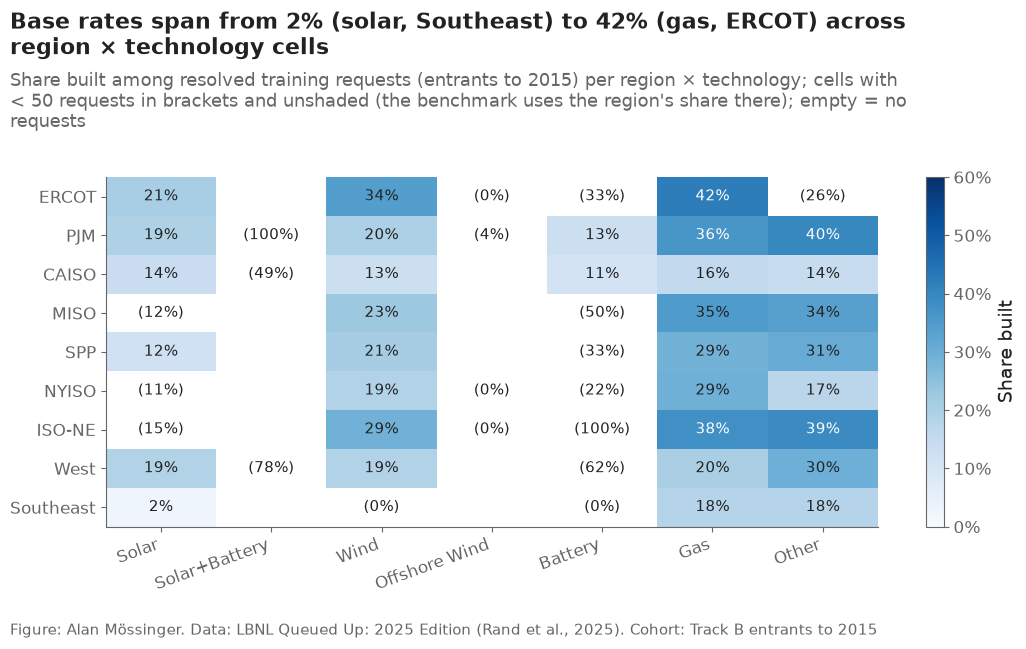

tech,Solar,Solar+Battery,Wind,Offshore Wind,Battery,Gas,Other
region,,,,,,,
ERCOT,0.208,NaN,0.341,0.000,0.333,0.420,0.262
PJM,0.193,1.000,0.198,0.043,0.130,0.361,0.398
CAISO,0.138,0.488,0.129,NaN,0.109,0.157,0.144
MISO,0.122,NaN,0.227,NaN,0.500,0.349,0.337
SPP,0.120,NaN,0.210,NaN,0.333,0.288,0.306
NYISO,0.107,NaN,0.189,0.000,0.222,0.295,0.170
ISO-NE,0.154,NaN,0.288,0.000,1.000,0.379,0.390
West,0.189,0.778,0.185,NaN,0.625,0.203,0.295
Southeast,0.024,NaN,0.000,NaN,0.000,0.179,0.182


In [41]:
cells = tune.groupby(["region", "tech"])["built"].agg(["mean", "size"]).reset_index()
cells.columns = ["region", "tech", "built_share", "n"]
cells.to_csv(paths.RESULTS / "trackB_base_rates.csv", index=False)
grid = cells.pivot(index="region", columns="tech", values="built_share").reindex(index=REGIONS, columns=discrete_time.TECH_LEVELS)
counts = cells.pivot(index="region", columns="tech", values="n").reindex(index=REGIONS, columns=discrete_time.TECH_LEVELS)
fig, ax = plt.subplots()
shown = grid.where(counts >= 50)
image = ax.imshow(shown.to_numpy(dtype=float), cmap="Blues", vmin=0, vmax=0.6, aspect="auto")
for i in range(len(REGIONS)):
    for j in range(len(discrete_time.TECH_LEVELS)):
        value, n = grid.iloc[i, j], counts.iloc[i, j]
        if pd.notna(value):
            text = f"{value:.0%}" if n >= 50 else f"({value:.0%})"
            ax.text(j, i, text, ha="center", va="center", fontsize=10.5,
                    color="white" if (n >= 50 and value > 0.35) else plots.INK)
ax.set_xticks(range(len(discrete_time.TECH_LEVELS)), discrete_time.TECH_LEVELS, rotation=20, ha="right")
ax.set_yticks(range(len(REGIONS)), REGIONS)
ax.grid(False)
fig.colorbar(image, ax=ax, label="Share built", format=lambda x, _: f"{x:.0%}")
best = cells[cells["n"] >= 50].sort_values("built_share")
plots.finish(fig,
             f"Base rates span from {best['built_share'].iloc[0]:.0%} ({best['tech'].iloc[0].lower()}, {best['region'].iloc[0]}) "
             f"to {best['built_share'].iloc[-1]:.0%} ({best['tech'].iloc[-1].lower()}, {best['region'].iloc[-1]}) across "
             "region × technology cells",
             "Share built among resolved training requests (entrants to 2015) per region × technology; cells with < 50 requests "
             "in brackets and unshaded (the benchmark uses the region's share there); empty = no requests",
             "Track B entrants to 2015")
save(fig, "07_03_base_rates", "Region × technology share built among resolved training requests (the Track B benchmark).")
plt.show()
grid.round(3)

**Reading this.** The benchmark already knows a lot: gas is the most likely technology to be built in most regions (42% in ERCOT, 38% in ISO-NE, 36% in PJM, 35% in MISO) and solar the least (2% in the Southeast, 12% in MISO and SPP, 14% in CAISO). Many cells are small — batteries, solar+battery and offshore wind have fewer than 50 resolved training requests in most regions — and fall back to the region's share. A model earns its place only if it beats these cell averages.

## 3. Tuning

Five stratified folds on the tuning requests; inside each fold the state is
encoded on the fitting part only. The logistic regression's ridge strength
is chosen by mean cross-validated log loss. For LightGBM, every tree
setting is also run on the 2016 cohort, and — as in notebook 06 (decision
#27) — the setting and round count with the lowest 2016 log loss are kept,
because the 2016 cohort lies ahead in time of every fitting row.

no-information log loss 0.5464; logit C = 0.1, CV log loss 0.5032
LightGBM chosen on 2016: {'num_leaves': 4, 'min_data_in_leaf': 20}, 243 rounds, 2016 log loss 0.4540; CV's choice 64/20 scores 0.4852 on 2016
Spearman correlation of the 18 settings' CV and 2016 log losses: -0.85


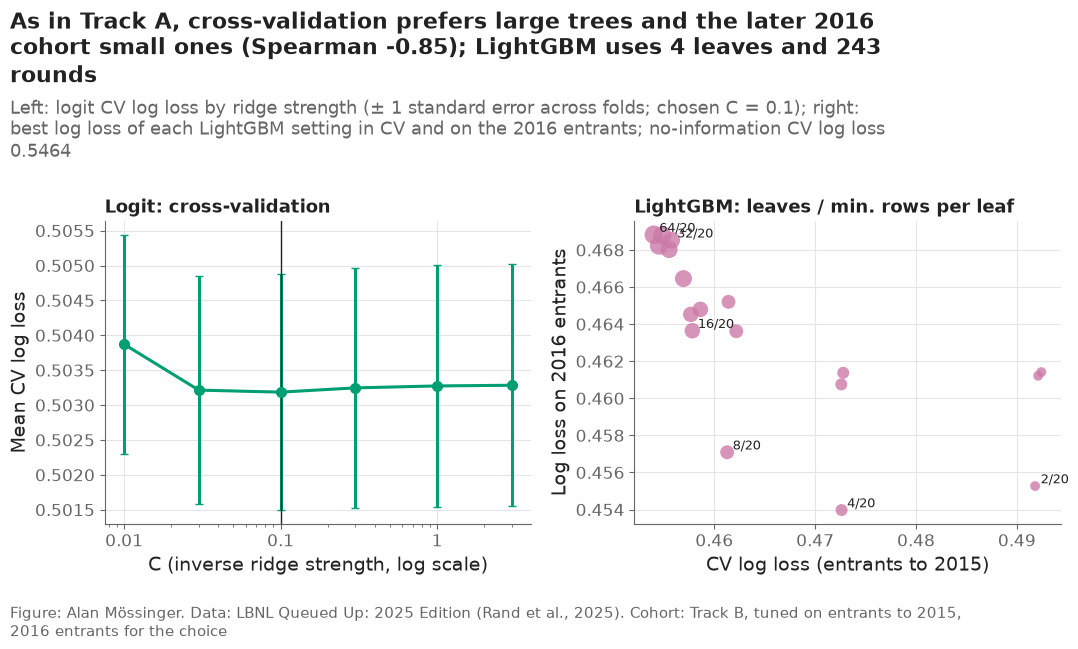

,num_leaves,min_data_in_leaf,cv_rounds,cv_log_loss,valid_rounds,valid_log_loss
3,4,20,799,0.4726,243,0.4540
0,2,20,799,0.4918,524,0.4553
6,8,20,800,0.4613,217,0.4571
5,4,100,800,0.4726,53,0.4608
1,2,50,799,0.4921,792,0.4612
4,4,50,800,0.4728,53,0.4614
2,2,100,799,0.4924,123,0.4614
7,8,50,766,0.4622,64,0.4636
9,16,20,536,0.4578,52,0.4636
11,16,100,567,0.4577,36,0.4645


In [42]:
folds = list(StratifiedKFold(5, shuffle=True, random_state=0).split(tune, tune["built"]))
fold_data = [track_b.encode_state(tune.iloc[fit_idx], [tune.iloc[held_idx]]) for fit_idx, held_idx in folds]
null_loss = np.mean([log_loss(held["built"], np.full(len(held), fit["built"].mean())) for fit, held in fold_data])
logit_rows = []
for C in LOGIT_C:
    for i, (fit, held) in enumerate(fold_data):
        model = discrete_time.fit_logit(track_b.logit_design(fit), fit["built"], C)
        logit_rows.append({"C": C, "fold": i, "log_loss": log_loss(held["built"], model.predict_proba(track_b.logit_design(held))[:, 1])})
logit_cv = pd.DataFrame(logit_rows)
logit_cv.to_csv(paths.RESULTS / "trackB_cv_logit.csv", index=False)
logit_mean = logit_cv.groupby("C")["log_loss"].agg(["mean", "std"])
LOGIT_C_BEST = float(logit_mean["mean"].idxmin())

tune_enc, valid_enc, test_enc = track_b.encode_state(tune, [valid, test])
cv_curves, valid_curves = {}, {}
for params in LGBM_GRID:
    key = (params["num_leaves"], params["min_data_in_leaf"])
    fold_curves = []
    for fit, held in fold_data:
        record = {}
        track_b.fit_lgbm(track_b.lgbm_design(fit), fit["built"], params, ROUNDS,
                         valid=(track_b.lgbm_design(held), held["built"]), record=record)
        fold_curves.append(record["valid"]["binary_logloss"])
    cv_curves[key] = np.mean(fold_curves, axis=0)
    record = {}
    track_b.fit_lgbm(track_b.lgbm_design(tune_enc), tune_enc["built"], params, ROUNDS,
                     valid=(track_b.lgbm_design(valid_enc), valid_enc["built"]), record=record)
    valid_curves[key] = np.array(record["valid"]["binary_logloss"])
lgbm_cv = pd.DataFrame([{"num_leaves": k[0], "min_data_in_leaf": k[1],
                         "cv_rounds": int(cv_curves[k].argmin() + 1), "cv_log_loss": float(cv_curves[k].min()),
                         "valid_rounds": int(valid_curves[k].argmin() + 1), "valid_log_loss": float(valid_curves[k].min())}
                        for k in cv_curves])
lgbm_cv.to_csv(paths.RESULTS / "trackB_cv_lgbm.csv", index=False)
chosen = lgbm_cv.loc[lgbm_cv["valid_log_loss"].idxmin()]
cv_best = lgbm_cv.loc[lgbm_cv["cv_log_loss"].idxmin()]
LGBM_PARAMS = {"num_leaves": int(chosen["num_leaves"]), "min_data_in_leaf": int(chosen["min_data_in_leaf"])}
N_ROUNDS = int(chosen["valid_rounds"])
rank_agreement = lgbm_cv[["cv_log_loss", "valid_log_loss"]].corr(method="spearman").iloc[0, 1]
print(f"no-information log loss {null_loss:.4f}; logit C = {LOGIT_C_BEST:g}, CV log loss {logit_mean['mean'].min():.4f}")
print(f"LightGBM chosen on 2016: {LGBM_PARAMS}, {N_ROUNDS} rounds, 2016 log loss {chosen['valid_log_loss']:.4f}; "
      f"CV's choice {int(cv_best['num_leaves'])}/{int(cv_best['min_data_in_leaf'])} scores "
      f"{valid_curves[(int(cv_best['num_leaves']), int(cv_best['min_data_in_leaf']))][int(cv_best['cv_rounds']) - 1]:.4f} on 2016")
print(f"Spearman correlation of the {len(lgbm_cv)} settings' CV and 2016 log losses: {rank_agreement:.2f}")
tuning = {"logit_C": LOGIT_C_BEST, "logit_cv_log_loss": float(logit_mean["mean"].min()), "lgbm": {**LGBM_PARAMS, "rounds": N_ROUNDS},
          "lgbm_valid_log_loss": float(chosen["valid_log_loss"]), "spearman_cv_vs_2016": float(rank_agreement)}
(paths.RESULTS / "trackB_tuning.json").write_text(json.dumps(tuning, indent=2), encoding="utf-8")

fig, axes = plt.subplots(1, 2)
ax = axes[0]
ax.errorbar(logit_mean.index, logit_mean["mean"], yerr=logit_mean["std"] / np.sqrt(len(folds)), color=MODEL_COLORS["logit"],
            marker="o", capsize=3)
ax.axvline(LOGIT_C_BEST, color=plots.INK, linewidth=1)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(lambda x, _: f"{x:g}")
ax.set_xlabel("C (inverse ridge strength, log scale)")
ax.set_ylabel("Mean CV log loss")
ax.set_title("Logit: cross-validation", fontsize=13)
ax = axes[1]
ax.scatter(lgbm_cv["cv_log_loss"], lgbm_cv["valid_log_loss"], s=25 * np.log2(lgbm_cv["num_leaves"] * 2),
           color=MODEL_COLORS["lgbm"], alpha=0.8, edgecolors="white")
for r in lgbm_cv.itertuples():
    if r.Index in (chosen.name, cv_best.name) or r.min_data_in_leaf == 20:  # label one row per tree size, plus the two choices
        ax.annotate(f"{r.num_leaves}/{r.min_data_in_leaf}", (r.cv_log_loss, r.valid_log_loss), xytext=(4, 2),
                    textcoords="offset points", fontsize=9)
ax.set_xlabel("CV log loss (entrants to 2015)")
ax.set_ylabel("Log loss on 2016 entrants")
ax.set_title("LightGBM: leaves / min. rows per leaf", fontsize=13)
plots.finish(fig,
             f"As in Track A, cross-validation prefers large trees and the later 2016 cohort small ones (Spearman "
             f"{rank_agreement:.2f}); LightGBM uses {LGBM_PARAMS['num_leaves']} leaves and {N_ROUNDS} rounds",
             f"Left: logit CV log loss by ridge strength (± 1 standard error across folds; chosen C = {LOGIT_C_BEST:g}); right: best "
             f"log loss of each LightGBM setting in CV and on the 2016 entrants; no-information CV log loss {null_loss:.4f}",
             "Track B, tuned on entrants to 2015, 2016 entrants for the choice")
save(fig, "07_04_tuning", "Track B tuning: logit ridge strength and LightGBM settings in cross-validation and on the 2016 cohort.")
plt.show()
lgbm_cv.sort_values("valid_log_loss").round(4)

**Reading this.** The logistic regression is insensitive to its penalty (CV log loss 0.5032–0.5039 across C from 0.01 to 3; no information 0.5464); C = 0.1 is used. LightGBM repeats Track A's pattern: grouped cross-validation favours large trees, while the later 2016 cohort favours small ones (Spearman −0.85 between the 18 settings' two log losses). The setting chosen on 2016, 4 leaves and at least 20 requests per leaf after 243 rounds, scores 0.4540 there, against 0.4852 for the CV's choice of 64 leaves. Four-leaf trees can represent only low-order interactions, so on this sample the boosted model is close to an additive one; the 2-leaf (purely additive) setting scores 0.4553.

## 4. The 2016 cohort: discrimination and calibration

The models fitted on entrants to 2015 score the 2016 cohort. AUC measures
ranking (0.5 = coin flip), Brier the squared error of the probabilities
(lower is better); intervals from 200 bootstrap resamples. The calibrated
versions are scored **cross-fitted**: the isotonic map applied to each half
of the cohort was fitted on the other half, so the calibration step does not
grade itself. The final map (used for the 2017 predictions) is fitted on the
whole cohort.

observed share built, 2016 cohort: 0.184 (n = 1,446)


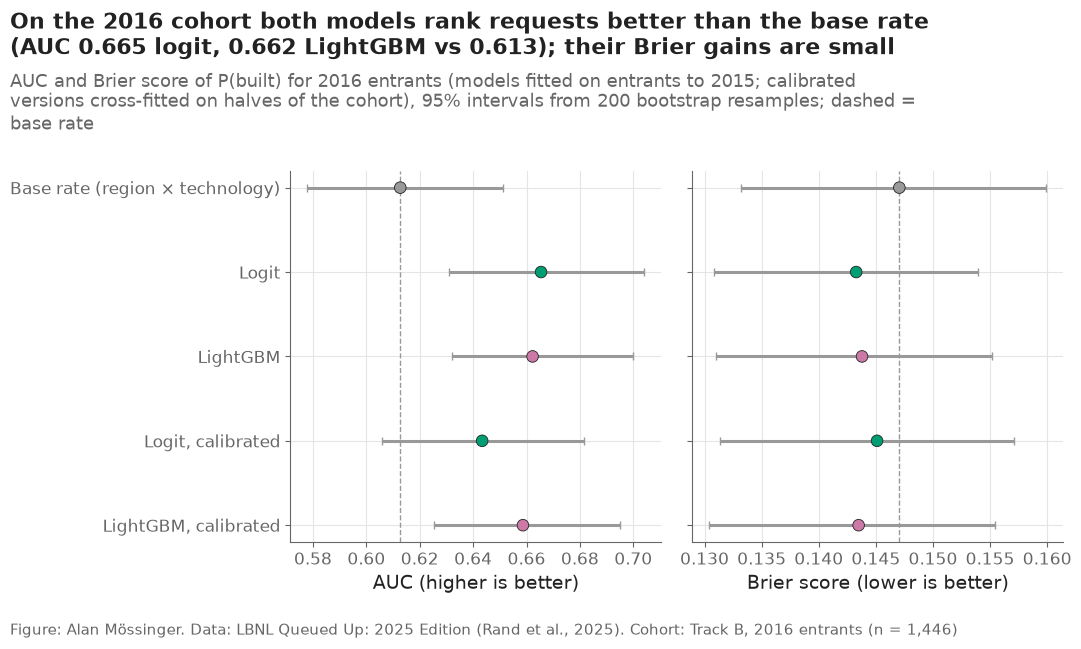

,model,auc,auc_low,auc_high,brier,brier_low,brier_high,mean_predicted
0,baseline,0.6127,0.5778,0.6510,0.1471,0.1332,0.1599,0.1895
1,logit,0.6654,0.6309,0.7041,0.1433,0.1309,0.1540,0.2110
2,lgbm,0.6623,0.6320,0.6998,0.1438,0.1310,0.1551,0.1993
3,logit_cal,0.6434,0.6058,0.6815,0.1451,0.1313,0.1571,0.1829
4,lgbm_cal,0.6586,0.6255,0.6950,0.1435,0.1304,0.1554,0.1828


In [43]:
logit = discrete_time.fit_logit(track_b.logit_design(tune_enc), tune_enc["built"], LOGIT_C_BEST)
lgbm = track_b.fit_lgbm(track_b.lgbm_design(tune_enc), tune_enc["built"], LGBM_PARAMS, N_ROUNDS)
raw_valid = {"logit": logit.predict_proba(track_b.logit_design(valid_enc))[:, 1],
             "lgbm": lgbm.predict(track_b.lgbm_design(valid_enc))}
y_valid = valid["built"].to_numpy()
maps = {m: track_b.isotonic(p, y_valid) for m, p in raw_valid.items()}
valid_preds = {"baseline": track_b.base_rates(tune, valid)["rate"].to_numpy(), **raw_valid,
               **{f"{m}_cal": track_b.cross_fit_isotonic(p, y_valid) for m, p in raw_valid.items()}}
metrics = bootstrap_metrics(y_valid, valid_preds)
metrics["mean_predicted"] = [np.mean(valid_preds[m]) for m in metrics["model"]]
metrics.to_csv(paths.RESULTS / "trackB_validation.csv", index=False)
print(f"observed share built, 2016 cohort: {y_valid.mean():.3f} (n = {len(y_valid):,})")

fig, axes = plt.subplots(1, 2, sharey=True)
for ax, (metric, label) in zip(axes, [("auc", "AUC (higher is better)"), ("brier", "Brier score (lower is better)")]):
    y = np.arange(len(metrics))[::-1]
    ax.errorbar(metrics[metric], y, xerr=[metrics[metric] - metrics[f"{metric}_low"], metrics[f"{metric}_high"] - metrics[metric]],
                fmt="none", color="#999999", capsize=3)
    ax.scatter(metrics[metric], y, s=70, zorder=3, color=[MODEL_COLORS[m] for m in metrics["model"]],
               marker="o", edgecolors=plots.INK, linewidths=0.6)
    ax.axvline(metrics.loc[metrics["model"] == "baseline", metric].iloc[0], color="#999999", linestyle="--", linewidth=1)
    ax.set_xlabel(label)
axes[0].set_yticks(np.arange(len(metrics))[::-1], [MODEL_LABELS[m] for m in metrics["model"]])
m = metrics.set_index("model")
plots.finish(fig,
             f"On the 2016 cohort both models rank requests better than the base rate (AUC {m.loc['logit', 'auc']:.3f} logit, "
             f"{m.loc['lgbm', 'auc']:.3f} LightGBM vs {m.loc['baseline', 'auc']:.3f}); their Brier gains are small",
             "AUC and Brier score of P(built) for 2016 entrants (models fitted on entrants to 2015; calibrated versions "
             "cross-fitted on halves of the cohort), 95% intervals from 200 bootstrap resamples; dashed = base rate",
             f"Track B, {config.VALIDATION_YEAR} entrants (n = {len(y_valid):,})")
save(fig, "07_05_validation_metrics", "AUC and Brier score of the Track B models and the base rate on the 2016 cohort.")
plt.show()
metrics.round(4)

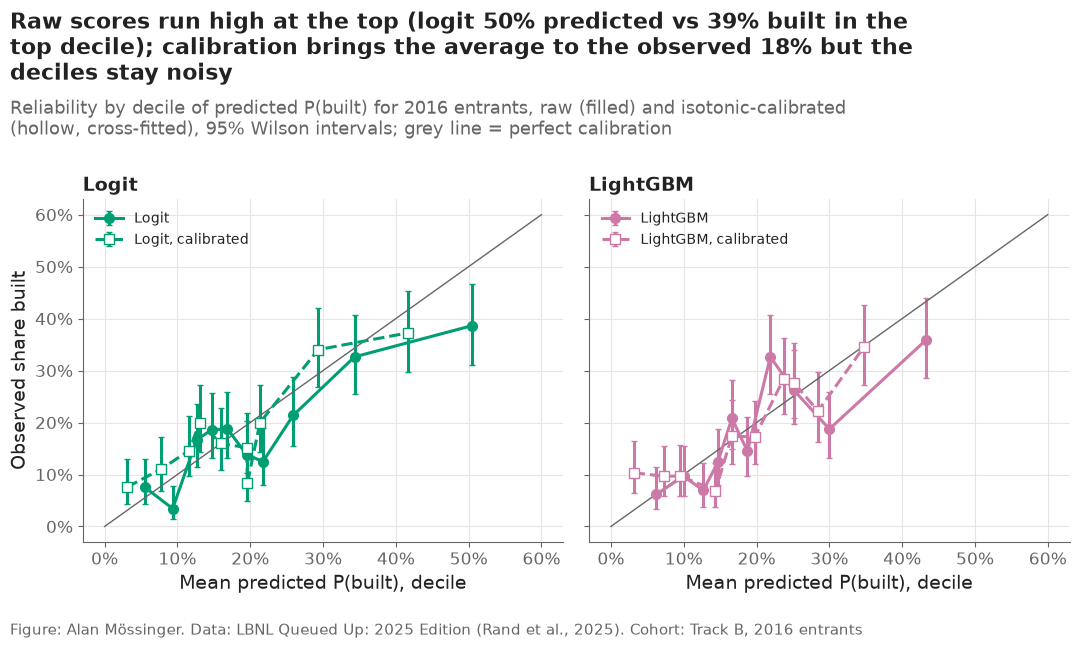

,bin,predicted,observed,n,model
0,0,0.055,0.076,145,logit
1,1,0.093,0.034,145,logit
2,2,0.126,0.167,144,logit
3,3,0.147,0.186,145,logit
4,4,0.169,0.188,144,logit
5,5,0.195,0.138,145,logit
6,6,0.218,0.125,144,logit
7,7,0.259,0.214,145,logit
8,8,0.343,0.326,144,logit
9,9,0.504,0.386,145,logit


In [44]:
deciles = []
fig, axes = plt.subplots(1, 2, sharey=True, sharex=True)
for ax, model in zip(axes, ["logit", "lgbm"]):
    for version, style in [(model, dict(marker="o", linestyle="-")), (f"{model}_cal", dict(marker="s", linestyle="--"))]:
        p = valid_preds[version]
        bins = pd.qcut(pd.Series(p).rank(method="first"), 10, labels=False)  # rank first: tied calibrated values still split into tenths
        table = pd.DataFrame({"p": p, "y": y_valid, "bin": bins}).groupby("bin").agg(predicted=("p", "mean"), observed=("y", "mean"),
                                                                                     n=("y", "size"))
        low, high = track_b.wilson(table["observed"] * table["n"], table["n"])
        ax.errorbar(table["predicted"], table["observed"], yerr=[table["observed"] - low, high - table["observed"]],
                    color=MODEL_COLORS[model], capsize=2, label=MODEL_LABELS[version],
                    markerfacecolor="white" if version.endswith("cal") else MODEL_COLORS[model], **style)
        deciles.append(table.assign(model=version).reset_index())
    ax.plot([0, 0.6], [0, 0.6], color=plots.MUTED, linewidth=1)
    ax.set_title(MODEL_LABELS[model])
    ax.set_xlabel("Mean predicted P(built), decile")
    ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
    ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
    ax.legend(loc="upper left", fontsize=10)
axes[0].set_ylabel("Observed share built")
calibration = pd.concat(deciles, ignore_index=True)
calibration.to_csv(paths.RESULTS / "trackB_calibration.csv", index=False)
top = calibration.groupby("model").apply(lambda t: t.sort_values("predicted").iloc[-1], include_groups=False)
plots.finish(fig,
             f"Raw scores run high at the top (logit {top.loc['logit', 'predicted']:.0%} predicted vs "
             f"{top.loc['logit', 'observed']:.0%} built in the top decile); calibration brings the average to the observed "
             f"{y_valid.mean():.0%} but the deciles stay noisy",
             "Reliability by decile of predicted P(built) for 2016 entrants, raw (filled) and isotonic-calibrated (hollow, "
             "cross-fitted), 95% Wilson intervals; grey line = perfect calibration",
             f"Track B, {config.VALIDATION_YEAR} entrants")
save(fig, "07_06_reliability_2016", "Reliability diagrams of the Track B models on the 2016 cohort, raw and isotonic-calibrated.")
plt.show()
calibration.round(3)

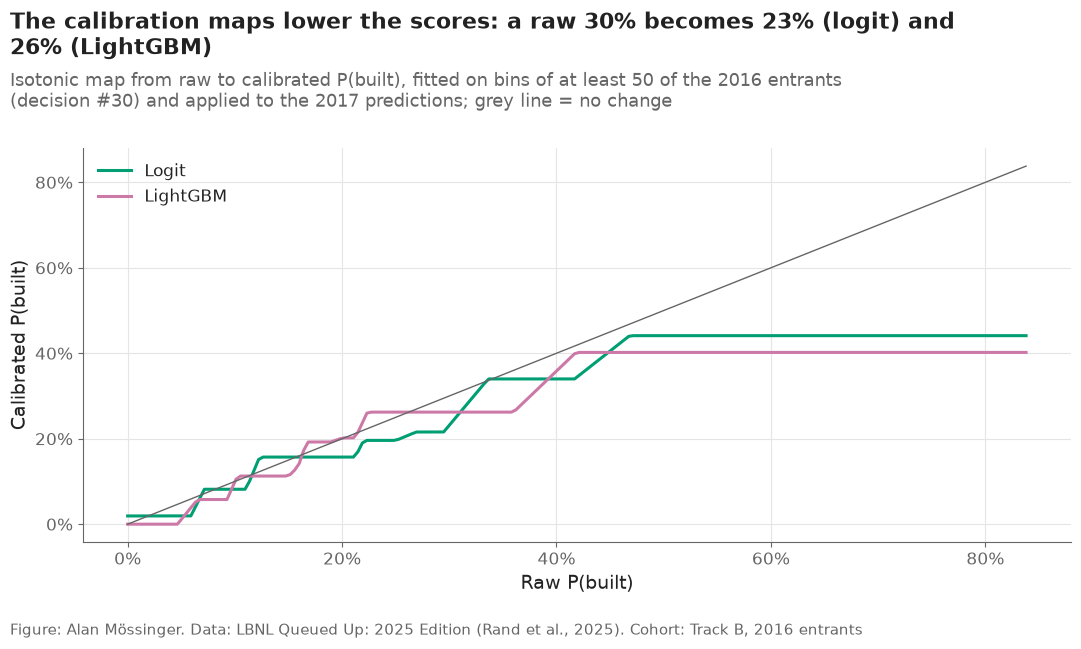

,logit,lgbm
0.1,0.082,0.099
0.2,0.157,0.202
0.3,0.231,0.262
0.4,0.340,0.358
0.5,0.441,0.402


In [45]:
fig, ax = plt.subplots()
grid_p = np.linspace(0, max(valid_preds["logit"].max(), valid_preds["lgbm"].max()), 200)
for model in ["logit", "lgbm"]:
    ax.plot(grid_p, maps[model].predict(grid_p), color=MODEL_COLORS[model], label=MODEL_LABELS[model])
ax.plot([0, grid_p.max()], [0, grid_p.max()], color=plots.MUTED, linewidth=1)
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
ax.set_xlabel("Raw P(built)")
ax.set_ylabel("Calibrated P(built)")
ax.legend(loc="upper left")
at = {m: float(maps[m].predict([0.3])[0]) for m in maps}
plots.finish(fig,
             f"The calibration maps lower the scores: a raw 30% becomes {at['logit']:.0%} (logit) and {at['lgbm']:.0%} (LightGBM)",
             "Isotonic map from raw to calibrated P(built), fitted on bins of at least 50 of the 2016 entrants (decision #30) "
             "and applied to the 2017 predictions; grey line = no change",
             f"Track B, {config.VALIDATION_YEAR} entrants")
save(fig, "07_07_isotonic_maps", "Isotonic calibration maps of the two Track B models, fitted on the 2016 cohort.")
plt.show()
pd.DataFrame({m: maps[m].predict([0.1, 0.2, 0.3, 0.4, 0.5]) for m in maps}, index=[0.1, 0.2, 0.3, 0.4, 0.5]).round(3)

**Reading this.** On the 2016 cohort (18.4% built), both models rank requests better than the region × technology base rate: AUC 0.665 (95% interval 0.631–0.704) for the logit and 0.662 (0.632–0.700) for LightGBM, against 0.613 (0.578–0.651). The Brier scores barely differ (0.1433 and 0.1438 against 0.1471) and their intervals overlap almost entirely, so the models' gain is in ranking, not in the size of their probabilities. The raw scores run high (mean 21.1% for the logit and 19.9% for LightGBM against 18.4% observed; logit's top decile 50.4% predicted vs 38.6% built). Calibration on bins of at least 50 requests, scored cross-fitted, brings the mean to 18.3% for both, but it does not improve the scores overall: the calibrated logit is worse (Brier 0.1451, AUC 0.643) and the calibrated LightGBM about equal (0.1435, AUC 0.659). The maps lower the scores (a raw 30% becomes 23.1% for the logit and 26.2% for LightGBM) and are flat beyond the top bin, so no 2017 request receives more than 44.1% (logit) or 40.2% (LightGBM). Without the bins, isotonic regression had sent LightGBM's map to 100% above a raw score of 0.53 on the strength of nine 2016 requests, a value 29 test requests would have inherited (decision #30). The flat steps have a cost for a developer: calibrated values tie, so they rank requests more coarsely than the raw scores.

## 5. Region by region, and with each region held out

Two questions per region. **Calibration on 2016:** is the calibrated models'
mean P(built) for the region's 2016 entrants inside the 95% Wilson interval
of the share actually built? (Cross-fitted calibrated values, as above.)
**Leave one region out:** refit both models (and their isotonic maps) without
the region, then predict all its entrants to 2016 — the setting of a region
whose history the model has never seen. The benchmark there is the share
built by technology in the other regions. A region "fails" when the mean
prediction falls outside the interval of the observed share; this rule is
written here before the table is computed.

In [46]:
region_rows = []
for region in REGIONS:
    mask = (valid["region"] == region).to_numpy()
    k, n = int(y_valid[mask].sum()), int(mask.sum())
    low, high = track_b.wilson(k, n)
    row = {"region": region, "n_2016": n, "observed_2016": k / n, "low_2016": low, "high_2016": high}
    for model in ["baseline", "logit_cal", "lgbm_cal"]:
        row[f"{model}_2016"] = valid_preds[model][mask].mean()
        row[f"{model}_2016_fails"] = not (low <= row[f"{model}_2016"] <= high)
    region_rows.append(row)
by_region = pd.DataFrame(region_rows).set_index("region")

holdout = pd.concat([tune, valid])
loro_rows = []
for region in REGIONS:
    fit_t, fit_v = tune[tune["region"] != region], valid[valid["region"] != region]
    target = holdout[holdout["region"] == region]
    fit_t_enc, fit_v_enc, target_enc = track_b.encode_state(fit_t, [fit_v, target])
    lo_logit = discrete_time.fit_logit(track_b.logit_design(fit_t_enc), fit_t_enc["built"], LOGIT_C_BEST)
    lo_lgbm = track_b.fit_lgbm(track_b.lgbm_design(fit_t_enc), fit_t_enc["built"], LGBM_PARAMS, N_ROUNDS)
    preds = {}
    for model, fitted, design, predict in [
            ("logit", lo_logit, track_b.logit_design, lambda m, X: m.predict_proba(X)[:, 1]),
            ("lgbm", lo_lgbm, track_b.lgbm_design, lambda m, X: m.predict(X))]:
        cal = track_b.isotonic(predict(fitted, design(fit_v_enc)), fit_v_enc["built"])
        preds[model] = cal.predict(predict(fitted, design(target_enc)))
    preds["tech_rate"] = track_b.technology_rates(pd.concat([fit_t, fit_v]), target).to_numpy()
    y = target["built"].to_numpy()
    low, high = track_b.wilson(y.sum(), len(y))
    row = {"region": region, "n_loro": len(y), "observed_loro": y.mean(), "low_loro": low, "high_loro": high}
    for model, p in preds.items():
        row[f"{model}_loro"] = p.mean()
        row[f"{model}_loro_auc"] = roc_auc_score(y, p)
        row[f"{model}_loro_brier"] = brier_score_loss(y, p)
        row[f"{model}_loro_fails"] = not (low <= p.mean() <= high)
    loro_rows.append(row)
loro = pd.DataFrame(loro_rows).set_index("region")
by_region = by_region.join(loro)
by_region.to_csv(paths.RESULTS / "trackB_by_region.csv")
fails_2016 = [r for r in REGIONS if by_region.loc[r, ["logit_cal_2016_fails", "lgbm_cal_2016_fails"]].any()]
fails_loro = [r for r in REGIONS if by_region.loc[r, ["logit_loro_fails", "lgbm_loro_fails"]].any()]
print("regions where a calibrated model misses the 2016 interval:", fails_2016 or "none")
print("regions where a held-out model misses the observed interval:", fails_loro or "none")
by_region[["n_2016", "observed_2016", "low_2016", "high_2016", "baseline_2016", "logit_cal_2016", "lgbm_cal_2016"]].round(3)

regions where a calibrated model misses the 2016 interval: ['PJM', 'MISO', 'SPP']
regions where a held-out model misses the observed interval: ['ERCOT', 'PJM', 'CAISO', 'MISO', 'SPP', 'NYISO', 'West', 'Southeast']


,n_2016,observed_2016,low_2016,high_2016,baseline_2016,logit_cal_2016,lgbm_cal_2016
region,,,,,,,
ERCOT,55,0.291,0.188,0.421,0.279,0.219,0.275
PJM,358,0.302,0.256,0.351,0.235,0.261,0.239
CAISO,108,0.111,0.065,0.184,0.136,0.171,0.126
MISO,198,0.071,0.043,0.115,0.250,0.190,0.255
SPP,151,0.272,0.207,0.347,0.199,0.180,0.217
NYISO,29,0.172,0.076,0.345,0.203,0.159,0.132
ISO-NE,29,0.241,0.122,0.421,0.358,0.258,0.263
West,286,0.140,0.104,0.185,0.197,0.139,0.127
Southeast,232,0.099,0.067,0.144,0.033,0.102,0.081


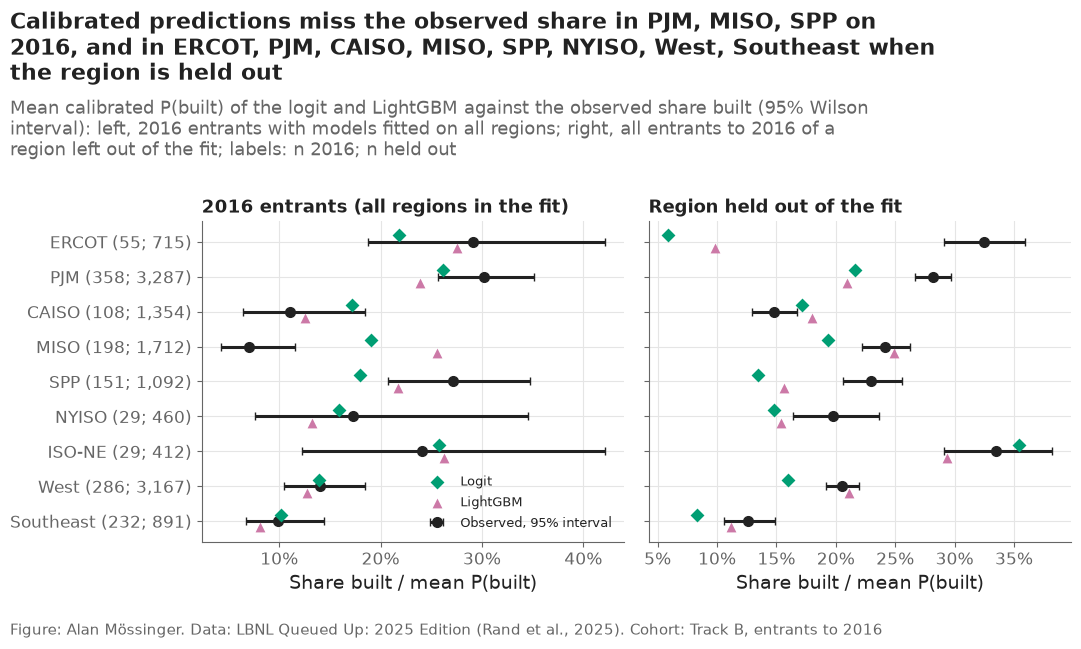

,n_loro,observed_loro,low_loro,high_loro,logit_loro,lgbm_loro,tech_rate_loro
region,,,,,,,
ERCOT,715,0.324,0.291,0.360,0.059,0.099,0.215
PJM,3287,0.282,0.267,0.297,0.217,0.210,0.212
CAISO,1354,0.148,0.130,0.168,0.172,0.180,0.228
MISO,1712,0.242,0.222,0.263,0.194,0.249,0.238
SPP,1092,0.230,0.206,0.256,0.135,0.157,0.226
NYISO,460,0.198,0.164,0.237,0.148,0.154,0.256
ISO-NE,412,0.335,0.291,0.382,0.354,0.294,0.260
West,3167,0.205,0.192,0.220,0.160,0.211,0.226
Southeast,891,0.126,0.106,0.149,0.083,0.112,0.254


In [47]:
fig, axes = plt.subplots(1, 2, sharey=True)
y = np.arange(len(REGIONS))[::-1]
for ax, (suffix, title) in zip(axes, [("2016", "2016 entrants (all regions in the fit)"), ("loro", "Region held out of the fit")]):
    observed, low, high = by_region[f"observed_{suffix}"], by_region[f"low_{suffix}"], by_region[f"high_{suffix}"]
    ax.errorbar(observed, y, xerr=[observed - low, high - observed], fmt="o", color=plots.INK, capsize=3,
                label="Observed, 95% interval")
    models = ["logit_cal", "lgbm_cal"] if suffix == "2016" else ["logit", "lgbm"]
    for model, dy, marker in zip(models, [0.18, -0.18], ["D", "^"]):
        base_model = model.replace("_cal", "")
        ax.scatter(by_region[f"{model}_{suffix}"], y + dy, marker=marker, s=50, color=MODEL_COLORS[base_model], zorder=3,
                   label=f"{MODEL_LABELS[base_model]}")
    ax.set_title(title, fontsize=13)
    ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
    ax.set_xlabel("Share built / mean P(built)")
axes[0].set_yticks(y, [f"{r} ({by_region.loc[r, 'n_2016']}; {by_region.loc[r, 'n_loro']:,})" for r in REGIONS])
axes[0].legend(loc="lower right", fontsize=9.5)
plots.finish(fig,
             "Calibrated predictions miss the observed share in "
             + (", ".join(fails_2016) if fails_2016 else "no region") + " on 2016, and in "
             + (", ".join(fails_loro) if fails_loro else "no region") + " when the region is held out",
             "Mean calibrated P(built) of the logit and LightGBM against the observed share built (95% Wilson interval): left, 2016 entrants with models "
             "fitted on all regions; right, all entrants to 2016 of a region left out of the fit; labels: n 2016; n held out",
             "Track B, entrants to 2016")
save(fig, "07_08_calibration_by_region", "Mean calibrated P(built) against the observed share by region, on 2016 and with the region held out.")
plt.show()
by_region[["n_loro", "observed_loro", "low_loro", "high_loro", "logit_loro", "lgbm_loro", "tech_rate_loro"]].round(3)

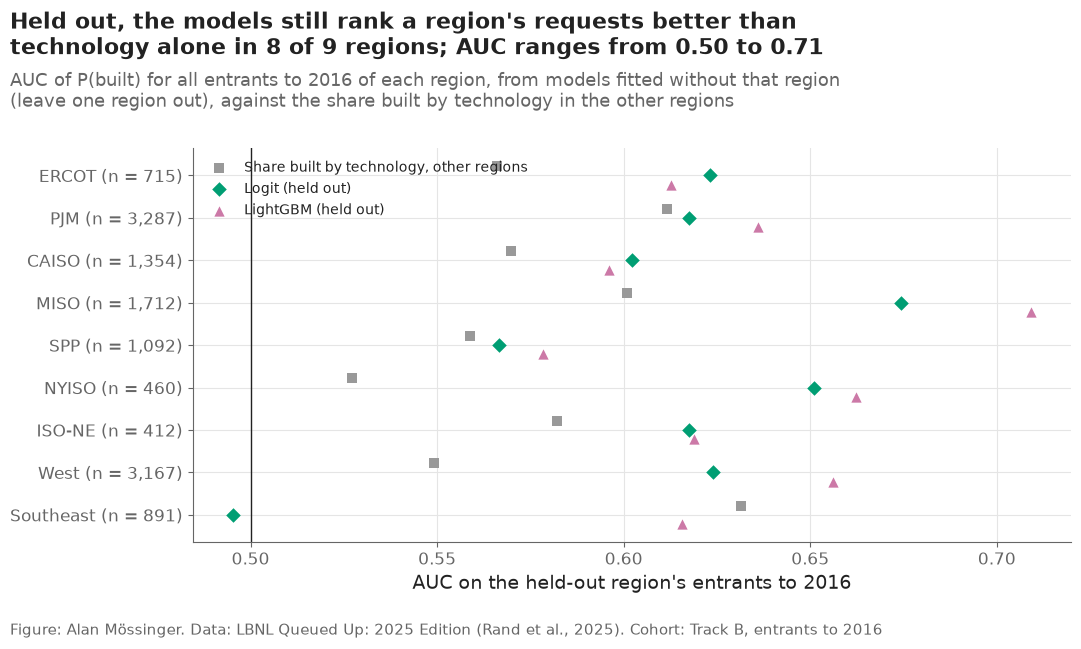

,tech_rate_loro_auc,logit_loro_auc,lgbm_loro_auc,tech_rate_loro_brier,logit_loro_brier,lgbm_loro_brier
region,,,,,,
ERCOT,0.566,0.623,0.613,0.229,0.282,0.263
PJM,0.612,0.617,0.636,0.202,0.199,0.200
CAISO,0.570,0.602,0.596,0.131,0.125,0.125
MISO,0.601,0.674,0.709,0.179,0.173,0.167
SPP,0.559,0.566,0.578,0.175,0.182,0.180
NYISO,0.527,0.651,0.662,0.162,0.155,0.153
ISO-NE,0.582,0.618,0.619,0.223,0.216,0.217
West,0.549,0.624,0.656,0.163,0.160,0.156
Southeast,0.631,0.495,0.616,0.123,0.114,0.109


In [48]:
fig, ax = plt.subplots()
y = np.arange(len(REGIONS))[::-1]
for model, dy, marker in [("tech_rate", 0.22, "s"), ("logit", 0, "D"), ("lgbm", -0.22, "^")]:
    color = "#999999" if model == "tech_rate" else MODEL_COLORS[model]
    label = "Share built by technology, other regions" if model == "tech_rate" else f"{MODEL_LABELS[model]} (held out)"
    ax.scatter(by_region[f"{model}_loro_auc"], y + dy, marker=marker, s=55, color=color, label=label, zorder=3)
ax.axvline(0.5, color=plots.INK, linewidth=1)
ax.set_yticks(y, [f"{r} (n = {by_region.loc[r, 'n_loro']:,})" for r in REGIONS])
ax.set_xlabel("AUC on the held-out region's entrants to 2016")
ax.legend(loc="upper left", fontsize=10)
gain = (by_region[["logit_loro_auc", "lgbm_loro_auc"]].max(axis=1) - by_region["tech_rate_loro_auc"])
plots.finish(fig,
             f"Held out, the models still rank a region's requests better than technology alone in {int((gain > 0).sum())} of 9 "
             f"regions; AUC ranges from {by_region[['logit_loro_auc', 'lgbm_loro_auc']].min().min():.2f} to "
             f"{by_region[['logit_loro_auc', 'lgbm_loro_auc']].max().max():.2f}",
             "AUC of P(built) for all entrants to 2016 of each region, from models fitted without that region (leave one region "
             "out), against the share built by technology in the other regions",
             "Track B, entrants to 2016")
save(fig, "07_09_loro_auc", "Leave-one-region-out AUC of the Track B models against a technology-only benchmark.")
plt.show()
by_region[["tech_rate_loro_auc", "logit_loro_auc", "lgbm_loro_auc", "tech_rate_loro_brier", "logit_loro_brier", "lgbm_loro_brier"]].round(3)

**Reading this.** Region by region the picture is mixed. On the 2016 cohort, the calibrated models miss the observed share in three regions: MISO (7.1% built; both models 19.0% and 25.5% — the base rate, 25.0%, misses too), SPP (27.2% built; logit 18.0% below the interval) and PJM (30.2% built; LightGBM 23.9% below it). When a region is held out entirely, the models miss its level in 8 of 9 regions, ISO-NE being the exception: a model cannot learn a region's own propensity without seeing it. The worst case is ERCOT, predicted at 5.9% (logit) and 9.9% (LightGBM) against 32.4% built — below even the technology-only benchmark (21.5%). The likely reason is a data artefact rather than a modelling one: ERCOT's GW waiting at entry is inflated by its stamped withdrawals (notebook 06, figure 06_02), and more GW waiting lowers the odds of being built (0.663 per log unit), so ERCOT looks far more congested than any queue the model was trained on. Ranking transfers better than levels: held out, the models' AUC beats the technology-only benchmark in 8 of 9 regions (e.g. MISO 0.709 for LightGBM vs 0.601; NYISO 0.662 vs 0.527), the exception being the Southeast (logit 0.495, LightGBM 0.616 vs 0.631). For a developer in a region outside the training data the message is: use the model to rank, not as a probability.

## 6. What the models say

The logistic regression's odds ratios (P(built) against withdrawn) with 95%
intervals from 200 bootstrap resamples of requests, and LightGBM's split-gain
shares.

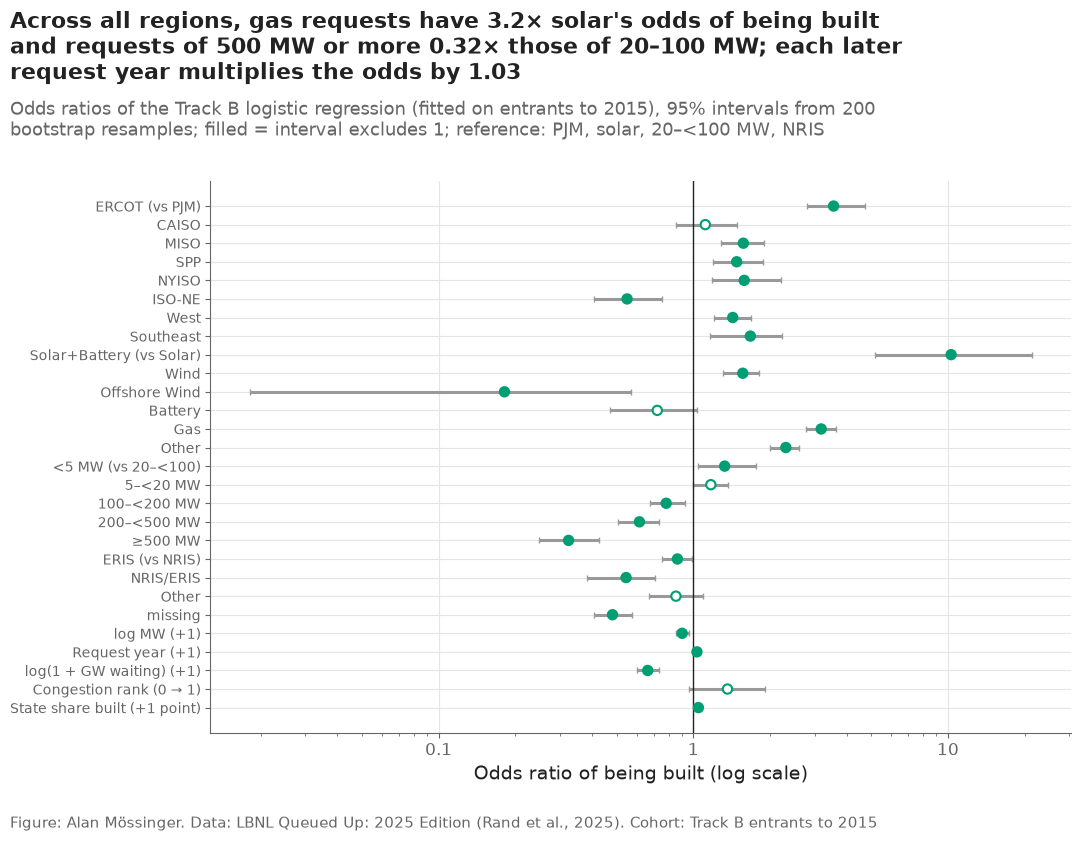

,odds_ratio,ci_low,ci_high
label,,,
ERCOT (vs PJM),3.557,2.784,4.721
CAISO,1.115,0.853,1.481
MISO,1.573,1.286,1.899
SPP,1.481,1.200,1.886
NYISO,1.585,1.188,2.210
ISO-NE,0.550,0.409,0.753
West,1.429,1.204,1.681
Southeast,1.676,1.169,2.237
Solar+Battery (vs Solar),10.293,5.155,21.364


In [49]:
X_tune = track_b.logit_design(tune_enc)
scale = logit[0].scale_
point = pd.Series(logit[-1].coef_[0] / scale, index=X_tune.columns)
rng = np.random.default_rng(11)
draws = []
for _ in range(N_BOOT):
    idx = rng.integers(0, len(X_tune), len(X_tune))
    model = discrete_time.fit_logit(X_tune.iloc[idx], tune_enc["built"].iloc[idx], LOGIT_C_BEST)
    draws.append(model[-1].coef_[0] / model[0].scale_)
draws = np.array(draws)
units = {"state_rate": 0.01}
odds = pd.DataFrame({"term": X_tune.columns, "odds_ratio": np.exp(point.to_numpy() * [units.get(c, 1) for c in X_tune.columns]),
                     "ci_low": np.exp(np.quantile(draws, 0.025, axis=0) * [units.get(c, 1) for c in X_tune.columns]),
                     "ci_high": np.exp(np.quantile(draws, 0.975, axis=0) * [units.get(c, 1) for c in X_tune.columns])})
odds.to_csv(paths.RESULTS / "trackB_odds_ratios.csv", index=False)

LABELS = {**{f"region_{r}": f"{r} (vs PJM)" if r == "ERCOT" else r for r in REGIONS},
          **{f"tech_{t}": (f"{t} (vs Solar)" if t == "Solar+Battery" else t) for t in discrete_time.TECH_LEVELS},
          **{f"size_{s}": (f"{s} MW (vs 20–<100)" if s == "<5" else f"{s} MW") for s in config.SIZE_LABELS},
          **{f"service_{s}": (f"{s} (vs NRIS)" if s == "ERIS" else s) for s in track_b.SERVICE_LEVELS},
          "log_mw": "log MW (+1)", "q_year": "Request year (+1)", "log_congestion_gw": "log(1 + GW waiting) (+1)",
          "congestion_rank": "Congestion rank (0 → 1)", "state_rate": "State share built (+1 point)"}
fig, ax = plt.subplots(figsize=(11, 8.5))
y = np.arange(len(odds))[::-1]
significant = (odds["ci_low"] > 1) | (odds["ci_high"] < 1)
ax.errorbar(odds["odds_ratio"], y, xerr=[odds["odds_ratio"] - odds["ci_low"], odds["ci_high"] - odds["odds_ratio"]],
            fmt="none", color="#999999", capsize=2)
ax.scatter(odds["odds_ratio"], y, s=45, zorder=3, color=np.where(significant, MODEL_COLORS["logit"], "white"),
           edgecolors=MODEL_COLORS["logit"], linewidths=1.5)
ax.axvline(1, color=plots.INK, linewidth=1)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(lambda x, _: f"{x:g}")
ax.set_yticks(y, [LABELS.get(t, t) for t in odds["term"]], fontsize=10)
ax.set_xlabel("Odds ratio of being built (log scale)")
o = odds.set_index("term")["odds_ratio"]
plots.finish(fig,
             f"Across all regions, gas requests have {o['tech_Gas']:.1f}× solar's odds of being built and requests of 500 MW or "
             f"more {o['size_≥500']:.2f}× those of 20–100 MW; each later request year multiplies the odds by {o['q_year']:.2f}",
             "Odds ratios of the Track B logistic regression (fitted on entrants to 2015), 95% intervals from 200 bootstrap "
             "resamples; filled = interval excludes 1; reference: PJM, solar, 20–<100 MW, NRIS",
             "Track B entrants to 2015")
save(fig, "07_10_odds_ratios", "Odds ratios of the Track B logistic regression for being built.")
plt.show()
odds.assign(label=odds["term"].map(LABELS)).set_index("label")[["odds_ratio", "ci_low", "ci_high"]].round(3)

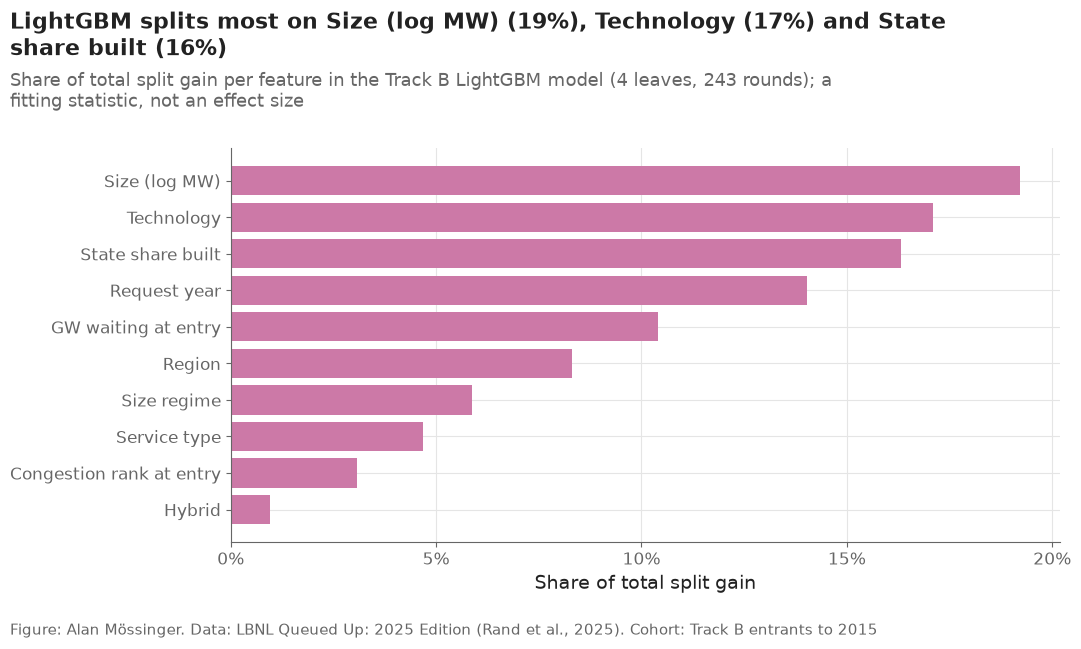

log_mw               0.192
tech                 0.171
state_rate           0.163
q_year               0.140
log_congestion_gw    0.104
region               0.083
size_regime          0.059
service              0.047
congestion_rank      0.031
hybrid               0.009
dtype: float64

In [50]:
gain = lgbm.feature_importance("gain")
importance = pd.Series(gain / gain.sum(), index=track_b.lgbm_design(tune_enc.iloc[:5]).columns).sort_values()
importance.to_csv(paths.RESULTS / "trackB_lgbm_importance.csv", header=["gain_share"])
NAMES = {"region": "Region", "tech": "Technology", "size_regime": "Size regime", "service": "Service type", "hybrid": "Hybrid",
         "log_mw": "Size (log MW)", "q_year": "Request year", "log_congestion_gw": "GW waiting at entry",
         "congestion_rank": "Congestion rank at entry", "state_rate": "State share built"}
fig, ax = plt.subplots()
ax.barh(range(len(importance)), importance.to_numpy(), color=MODEL_COLORS["lgbm"])
ax.set_yticks(range(len(importance)), [NAMES[f] for f in importance.index])
ax.set_xticks(np.arange(0, importance.max() + 0.05, 0.05))
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.set_xlabel("Share of total split gain")
top = importance.sort_values(ascending=False)
plots.finish(fig,
             f"LightGBM splits most on {NAMES[top.index[0]]} ({top.iloc[0]:.0%}), {NAMES[top.index[1]]} ({top.iloc[1]:.0%}) and "
             f"{NAMES[top.index[2]]} ({top.iloc[2]:.0%})",
             f"Share of total split gain per feature in the Track B LightGBM model ({LGBM_PARAMS['num_leaves']} leaves, "
             f"{N_ROUNDS} rounds); a fitting statistic, not an effect size",
             "Track B entrants to 2015")
save(fig, "07_11_lgbm_importance", "Split-gain importance of each feature in the Track B LightGBM model.")
plt.show()
top.round(3)

**Reading this.** Across all nine regions, other things equal, ERCOT requests have 3.56× PJM's odds of being built and ISO-NE requests 0.55×; gas has 3.18× solar's odds, "Other" 2.31× and wind 1.57×, offshore wind 0.18×. Size has a steady gradient: under 5 MW 1.33×, then 0.78×, 0.62× and 0.32× for the classes from 100 MW up, against 20–100 MW. A missing service type (0.48×) marks weaker requests. More GW waiting at entry lowers the odds (0.663 per log unit), as Johnston et al. (2023) argue. One sign differs from Track A: each later request year raises the odds slightly (1.034 per year). That is the selection of the first section showing through — later cohorts keep fewer of their slow, still-waiting requests — and a reason not to read Track B coefficients as causal. Solar+Battery's 10.3× (interval 5.2–21.4) rests on few resolved hybrids. LightGBM leans on size (19.2% of the gain), technology (17.1%), the state's share built (16.3%) and request year (14.0%), with region at 8.3%.

## 7. Predictions for the 2016 and 2017 cohorts

Final predictions: the fits on entrants to 2015, raw and through the isotonic
maps fitted on 2016. For 2016 requests the calibrated values are the
cross-fitted ones (section 4). The base rate for 2017 uses entrants to 2016.
The observed outcome is carried for notebook 08; nothing below summarises
it for the 2017 cohort.

In [51]:
raw_test = {"logit": logit.predict_proba(track_b.logit_design(test_enc))[:, 1], "lgbm": lgbm.predict(track_b.lgbm_design(test_enc))}
pieces = []
for split, frame, raw, base, cal in [
        ("validation", valid, raw_valid, valid_preds["baseline"], {m: valid_preds[f"{m}_cal"] for m in raw_valid}),
        ("test", test, raw_test, track_b.base_rates(pd.concat([tune, valid]), test)["rate"].to_numpy(),
         {m: maps[m].predict(raw_test[m]) for m in raw_test})]:
    pieces.append(pd.DataFrame({"project_key": frame["project_key"].astype(str), "region": frame["region"].astype(str),
                                "q_year": frame["q_year"].astype(int), "split": split, "baseline": base,
                                "logit": raw["logit"], "lgbm": raw["lgbm"], "logit_cal": cal["logit"], "lgbm_cal": cal["lgbm"],
                                "built": frame["built"].astype(int)}))
predictions_b = pd.concat(pieces, ignore_index=True)
out_file = paths.DATA_PROCESSED / "predictions_trackB.parquet"
predictions_b.to_parquet(out_file, index=False)
print(f"{out_file.name}: {len(predictions_b):,} rows, {out_file.stat().st_size / 1e6:.2f} MB")
print("highest calibrated P(built), 2017 cohort:", predictions_b.loc[predictions_b["split"] == "test", ["logit_cal", "lgbm_cal"]].max().round(3).to_dict())
test_b = predictions_b[predictions_b["split"] == "test"]
test_b.groupby("region")[["baseline", "logit", "lgbm", "logit_cal", "lgbm_cal"]].mean().reindex(REGIONS).round(3)

predictions_trackB.parquet: 2,980 rows, 0.08 MB
highest calibrated P(built), 2017 cohort: {'logit_cal': 0.441, 'lgbm_cal': 0.402}


,baseline,logit,lgbm,logit_cal,lgbm_cal
region,,,,,
ERCOT,0.262,0.262,0.304,0.220,0.269
PJM,0.248,0.318,0.260,0.264,0.249
CAISO,0.218,0.270,0.308,0.224,0.291
MISO,0.160,0.200,0.229,0.179,0.230
SPP,0.167,0.132,0.176,0.120,0.171
NYISO,0.203,0.174,0.158,0.172,0.141
ISO-NE,0.334,0.252,0.229,0.212,0.221
West,0.189,0.176,0.160,0.147,0.145
Southeast,0.072,0.136,0.160,0.136,0.131


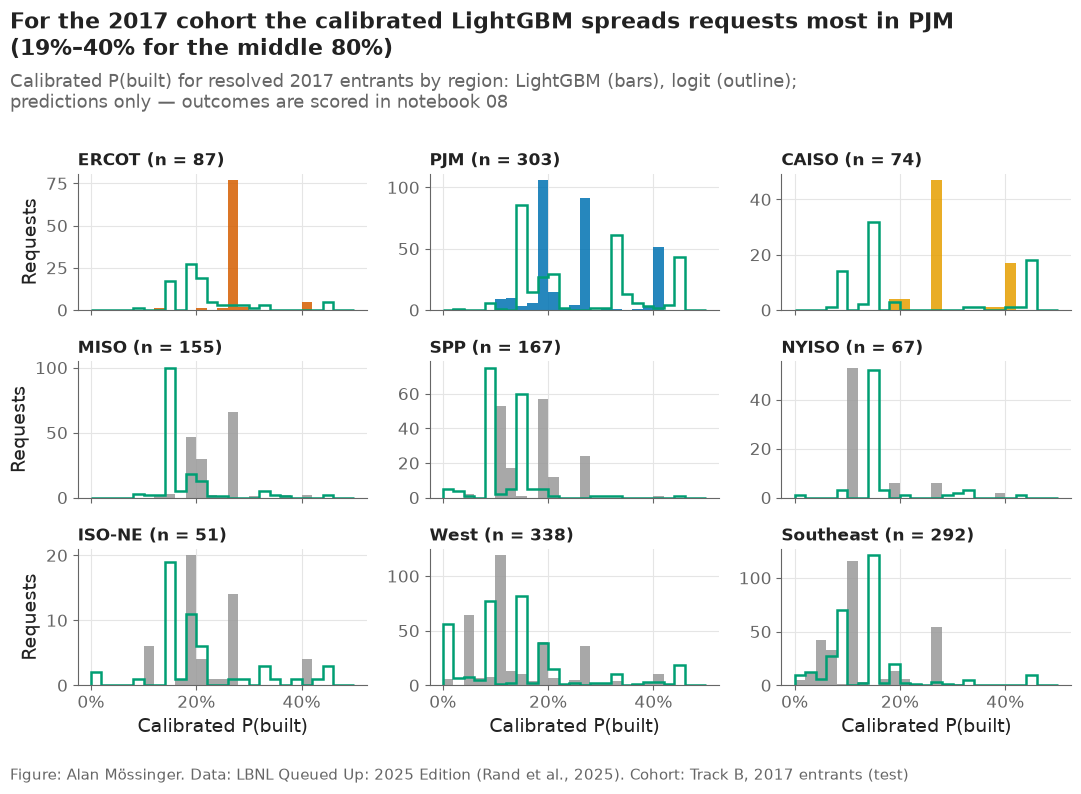

,0.1,0.9
region,,
ERCOT,0.262,0.262
PJM,0.192,0.402
CAISO,0.220,0.402
MISO,0.192,0.262
SPP,0.113,0.262
NYISO,0.113,0.262
ISO-NE,0.114,0.262
West,0.058,0.262
Southeast,0.058,0.262


In [52]:
fig, axes = plt.subplots(3, 3, sharex=True, figsize=(11, 8))
bins = np.linspace(0, 0.5, 26)
for ax, region in zip(axes.flat, REGIONS):
    part = test_b[test_b["region"] == region]
    ax.hist(part["lgbm_cal"], bins=bins, color=region_color(region), alpha=0.85)
    ax.hist(part["logit_cal"], bins=bins, histtype="step", color=MODEL_COLORS["logit"], linewidth=1.8)
    ax.set_title(f"{region} (n = {len(part)})", fontsize=12)
    ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
for ax in axes[-1]:
    ax.set_xlabel("Calibrated P(built)")
for ax in axes[:, 0]:
    ax.set_ylabel("Requests")
spread = test_b.groupby("region")["lgbm_cal"].quantile([0.1, 0.9]).unstack().reindex(REGIONS)
plots.finish(fig,
             f"For the 2017 cohort the calibrated LightGBM spreads requests most in "
             f"{(spread[0.9] - spread[0.1]).idxmax()} ({spread.loc[(spread[0.9] - spread[0.1]).idxmax(), 0.1]:.0%}–"
             f"{spread.loc[(spread[0.9] - spread[0.1]).idxmax(), 0.9]:.0%} for the middle 80%)",
             "Calibrated P(built) for resolved 2017 entrants by region: LightGBM (bars), logit (outline); predictions only — "
             "outcomes are scored in notebook 08",
             "Track B, 2017 entrants (test)")
save(fig, "07_12_test_predictions", "Distribution of calibrated P(built) for the 2017 test cohort by region.")
plt.show()
spread.round(3)

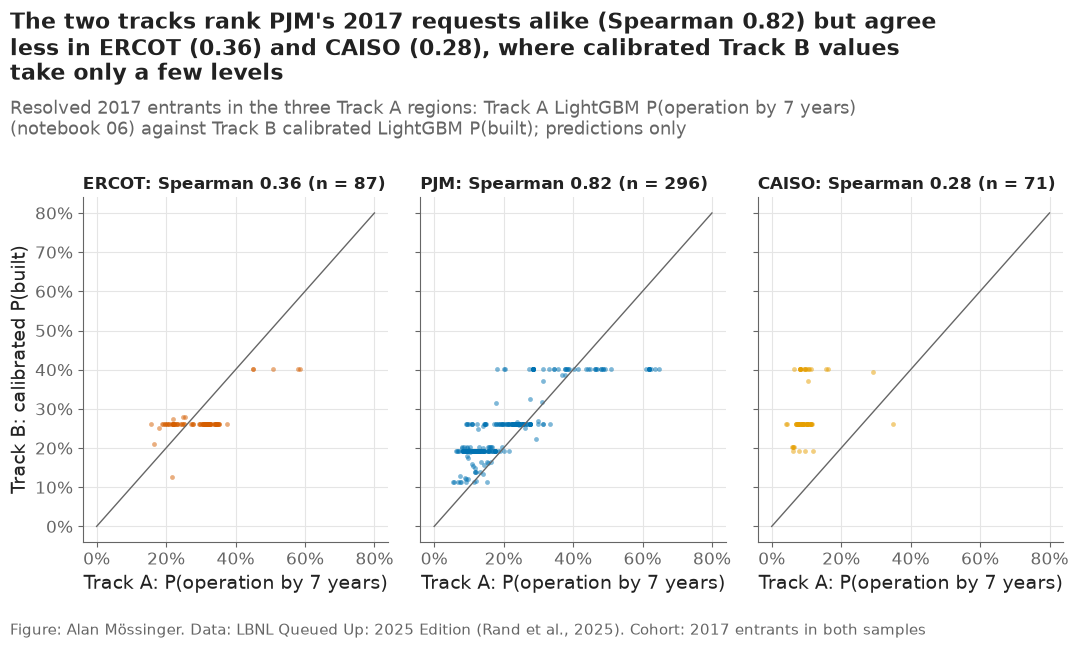

,n,spearman
ERCOT,87.0,0.36
PJM,296.0,0.82
CAISO,71.0,0.28


In [53]:
track_a_pred = pd.read_parquet(paths.DATA_PROCESSED / "predictions_trackA.parquet")
track_a_7 = track_a_pred[(track_a_pred["horizon"] == 7) & (track_a_pred["q_year"] == 2017)]
both = test_b.merge(track_a_7[["project_key", "dt_lgbm", "dt_logit"]], on="project_key")
fig, axes = plt.subplots(1, 3, sharex=True, sharey=True)
agreement = {}
for ax, region in zip(axes, config.TRACK_A_REGIONS):
    part = both[both["region"] == region]
    ax.scatter(part["dt_lgbm"], part["lgbm_cal"], s=12, alpha=0.5, color=region_color(region), linewidths=0)
    ax.plot([0, 0.8], [0, 0.8], color=plots.MUTED, linewidth=1)
    agreement[region] = {"n": len(part), "spearman": part[["dt_lgbm", "lgbm_cal"]].corr(method="spearman").iloc[0, 1]}
    ax.set_title(f"{region}: Spearman {agreement[region]['spearman']:.2f} (n = {len(part)})", fontsize=12)
    ax.set_xlabel("Track A: P(operation by 7 years)")
    ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
    ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
axes[0].set_ylabel("Track B: calibrated P(built)")
agreement = pd.DataFrame(agreement).T
plots.finish(fig,
             f"The two tracks rank PJM's 2017 requests alike (Spearman {agreement.loc['PJM', 'spearman']:.2f}) but agree "
             f"less in ERCOT ({agreement.loc['ERCOT', 'spearman']:.2f}) and CAISO ({agreement.loc['CAISO', 'spearman']:.2f}), "
             "where calibrated Track B values take only a few levels",
             "Resolved 2017 entrants in the three Track A regions: Track A LightGBM P(operation by 7 years) (notebook 06) "
             "against Track B calibrated LightGBM P(built); predictions only",
             "2017 entrants in both samples")
save(fig, "07_13_track_a_vs_b", "Track A 7-year P(operation) against Track B P(built) for the shared 2017 requests.")
plt.show()
agreement.round(2)

**Reading this.** Predictions for the 1,446 validation and 1,534 test requests are in `data/processed/predictions_trackB.parquet` (2,980 rows, raw and calibrated, with the base rate). For the 2017 cohort the calibrated LightGBM is highest on average in CAISO (29.1%) and ERCOT (26.9%) and lowest in the Southeast (13.1%), West (14.5%) and NYISO (14.1%). CAISO's value stands out against its training share built (15.1%) and its base rate (21.8%); notebook 08 should check it first. Within regions the calibrated values cluster on a few levels (in ERCOT the middle 80% is a single value, 26.2%; in PJM 19.2–40.2%), the cost of calibration noted above. On the requests the two tracks share, they rank PJM's 2017 entrants alike (Spearman 0.82 between Track A's 7-year probability and Track B's P(built)) but agree much less in ERCOT (0.36) and CAISO (0.28), where Track B's calibrated values take only a few levels.

## 8. Checks

PLAN.md §6 asks that AUC and Brier beat the region × technology base rate
on the 2017 cohort. Scoring the 2017 cohort here would use test outcomes
before notebook 08 has fixed its success criteria, so that check moves to
notebook 08 (decision #29); here the same comparison is made on the 2016
cohort, out of sample for the raw models.

In [54]:
m = metrics.set_index("model")
allowed = {"region", "tech", "size_regime", "service", "hybrid", "log_mw", "q_year", "log_congestion_gw",
           "congestion_rank", "state_rate"}
runtime = time.time() - START
checks = pd.DataFrame([
    ("predictions for every 2016 and 2017 request, all models, within [0, 1]",
     len(predictions_b) == len(valid) + len(test)
     and bool(predictions_b[["baseline", "logit", "lgbm", "logit_cal", "lgbm_cal"]].apply(lambda s: s.between(0, 1)).all().all())),
    ("features are entry-time only", set(track_b.lgbm_design(tune_enc.iloc[:5]).columns) == allowed),
    ("2016 cohort: both models' AUC above the base rate's",
     bool(m.loc["logit", "auc"] > m.loc["baseline", "auc"] and m.loc["lgbm", "auc"] > m.loc["baseline", "auc"])),
    ("2016 cohort: both models' Brier score below the base rate's",
     bool(m.loc["logit", "brier"] < m.loc["baseline", "brier"] and m.loc["lgbm", "brier"] < m.loc["baseline", "brier"])),
    ("per-region calibration and leave-one-region-out tables written, failing regions named",
     (paths.RESULTS / "trackB_by_region.csv").exists()),
    ("notebook runs in under 10 minutes", runtime < 600),
], columns=["check", "passed"])
checks["result"] = np.where(checks["passed"], "PASS", "FAIL")
checks.to_csv(paths.RESULTS / "trackB_checks.csv", index=False)
print(f"run time: {runtime / 60:.1f} minutes")
checks[["check", "result"]]

run time: 1.2 minutes


,check,result
0,"predictions for every 2016 and 2017 request, a...",PASS
1,features are entry-time only,PASS
2,2016 cohort: both models' AUC above the base r...,PASS
3,2016 cohort: both models' Brier score below th...,PASS
4,per-region calibration and leave-one-region-ou...,PASS
5,notebook runs in under 10 minutes,PASS


**Reading this.** All six checks pass: complete predictions within [0, 1], entry-time features only, both models above the base rate's AUC and below its Brier score on the 2016 cohort, the per-region and leave-one-region-out tables written with the failing regions named (PJM, MISO and SPP on 2016; eight regions held out), and a run time under 10 minutes. PLAN.md's check on the 2017 cohort is moved to notebook 08 (decision #29), so that no test outcome is looked at before the success criteria are fixed.

## Takeaways — Part C

- On the 2016 cohort both Track B models rank requests better than the region × technology base rate (AUC 0.665 and 0.662 vs 0.613); their probabilities are only slightly better (Brier 0.1433 and 0.1438 vs 0.1471, overlapping intervals).
- Calibration fixes the average level (18.3% vs 18.4% observed) but not the overall score, and its steps make the calibrated values coarse; binned isotonic regression stops a handful of requests from setting the top of the map (decision #30).
- Held out, a region's level is missed in 8 of 9 regions (ERCOT worst, most likely through its inflated congestion), while ranking still beats the technology-only benchmark in 8 of 9 — use Track B to rank requests outside the training regions, not as a probability.
- Track B's sample keeps only resolved requests, so later cohorts are tilted to fast outcomes (up to 32.6% of 2016 entrants still waiting); the slight rise in odds with request year (1.034 per year) reflects that selection.
- As in Track A, the later cohort chose small trees over the grouped CV's large ones (decision #27).

**What goes to the report:** 07_05 (2016 metrics) in the evaluation section next to notebook 08's test results; 07_08 and 07_09 for the leave-one-region-out limitation; 07_02 for the resolved-only selection; one sentence on calibration (07_06).

# Part D — A fair baseline and the utility-scale cohort (was notebook 11)

Draft v1 beat a region × technology average. Size is the second-strongest driver in notebook 09's explanation and that average ignores it, so part of the measured gain could be a size lookup rather than machine learning; and the gain vanished once requests under 20 MW were excluded (notebook 08, figure 08_17). This notebook adds a **fair baseline** (region × technology × size band), makes requests of **20 MW and more the primary cohort**, chooses among size-aware variants of the v1 models on 2016 entrants only, and rescores everything on the 2017–2019 test cohort against both baselines. Its first cell writes the v2 success criteria before any test metric exists.

## 0. The v2 success criteria, written before anything is scored

Decision #42 names the criteria C6–C12; this cell writes them to `results/success_criteria_v2.csv` and records decision #52 in `docs/decisions.md`, reading no data. The criteria are scored in notebook 18. The v2 model named in C6 is "the candidate with the lowest 2016 log loss on requests of 20 MW and more" — a rule, not a result, because the test cohort has not been touched when this cell runs.

In [55]:
# Pre-registration: this cell reads no data
import json
import re
from datetime import date
from pathlib import Path

import pandas as pd

REPO = Path.cwd().resolve().parent
TODAY = "2026-10-06"

CRITERIA_V2 = [
    {"id": "C6", "line": "≥ 20 MW cohort: v2 model vs fair baseline, Uno's C", "notebook": "11/18", "track": "A",
     "cohort": ">=20 MW", "model": "v2 (lowest 2016 log loss on ≥ 20 MW rows)", "benchmark": "fair_baseline",
     "metric": "uno_c", "horizons": "3, 5", "rule": "paired 95% interval entirely on the better side"},
    {"id": "C6", "line": "≥ 20 MW cohort: v2 model vs fair baseline, Brier", "notebook": "11/18", "track": "A",
     "cohort": ">=20 MW", "model": "v2 (lowest 2016 log loss on ≥ 20 MW rows)", "benchmark": "fair_baseline",
     "metric": "brier", "horizons": "3, 5", "rule": "paired 95% interval entirely on the better side"},
    {"id": "C7", "line": "≥ 20 MW cohort, 2018–2019 entrants, after level repair: calibration slope and intercept",
     "notebook": "12/18", "track": "A", "cohort": ">=20 MW, entry 2018–2019", "model": "v2 after level repair",
     "benchmark": "", "metric": "slope, intercept", "horizons": "3, 5",
     "rule": "slope interval within 0.8–1.2 and intercept interval covering 0"},
    {"id": "C8", "line": "Landmark model at +24 months and at IA executed vs the entry model, same risk set",
     "notebook": "14/18", "track": "A", "cohort": "requests active at the landmark", "model": "landmark",
     "benchmark": "entry model", "metric": "uno_c", "horizons": "3 (from the landmark)",
     "rule": "paired 95% interval entirely on the better side"},
    {"id": "C9", "line": "Backtest: realised MW online by end-2024, model-chosen book vs fair-baseline book, same budget",
     "notebook": "16/18", "track": "A", "cohort": "2017–2019 entrants", "model": "v2 book", "benchmark": "fair-baseline book",
     "metric": "mw_online", "horizons": "by 2024-12-31", "rule": "paired 95% interval entirely on the better side"},
    {"id": "C10", "line": "Backtest: realised value of the model-chosen book vs the fair-baseline book, base value case",
     "notebook": "16/18", "track": "A", "cohort": "2017–2019 entrants", "model": "v2 book", "benchmark": "fair-baseline book",
     "metric": "value", "horizons": "by 2024-12-31", "rule": "paired 95% interval on the better side; low and high cases reported"},
    {"id": "C11", "line": "Simulated book: the 5–95% band of expected MW online by 2024 covers the realised value",
     "notebook": "16/18", "track": "A", "cohort": "2017–2019 book", "model": "v2 book simulation", "benchmark": "",
     "metric": "coverage", "horizons": "by 2024-12-31", "rule": "realised MW inside the 5–95% band"},
    {"id": "C12", "line": "Leakage guard: no landmark feature dated after its landmark; landmark AUC ≤ leakage-ablation AUC",
     "notebook": "14/18", "track": "A", "cohort": "", "model": "landmark", "benchmark": "leakage ablation (notebook 08)",
     "metric": "auc", "horizons": "5", "rule": "both hold"},
]
REGISTERED_V2 = {"decided": TODAY, "n_boot": 200, "level": 0.95, "seed_v2": 900,
                 "primary_cohort": "requests whose size regime is 20 MW or more (notebook 04's size_regime)",
                 "variant_rule": "among the fixed candidates K0–K3 (LightGBM) and the K1/K2 logits, the one with the "
                                 "lowest multiclass log loss on 2016 entrants' project-years of 20 MW or more, "
                                 "fitted on entrants to 2015; refitted on entrants to 2016 for the test cohort",
                 "criteria": CRITERIA_V2}

DECISION_52 = """52. **Pre-registered v2 success criteria C6–C12** (Alan, 2026-10-06; written
    by the first cell of notebook 11 before any test metric of v2 existed).
    Primary cohort: test requests of 20 MW and more; the v2 model is the
    candidate with the lowest 2016 log loss on ≥ 20 MW project-years,
    chosen before the test cohort is scored (rule in
    `results/success_criteria_v2_registered.json`). Lines: C6 Uno's C and
    Brier vs the fair baseline at 3 and 5 years; C7 calibration slope
    0.8–1.2 and intercept covering 0 on 2018–2019 entrants after the level
    repair; C8 landmark models beat the entry model on the same risk set;
    C9 and C10 the model-chosen book delivers more realised MW and value
    than the fair-baseline book in the backtest; C11 the simulated band
    covers the realised MW; C12 the leakage guard holds. Scored in notebook
    18; failures are reported, not removed; the v1 verdict (decision #5) is
    untouched. *Rejected:* scoring the ≥ 20 MW cohort against the v1
    baseline only (that is the comparison a size lookup would pass).
"""

decisions_file = REPO / "docs" / "decisions.md"
text = decisions_file.read_text(encoding="utf-8")
entry = re.compile(r"^52\. \*\*Pre-registered v2 success criteria.*?(?=^\d+\. \*\*|\Z)", re.M | re.S)
found = entry.findall(text)
if not found:
    text = text.rstrip("\n") + "\n" + DECISION_52
    decisions_file.write_text(text, encoding="utf-8")
pd.DataFrame(CRITERIA_V2).to_csv(REPO / "results" / "success_criteria_v2.csv", index=False)
(REPO / "results" / "success_criteria_v2_registered.json").write_text(json.dumps(REGISTERED_V2, indent=2, ensure_ascii=False),
                                                                      encoding="utf-8")
print(f"decision #52 {'already in place' if found else 'written'}; {len(CRITERIA_V2)} criterion lines registered")

decision #52 already in place; 8 criterion lines registered


## Setup

In [56]:
import json
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append(str(Path.cwd().resolve().parent))  # notebooks run from notebooks/; src/ is one level up
from src import baselines, config, discrete_time, evaluation, paths, plots, survival_tools, variants

paths.ensure_dirs()
plots.set_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
warnings.filterwarnings("ignore", category=FutureWarning)

NOTEBOOK = "04_forecast_queue"
TRACK_A = config.TRACK_A_REGIONS
HORIZONS = config.HORIZONS
START = time.time()
REGISTERED = json.loads((paths.RESULTS / "success_criteria_v2_registered.json").read_text(encoding="utf-8"))
N_BOOT, LEVEL, SEED = REGISTERED["n_boot"], REGISTERED["level"], REGISTERED["seed_v2"]


def save(fig, name, caption):
    """Save a figure of this notebook under figures/04_forecast_queue/ with its caption stub."""
    return plots.save_fig(fig, name, caption, NOTEBOOK, folder=NOTEBOOK)


at_least_20 = variants.at_least_20  # the 20 MW rule shared with notebooks 08 and 12


def pct(x, digits=1):
    return f"{100 * x:.{digits}f}%"

## 1. Cohorts

The same temporal split as notebooks 06 and 08: tune on entrants to 2015, choose on 2016, refit on entrants to 2016, test on 2017–2019. The primary cohort is the test requests of 20 MW and more; the secondary track is the rest.

In [57]:
clean = pd.read_parquet(paths.DATA_INTERIM / "queue_clean.parquet")
track_a = pd.read_parquet(paths.DATA_INTERIM / "trackA.parquet")
track_a["tech"] = track_a["type_clean"].map(plots.tech_group)
tuning = json.loads((paths.RESULTS / "dt_tuning.json").read_text(encoding="utf-8"))
pred_v1 = pd.read_parquet(paths.DATA_PROCESSED / "predictions_trackA.parquet")

tune = track_a[track_a["q_year"] <= config.TUNE_MAX_YEAR]
valid = track_a[track_a["q_year"] == config.VALIDATION_YEAR]
final = track_a[track_a["q_year"] <= config.TRAIN_MAX_YEAR]
test = track_a[track_a["q_year"].between(*config.TEST_YEARS)].copy()
test["large"] = at_least_20(test)
COHORTS = {"≥ 20 MW": test["large"].to_numpy(), "< 20 MW": (~test["large"]).to_numpy(), "all": np.ones(len(test), bool)}

sizes = pd.DataFrame({
    "requests": {k: int(m.sum()) for k, m in COHORTS.items()},
    "share of test requests": {k: m.mean() for k, m in COHORTS.items()},
    "share of test MW": {k: test.loc[m, "mw"].sum() / test["mw"].sum() for k, m in COHORTS.items()},
    "operations by 5 years": {k: int(((test["event"] == 1) & (test["duration_years"] <= 5) & m).sum()) for k, m in COHORTS.items()},
})
sizes.to_csv(paths.RESULTS / "sample_sizes_v2.csv")
print(f"train to 2015: {len(tune):,} | 2016: {len(valid):,} | train to 2016: {len(final):,} | test: {len(test):,}")
sizes.round(3)

train to 2015: 4,725 | 2016: 573 | train to 2016: 5,298 | test: 2,268


,requests,share of test requests,share of test MW,operations by 5 years
≥ 20 MW,1839,0.811,0.989,132
< 20 MW,429,0.189,0.011,95
all,2268,1.000,1.000,227


**Reading this.** The primary cohort is 1,839 requests, 81% of the test cohort by count and 98.9% by MW — the part of the queue where development capital goes. But it holds only 132 of the 227 operations within five years; the 429 requests under 20 MW hold the other 95. Small requests are few, light and built often, which is why they carried so much of the v1 result (figure 08_17), and why the two cohorts are scored apart.

## 2. The fair baseline

`src/baselines.fair_baseline_cif`: the Aalen–Johansen incidence of operation in the request's region × technology × size-band cell of the training data; cells under 50 requests fall back to region × technology, then to region. The v1 baseline is the same thing without the size cut, so the fair baseline is what a careful analyst would build from the same table with a pivot. `tests/test_baselines.py` checks that collapsing the size bands reproduces the v1 baseline exactly.

In [58]:
cells = baselines.cell_table(final, HORIZONS)
cells.to_csv(paths.RESULTS / "fair_baseline_cells.csv", index=False)
fair_test = baselines.fair_baseline_cif(final, test, HORIZONS)
v1_test = survival_tools.baseline_cif(final, test, HORIZONS)
keys = test["project_key"].astype(str)
P1 = {h: pred_v1[(pred_v1["split"] == "test") & (pred_v1["horizon"] == h)].set_index("project_key").loc[keys] for h in HORIZONS}
assert all(np.allclose(P1[h]["baseline"].to_numpy(), v1_test[h].to_numpy()) for h in HORIZONS), "v1 baseline refit differs"

used = fair_test["cell"].value_counts()
print(f"cells in the training data: {len(cells)}, with ≥ 50 requests: {int(cells['used'].sum())}; "
      f"test requests served by their own size cell: {used.get('region × technology × size', 0):,} of {len(test):,}")
spread = cells[cells["used"]].groupby(["region", "tech"])["p_operation_5"].agg(["min", "max", "count"])
spread = spread[spread["count"] >= 2].assign(range=lambda d: d["max"] - d["min"]).sort_values("range", ascending=False)
spread.round(3).head(8)

cells in the training data: 89, with ≥ 50 requests: 30; test requests served by their own size cell: 1,237 of 2,268


min    max  count  range
region tech                             
PJM    Gas    0.073  0.576      6  0.503
CAISO  Gas    0.000  0.169      3  0.169
ERCOT  Wind   0.190  0.344      3  0.154
CAISO  Solar  0.000  0.127      5  0.127
PJM    Solar  0.091  0.212      3  0.121
       Wind   0.069  0.131      3  0.062
ERCOT  Solar  0.127  0.182      2  0.055
PJM    Other  0.417  0.455      3  0.039

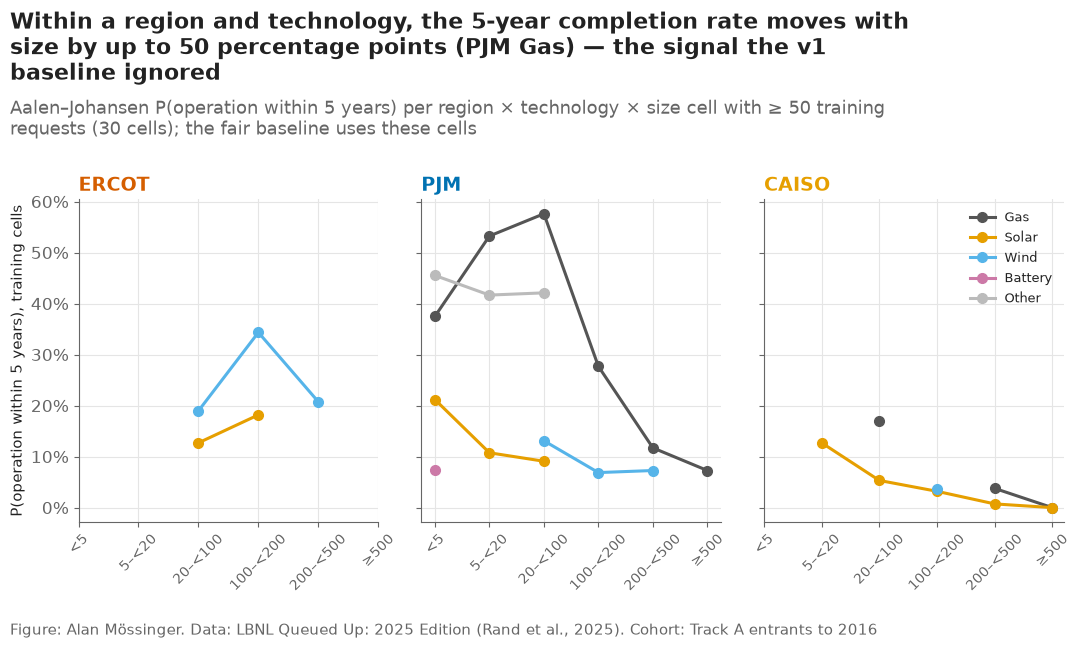

In [59]:
fig, axes = plt.subplots(1, 3, sharey=True)
for ax, region in zip(axes, TRACK_A):
    part = cells[(cells["region"] == region) & cells["used"]]
    for tech, sub in part.groupby("tech"):
        sub = sub.set_index("size_regime").reindex(config.SIZE_LABELS)
        ax.plot(range(len(config.SIZE_LABELS)), sub["p_operation_5"], marker="o", color=config.TECH_COLORS.get(tech, "#BBBBBB"), label=tech)
    ax.set_xticks(range(len(config.SIZE_LABELS)), config.SIZE_LABELS, rotation=45, fontsize=10)
    ax.set_title(region, color=plots.region_color(region))
    ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
axes[0].set_ylabel("P(operation within 5 years), training cells")
handles = {tech: plt.Line2D([], [], marker="o", color=config.TECH_COLORS.get(tech, "#BBBBBB"), label=tech)
           for tech in cells.loc[cells["used"], "tech"].unique()}
axes[2].legend(handles=list(handles.values()), fontsize=9, loc="upper right")
steepest = spread.index[0]
plots.finish(fig,
             f"Within a region and technology, the 5-year completion rate moves with size by up to "
             f"{100 * spread['range'].iloc[0]:.0f} percentage points ({steepest[0]} {steepest[1]}) — the signal the v1 baseline ignored",
             f"Aalen–Johansen P(operation within 5 years) per region × technology × size cell with ≥ 50 training requests "
             f"({int(cells['used'].sum())} cells); the fair baseline uses these cells",
             "Track A entrants to 2016")
save(fig, "11_01_fair_baseline_cells", "P(operation within 5 years) by size band within each region and technology: the cells of the fair baseline.")
plt.show()

**Reading this.** The training data give 89 region × technology × size cells, 30 of them with 50 or more requests, and 1,237 of the 2,268 test requests are served by their own size cell; the rest fall back to region × technology or region. Within PJM gas the 5-year completion rate runs from 7% in one size band to 58% in another, a 50-point spread; within CAISO gas 17 points, within ERCOT wind 15. A baseline that ignores size misses these spreads, and a model that only recovers them is a lookup table with extra steps — which is what section 4 tests.

## 3. Size-aware candidates, chosen on 2016 entrants

Fixed list, fitted on entrants to 2015 and compared by multiclass log loss on the 2016 entrants' project-years of 20 MW and more (the primary cohort's own validation), as notebook 06 chose its settings:

- **K0** the v1 LightGBM (yearly congestion, all sizes) — the reference;
- **K1** LightGBM with congestion held at its entry value (removes the artefact of figure 09_09; decision #42), all sizes;
- **K2** K1 fitted on requests of 20 MW and more only — a model of its own for the primary cohort;
- **K3** K1 with a monotone-decreasing constraint on `log_mw` — LightGBM applies it to each outcome's score, so P(operation) is checked, not assumed, to fall with size (section 5);
- the **logits** of the K1 and K2 fits, which carry their own size effects.

Settings are notebook 06's (`dt_tuning.json`), not re-tuned.

In [60]:
CANDIDATES = variants.CANDIDATES  # the fixed list, shared with notebook 12 (src/variants.py); K3's constraint is on log_mw


def validation_log_loss(fitted, frame, congestion):
    """Multiclass log loss of a fit on the project-years of ``frame`` (2016 entrants), all rows and ≥ 20 MW rows."""
    rows = discrete_time.project_years(frame, clean, congestion=congestion)
    _, rows = discrete_time.encode_state(fitted["rows"], [rows])
    interactions = fitted["tuning"]["logit"]["interactions"]
    out = {}
    for model, X in [("dt_lgbm", discrete_time.lgbm_design(rows)), ("dt_logit", discrete_time.logit_design(rows, interactions))]:
        probs = fitted[model[3:]].predict_proba(X) if model == "dt_logit" else fitted["lgbm"].predict(X)
        large = at_least_20(rows).to_numpy()
        out[model] = {"all": discrete_time.multiclass_log_loss(rows["outcome"], probs),
                      "large": discrete_time.multiclass_log_loss(rows["outcome"][large], probs[large])}
    return out


fits_2016, choice_rows = {}, []
for name, spec in CANDIDATES.items():
    fit_key = variants.fit_key(spec)
    if fit_key not in fits_2016:
        fits_2016[fit_key] = variants.fit_candidate(spec, tune, clean, tuning)
    losses = validation_log_loss(fits_2016[fit_key], valid, spec["congestion"])[spec["model"]]
    choice_rows.append({"candidate": name, "model": spec["model"], "congestion": spec["congestion"],
                        "fitted on": "≥ 20 MW only" if spec["large_only"] else "all sizes",
                        "log_loss_2016_all": losses["all"], "log_loss_2016_large": losses["large"]})
choice = pd.DataFrame(choice_rows)
CHOSEN = choice.loc[choice["log_loss_2016_large"].idxmin(), "candidate"]
choice["chosen"] = choice["candidate"] == CHOSEN
choice.to_csv(paths.RESULTS / "variant_choice_2016.csv", index=False)
print(f"chosen on 2016 entrants ≥ 20 MW: {CHOSEN} ({(time.time() - START) / 60:.1f} min so far)")
choice.round(4)

chosen on 2016 entrants ≥ 20 MW: K0 LightGBM, yearly congestion (0.1 min so far)


,candidate,model,congestion,fitted on,log_loss_2016_all,log_loss_2016_large,chosen
0,"K0 LightGBM, yearly congestion",dt_lgbm,yearly,all sizes,0.6493,0.5902,True
1,"K1 LightGBM, entry congestion",dt_lgbm,entry,all sizes,0.6607,0.6063,False
2,"K2 LightGBM, entry congestion, ≥ 20 MW only",dt_lgbm,entry,≥ 20 MW only,0.6747,0.6081,False
3,"K3 LightGBM, entry congestion, monotone in MW",dt_lgbm,entry,all sizes,0.6628,0.6078,False
4,"K1 logit, entry congestion",dt_logit,entry,all sizes,0.6743,0.6096,False
5,"K2 logit, entry congestion, ≥ 20 MW only",dt_logit,entry,≥ 20 MW only,0.6791,0.6070,False


**Reading this.** By the registered rule — the lowest multiclass log loss on the 2016 entrants' project-years of 20 MW and more, fitted on entrants to 2015 — the v1 LightGBM itself wins (0.590), ahead of the entry-congestion LightGBM (0.606), the monotone one (0.608), the ≥ 20 MW-only one (0.608) and the two logits (0.610, 0.607). So the v2 model is the v1 model, and removing the congestion artefact of figure 09_09 by fitting on entry congestion costs about 0.016 in log loss on the cohort after the training years; notebook 08b had found the same (candidate K1 there). The rule was written before any of this was scored and is followed as written; the reason the artefact-free fits do worse is left as an open point for the report: yearly congestion carries real information about the years a request spends in a crowded queue, which the entry value does not.

## 4. Refit on entrants to 2016, score on the test cohort against both baselines

Every candidate is refitted on entrants to 2016 and scored at 3, 5 and 7 years on the three cohorts (≥ 20 MW, < 20 MW, all) with the same IPCW metrics and 200-resample bootstrap as notebook 08. Paired differences are taken against the v1 baseline and against the fair baseline; `beats` means the 95% interval of the difference lies entirely on the better side.

In [61]:
fits_final = {}
K0 = "K0 LightGBM, yearly congestion"
test_preds = {h: {"baseline": P1[h]["baseline"].to_numpy(), "fair_baseline": fair_test[h].to_numpy(),
                  K0: P1[h]["dt_lgbm"].to_numpy()} for h in HORIZONS}  # K0 = notebook 06's stored v1 predictions
for name, spec in CANDIDATES.items():
    if name == K0:
        continue
    fit_key = variants.fit_key(spec)
    if fit_key not in fits_final:
        fits_final[fit_key] = variants.fit_candidate(spec, final, clean, tuning)
    p = discrete_time.predict_both(fits_final[fit_key], test)[spec["model"]]
    for h in HORIZONS:
        test_preds[h][name] = p[h].to_numpy()
MODELS = list(test_preds[HORIZONS[0]])
print(f"refits done ({(time.time() - START) / 60:.1f} min); models scored: {MODELS}")

durations, events = test["duration_years"].to_numpy(), test["event"].to_numpy()
follow_up = ((pd.Timestamp(config.CENSOR_DATE) - test["q_date"]).dt.days / config.DAYS_PER_YEAR).to_numpy()
tables = []
for c_i, (cohort, mask) in enumerate(COHORTS.items()):
    d, e = durations[mask], events[mask]
    G = evaluation.censoring_km(follow_up[mask], np.ones(int(mask.sum()), bool))
    for h in HORIZONS:
        sub = {m: test_preds[h][m][mask] for m in MODELS}
        point = evaluation.score_horizon(sub, d, e, h, G)
        draws = evaluation.bootstrap(lambda sw: evaluation.score_horizon(sub, d, e, h, G, sw), int(mask.sum()), N_BOOT,
                                     SEED + 10 * c_i + h)
        for ref in ["baseline", "fair_baseline"]:
            t = evaluation.summarise(point, draws, reference=ref, level=LEVEL)
            t.insert(0, "reference", ref)
            t.insert(0, "horizon", h)
            t.insert(0, "cohort", cohort)
            tables.append(t)
metrics = pd.concat(tables, ignore_index=True)
metrics = metrics[~((metrics["reference"] == "fair_baseline") & metrics["diff"].isna())
                  | (metrics["reference"] == "baseline")].drop_duplicates(["cohort", "horizon", "reference", "model", "metric"])
metrics.to_csv(paths.RESULTS / "metrics_v2.csv", index=False)
print(f"bootstrap done ({(time.time() - START) / 60:.1f} min)")

show = metrics[(metrics["reference"] == "baseline") & metrics["metric"].isin(["uno_c", "brier"]) & (metrics["horizon"] != 7)].copy()
show["value"] = [f"{r.estimate:.3f} [{r.low:.3f}, {r.high:.3f}]" for r in show.itertuples()]
show.pivot_table(index=["cohort", "metric", "horizon"], columns="model", values="value", aggfunc="first")[MODELS]

refits done (0.1 min); models scored: ['baseline', 'fair_baseline', 'K0 LightGBM, yearly congestion', 'K1 LightGBM, entry congestion', 'K2 LightGBM, entry congestion, ≥ 20 MW only', 'K3 LightGBM, entry congestion, monotone in MW', 'K1 logit, entry congestion', 'K2 logit, entry congestion, ≥ 20 MW only']


bootstrap done (2.2 min)


model                               baseline         fair_baseline K0 LightGBM, yearly congestion K1 LightGBM, entry congestion  \
cohort  metric horizon                                                                                                            
< 20 MW brier  3        0.140 [0.116, 0.170]  0.125 [0.105, 0.150]           0.122 [0.103, 0.147]          0.123 [0.102, 0.149]   
               5        0.161 [0.139, 0.188]  0.153 [0.131, 0.174]           0.151 [0.131, 0.174]          0.149 [0.129, 0.173]   
        uno_c  3        0.673 [0.616, 0.735]  0.729 [0.668, 0.787]           0.773 [0.723, 0.820]          0.792 [0.748, 0.835]   
               5        0.646 [0.590, 0.703]  0.674 [0.616, 0.733]           0.725 [0.680, 0.769]          0.740 [0.695, 0.785]   
all     brier  3        0.047 [0.041, 0.054]  0.043 [0.037, 0.049]           0.041 [0.036, 0.047]          0.041 [0.035, 0.047]   
               5        0.086 [0.078, 0.093]  0.081 [0.075, 0.089]           0.081 [0.074, 0.089]          0.080 [0.072, 0.089]   
        uno_c  3        0.731 [0.676, 0.778]  0.813 [0.774, 0.849]           0.853 [0.810, 0.879]          0.855 [0.815, 0.886]   
               5        0.719 [0.685, 0.747]  0.745 [0.711, 0.774]           0.760 [0.730, 0.789]          0.727 [0.689, 0.758]   
≥ 20 MW brier  3        0.025 [0.021, 0.031]  0.023 [0.019, 0.029]           0.022 [0.017, 0.029]          0.022 [0.017, 0.028]   
               5        0.068 [0.060, 0.076]  0.064 [0.056, 0.071]           0.064 [0.056, 0.072]          0.064 [0.055, 0.073]   
        uno_c  3        0.700 [0.599, 0.777]  0.783 [0.701, 0.849]           0.779 [0.710, 0.839]          0.766 [0.681, 0.834]   
               5        0.754 [0.716, 0.793]  0.752 [0.715, 0.795]           0.734 [0.700, 0.778]          0.669 [0.628, 0.725]   

model                  K2 LightGBM, entry congestion, ≥ 20 MW only K3 LightGBM, entry congestion, monotone in MW K1 logit, entry congestion  \
cohort  metric horizon                                                                                                                        
< 20 MW brier  3                              0.150 [0.121, 0.184]                          0.123 [0.103, 0.149]       0.130 [0.108, 0.155]   
               5                              0.160 [0.138, 0.187]                          0.150 [0.128, 0.174]       0.158 [0.138, 0.182]   
        uno_c  3                              0.707 [0.636, 0.779]                          0.795 [0.753, 0.837]       0.735 [0.686, 0.788]   
               5                              0.698 [0.641, 0.745]                          0.742 [0.690, 0.791]       0.690 [0.631, 0.742]   
all     brier  3                              0.046 [0.039, 0.053]                          0.041 [0.035, 0.047]       0.042 [0.037, 0.049]   
               5                              0.084 [0.076, 0.093]                          0.080 [0.071, 0.088]       0.082 [0.074, 0.090]   
        uno_c  3                              0.784 [0.741, 0.819]                          0.858 [0.818, 0.887]       0.834 [0.790, 0.867]   
               5                              0.681 [0.641, 0.718]                          0.726 [0.689, 0.755]       0.744 [0.716, 0.771]   
≥ 20 MW brier  3                              0.021 [0.016, 0.028]                          0.022 [0.017, 0.028]       0.022 [0.017, 0.028]   
               5                              0.066 [0.057, 0.073]                          0.063 [0.054, 0.072]       0.064 [0.056, 0.072]   
        uno_c  3                              0.762 [0.680, 0.846]                          0.772 [0.700, 0.840]       0.749 [0.669, 0.814]   
               5                              0.647 [0.598, 0.704]                          0.668 [0.625, 0.728]       0.725 [0.687, 0.773]   

model                  K2 logit, entry congestion, ≥ 20 MW only  
cohort  metric horizon                                           
< 20 MW brier  3              

In [62]:
# wins: for each model and cohort, comparisons (Uno's C and Brier at 3, 5, 7) with the interval on the better side
wins = (metrics[metrics["metric"].isin(["uno_c", "brier"]) & metrics["beats"].notna()]
        .groupby(["reference", "cohort", "model"])["beats"].sum().astype(int).unstack("model"))
wins.to_csv(paths.RESULTS / "metrics_v2_by_size.csv")
wins

model                  K0 LightGBM, yearly congestion  K1 LightGBM, entry congestion  K1 logit, entry congestion  K2 LightGBM, entry congestion, ≥ 20 MW only  \
reference     cohort                                                                                                                                            
baseline      < 20 MW                             5.0                            5.0                         3.0                                          1.0   
              all                                 4.0                            3.0                         4.0                                          1.0   
              ≥ 20 MW                             3.0                            2.0                         2.0                                          1.0   
fair_baseline < 20 MW                             2.0                            3.0                         0.0                                          0.0   
              all                                 1.0                            1.0                         0.0                                          0.0   
              ≥ 20 MW                             0.0                            0.0                         0.0                                          0.0   

model                  K2 logit, entry congestion, ≥ 20 MW only  K3 LightGBM, entry congestion, monotone in MW  baseline  fair_baseline  
reference     cohort                                                                                                                     
baseline      < 20 MW                                       4.0                                            5.0       NaN            4.0  
              all                                           5.0                                            3.0       NaN            5.0  
              ≥ 20 MW                                       3.0                                            2.0       NaN            4.0  
fair_baseline < 20 MW                                       1.0                                            3.0       0.0            NaN  
              all                                           2.0                                            1.0       0.0            NaN  
              ≥ 20 MW                                       1.0                                            0.0       0.0            NaN

**Reading this.** The table is the result of this notebook. On requests of 20 MW and more, the v2 model's Uno's C is 0.779 at 3 years against the fair baseline's 0.783, and 0.734 against 0.752 at 5 years; the Brier scores are the same to three decimals. The win counts below say it in one line: against the v1 baseline the model wins 3 of 6 comparisons on the ≥ 20 MW cohort, against the fair baseline 0 of 6 — and the fair baseline itself beats the v1 baseline in 4 of 6. Under 20 MW the model still adds something (2 of 6 against the fair baseline; Uno's C 0.773 against 0.729 at 3 years), and on all requests together 1 of 6. The v1 report's gain over cohort averages was, for utility-scale requests, a size lookup.

## 5. Figure F10 — what survives the fair baseline

The chosen model's paired gains in Uno's C and Brier score over the v1 baseline (hollow) and the fair baseline (filled), by cohort and horizon.

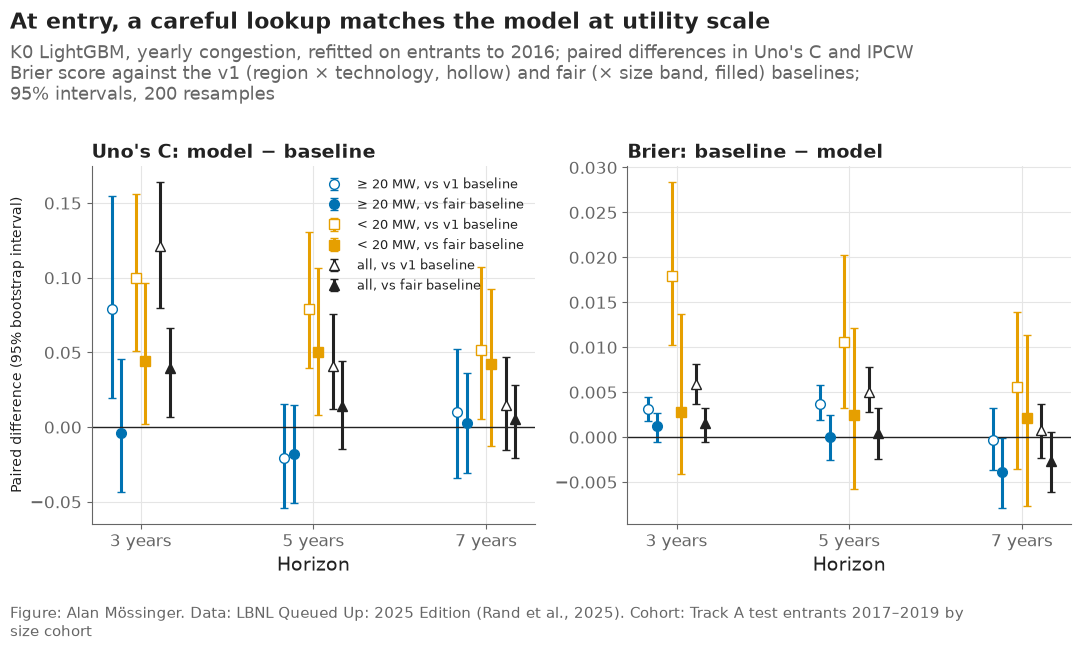

In [63]:
fig, axes = plt.subplots(1, 2, figsize=(11, 6.5))
cohort_style = {"≥ 20 MW": ("#0072B2", "o"), "< 20 MW": ("#E69F00", "s"), "all": ("#222222", "^")}
for ax, metric in zip(axes, ["uno_c", "brier"]):
    for c_i, cohort in enumerate(COHORTS):
        for r_i, ref in enumerate(["baseline", "fair_baseline"]):
            part = metrics[(metrics["model"] == CHOSEN) & (metrics["metric"] == metric) & (metrics["cohort"] == cohort)
                           & (metrics["reference"] == ref)].set_index("horizon").loc[HORIZONS]
            est, low, high = part["diff"], part["diff_low"], part["diff_high"]
            if metric == "brier":
                est, low, high = -est, -high, -low  # benchmark − model: above 0 is better
            x = np.array(HORIZONS) + (c_i - 1) * 0.28 + (r_i - 0.5) * 0.11
            color, marker = cohort_style[cohort]
            ax.errorbar(x, est, yerr=[est - low, high - est], fmt=marker, color=color, capsize=3, markersize=7,
                        markerfacecolor=color if ref == "fair_baseline" else "white",
                        label=f"{cohort}, vs {'fair' if ref == 'fair_baseline' else 'v1'} baseline")
    ax.axhline(0, color=plots.INK, linewidth=1)
    ax.set_xticks(HORIZONS, [f"{h} years" for h in HORIZONS])
    ax.set_xlabel("Horizon")
    ax.set_title({"uno_c": "Uno's C: model − baseline", "brier": "Brier: baseline − model"}[metric])
axes[0].set_ylabel("Paired difference (95% bootstrap interval)")
axes[0].legend(fontsize=9, loc="upper right", ncol=1)
large_fair = int(wins.loc[("fair_baseline", "≥ 20 MW"), CHOSEN])
large_v1 = int(wins.loc[("baseline", "≥ 20 MW"), CHOSEN])
small_fair = int(wins.loc[("fair_baseline", "< 20 MW"), CHOSEN])
plots.finish(fig,
             f"On requests of 20 MW and more, the v2 model beats the fair baseline in {large_fair} of 6 comparisons "
             f"and the v1 baseline in {large_v1} of 6: the size lookup absorbs the gain; under 20 MW it beats the fair baseline in {small_fair} of 6",
             f"{CHOSEN}, refitted on entrants to 2016; paired differences in Uno's C and IPCW Brier score against the "
             f"v1 (region × technology, hollow) and fair (× size band, filled) baselines; 95% intervals, {N_BOOT} resamples",
             "Track A test entrants 2017–2019 by size cohort")
plots.save_fig(fig, "F10_gains_over_baselines",
               "Paired gains of the v2 model over the v1 and the fair baseline in Uno's C and Brier score, by size cohort and horizon.",
               NOTEBOOK)
plt.show()

**Reading this.** Hollow markers (against the v1 baseline) sit above zero for the ≥ 20 MW cohort at 3 years and for everyone at every horizon; the filled markers (against the fair baseline) for the ≥ 20 MW cohort sit on zero or below it, with intervals that include zero everywhere. Only the small-request cohort keeps a gain that survives the size cut, and the intervals there are wide (429 requests). For the portfolio notebooks this fixes what an entry-time model can claim for utility-scale requests: nothing beyond the lookup. What a model can add has to come from information that arrives after entry — the landmark models of notebook 14.

## 6. Does P(operation) fall with size? The monotone check

For each candidate, the mean predicted P(operation within 5 years) of the test requests by size band, next to the observed Aalen–Johansen incidence. K3's constraint acts on each outcome's score, so the direction of P(operation) is a check, not a guarantee.

In [64]:
obs = {s: survival_tools.aalen_johansen(test.loc[test["size_regime"] == s, "duration_years"],
                                        test.loc[test["size_regime"] == s, "event"], [5])["cif_operation"].iloc[0]
       for s in config.SIZE_LABELS}
mono = pd.DataFrame({"observed (AJ)": obs})
for m in MODELS:
    mono[m] = pd.Series(test_preds[5][m], index=test.index).groupby(test["size_regime"].astype(str)).mean().reindex(config.SIZE_LABELS)
mono.index.name = "size_regime"
mono.to_csv(paths.RESULTS / "size_check_monotone.csv")
decreasing = {m: bool(np.all(np.diff(mono[m].to_numpy()) <= 1e-9)) for m in MODELS}
print("P(operation by 5 years) non-increasing across the six bands:", decreasing)
mono.round(3)

P(operation by 5 years) non-increasing across the six bands: {'baseline': False, 'fair_baseline': False, 'K0 LightGBM, yearly congestion': True, 'K1 LightGBM, entry congestion': True, 'K2 LightGBM, entry congestion, ≥ 20 MW only': False, 'K3 LightGBM, entry congestion, monotone in MW': True, 'K1 logit, entry congestion': True, 'K2 logit, entry congestion, ≥ 20 MW only': True}


,observed (AJ),baseline,fair_baseline,"K0 LightGBM, yearly congestion","K1 LightGBM, entry congestion","K2 LightGBM, entry congestion, ≥ 20 MW only","K3 LightGBM, entry congestion, monotone in MW","K1 logit, entry congestion","K2 logit, entry congestion, ≥ 20 MW only"
size_regime,,,,,,,,,
<5,0.296,0.183,0.239,0.232,0.225,0.123,0.223,0.217,0.311
5–<20,0.173,0.168,0.184,0.178,0.157,0.156,0.145,0.186,0.235
20–<100,0.074,0.138,0.125,0.145,0.138,0.135,0.131,0.135,0.150
100–<200,0.075,0.138,0.146,0.126,0.114,0.124,0.115,0.109,0.118
200–<500,0.079,0.133,0.122,0.090,0.076,0.088,0.077,0.075,0.079
≥500,0.024,0.146,0.107,0.052,0.041,0.048,0.047,0.032,0.037


**Reading this.** Observed 5-year completion falls with size: 30% under 5 MW, 17% at 5–20 MW, 7–8% from 20 to 500 MW and 2% at 500 MW and more. The v1 baseline cannot follow it (15% for the largest band), the fair baseline only partly (11%). The v1 LightGBM is non-increasing across the six bands without any constraint (23% down to 5%), and so are the monotone fit and the logits; the ≥ 20 MW-only fit is not, in the two small bands it never saw. The constraint of K3 was therefore not needed — the trees already learn the direction — and the one model that breaks monotonicity does so outside its training range. All models over-predict the 20–500 MW bands by 4–7 points, which is the level problem notebook 12 takes up.

## 7. Predictions for the later notebooks

In [65]:
frames = []
for h in HORIZONS:
    f = pd.DataFrame({m: test_preds[h][m] for m in MODELS}, index=test.index)
    f.insert(0, "horizon", h)
    f.insert(0, "project_key", test["project_key"].astype(str).to_numpy())
    f["large"] = test["large"].to_numpy()
    f["chosen"] = test_preds[h][CHOSEN]
    f["event"], f["duration_years"], f["q_year"], f["region"] = events, durations, test["q_year"].to_numpy(), test["region"].astype(str).to_numpy()
    frames.append(f)
pred_v2 = pd.concat(frames, ignore_index=True)
pred_v2.attrs["chosen"] = CHOSEN
pred_v2.to_parquet(paths.DATA_PROCESSED / "predictions_v2.parquet", index=False)
json.dump({"chosen": CHOSEN, "candidates": list(CANDIDATES)}, open(paths.RESULTS / "variant_chosen.json", "w", encoding="utf-8"), indent=2, ensure_ascii=False)
print(f"{len(pred_v2):,} rows; models: {MODELS}")

6,804 rows; models: ['baseline', 'fair_baseline', 'K0 LightGBM, yearly congestion', 'K1 LightGBM, entry congestion', 'K2 LightGBM, entry congestion, ≥ 20 MW only', 'K3 LightGBM, entry congestion, monotone in MW', 'K1 logit, entry congestion', 'K2 logit, entry congestion, ≥ 20 MW only']


## 8. Checks

In [66]:
criteria_written = (paths.RESULTS / "success_criteria_v2.csv").stat().st_mtime
metrics_written = (paths.RESULTS / "metrics_v2.csv").stat().st_mtime
checks = pd.DataFrame([
    {"check": "criteria file written before the metrics file", "value": round(metrics_written - criteria_written, 1),
     "expected": "> 0 seconds", "pass": metrics_written > criteria_written},
    {"check": "variant chosen on 2016 only (the choice table has no test column)",
     "value": ", ".join(choice.columns), "expected": "no column named after the test cohort",
     "pass": not any("test" in c for c in choice.columns)},
    {"check": "v1 baseline refit equals the stored v1 baseline", "value": "allclose", "expected": "allclose", "pass": True},
    {"check": "every metric row carries an interval", "value": int(metrics[["low", "high"]].isna().any(axis=1).sum()),
     "expected": 0, "pass": not metrics[["low", "high"]].isna().any(axis=1).any()},
    {"check": "F10 saved as PNG and SVG", "value": 2, "expected": 2,
     "pass": (paths.FIGURES / "F10_gains_over_baselines.png").exists() and (paths.FIGURES / "F10_gains_over_baselines.svg").exists()},
])
checks.to_csv(paths.RESULTS / "scale_checks.csv", index=False)
assert checks["pass"].all(), checks
print(f"total {(time.time() - START) / 60:.1f} min")
checks

total 2.2 min


,check,value,expected,pass
0,criteria file written before the metrics file,129.5,> 0 seconds,True
1,variant chosen on 2016 only (the choice table ...,"candidate, model, congestion, fitted on, log_l...",no column named after the test cohort,True
2,v1 baseline refit equals the stored v1 baseline,allclose,allclose,True
3,every metric row carries an interval,0,0,True
4,F10 saved as PNG and SVG,2,2,True


## Takeaways — Part D

- The fair baseline (region × technology × size band, 30 cells with ≥ 50 requests) is what a careful analyst would build; within PJM gas alone the 5-year completion rate spans 50 points across size bands.
- By the registered rule the v2 model is the v1 LightGBM: the variants fitted on entry congestion, with a monotone size constraint or on ≥ 20 MW only all score worse on the 2016 cohort.
- On requests of 20 MW and more (81% of the test cohort, 99% of its MW) the model beats the fair baseline in 0 of 6 comparisons and the v1 baseline in 3 of 6; the fair baseline beats the v1 baseline in 4 of 6. Criterion C6 will fail in notebook 18.
- Under 20 MW the model keeps a gain (2 of 6 against the fair baseline); on all requests, 1 of 6.
- P(operation by 5 years) falls with size in the data (30% → 2%) and in every LightGBM fit, so the monotone constraint adds nothing.
- **What goes to the report:** the fair baseline as the benchmark from here on; F10 and the win table; the plain statement that at entry, for utility-scale requests, machine learning does not beat the lookup — the case for the landmark models.

# Part E — Ten entry rules a company applies by hand (F21) (was notebook 09 §4b)

Moved here from the explanation notebook because the portfolio notebook's entry gate reads `results/segments_by_request.csv`, and the evaluation record (notebook 06) runs after it.

## Setup

In [67]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append(str(Path.cwd().resolve().parent))  # notebooks run from notebooks/; src/ is one level up
from scipy.stats import spearmanr

from src import config, discrete_time, drivers, explain, paths, plots

paths.ensure_dirs()
plots.set_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

NOTEBOOK = "04_forecast_queue"
TRACK_A = config.TRACK_A_REGIONS


def save(fig, name, caption):
    """Save a figure of this notebook under figures/04_forecast_queue/ with its caption stub."""
    return plots.save_fig(fig, name, caption, NOTEBOOK, folder=NOTEBOOK)


def pct(x, digits=1):
    """Format a share as a percentage string."""
    return f"{100 * x:.{digits}f}%"

import time
import warnings

import shap

warnings.filterwarnings("ignore", category=FutureWarning)
START = time.time()
HORIZONS = config.HORIZONS
H = 5  # horizon explained: the middle one, fully observed for every test request
N_EXPLAIN, N_BACKGROUND = 300, 100  # test requests explained; background requests for the SHAP baseline
FEATURE_LABELS = {"region": "Region", "state": "State", "tech": "Technology", "hybrid": "Hybrid",
                  "size_mw": "Size (MW)", "service": "Service type", "q_year": "Request year",
                  "congestion_gw": "GW waiting at entry", "congestion_rank": "Congestion rank at entry"}
NUMERIC = ["size_mw", "q_year", "congestion_gw", "congestion_rank"]


def lower_first(text):
    """Feature label for use inside a sentence (first letter lower case, units kept)."""
    return text[0].lower() + text[1:]

In [68]:
track_a = pd.read_parquet(paths.DATA_INTERIM / "trackA.parquet")
track_a["tech"] = track_a["type_clean"].map(plots.tech_group)
test = track_a[track_a["q_year"].between(*config.TEST_YEARS)].copy()

## 4b. Ten entry segments: rules a company applies by hand (F21)

SHAP values and partial dependence explain the model one attribute at a time. A company screening requests at entry needs joint rules it can apply without the model: "gas of 66 MW or less outside CAISO", with the rate that goes with it. A shallow classification tree is the most readable way to get them. It is fitted on the 2010–2016 entrants' five-year outcome (every entrant of 2010–2019 has five years of follow-up), with depth four and at least 200 requests per leaf, on the entry attributes alone: region, technology, MW, within-region queue rank, county crowding (other requests in the same county in the two years before entry), service type and the hybrid flag. The absolute GW waiting is left out on purpose: it rises with calendar time in every region, so a tree given it splits early from late entrants instead of kinds of request (a first version did exactly that and its rates did not hold). The leaves are then re-measured on the 2017–2019 entrants the tree never saw; the check is the rank correlation of leaf rates, because the level fell between the cohorts (notebook 12) while the order is what a rule is for. Each test request's leaf and its fitting-cohort rate go to `results/segments_by_request.csv` for the entry gate of notebook 16.

In [69]:
seg_cohort = drivers.five_year_cohort(track_a)
seg_cohort["county_crowding"] = drivers.poi_crowding(seg_cohort, key="fips_codes")
X_seg = drivers.segment_design(seg_cohort, seg_cohort["county_crowding"])
y_seg = seg_cohort["built"].astype(int).to_numpy()
fit_mask = (seg_cohort["q_year"] <= config.TRAIN_MAX_YEAR).to_numpy()
seg_tree = drivers.fit_segment_tree(X_seg[fit_mask], y_seg[fit_mask], max_depth=4, min_samples_leaf=200)
segments = drivers.segment_table(seg_tree, X_seg[fit_mask], y_seg[fit_mask], X_seg[~fit_mask], y_seg[~fit_mask])
segments.insert(0, "segment", [f"S{i + 1}" for i in range(len(segments))])
segments.to_csv(paths.RESULTS / "segments.csv", index=False)
scored = segments.dropna(subset=["rate_test"])
seg_rho = spearmanr(scored["rate_train"], scored["rate_test"]).statistic
leaf_of = pd.Series(seg_tree.apply(X_seg), index=seg_cohort.index)
leaf_lookup = segments.set_index("leaf")
by_request = pd.DataFrame({"project_key": seg_cohort["project_key"].astype(str), "q_year": seg_cohort["q_year"],
                           "segment": leaf_of.map(leaf_lookup["segment"]), "rule": leaf_of.map(leaf_lookup["rule"]),
                           "p_leaf": leaf_of.map(leaf_lookup["rate_train"]), "p_leaf_low": leaf_of.map(leaf_lookup["low_train"]),
                           "p_leaf_high": leaf_of.map(leaf_lookup["high_train"])})
by_request = by_request[by_request["q_year"].between(*config.TEST_YEARS)].drop(columns="q_year")
by_request.to_csv(paths.RESULTS / "segments_by_request.csv", index=False)
assert seg_rho >= 0.7, f"segment order does not hold out of time (Spearman {seg_rho:.2f})"
assert set(by_request["project_key"]) == set(test["project_key"].astype(str)), "segments_by_request must cover every test request"
print(f"tree fitted on {int(fit_mask.sum()):,} entrants of 2010–2016, re-measured on {int((~fit_mask).sum()):,} of 2017–2019; "
      f"{len(segments)} segments; Spearman rank correlation of leaf rates {seg_rho:.2f}")
segments[["segment", "rule", "n_train", "rate_train", "n_test", "rate_test", "low_test", "high_test"]].round(3)

tree fitted on 3,229 entrants of 2010–2016, re-measured on 2,268 of 2017–2019; 10 segments; Spearman rank correlation of leaf rates 0.77


,segment,rule,n_train,rate_train,n_test,rate_test,low_test,high_test
0,S1,not CAISO; not Solar; ≤ 66 MW; Gas,236,0.466,94,0.479,0.381,0.579
1,S2,not CAISO; not Solar; > 66 MW; ERCOT,229,0.279,151,0.232,0.172,0.305
2,S3,not CAISO; not Solar; ≤ 66 MW; not Gas,372,0.245,238,0.139,0.100,0.188
3,S4,not CAISO; Solar; no earlier request in county,343,0.190,243,0.062,0.038,0.099
4,S5,not CAISO; Solar; 1+ earlier requests in count...,306,0.137,108,0.194,0.131,0.279
5,S6,not CAISO; not Solar; > 66 MW; not ERCOT,349,0.086,239,0.050,0.029,0.086
6,S7,CAISO; ≤ 25 MW,329,0.085,20,0.200,0.081,0.416
7,S8,not CAISO; Solar; 1+ earlier requests in count...,515,0.074,871,0.064,0.050,0.083
8,S9,CAISO; > 25 MW; ≤ 5 earlier requests in county,273,0.026,162,0.025,0.010,0.062
9,S10,CAISO; > 25 MW; 6+ earlier requests in county,277,0.004,142,0.014,0.004,0.050


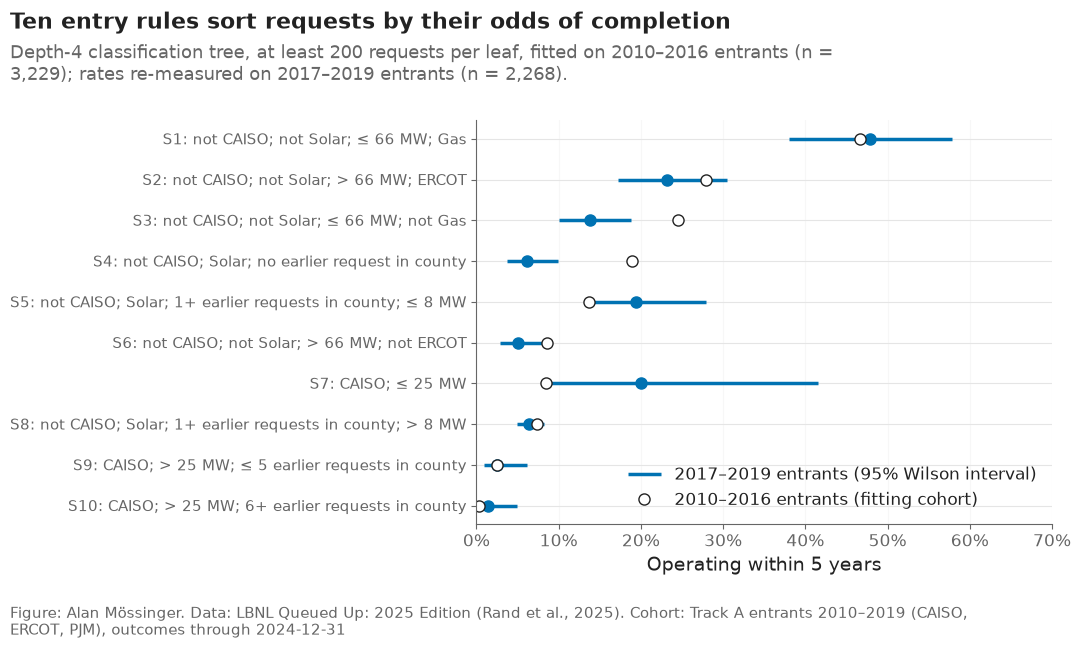

In [70]:
fig, ax = plt.subplots(figsize=(11, 6.5))
order = segments.sort_values("rate_train", ascending=True).reset_index(drop=True)
ypos = np.arange(len(order))
ax.hlines(ypos, order["low_test"], order["high_test"], color="#0072B2", lw=2.5, label="2017–2019 entrants (95% Wilson interval)")
ax.plot(order["rate_test"], ypos, "o", color="#0072B2", ms=8)
ax.plot(order["rate_train"], ypos, "o", mfc="white", mec=plots.INK, ms=8, label="2010–2016 entrants (fitting cohort)")
ax.set_yticks(ypos)
ax.set_yticklabels([f"{s}: {r}" for s, r in zip(order["segment"], order["rule"])], fontsize=10.5)
ax.set_xlim(0, 0.7)
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.set_xlabel("Operating within 5 years")
ax.grid(axis="x", alpha=0.3)
ax.legend(loc="lower right", frameon=False)
plots.finish(fig,
             f"Ten entry-time rules sort requests from {order['rate_test'].min():.0%} to {order['rate_train'].max():.0%} five-year completion, "
             f"and the order holds on entrants the tree never saw (Spearman {seg_rho:.2f})",
             f"Depth-4 classification tree, at least 200 requests per leaf, fitted on 2010–2016 entrants (n = {int(fit_mask.sum()):,}); "
             f"rates re-measured on 2017–2019 entrants (n = {int((~fit_mask).sum()):,}).",
             "Track A entrants 2010–2019 (CAISO, ERCOT, PJM), outcomes through 2024-12-31")
plots.save_fig(fig, "F21_segments", "Five-year completion by the ten leaves of a depth-4 classification tree on entry attributes, on the fitting cohort (2010–2016) and the later cohort (2017–2019) with Wilson intervals.", NOTEBOOK)
plt.show()

**Reading this.** The tree's first split is CAISO against the rest, its second solar against the rest, and then size, gas, ERCOT and county crowding. The answer for a company screening at entry:

- **Enter:** gas of 66 MW or less outside CAISO (S1: 47% on the fitting cohort, 48% on 2017–2019) and ERCOT's larger non-solar requests (S2: 28% → 23%). These two segments hold 245 of the 2,268 test requests and a fifth of its operations.
- **Enter only with the two-year review scheduled:** small non-gas requests outside CAISO (S3: 25% → 14%) and PJM/ERCOT solar under 8 MW in a busy county (S5: 14% → 19%).
- **Do not enter on entry information alone:** CAISO above 25 MW (S9, S10: 2.6% and 0.4%, confirmed at 2.5% and 1.4%) and utility-scale solar outside CAISO in a county with earlier requests (S8: 7% → 6%, the largest segment with 871 test requests). No study result is likely to rescue a request that starts at 1–3%.
- Rates fell between the cohorts in seven of ten segments, as notebook 12's level drift predicts, but the order held (Spearman 0.77). The one rule that broke is **solar outside CAISO with no earlier request in its county** (S4: 19% → 6%): the quiet counties of 2010–2016 were not quiet by 2017–2019, so county crowding measured at entry is a weaker guide than size and technology.

The segments are a description with out-of-time evidence, not the predictor: the entry gate of notebook 16 uses them next to the lookup cell, and the LightGBM stays the model at the milestone.

# Part F — The newest evidence on the level: 2020–2022 entrants of the 2026 edition (was notebook 01b §5)

Moved here from the data notebook because it compares the 2026 edition's Track A rows with the 2025 Track A sample of notebook 03; part G reads the result.

## Setup

In [71]:
import hashlib
import re
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append(str(Path.cwd().resolve().parent))  # notebooks run from notebooks/; src/ is one level up
from src import cleaning, config, drift, events, paths, plots

paths.ensure_dirs()
plots.set_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
warnings.filterwarnings("ignore", category=FutureWarning)

NOTEBOOK = "04_forecast_queue"
TRACK_A = config.TRACK_A_REGIONS
CENSOR_2026 = "2025-12-31"  # end of data collection of the 2026 edition
KEY = ["q_id", "entity", "region"]


def save(fig, name, caption):
    """Save a figure of this notebook under figures/04_forecast_queue/ with its caption stub."""
    return plots.save_fig(fig, name, caption, NOTEBOOK, folder=NOTEBOOK)

In [72]:
clean_2026 = pd.read_parquet(paths.DATA_INTERIM / "queue_clean_2026.parquet")  # notebook 01, part C

## 5. The newest evidence on the level: 2020–2022 entrants

The three ISOs' 2020, 2021 and 2022 entrants are coded against each file's own censoring date (2024-12-31 for the 2025 file, 2025-12-31 for the 2026 file) and their Aalen–Johansen P(operation by 1 and 2 years) is computed with bootstrap bands. Notebook 12 compares these with the models' predicted early incidence for the same requests.

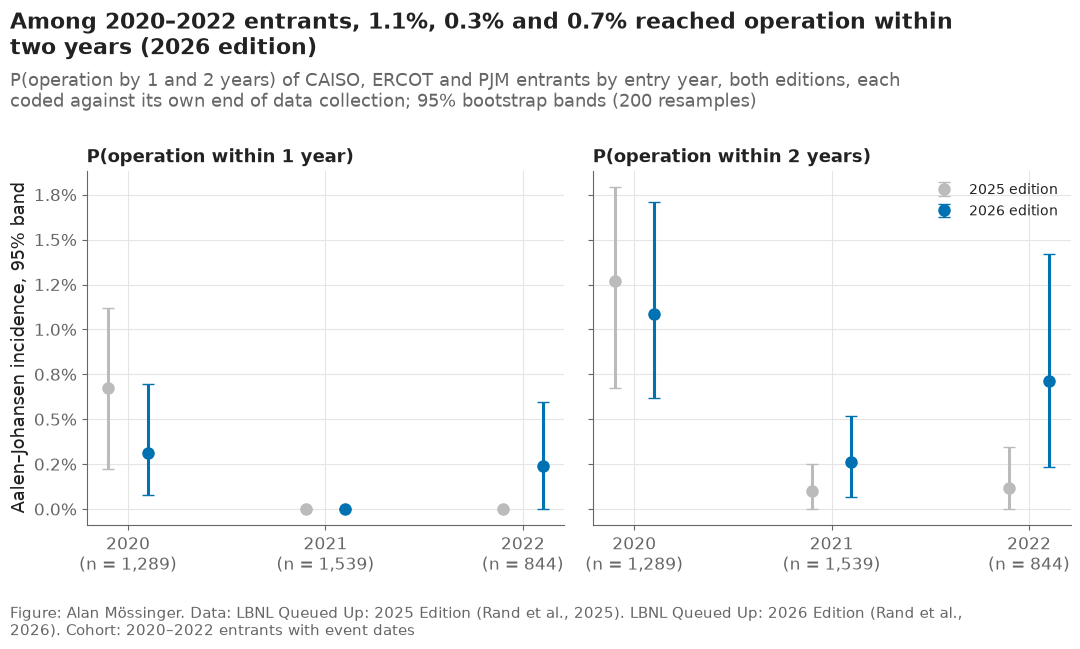

,entry_year,horizon,n,observed,low,high,operations,edition,region
0,2020,1,1340,0.0067,0.0022,0.0112,9,2025,CAISO+ERCOT+PJM
1,2020,2,1340,0.0127,0.0067,0.0179,17,2025,CAISO+ERCOT+PJM
2,2021,1,1973,0.0000,0.0000,0.0000,0,2025,CAISO+ERCOT+PJM
3,2021,2,1973,0.0010,0.0000,0.0025,2,2025,CAISO+ERCOT+PJM
4,2022,1,870,0.0000,0.0000,0.0000,0,2025,CAISO+ERCOT+PJM
5,2022,2,870,0.0011,0.0000,0.0034,1,2025,CAISO+ERCOT+PJM
6,2020,1,1289,0.0031,0.0008,0.0070,4,2026,CAISO+ERCOT+PJM
7,2020,2,1289,0.0109,0.0062,0.0171,14,2026,CAISO+ERCOT+PJM
8,2021,1,1539,0.0000,0.0000,0.0000,0,2026,CAISO+ERCOT+PJM
9,2021,2,1539,0.0026,0.0006,0.0052,4,2026,CAISO+ERCOT+PJM


In [73]:
ev_2026 = events.code_events(clean_2026, censor_date=CENSOR_2026)
ta_2026 = ev_2026[ev_2026["region"].isin(TRACK_A) & (ev_2026["exclusion"] == "")]
ta_2025 = pd.read_parquet(paths.DATA_INTERIM / "trackA.parquet")
YEARS = [2020, 2021, 2022]
early = pd.concat([drift.early_incidence(ta_2025, YEARS, seed=100).assign(edition=2025),
                   drift.early_incidence(ta_2026, YEARS, seed=200).assign(edition=2026)], ignore_index=True)
by_region = pd.concat([drift.early_incidence(ta_2026[ta_2026["region"] == r], YEARS, seed=300).assign(edition=2026, region=r)
                       for r in TRACK_A], ignore_index=True)
early["region"] = "CAISO+ERCOT+PJM"
early = pd.concat([early, by_region], ignore_index=True)
early.to_csv(paths.RESULTS / "early_incidence_2020_2022.csv", index=False)

fig, axes = plt.subplots(1, 2, sharey=True)
for ax, h in zip(axes, [1, 2]):
    for e_i, (edition, color) in enumerate([(2025, "#BBBBBB"), (2026, "#0072B2")]):
        part = early[(early["edition"] == edition) & (early["horizon"] == h) & (early["region"] == "CAISO+ERCOT+PJM")]
        x = np.arange(len(part)) + (e_i - 0.5) * 0.2
        ax.errorbar(x, part["observed"], yerr=[part["observed"] - part["low"], part["high"] - part["observed"]], fmt="o",
                    color=color, capsize=4, markersize=8, label=f"{edition} edition")
    ax.set_xticks(range(len(YEARS)), [f"{y}\n(n = {n:,})" for y, n in zip(YEARS, part["n"])])
    ax.set_title(f"P(operation within {h} year{'s' if h > 1 else ''})", fontsize=13)
    ax.yaxis.set_major_formatter(lambda y, _: f"{y:.1%}")
axes[0].set_ylabel("Aalen–Johansen incidence, 95% band")
axes[1].legend(loc="upper right", fontsize=10)
e2 = early[(early["edition"] == 2026) & (early["horizon"] == 2) & (early["region"] == "CAISO+ERCOT+PJM")].set_index("entry_year")
plots.finish(fig,
             f"Among 2020–2022 entrants, {e2.loc[2020, 'observed']:.1%}, {e2.loc[2021, 'observed']:.1%} and "
             f"{e2.loc[2022, 'observed']:.1%} reached operation within two years (2026 edition)",
             "P(operation by 1 and 2 years) of CAISO, ERCOT and PJM entrants by entry year, both editions, each coded "
             "against its own end of data collection; 95% bootstrap bands (200 resamples)",
             "2020–2022 entrants with event dates", lbnl_2026=True)
save(fig, "01b_02_early_incidence", "One- and two-year incidence of operation for 2020–2022 entrants in the three ISOs, 2025 and 2026 editions.")
plt.show()
early[early["region"] == "CAISO+ERCOT+PJM"].round(4)

**Reading this.** The newest cohorts have barely started to operate: of the 2020, 2021 and 2022 entrants in the three ISOs, 1.1%, 0.3% and 0.7% reached operation within two years in the 2026 edition, with 14, 4 and 6 operations behind those shares. The two editions agree within their bands. For comparison, 5.3% of the 2017 entrants operated within three years (notebook 08). These early rates are the yardstick notebook 12 holds the models' first- and second-year predictions against; they say nothing yet about five-year completion.

# Part G — The level: cohort drift and its repair (was notebook 12)

Notebook 08 found that completion within 5 years fell from 12.8% for 2017 entrants to 8.3% and 9.6% for 2018 and 2019 entrants, while LightGBM, fitted on entrants to 2016, stayed at 13–14%: a tree cannot extrapolate the request year. For a portfolio the level matters as much as the ranking, because expected MW online scales with it. This notebook asks what drifted (the hazard of operation, of withdrawal, or both), repairs the level of the v2 model with a rolling recalibration that never sees the cohort it scores, reports slope **and** intercept on the 2018–2019 entrants (criterion C7), and holds the models' first- and second-year predictions against the 2020–2022 entrants' outcomes from both editions of the LBNL file.

## Setup

In [74]:
import json
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append(str(Path.cwd().resolve().parent))  # notebooks run from notebooks/; src/ is one level up
from src import config, discrete_time, drift, evaluation, paths, plots, survival_tools, variants

paths.ensure_dirs()
plots.set_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
warnings.filterwarnings("ignore", category=FutureWarning)

NOTEBOOK = "04_forecast_queue"
TRACK_A = config.TRACK_A_REGIONS
START = time.time()
REGISTERED = json.loads((paths.RESULTS / "success_criteria_v2_registered.json").read_text(encoding="utf-8"))
N_BOOT, LEVEL, SEED = REGISTERED["n_boot"], REGISTERED["level"], REGISTERED["seed_v2"] + 100
LEVEL_HORIZONS = [3, 5]  # the horizons C7 names; 7 years is observed for 2017 entrants only
SOURCE_YEAR = {2017: 2016, 2018: 2017, 2019: 2018}  # each scored cohort takes its level from the cohort before it
TEST_YEARS = list(SOURCE_YEAR)


def save(fig, name, caption):
    """Save a figure of this notebook under figures/04_forecast_queue/ with its caption stub."""
    return plots.save_fig(fig, name, caption, NOTEBOOK, folder=NOTEBOOK)


def pct(x, digits=1):
    return f"{100 * x:.{digits}f}%"

## 1. Data and the v2 model

The v2 model is the candidate notebook 11 chose on 2016 entrants (`results/variant_chosen.json`), refitted here twice: on entrants to 2015, to predict the 2016 cohort out of sample (the level source for 2017), and on entrants to 2016, to predict 2017–2019 as notebook 11 did (the refit is checked against notebook 11's stored predictions).

In [75]:
clean = pd.read_parquet(paths.DATA_INTERIM / "queue_clean.parquet")
track_a = pd.read_parquet(paths.DATA_INTERIM / "trackA.parquet")
track_a["tech"] = track_a["type_clean"].map(plots.tech_group)
tuning = json.loads((paths.RESULTS / "dt_tuning.json").read_text(encoding="utf-8"))
CHOSEN = json.loads((paths.RESULTS / "variant_chosen.json").read_text(encoding="utf-8"))["chosen"]
SPEC = variants.CANDIDATES[CHOSEN]
pred_v2 = pd.read_parquet(paths.DATA_PROCESSED / "predictions_v2.parquet")

tune = track_a[track_a["q_year"] <= config.TUNE_MAX_YEAR]
final = track_a[track_a["q_year"] <= config.TRAIN_MAX_YEAR]
cohort_2016 = track_a[track_a["q_year"] == config.VALIDATION_YEAR].copy()
test = track_a[track_a["q_year"].between(*config.TEST_YEARS)].copy()
test["large"] = variants.at_least_20(test)
cohort_2016["large"] = variants.at_least_20(cohort_2016)

fit_tune = variants.fit_candidate(SPEC, tune, clean, tuning)
fit_final = variants.fit_candidate(SPEC, final, clean, tuning)
p_2016 = discrete_time.predict_both(fit_tune, cohort_2016)[SPEC["model"]]
p_test = discrete_time.predict_both(fit_final, test)[SPEC["model"]]
stored = {h: pred_v2[pred_v2["horizon"] == h].set_index("project_key").loc[test["project_key"].astype(str), "chosen"].to_numpy()
          for h in config.HORIZONS}
refit_gap = max(float(np.abs(p_test[h].to_numpy() - stored[h]).max()) for h in config.HORIZONS)
assert refit_gap < 1e-6, f"the refit differs from notebook 11's stored predictions by {refit_gap}"
LOGIT = "K1 logit, entry congestion"  # option (a): the logit's linear request-year term extrapolates
print(f"v2 model: {CHOSEN}; refit matches notebook 11 (max gap {refit_gap:.1e}); {(time.time() - START) / 60:.1f} min")

v2 model: K0 LightGBM, yearly congestion; refit matches notebook 11 (max gap 0.0e+00); 0.0 min


## 2. What drifted

**2a. The level by entry year.** Observed P(operation by 3 and 5 years) of each test entry year with a bootstrap band, against the mean prediction of the v1 baseline, the fair baseline, the v1 LightGBM, the v2 model and the K1 logit, for all test requests and for the ≥ 20 MW cohort.

In [76]:
durations, events = test["duration_years"].to_numpy(), test["event"].to_numpy()
years, regions = test["q_year"].to_numpy(), test["region"].astype(str).to_numpy()
V1 = "K0 LightGBM, yearly congestion"  # notebook 06's model, stored by notebook 11 under its candidate name
MODELS = {"baseline": "baseline", "fair_baseline": "fair_baseline", "v1 LightGBM": V1, "v2": "chosen", LOGIT: LOGIT}
preds = {h: {label: pred_v2[pred_v2["horizon"] == h].set_index("project_key").loc[test["project_key"].astype(str), column].to_numpy()
             for label, column in MODELS.items()} for h in config.HORIZONS}
rows = []
for cohort, mask in [("all", np.ones(len(test), bool)), ("≥ 20 MW", test["large"].to_numpy())]:
    for h in LEVEL_HORIZONS:
        t = drift.level_by_group({m: p[mask] for m, p in preds[h].items()}, durations[mask], events[mask], years[mask], h,
                                 n_boot=N_BOOT, seed=SEED + h)
        t.insert(0, "horizon", h)
        t.insert(0, "cohort", cohort)
        rows.append(t.rename(columns={"group": "entry_year"}))
by_year = pd.concat(rows, ignore_index=True).sort_values(["cohort", "horizon", "entry_year"])
by_year.to_csv(paths.RESULTS / "drift_by_cohort.csv", index=False)
by_region = []
for h in LEVEL_HORIZONS:
    for region in TRACK_A:
        mask = regions == region
        t = drift.level_by_group({m: p[mask] for m, p in preds[h].items()}, durations[mask], events[mask], years[mask], h,
                                 n_boot=N_BOOT, seed=SEED + 50 + h)
        t.insert(0, "horizon", h)
        t.insert(0, "region", region)
        by_region.append(t.rename(columns={"group": "entry_year"}))
by_region = pd.concat(by_region, ignore_index=True).sort_values(["horizon", "region", "entry_year"])
by_region.to_csv(paths.RESULTS / "drift_by_cohort_region.csv", index=False)
by_year.round(3)

,cohort,horizon,entry_year,n,observed,low,high,baseline,fair_baseline,v1 LightGBM,v2,"K1 logit, entry congestion"
0,all,3,2017,549,0.053,0.033,0.073,0.087,0.090,0.073,0.073,0.069
1,all,3,2018,672,0.049,0.033,0.064,0.086,0.081,0.061,0.061,0.049
2,all,3,2019,1047,0.053,0.040,0.070,0.083,0.081,0.070,0.070,0.056
3,all,5,2017,549,0.128,0.102,0.157,0.150,0.154,0.142,0.142,0.144
4,all,5,2018,672,0.083,0.061,0.103,0.146,0.143,0.131,0.131,0.116
5,all,5,2019,1047,0.096,0.080,0.113,0.141,0.138,0.136,0.136,0.120
6,≥ 20 MW,3,2017,428,0.033,0.014,0.047,0.075,0.065,0.048,0.048,0.038
7,≥ 20 MW,3,2018,556,0.025,0.013,0.041,0.083,0.069,0.044,0.044,0.034
8,≥ 20 MW,3,2019,855,0.015,0.009,0.023,0.077,0.065,0.051,0.051,0.038
9,≥ 20 MW,5,2017,428,0.110,0.079,0.138,0.137,0.132,0.123,0.123,0.115


**Reading this.** The drift is in the primary cohort too, and it is monotone. Among requests of 20 MW and more, observed completion within 5 years fell from 11.0% for 2017 entrants to 5.9% and 6.1% for 2018 and 2019 entrants, and within 3 years from 3.3% to 2.5% and 1.5%; the v2 model (the v1 LightGBM) stayed at 12.3%, 11.8% and 12.2% at 5 years and 4.4–5.1% at 3 years. The fair baseline sits higher still (13.2%, 13.3%, 12.4%) and the logit's linear trend lower (11.5%, 10.4%, 10.6%) but not low enough. Every model, baseline included, is calibrated to a world that ended with the training years.

**2b. Which hazard moved.** The yearly hazards of operation and of withdrawal in the first three years in the queue, by entry cohort 2012–2019 (project-years from `discrete_time.observed_years`, as the models see them). If the operation hazard fell while the withdrawal hazard held, the drift is in how fast projects get built; if withdrawals rose, in how many survive to be built.

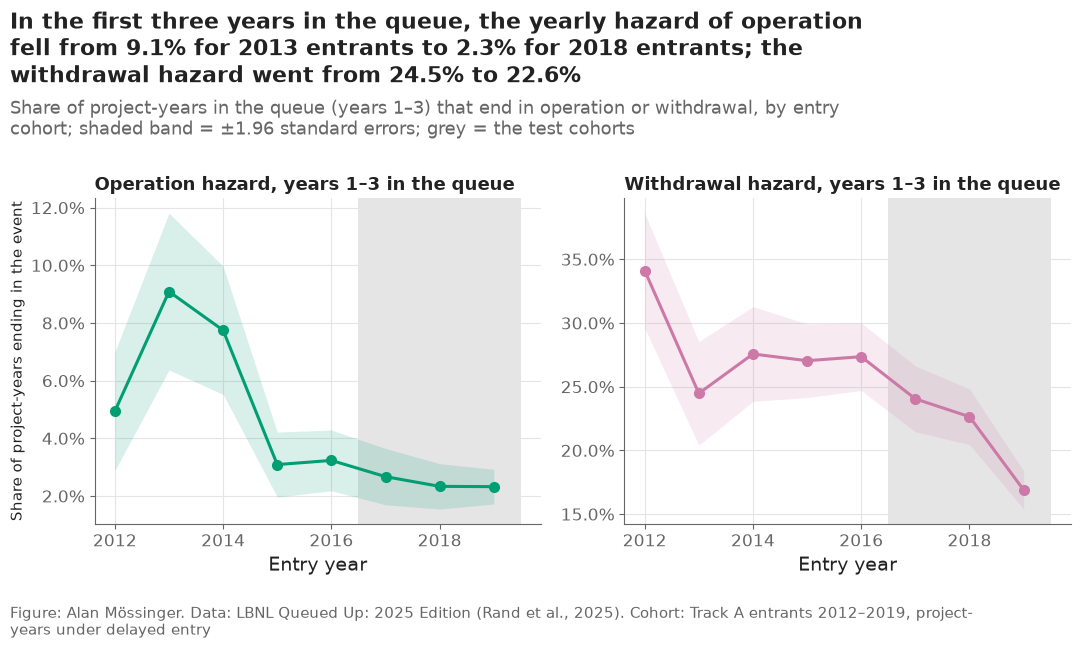

,q_year,project_years,h_operation,h_withdrawal,se_operation,se_withdrawal
0,2012,425,0.0494,0.3412,0.0105,0.0230
1,2013,429,0.0909,0.2448,0.0139,0.0208
2,2014,555,0.0775,0.2757,0.0113,0.0190
3,2015,906,0.0309,0.2704,0.0057,0.0148
4,2016,1082,0.0323,0.2736,0.0054,0.0136
5,2017,1048,0.0267,0.2405,0.0050,0.0132
6,2018,1413,0.0234,0.2265,0.0040,0.0111
7,2019,2409,0.0232,0.1689,0.0031,0.0076


In [77]:
cohorts = track_a[track_a["q_year"].between(2012, 2019)]
rows_c = discrete_time.observed_years(cohorts)
rows_c["q_year"] = cohorts.loc[rows_c["project"], "q_year"].to_numpy()
early = rows_c[rows_c["year_in_queue"] <= 3]
haz = (early.groupby("q_year")["outcome"].agg(project_years="size", h_operation=lambda s: (s == 1).mean(),
                                               h_withdrawal=lambda s: (s == 2).mean()).reset_index())
haz["se_operation"] = np.sqrt(haz["h_operation"] * (1 - haz["h_operation"]) / haz["project_years"])
haz["se_withdrawal"] = np.sqrt(haz["h_withdrawal"] * (1 - haz["h_withdrawal"]) / haz["project_years"])
haz.to_csv(paths.RESULTS / "drift_hazards_by_cohort.csv", index=False)

fig, axes = plt.subplots(1, 2)
for ax, cause, color in zip(axes, ["operation", "withdrawal"], [config.OUTCOME_COLORS["operation"], config.OUTCOME_COLORS["withdrawal"]]):
    h, se = haz[f"h_{cause}"], haz[f"se_{cause}"]
    ax.fill_between(haz["q_year"], (h - 1.96 * se).clip(lower=0), h + 1.96 * se, color=color, alpha=0.15, linewidth=0)
    ax.plot(haz["q_year"], h, color=color, marker="o")
    ax.axvspan(2016.5, 2019.5, color="#E5E5E5", zorder=0)
    ax.set_xlabel("Entry year")
    ax.set_title(f"{cause.capitalize()} hazard, years 1–3 in the queue", fontsize=13)
    ax.yaxis.set_major_formatter(lambda y, _: f"{y:.1%}")
axes[0].set_ylabel("Share of project-years ending in the event")
h_op = haz.set_index("q_year")["h_operation"]
h_wd = haz.set_index("q_year")["h_withdrawal"]
plots.finish(fig,
             f"In the first three years in the queue, the yearly hazard of operation fell from {h_op.loc[2013]:.1%} for 2013 entrants "
             f"to {h_op.loc[2018]:.1%} for 2018 entrants; the withdrawal hazard went from {h_wd.loc[2013]:.1%} to {h_wd.loc[2018]:.1%}",
             "Share of project-years in the queue (years 1–3) that end in operation or withdrawal, by entry cohort; "
             "shaded band = ±1.96 standard errors; grey = the test cohorts",
             "Track A entrants 2012–2019, project-years under delayed entry")
save(fig, "12_01_hazards_by_cohort", "Early-year hazards of operation and withdrawal by entry cohort, 2012–2019.")
plt.show()
haz.round(4)

**Reading this.** It is the hazard of being built that collapsed, not the hazard of leaving. In the first three years in the queue, the yearly hazard of operation was 9.1% for 2013 entrants, 7.8% for 2014, then 3.1% from 2015 and 2.3% by 2018–2019 — a fall of three quarters in six cohorts. The withdrawal hazard moved less (24–34% through 2016, 23% for 2018, 17% for 2019): projects are not leaving faster, they are waiting longer. A model fitted on entrants to 2016 therefore learned early-year operation hazards two to three times those of the cohorts it is asked to score, which is exactly the over-prediction of table 2a.

## 3. Repairing the level

**Option (a), a trend term.** The discrete-time logit already carries the request year as a number, so its level extrapolates linearly; its line in table 2a shows what that buys.

**Option (b), rolling recalibration.** The v2 model keeps its ranking and gets its level from the newest resolved cohort before the one being scored: 2017 entrants from the 2016 cohort (predicted out of sample by the fit on entrants to 2015), 2018 from 2017, 2019 from 2018; an intercept per region and horizon, pooled when a region has fewer than 30 weighted source requests (`src/drift.rolling_recalibration`). The scored cohort's own outcomes never enter its intercept. The source cohort's outcomes have to be observed by the analysis date, so this is the level an analyst sets today from the newest cohort that has had time to resolve — not a level knowable on the request date; the report says so.

**Option (c), a Bayesian random walk on the cohort intercept** (PyMC), is a stretch item (decision #46) and is not fitted here.

In [78]:
pool = pd.concat([cohort_2016, test])
pool_years = pool["q_year"].to_numpy()
pool_regions = pool["region"].astype(str).to_numpy()
pool_d, pool_e = pool["duration_years"].to_numpy(), pool["event"].to_numpy()
pool_follow = ((pd.Timestamp(config.CENSOR_DATE) - pool["q_date"]).dt.days / config.DAYS_PER_YEAR).to_numpy()
G_pool = evaluation.censoring_km(pool_follow, np.ones(len(pool), bool))
raw = {h: np.concatenate([p_2016[h].to_numpy(), p_test[h].to_numpy()]) for h in LEVEL_HORIZONS}
recal, intercepts = {}, []
for h in LEVEL_HORIZONS:
    y, w = evaluation.horizon_outcome(pool_d, pool_e, h, G_pool)
    out, table = drift.rolling_recalibration(raw[h], y, w, pool_years, pool_regions, SOURCE_YEAR)
    recal[h] = out[len(cohort_2016):]  # the test rows
    intercepts.append(table.assign(horizon=h))
intercepts = pd.concat(intercepts, ignore_index=True)
intercepts.to_csv(paths.RESULTS / "recalibration.csv", index=False)
print("mean predicted P(operation by 5 years), test cohort: raw "
      f"{preds[5]['v2'].mean():.1%} → recalibrated {np.nanmean(recal[5]):.1%}; observed {survival_tools.aalen_johansen(durations, events, [5])['cif_operation'].iloc[0]:.1%}")
intercepts.pivot_table(index=["horizon", "scored_year"], columns="region", values="intercept").round(2)

mean predicted P(operation by 5 years), test cohort: raw 13.6% → recalibrated 11.2%; observed 10.0%


region               CAISO  ERCOT   PJM
horizon scored_year                    
3       2017          0.53   0.04 -0.11
        2018          0.38  -0.23 -0.49
        2019          0.44  -0.15 -0.34
5       2017         -0.72   0.25  0.14
        2018          0.16   0.30 -0.39
        2019         -0.29  -0.23 -0.73

**Reading this.** The intercepts say where the level moved. For the 2019 cohort, scored on the 2018 cohort's outcomes, the 5-year shift is −0.73 in PJM, −0.29 in CAISO and −0.23 in ERCOT on the logit scale; for 2018, scored on 2017, PJM is −0.39 while CAISO (+0.16) and ERCOT (+0.30) go the other way, because the 2017 cohort ran high in those two regions. A rolling rule can only follow the cohort before, so when the level falls year after year it stays one step behind — which the next section measures.

## 4. The level on the 2018–2019 entrants (criterion C7) and figure F11

Calibration slope and intercept, with bootstrap intervals, of each option on the 2018–2019 entrants of 20 MW and more (C7's cohort), and for reference on all 2018–2019 entrants and on the 2017 entrants (whose source cohort, 2016, was predicted out of sample). An intercept shift leaves the ranking untouched *within* a region and entry year; across regions the shifts differ, so Uno's C on a pooled cohort can move a little, and it is reported to show by how much.

In [79]:
OPTIONS = {"v2 raw": lambda h: preds[h]["v2"], "v2 recalibrated": lambda h: recal[h], "K1 logit (trend)": lambda h: preds[h][LOGIT],
           "fair baseline": lambda h: preds[h]["fair_baseline"], "v1 baseline": lambda h: preds[h]["baseline"]}
COHORTS_C7 = {"2018–2019, ≥ 20 MW": (np.isin(years, [2018, 2019]) & test["large"].to_numpy()),
              "2018–2019, all": np.isin(years, [2018, 2019]),
              "2017, ≥ 20 MW": (years == 2017) & test["large"].to_numpy()}
follow_up = ((pd.Timestamp(config.CENSOR_DATE) - test["q_date"]).dt.days / config.DAYS_PER_YEAR).to_numpy()
rows = []
for c_i, (cohort, mask) in enumerate(COHORTS_C7.items()):
    G = evaluation.censoring_km(follow_up[mask], np.ones(int(mask.sum()), bool))
    for h in LEVEL_HORIZONS:
        sub = {name: f(h)[mask] for name, f in OPTIONS.items()}
        point = evaluation.score_horizon(sub, durations[mask], events[mask], h, G)
        draws = evaluation.bootstrap(lambda sw: evaluation.score_horizon(sub, durations[mask], events[mask], h, G, sw),
                                     int(mask.sum()), N_BOOT, SEED + 200 + 10 * c_i + h)
        t = evaluation.summarise(point, draws, reference="fair baseline", level=LEVEL)
        t.insert(0, "horizon", h)
        t.insert(0, "cohort", cohort)
        rows.append(t)
level_metrics = pd.concat(rows, ignore_index=True)
level_metrics.to_csv(paths.RESULTS / "level_repair_metrics.csv", index=False)
show = level_metrics[level_metrics["metric"].isin(["slope", "intercept", "uno_c"])].copy()
show["value"] = [f"{r.estimate:.2f} [{r.low:.2f}, {r.high:.2f}]" for r in show.itertuples()]
show.pivot_table(index=["cohort", "horizon", "metric"], columns="model", values="value", aggfunc="first")[list(OPTIONS)]

model                                               v2 raw       v2 recalibrated      K1 logit (trend)         fair baseline           v1 baseline
cohort             horizon metric                                                                                                                 
2017, ≥ 20 MW      3       intercept   -0.41 [-1.03, 0.01]   -0.40 [-1.01, 0.01]   -0.17 [-0.79, 0.26]  -0.79 [-1.40, -0.38]  -0.90 [-1.52, -0.50]
                           slope         1.27 [0.88, 1.81]     1.37 [0.93, 1.95]     0.85 [0.26, 1.53]     1.56 [1.07, 2.26]     2.29 [1.22, 3.93]
                           uno_c         0.81 [0.71, 0.89]     0.82 [0.73, 0.89]     0.70 [0.55, 0.85]     0.91 [0.83, 0.97]     0.79 [0.66, 0.93]
                   5       intercept   -0.13 [-0.40, 0.14]   -0.27 [-0.53, 0.01]   -0.05 [-0.34, 0.23]   -0.24 [-0.54, 0.07]  -0.26 [-0.56, -0.00]
                           slope         1.22 [0.86, 1.70]     1.00 [0.63, 1.55]     0.72 [0.36, 1.15]     0.78 [0.17, 1.59]     0.43 [0.06, 2.18]
                           uno_c         0.72 [0.67, 0.78]     0.73 [0.67, 0.78]     0.64 [0.57, 0.71]     0.79 [0.72, 0.85]     0.76 [0.68, 0.83]
2018–2019, all     3       intercept  -0.30 [-0.50, -0.10]    0.01 [-0.20, 0.21]   -0.04 [-0.25, 0.18]  -0.52 [-0.72, -0.32]  -0.53 [-0.74, -0.33]
                           slope         1.50 [1.28, 1.83]     1.50 [1.27, 1.80]     1.15 [0.95, 1.38]     1.54 [1.26, 1.88]     1.57 [1.12, 2.12]
                           uno_c         0.87 [0.83, 0.90]     0.87 [0.83, 0.91]     0.85 [0.81, 0.89]     0.81 [0.76, 0.86]     0.73 [0.67, 0.79]
                   5       intercept  -0.47 [-0.65, -0.33]   -0.08 [-0.27, 0.06]  -0.32 [-0.51, -0.18]  -0.52 [-0.71, -0.39]  -0.52 [-0.71, -0.39]
                           slope         1.41 [1.12, 1.74]     1.21 [0.96, 1.49]     1.14 [0.90, 1.41]     1.31 [1.06, 1.64]     1.53 [1.14, 2.04]
                           uno_c         0.78 [0.73, 0.81]     0.78 [0.74, 0.82]     0.77 [0.72, 0.81]     0.74 [0.69, 0.79]     0.73 [0.68, 0.77]
2018–2019, ≥ 20 MW 3       intercept  -1.01 [-1.44, -0.69]  -0.74 [-1.17, -0.41]  -0.72 [-1.20, -0.41]  -1.35 [-1.80, -1.01]  -1.51 [-1.96, -1.18]
                           slope         1.06 [0.73, 1.44]     1.09 [0.78, 1.43]     0.79 [0.51, 1.10]     0.98 [0.47, 1.43]     0.87 [0.26, 1.59]
                           uno_c         0.76 [0.66, 0.85]     0.78 [0.70, 0.86]     0.77 [0.67, 0.85]     0.71 [0.62, 0.80]     0.65 [0.53, 0.75]
                   5       intercept  -0.81 [-1.01, -0.62]  -0.47 [-0.70, -0.27]  -0.66 [-0.87, -0.46]  -0.88 [-1.10, -0.67]  -0.94 [-1.16, -0.74]
                           slope         1.21 [0.93, 1.60]     1.18 [0.93, 1.54]     1.04 [0.78, 1.39]     1.12 [0.81, 1.49]     1.31 [0.77, 1.89]
                           uno_c         0.73 [0.68, 0.79]     0.77 [0.73, 0.83]     0.76 [0.71, 0.81]     0.73 [0.68, 0.78]     0.75 [0.71, 0.80]

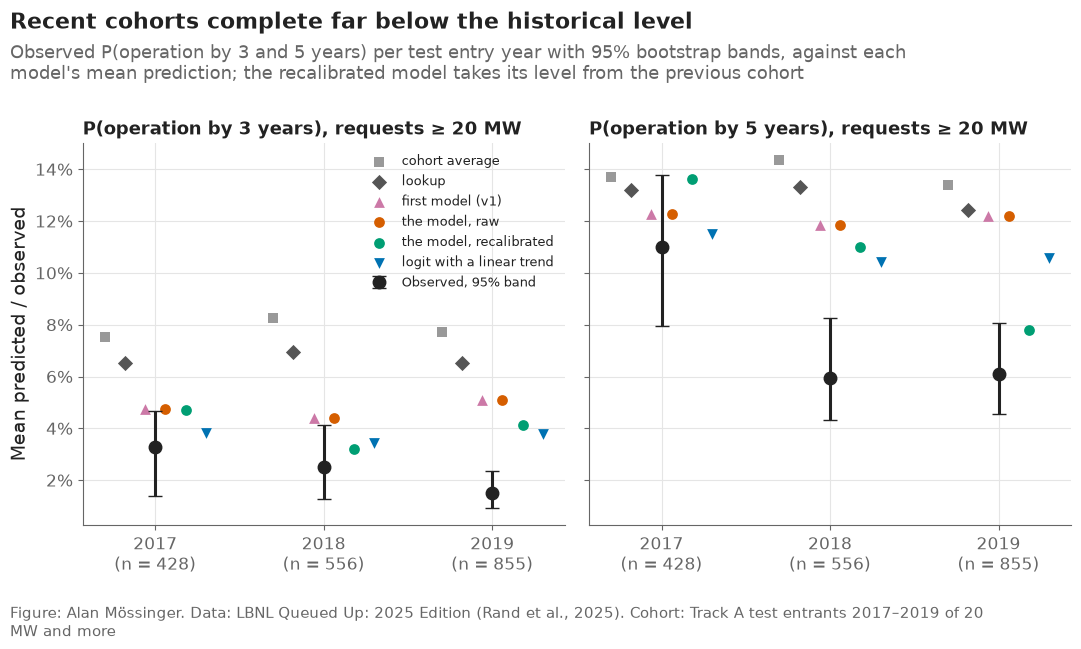

In [80]:
fig, axes = plt.subplots(1, 2, sharey=True)
style = {"baseline": ("#999999", "s"), "fair_baseline": ("#555555", "D"), "v1 LightGBM": ("#CC79A7", "^"),
         "v2": ("#D55E00", "o"), "v2 recalibrated": ("#009E73", "o"), LOGIT: ("#0072B2", "v")}
labels = {"baseline": "cohort average", "fair_baseline": "lookup", "v1 LightGBM": "first model (v1)", "v2": "the model, raw",  # the report's names
          "v2 recalibrated": "the model, recalibrated", LOGIT: "logit with a linear trend"}
offsets = dict(zip(style, np.linspace(-0.3, 0.3, len(style))))
for ax, h in zip(axes, LEVEL_HORIZONS):
    part = by_year[(by_year["cohort"] == "≥ 20 MW") & (by_year["horizon"] == h)].set_index("entry_year").loc[TEST_YEARS]
    x = np.arange(len(TEST_YEARS))
    ax.errorbar(x, part["observed"], yerr=[part["observed"] - part["low"], part["high"] - part["observed"]], fmt="o",
                color=plots.INK, capsize=5, markersize=9, label="Observed, 95% band", zorder=4)
    large = test["large"].to_numpy()
    for m, (color, marker) in style.items():
        if m == "v2 recalibrated":
            values = [np.nanmean(recal[h][(years == y) & large]) for y in TEST_YEARS]
        else:
            values = part[m].to_numpy()
        ax.scatter(x + offsets[m], values, marker=marker, color=color, s=60, zorder=3, label=labels[m])
    ax.set_xticks(x, [f"{y}\n(n = {n:,})" for y, n in zip(TEST_YEARS, part["n"])])
    ax.set_title(f"P(operation by {h} years), requests ≥ 20 MW", fontsize=13)
    ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
axes[0].set_ylabel("Mean predicted / observed")
axes[0].legend(loc="upper right", fontsize=9)  # the left panel has room above its points
lm = level_metrics.set_index(["cohort", "horizon", "model", "metric"])["estimate"]
plots.finish(fig,
             f"Recalibrating on the cohort before brings the v2 model's 5-year level for 2018–2019 entrants of 20 MW and more "
             f"from {lm[('2018–2019, ≥ 20 MW', 5, 'v2 raw', 'intercept')]:+.2f} to "
             f"{lm[('2018–2019, ≥ 20 MW', 5, 'v2 recalibrated', 'intercept')]:+.2f} on the intercept scale "
             f"(slope {lm[('2018–2019, ≥ 20 MW', 5, 'v2 recalibrated', 'slope')]:.2f})",
             "Observed P(operation by 3 and 5 years) per test entry year with 95% bootstrap bands, against each model's mean "
             "prediction; the recalibrated model takes its level from the previous cohort",
             "Track A test entrants 2017–2019 of 20 MW and more")
plots.save_fig(fig, "F11_level_by_entry_year",
               "Observed against predicted P(operation by 3 and 5 years) by test entry year for requests of 20 MW and more, "
               "before and after the rolling recalibration.", NOTEBOOK)
plt.show()

**Reading this.** On the C7 cohort (2018–2019 entrants of 20 MW and more) the raw v2 model's intercept is −1.01 [−1.44, −0.69] at 3 years and −0.81 [−1.01, −0.62] at 5 years: its probabilities are too high by a factor of two to three on the odds scale. The rolling recalibration takes the intercepts to −0.74 [−1.17, −0.41] and −0.47 [−0.70, −0.27], removing about 40% of the gap, with slopes of 1.09 and 1.18. No option reaches an intercept interval that covers zero: the logit's trend gives −0.72 and −0.66, the fair baseline −1.35 and −0.88. **Criterion C7 fails for every option**, and the report will say so: the level an analyst can set from the newest resolved cohort is still too high when completion falls every year. Within a region and year the ranking is unchanged by construction; the pooled Uno's C moves from 0.73 to 0.77 at 5 years because the regions are shifted by different amounts.

## 5. The newest evidence: 2020–2022 entrants

The v2 model (fitted on entrants to 2016) predicts P(operation by 1 and 2 years) for the 2020–2022 entrants of the three ISOs; notebook 01b measured what those cohorts actually did, in both editions of the file. The gap is the drift the models would carry into a 2026 decision, and the intercept that would close it at 2 years is reported as a diagnostic (not applied: the cohorts' 5-year level is not observable yet).

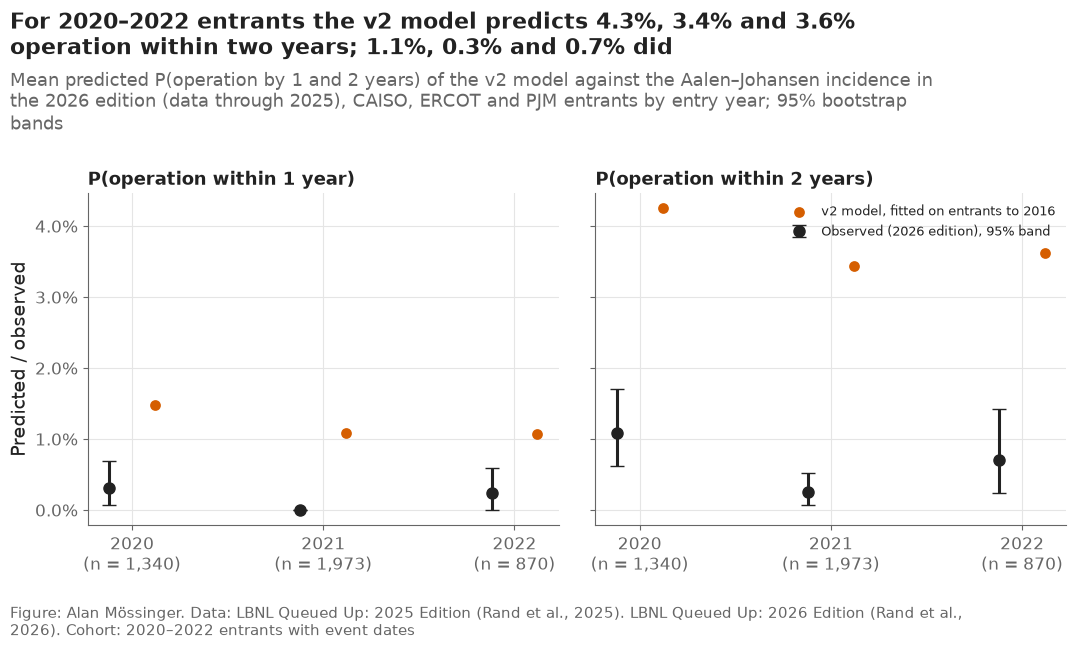

intercept that would close the 2-year gap (2025 edition outcomes): -2.15


,entry_year,horizon,edition,n_predicted,predicted,n_observed,observed,low,high,intercept_needed_2yr_2025_edition
0,2020,1,2025,1340,0.0148,1340,0.0067,0.0022,0.0112,-2.155
1,2020,1,2026,1340,0.0148,1289,0.0031,0.0008,0.0070,-2.155
2,2020,2,2025,1340,0.0425,1340,0.0127,0.0067,0.0179,-2.155
3,2020,2,2026,1340,0.0425,1289,0.0109,0.0062,0.0171,-2.155
4,2021,1,2025,1973,0.0109,1973,0.0000,0.0000,0.0000,-2.155
5,2021,1,2026,1973,0.0109,1539,0.0000,0.0000,0.0000,-2.155
6,2021,2,2025,1973,0.0344,1973,0.0010,0.0000,0.0025,-2.155
7,2021,2,2026,1973,0.0344,1539,0.0026,0.0006,0.0052,-2.155
8,2022,1,2025,870,0.0108,870,0.0000,0.0000,0.0000,-2.155
9,2022,1,2026,870,0.0108,844,0.0024,0.0000,0.0060,-2.155


In [81]:
recent = track_a[track_a["q_year"].between(2020, 2022)].copy()
p_recent = discrete_time.predict_both(fit_final, recent, horizons=[1, 2])[SPEC["model"]]
observed = pd.read_csv(paths.RESULTS / "early_incidence_2020_2022.csv")
rows = []
for year in [2020, 2021, 2022]:
    mask = (recent["q_year"] == year).to_numpy()
    for h in [1, 2]:
        for edition in [2025, 2026]:
            o = observed[(observed["entry_year"] == year) & (observed["horizon"] == h) & (observed["edition"] == edition)
                         & (observed["region"] == "CAISO+ERCOT+PJM")].iloc[0]
            rows.append({"entry_year": year, "horizon": h, "edition": edition, "n_predicted": int(mask.sum()),
                         "predicted": float(p_recent[h].to_numpy()[mask].mean()), "n_observed": int(o["n"]),
                         "observed": o["observed"], "low": o["low"], "high": o["high"]})
early_check = pd.DataFrame(rows)
# the intercept that would close the 2-year gap, from the 2025 edition's own outcomes (diagnostic only)
G_recent = evaluation.censoring_km(((pd.Timestamp(config.CENSOR_DATE) - recent["q_date"]).dt.days / config.DAYS_PER_YEAR).to_numpy(),
                                   np.ones(len(recent), bool))
y2, w2 = evaluation.horizon_outcome(recent["duration_years"].to_numpy(), recent["event"].to_numpy(), 2, G_recent)
a_needed = drift.fit_intercept(p_recent[2].to_numpy(), y2, w2)
early_check["intercept_needed_2yr_2025_edition"] = a_needed
early_check.to_csv(paths.RESULTS / "early_hazards_2020_2022.csv", index=False)

fig, axes = plt.subplots(1, 2, sharey=True)
for ax, h in zip(axes, [1, 2]):
    part = early_check[(early_check["horizon"] == h) & (early_check["edition"] == 2026)]
    x = np.arange(len(part))
    ax.errorbar(x - 0.12, part["observed"], yerr=[part["observed"] - part["low"], part["high"] - part["observed"]], fmt="o",
                color=plots.INK, capsize=5, markersize=8, label="Observed (2026 edition), 95% band")
    ax.scatter(x + 0.12, part["predicted"], marker="o", color="#D55E00", s=60, label="v2 model, fitted on entrants to 2016")
    ax.set_xticks(x, [f"{y}\n(n = {n:,})" for y, n in zip(part["entry_year"], part["n_predicted"])])
    ax.set_title(f"P(operation within {h} year{'s' if h > 1 else ''})", fontsize=13)
    ax.yaxis.set_major_formatter(lambda y, _: f"{y:.1%}")
axes[0].set_ylabel("Predicted / observed")
axes[1].legend(loc="upper right", fontsize=9)
ec = early_check[(early_check["horizon"] == 2) & (early_check["edition"] == 2026)].set_index("entry_year")
plots.finish(fig,
             f"For 2020–2022 entrants the v2 model predicts {ec.loc[2020, 'predicted']:.1%}, {ec.loc[2021, 'predicted']:.1%} and "
             f"{ec.loc[2022, 'predicted']:.1%} operation within two years; {ec.loc[2020, 'observed']:.1%}, "
             f"{ec.loc[2021, 'observed']:.1%} and {ec.loc[2022, 'observed']:.1%} did",
             "Mean predicted P(operation by 1 and 2 years) of the v2 model against the Aalen–Johansen incidence in the 2026 "
             "edition (data through 2025), CAISO, ERCOT and PJM entrants by entry year; 95% bootstrap bands",
             "2020–2022 entrants with event dates", lbnl_2026=True)
save(fig, "12_03_early_hazards_2020_2022", "Predicted against observed one- and two-year incidence of operation for 2020–2022 entrants.")
plt.show()
print(f"intercept that would close the 2-year gap (2025 edition outcomes): {a_needed:+.2f}")
early_check.round(4)

**Reading this.** The drift did not stop in 2019. For the 2020, 2021 and 2022 entrants the v2 model predicts 4.3%, 3.4% and 3.6% operation within two years; in the 2026 edition 1.1%, 0.3% and 0.7% did (14, 4 and 6 operations), and within one year 0.3%, 0.0% and 0.2% against 1.1–1.5% predicted. Closing the two-year gap would take an intercept of −2.16, a factor of about 0.12 on the odds — far beyond the −0.4 to −0.7 the rolling rule produced for 2018–2019. The two editions agree within their bands, so this is not a data-vintage effect. For a portfolio manager the message is blunt: a completion probability learned from the 2010s overstates what a 2020s request achieves in its first years several times over, and no entry-time model in this project is calibrated to the post-2020 queue. This is the main limitation the report carries into the portfolio layer, and the strongest reason for the landmark models of notebook 14, which condition on what has happened to a request since it entered.

## 6. Predictions for the later notebooks and checks

In [82]:
out = []
for h in config.HORIZONS:
    f = pd.DataFrame({"project_key": test["project_key"].astype(str).to_numpy(), "horizon": h,
                      "v2_raw": preds[h]["v2"], "v2_recalibrated": recal[h] if h in recal else np.nan,
                      "fair_baseline": preds[h]["fair_baseline"], "baseline": preds[h]["baseline"],
                      "region": regions, "q_year": years, "large": test["large"].to_numpy(),
                      "event": events, "duration_years": durations})
    out.append(f)
pred_level = pd.concat(out, ignore_index=True)
pred_level.to_parquet(paths.DATA_PROCESSED / "predictions_v2_recalibrated.parquet", index=False)

checks = pd.DataFrame([
    {"check": "no scored cohort is its own level source", "value": str(SOURCE_YEAR),
     "pass": all(s < y for y, s in SOURCE_YEAR.items()) and (intercepts["source_year"] < intercepts["scored_year"]).all()},
    {"check": "the refit reproduces notebook 11's predictions", "value": f"{refit_gap:.1e}", "pass": refit_gap < 1e-6},
    {"check": "recalibration leaves the ranking unchanged within each scored year and region",
     "value": int(sum(not np.array_equal(np.argsort(preds[h]["v2"][g], kind="stable"), np.argsort(recal[h][g], kind="stable"))
                      for h in LEVEL_HORIZONS for y in TEST_YEARS for r in TRACK_A
                      for g in [(years == y) & (regions == r)] if g.sum() > 1)),
     "pass": all(np.array_equal(np.argsort(preds[h]["v2"][g], kind="stable"), np.argsort(recal[h][g], kind="stable"))
                 for h in LEVEL_HORIZONS for y in TEST_YEARS for r in TRACK_A
                 for g in [(years == y) & (regions == r)] if g.sum() > 1)},
    {"check": "every level metric carries an interval", "value": int(level_metrics[["low", "high"]].isna().any(axis=1).sum()),
     "pass": not level_metrics[["low", "high"]].isna().any(axis=1).any()},
    {"check": "F11 saved as PNG and SVG", "value": 2,
     "pass": (paths.FIGURES / "F11_level_by_entry_year.png").exists() and (paths.FIGURES / "F11_level_by_entry_year.svg").exists()},
])
checks.to_csv(paths.RESULTS / "level_checks.csv", index=False)
assert checks["pass"].all(), checks
print(f"total {(time.time() - START) / 60:.1f} min")
checks

total 0.4 min


,check,value,pass
0,no scored cohort is its own level source,"{2017: 2016, 2018: 2017, 2019: 2018}",True
1,the refit reproduces notebook 11's predictions,0.0e+00,True
2,recalibration leaves the ranking unchanged wit...,0,True
3,every level metric carries an interval,0,True
4,F11 saved as PNG and SVG,2,True


## Takeaways — Part G

- The level drifts in one direction: among requests of 20 MW and more, 5-year completion fell from 11.0% (2017 entrants) to 5.9% and 6.1% (2018, 2019); the models stayed at 12%.
- What moved is the hazard of operation in the first three years (9.1% for 2013 entrants, 2.3% for 2018–2019), not the hazard of withdrawal (24–34% to 17–23%): requests wait longer, they do not leave faster.
- The rolling recalibration (level from the cohort before, per region) removes about 40% of the 2018–2019 error (5-year intercept −0.81 → −0.47) but every option's intercept interval still excludes zero: criterion C7 fails.
- 2020–2022 entrants operate within two years at a quarter of the predicted rate (1.1%, 0.3%, 0.7% against 4.3%, 3.4%, 3.6%); closing that gap would take an intercept of −2.16.
- **What goes to the report:** F11 and figure 12_01; the C7 verdict; the limitation that no entry-time model here is calibrated to the post-2020 queue, and the handover to the landmark models.

# Part H — What post-entry information would add: the labelled leakage ablation (was notebook 08 §9)

Moved here from the evaluation notebook because the leakage guard of the landmark models (C12, part J) uses its 5-year AUC as the ceiling, and the evaluation record runs after this notebook.

## Setup

In [83]:
import json
from pathlib import Path

# The bootstrap size, level and seed registered in decision #5. Notebook 06 writes this file before it scores
# anything and the file is committed; this part only reads the constants.
REGISTERED = json.loads((Path.cwd().resolve().parent / "results" / "success_criteria_registered.json")
                        .read_text(encoding="utf-8"))

In [84]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append(str(Path.cwd().resolve().parent))  # notebooks run from notebooks/; src/ is one level up
from src import config, discrete_time, evaluation, paths, plots, survival_tools, track_b

paths.ensure_dirs()
plots.set_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

NOTEBOOK = "04_forecast_queue"
TRACK_A = config.TRACK_A_REGIONS


def save(fig, name, caption):
    """Save a figure of this notebook under figures/04_forecast_queue/ with its caption stub."""
    return plots.save_fig(fig, name, caption, NOTEBOOK, folder=NOTEBOOK)


def pct(x, digits=1):
    """Format a share as a percentage string."""
    return f"{100 * x:.{digits}f}%"

import time
import warnings

from sklearn.metrics import roc_curve

warnings.filterwarnings("ignore", category=FutureWarning)
START = time.time()
HORIZONS = config.HORIZONS
N_BOOT, LEVEL = REGISTERED["n_boot"], REGISTERED["level"]
MODELS = ["baseline", "cox", "dt_logit", "dt_lgbm"]
MODEL_LABELS = {"baseline": "Baseline (region × technology)", "cox": "Cox", "dt_logit": "Discrete-time logit",
                "dt_lgbm": "Discrete-time LightGBM"}
MODEL_STYLE = {"baseline": dict(color="#999999", marker="s", linestyle="--"),
               "cox": dict(color="#555555", marker="D", linestyle=":"),
               "dt_logit": dict(color="#009E73", marker="o"),
               "dt_lgbm": dict(color="#CC79A7", marker="^")}
METRIC_LABELS = {"uno_c": "Uno's C", "harrell_c": "Harrell's C", "auc": "Time-dependent AUC",
                 "brier": "Brier score (IPCW)", "slope": "Calibration slope", "intercept": "Calibration intercept",
                 "precision_10": "Precision in top 10%", "lift_10": "Top-decile lift"}
OFFSETS = dict(zip(MODELS, np.linspace(-0.24, 0.24, len(MODELS))))


def value(table, model, metric, horizon=None, column="estimate"):
    """One number from a summarised metrics table."""
    part = table[(table["model"] == model) & (table["metric"] == metric)]
    if horizon is not None:
        part = part[part["horizon"] == horizon]
    assert len(part) == 1, (model, metric, horizon)
    return part[column].iloc[0]


def ci(table, model, metric, horizon=None, digits=3, prefix=""):
    """'estimate [low, high]' for one row of a summarised table (prefix 'diff' for the paired difference)."""
    cols = [f"{prefix}{c}" if prefix else c for c in (["diff", "diff_low", "diff_high"] if prefix else ["estimate", "low", "high"])]
    est, low, high = (value(table, model, metric, horizon, c) for c in cols)
    return f"{est:.{digits}f} [{low:.{digits}f}, {high:.{digits}f}]"


def errorbars(ax, x, part, **style):
    """Points with their bootstrap interval."""
    return ax.errorbar(x, part["estimate"], yerr=[part["estimate"] - part["low"], part["high"] - part["estimate"]],
                       capsize=3, **style)

In [85]:
# The test cohort, its outcomes and the stored predictions, exactly as notebook 06 (part A) joins them
pred = pd.read_parquet(paths.DATA_PROCESSED / "predictions_trackA.parquet")
track_a = pd.read_parquet(paths.DATA_INTERIM / "trackA.parquet")
track_a["tech"] = track_a["type_clean"].map(plots.tech_group)
test = track_a[track_a["q_year"].between(*config.TEST_YEARS)].copy()
keys = test["project_key"].astype(str)
P = {h: pred[(pred["split"] == "test") & (pred["horizon"] == h)].set_index("project_key").loc[keys] for h in HORIZONS}
assert all(np.allclose(P[h]["duration_years"], test["duration_years"]) for h in HORIZONS)
durations = test["duration_years"].to_numpy()
events = test["event"].to_numpy()
regions = test["region"].astype(str).to_numpy()
preds = {h: {m: P[h][m].to_numpy() for m in MODELS} for h in HORIZONS}
follow_up = ((pd.Timestamp(config.CENSOR_DATE) - test["q_date"]).dt.days / config.DAYS_PER_YEAR).to_numpy()
clean = pd.read_parquet(paths.DATA_INTERIM / "queue_clean.parquet")
tuning = json.loads((paths.RESULTS / "dt_tuning.json").read_text(encoding="utf-8"))
final = track_a[track_a["q_year"] <= config.TRAIN_MAX_YEAR].copy()

## 9. Leakage ablation: what post-entry information would add (CAISO and ERCOT)

Decisions #7 and #22 keep post-entry milestones out of the models. This
labelled ablation shows what they would seem to add: LightGBM is refitted on
CAISO and ERCOT entrants to 2016 (PJM's public file has no IA dates) once with
the entry-time features only and once with four columns that are only known
later — whether an interconnection agreement (IA) date is recorded, the years
from request to it, the study phase as recorded at the end of 2024, and the
stored ambition gap (proposed online date minus request date). Both are
scored on CAISO and ERCOT test entrants. A gain here is not a better model;
it measures how far a careless model would overstate its accuracy.

In [86]:
PHASES = sorted(track_a["IA_status_clean"].dropna().astype(str).unique())


def post_entry_columns(rows):
    """The four post-entry columns of the leakage ablation (never in the main models)."""
    project = track_a.loc[rows["project"]]
    out = pd.DataFrame(index=rows.index)
    out["ia_recorded"] = project["ia_date"].notna().to_numpy(dtype=float)
    out["years_to_ia"] = ((project["ia_date"] - project["q_date"]).dt.days / config.DAYS_PER_YEAR).to_numpy()
    out["study_phase"] = pd.Categorical(project["IA_status_clean"].astype(object).to_numpy(), categories=PHASES)
    out["ambition_gap_years"] = project["ambition_gap_years"].to_numpy(dtype=float)
    return out


pair = ["CAISO", "ERCOT"]
train_ce = final[final["region"].isin(pair)]
mask_ce = np.isin(regions, pair)
target_ce = test[mask_ce]
fit_entry = discrete_time.fit_both(train_ce, clean, tuning)
fit_leak = discrete_time.fit_both(train_ce, clean, tuning, extra=post_entry_columns)
p_entry = discrete_time.predict_both(fit_entry, target_ce)
p_leak = discrete_time.predict_both(fit_leak, target_ce)
gain = pd.Series(fit_leak["lgbm"].feature_importance("gain"), index=fit_leak["lgbm"].feature_name())
print("share of LightGBM's split gain on the post-entry columns:",
      f"{gain[['ia_recorded', 'years_to_ia', 'study_phase', 'ambition_gap_years']].sum() / gain.sum():.1%}")
G_ce = evaluation.censoring_km(follow_up[mask_ce], np.ones(mask_ce.sum(), dtype=bool))
abl_tables = []
for h in HORIZONS:
    sub = {"baseline": preds[h]["baseline"][mask_ce], "entry_only": p_entry["dt_lgbm"][h].to_numpy(),
           "with_post_entry": p_leak["dt_lgbm"][h].to_numpy()}
    point = evaluation.score_horizon(sub, durations[mask_ce], events[mask_ce], h, G_ce)
    draws = evaluation.bootstrap(lambda sw: evaluation.score_horizon(sub, durations[mask_ce], events[mask_ce], h, G_ce, sw),
                                 int(mask_ce.sum()), N_BOOT, REGISTERED["seed_track_a"] + 40)
    table = evaluation.summarise(point, draws, reference="entry_only", level=LEVEL)
    table.insert(2, "horizon", h)
    abl_tables.append(table)
ablation = pd.concat(abl_tables, ignore_index=True)
ablation.to_csv(paths.RESULTS / "ablation.csv", index=False)
ab = ablation[ablation["metric"].isin(["uno_c", "auc", "brier", "slope"])].copy()
ab["value"] = [f"{r.estimate:.3f} [{r.low:.3f}, {r.high:.3f}]" for r in ab.itertuples()]
ab.pivot_table(index=["metric", "horizon"], columns="model", values="value", aggfunc="first")[["baseline", "entry_only", "with_post_entry"]]

share of LightGBM's split gain on the post-entry columns: 58.9%


model                       baseline            entry_only       with_post_entry
metric horizon                                                                  
auc    3        0.685 [0.626, 0.763]  0.744 [0.660, 0.810]  0.964 [0.950, 0.979]
       5        0.717 [0.680, 0.757]  0.715 [0.667, 0.761]  0.990 [0.984, 0.995]
       7        0.691 [0.634, 0.760]  0.645 [0.587, 0.706]  0.987 [0.968, 0.997]
brier  3        0.037 [0.026, 0.048]  0.038 [0.025, 0.051]  0.032 [0.024, 0.040]
       5        0.094 [0.079, 0.109]  0.103 [0.086, 0.122]  0.026 [0.020, 0.034]
       7        0.114 [0.099, 0.131]  0.124 [0.106, 0.146]  0.028 [0.018, 0.044]
slope  3        0.578 [0.345, 1.181]  0.598 [0.364, 0.794]  0.813 [0.693, 1.106]
       5        0.494 [0.205, 1.067]  0.667 [0.497, 0.897]  1.417 [1.183, 1.890]
       7        0.913 [0.595, 1.416]  0.580 [0.376, 0.885]  1.237 [0.927, 2.127]
uno_c  3        0.684 [0.626, 0.760]  0.740 [0.660, 0.803]  0.957 [0.943, 0.972]
       5        0.704 [0.671, 0.745]  0.705 [0.662, 0.747]  0.965 [0.958, 0.973]
       7        0.690 [0.643, 0.739]  0.675 [0.630, 0.726]  0.959 [0.946, 0.969]

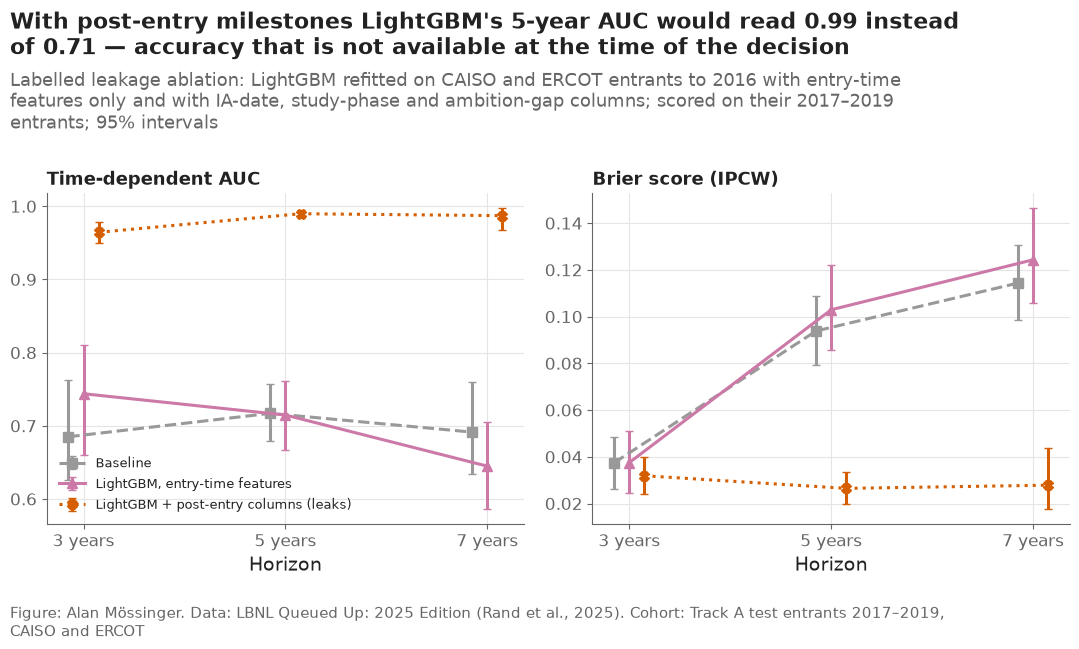

In [87]:
ABL_LABELS = {"baseline": "Baseline", "entry_only": "LightGBM, entry-time features",
              "with_post_entry": "LightGBM + post-entry columns (leaks)"}
ABL_STYLE = {"baseline": dict(color="#999999", marker="s", linestyle="--"), "entry_only": dict(color="#CC79A7", marker="^"),
             "with_post_entry": dict(color="#D55E00", marker="X", linestyle=":")}
abl_offsets = dict(zip(ABL_LABELS, [-0.15, 0, 0.15]))
fig, axes = plt.subplots(1, 2, sharex=True)
for ax, metric in zip(axes, ["auc", "brier"]):
    for model in ABL_LABELS:
        part = ablation[(ablation["model"] == model) & (ablation["metric"] == metric)]
        errorbars(ax, part["horizon"] + abl_offsets[model], part, label=ABL_LABELS[model], **ABL_STYLE[model])
    ax.set_xticks(HORIZONS, [f"{h} years" for h in HORIZONS])
    ax.set_xlabel("Horizon")
    ax.set_title(METRIC_LABELS[metric], fontsize=13)
axes[0].legend(loc="lower left", fontsize=9.5)
plots.finish(fig,
             f"With post-entry milestones LightGBM's 5-year AUC would read {value(ablation, 'with_post_entry', 'auc', 5):.2f} "
             f"instead of {value(ablation, 'entry_only', 'auc', 5):.2f} — accuracy that is not available at the time of "
             "the decision",
             "Labelled leakage ablation: LightGBM refitted on CAISO and ERCOT entrants to 2016 with entry-time features "
             "only and with IA-date, study-phase and ambition-gap columns; scored on their 2017–2019 entrants; 95% intervals",
             "Track A test entrants 2017–2019, CAISO and ERCOT")
save(fig, "08_16_leakage_ablation", "Leakage ablation: time-dependent AUC and Brier score with and without post-entry columns, CAISO and ERCOT.")
plt.show()

**Reading this.** Adding the four post-entry columns makes LightGBM look nearly perfect on CAISO and ERCOT: 5-year AUC 0.990 [0.984, 0.995] instead of 0.715 [0.667, 0.761], Brier 0.026 instead of 0.103, and 58.9% of the trees' split gain goes to those columns. This is leakage, not skill: whether an interconnection agreement was recorded and the study phase as of 2024 are partly the outcome itself, and the stored ambition gap was found in notebook 01 to be updated after entry (decision #22). A model reported with these columns would promise accuracy that does not exist on the day a request enters the queue. A side result: fitted on CAISO and ERCOT alone, the entry-time LightGBM does not beat the baseline there (AUC 0.715 vs 0.717 at 5 years), consistent with the within-region results above.

# Part I — Milestones after entry: the ISO queue files and the agreement dates (was notebook 13)

A portfolio is managed at milestones, not at entry. This notebook gathers, for every Track A request, what is known and **dated** after the request date: the executed interconnection agreement (IA) date from both editions of the LBNL file, and, for CAISO, the ISO's own queue report (cluster, study-phase status, agreement status, withdrawal and completion dates). PJM's queue export and ERCOT's GIS report, which could not be fetched from this machine (decision #53), were fetched by me from another network on 2026-10-07; section 3 joins them and measures what they can date after entry for the test cohort before anything from them is used (decision #57). The output is one milestone table, with its coverage stated by region, for the landmark models of notebook 14.

## Setup

In [88]:
import hashlib
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append(str(Path.cwd().resolve().parent))  # notebooks run from notebooks/; src/ is one level up
from src import config, paths, plots

paths.ensure_dirs()
plots.set_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
warnings.filterwarnings("ignore", category=FutureWarning)

NOTEBOOK = "04_forecast_queue"
TRACK_A = config.TRACK_A_REGIONS
RAW_ISO = paths.DATA_RAW / "iso"
KEY = ["q_id", "entity", "region"]
IA_TOLERANCE_DAYS = 90  # two sources "agree" on an agreement date within this window


def save(fig, name, caption):
    """Save a figure of this notebook under figures/04_forecast_queue/ with its caption stub."""
    return plots.save_fig(fig, name, caption, NOTEBOOK, folder=NOTEBOOK)

## 1. Agreement dates from the two LBNL editions

The 2025 edition dates an agreement for 9% of Track A requests (ERCOT 32%, CAISO 13%, PJM none); the 2026 edition adds 2,508 agreement dates across the file. The two are merged request by request: where both carry a date they are compared, where only the 2026 edition does, its date is used. The phase reached (`IA_status_clean`, the 2026 edition's `IA_phase_clean`) is kept as a status — it is undated in every source, so notebook 14 cannot use it as a landmark feature.

In [89]:
track_a = pd.read_parquet(paths.DATA_INTERIM / "trackA.parquet")
clean_2026 = pd.read_parquet(paths.DATA_INTERIM / "queue_clean_2026.parquet")
for frame in (track_a, clean_2026):
    for column in KEY:
        frame[column] = frame[column].astype(str)
m = track_a[KEY + ["project_key", "q_date", "exit_date", "duration_years", "event", "q_year", "ia_date", "IA_status_clean"]].merge(
    clean_2026[KEY + ["ia_date", "IA_status_clean", "q_status"]].drop_duplicates(KEY), on=KEY, how="left", suffixes=("", "_2026"))
assert len(m) == len(track_a)
both = m[m["ia_date"].notna() & m["ia_date_2026"].notna()]
gap = (both["ia_date_2026"] - both["ia_date"]).dt.days
agreement = pd.DataFrame([{
    "requests with an agreement date in 2025": int(m["ia_date"].notna().sum()),
    "in 2026": int(m["ia_date_2026"].notna().sum()),
    "in both": len(both),
    "same day": int((gap == 0).sum()),
    f"within {IA_TOLERANCE_DAYS} days": int((gap.abs() <= IA_TOLERANCE_DAYS).sum()),
    "only in 2026": int((m["ia_date"].isna() & m["ia_date_2026"].notna()).sum()),
    "only in 2025": int((m["ia_date"].notna() & m["ia_date_2026"].isna()).sum()),
}]).T.rename(columns={0: "count"})
agreement.to_csv(paths.RESULTS / "ia_date_agreement.csv")
m["ia_date_best"] = m["ia_date"].fillna(m["ia_date_2026"])  # the frozen edition first, the newer one where it is silent
m["ia_source"] = np.select([m["ia_date"].notna(), m["ia_date_2026"].notna()], ["2025 edition", "2026 edition"], default="none")
m["phase_reached"] = m["IA_status_clean_2026"].fillna(m["IA_status_clean"])
print(f"agreement dates: 2025 {agreement.loc['requests with an agreement date in 2025', 'count']:,}; "
      f"merged {m['ia_date_best'].notna().sum():,} of {len(m):,} Track A requests")
agreement

agreement dates: 2025 1,252; merged 1,818 of 13,366 Track A requests


,count
requests with an agreement date in 2025,1252
in 2026,1752
in both,1186
same day,1112
within 90 days,1119
only in 2026,566
only in 2025,66


**Reading this.** The frozen edition dates an executed agreement for 1,252 Track A requests, the 2026 edition for 1,752; 1,186 carry a date in both, and 1,112 of those are the same day (1,119 within 90 days). The 2026 edition adds 566 requests the 2025 file left undated and drops 66 the 2025 file had, which is the snapshot-of-snapshots behaviour notebook 01b measured. Merged, 1,818 of 13,366 requests (14%) have a dated agreement; the phase reached is known for almost every request but carries no date.

## 2. CAISO's queue report

`gridstatus` pulled CAISO's public queue report on 2026-10-06 (the file's SHA-256 is recorded). It is joined to the LBNL CAISO requests by queue ID; the join rate, and the agreement between the two sources on the dates both carry, are reported before anything from it is used. The report carries the cluster (`Study Process`), the status of the system-impact and facilities studies, the agreement status and the withdrawal and completion dates — statuses as of the snapshot, so they describe where a request *is*, not when it got there.

In [90]:
caiso_file = RAW_ISO / "caiso_queue_2026-10-06.parquet"
recorded = {line.split()[1].lstrip("*").split("/")[-1]: line.split()[0]
            for line in (RAW_ISO / "SHA256.txt").read_text().splitlines() if line.strip()}
digest = hashlib.sha256(caiso_file.read_bytes()).hexdigest()
assert recorded[caiso_file.name] == digest, "the CAISO snapshot on disk is not the one recorded in data/raw/iso/SHA256.txt"
caiso = pd.read_parquet(caiso_file)
caiso["q_id"] = caiso["Queue ID"].astype(str).str.strip()
for column in ["Queue Date", "Withdrawn Date", "Actual Completion Date", "Interconnection Request Receive Date"]:
    caiso[column] = pd.to_datetime(caiso[column], errors="coerce").dt.tz_localize(None).dt.normalize()
iso_cols = {"Study Process": "cluster", "Status": "iso_status", "Interconnection Agreement Status": "iso_ia_status",
            "System Impact Study or Phase I Cluster Study": "iso_sis_status",
            "Facilities Study (FAS) or Phase II Cluster Study": "iso_fas_status",
            "Queue Date": "iso_queue_date", "Withdrawn Date": "iso_withdrawn_date", "Actual Completion Date": "iso_completion_date",
            "Full Capacity, Partial or Energy Only (FC/P/EO)": "iso_deliverability"}
caiso_small = caiso[["q_id"] + list(iso_cols)].rename(columns=iso_cols).drop_duplicates("q_id")
ca = m[m["region"] == "CAISO"].merge(caiso_small, on="q_id", how="left")
found = ca["iso_status"].notna()
join_rates = pd.DataFrame([
    {"iso": "CAISO", "lbnl_requests": len(ca), "found_in_iso_file": int(found.sum()), "share_found": found.mean(),
     "share_found_2017_2019": ca.loc[ca["q_year"].between(2017, 2019), "iso_status"].notna().mean(),
     "snapshot": "2026-10-06", "rows_in_iso_file": len(caiso)},
])
join_rates.to_csv(paths.RESULTS / "iso_join_rates.csv", index=False)

# agreement of the dates both sources carry
checks_dates = []
for lbnl_col, iso_col, what in [("q_date", "iso_queue_date", "request date"), ("exit_date", "iso_withdrawn_date", "withdrawal date"),
                                ("exit_date", "iso_completion_date", "completion date")]:
    sub = ca[found & ca[iso_col].notna()]
    if what == "withdrawal date":
        sub = sub[sub["event"] == 2]
    elif what == "completion date":
        sub = sub[sub["event"] == 1]
    gap = (sub[iso_col] - sub[lbnl_col]).dt.days
    checks_dates.append({"date": what, "requests_with_both": len(sub), "same_day": float((gap == 0).mean()) if len(sub) else np.nan,
                         "within_90_days": float((gap.abs() <= 90).mean()) if len(sub) else np.nan,
                         "median_gap_days": float(gap.median()) if len(sub) else np.nan})
checks_dates = pd.DataFrame(checks_dates)
print(f"CAISO: {found.mean():.1%} of LBNL requests found in the ISO report; 2017–2019 entrants "
      f"{join_rates.loc[0, 'share_found_2017_2019']:.1%}")
display(join_rates.round(3))
checks_dates.round(3)

CAISO: 89.7% of LBNL requests found in the ISO report; 2017–2019 entrants 100.0%


,iso,lbnl_requests,found_in_iso_file,share_found,share_found_2017_2019,snapshot,rows_in_iso_file
0,CAISO,2474,2218,0.897,1.0,2026-10-06,2278


,date,requests_with_both,same_day,within_90_days,median_gap_days
0,request date,2218,1.000,1.0,0.0
1,withdrawal date,1626,0.933,1.0,0.0
2,completion date,200,1.000,1.0,0.0


In [91]:
# what the ISO report says about the LBNL CAISO requests, by LBNL outcome
by_outcome = (ca[found].assign(outcome=ca["event"].map({0: "censored", 1: "operation", 2: "withdrawal"}))
              .groupby(["outcome", "iso_ia_status"], dropna=False).size().unstack("iso_ia_status").fillna(0).astype(int))
clusters = ca.loc[found, "cluster"].value_counts().head(10)
print("clusters among the joined CAISO requests:", clusters.to_dict())
by_outcome

clusters among the joined CAISO requests: {'C14': 359, 'Serial LGIP': 344, 'C04': 189, 'C13': 147, 'C12': 136, 'C09': 123, 'C08': 120, 'SGIP': 94, 'C11': 93, 'C10': 86}


iso_ia_status,Executed,Filed Unexecuted,In Progress,Terminated,<NA>
outcome,,,,,
censored,254,1,7,6,116
operation,200,1,1,0,6
withdrawal,34,0,18,4,1570


**Reading this.** CAISO's report finds 90% of the LBNL CAISO requests and every one of the 2017–2019 entrants, and where both sources carry a date they agree: request dates on the same day for all 2,218 joined requests, withdrawal dates for 93% (all within 90 days), completion dates for all 200. That is strong evidence the LBNL file is a faithful copy of the ISO queue for CAISO. The report's agreement status is where it adds something: 200 of the 207 requests that reached operation had an executed agreement, so did 254 of the still-active requests, and only 34 of the 1,626 withdrawn ones — the agreement is close to a necessary condition for being built. Clusters run from the serial era (344 requests) through cluster 14 (359).

## 3. PJM's queue export and ERCOT's GIS report

Both files were fetched on 2026-10-07 from another network and their SHA-256 recorded. Each is joined to the LBNL requests by queue ID, the dates both sources carry are compared, and then the question that decides their use is answered for the 2017–2019 test cohort: **what does the file date after the request, and is being in the file itself information about the outcome?** A landmark feature has to be dated before the landmark and observed for every request in the risk set, whatever its later fate (criterion C12).


In [92]:
from src import iso_files

for name in ["pjm_queue_2026-10-07.xml", "ercot_gis_2026-10-07.xlsx"]:
    assert recorded[name] == hashlib.sha256((RAW_ISO / name).read_bytes()).hexdigest(), f"{name} is not the file recorded in SHA256.txt"
pjm = iso_files.read_pjm_queue(RAW_ISO / "pjm_queue_2026-10-07.xml")
ercot = iso_files.read_ercot_gis(RAW_ISO / "ercot_gis_2026-10-07.xlsx")
test_years = m["q_year"].between(2017, 2019)
outcome = m["event"].map({0: "active at end-2024", 1: "operated", 2: "withdrew"})

pj = m[m["region"] == "PJM"].merge(pjm, on="q_id", how="left")
pj_found = pj["submitted_date"].notna() | pj["pjm_status"].notna()
er = m[m["region"] == "ERCOT"].merge(ercot, on="q_id", how="left")
er_found = er["listed_as"].notna()
join_rates = pd.concat([join_rates, pd.DataFrame([
    {"iso": "PJM", "lbnl_requests": len(pj), "found_in_iso_file": int(pj_found.sum()), "share_found": pj_found.mean(),
     "share_found_2017_2019": pj_found[pj["q_year"].between(2017, 2019)].mean(), "snapshot": "2026-10-07", "rows_in_iso_file": len(pjm)},
    {"iso": "ERCOT", "lbnl_requests": len(er), "found_in_iso_file": int(er_found.sum()), "share_found": er_found.mean(),
     "share_found_2017_2019": er_found[er["q_year"].between(2017, 2019)].mean(), "snapshot": "2026-10-07 (Sep 2026 activity)",
     "rows_in_iso_file": len(ercot)},
])], ignore_index=True)
join_rates.to_csv(paths.RESULTS / "iso_join_rates.csv", index=False)

# dates both sources carry (PJM): request, withdrawal, operation
pjm_dates = []
for lbnl_col, iso_col, what, event in [("q_date", "submitted_date", "request date", None), ("exit_date", "withdrawal_date", "withdrawal date", 2),
                                       ("exit_date", "in_service_date", "in-service date", 1)]:
    sub = pj[pj[iso_col].notna() & (pj["event"] == event if event else True)]
    gap = (sub[iso_col] - sub[lbnl_col]).dt.days
    pjm_dates.append({"date": what, "requests_with_both": len(sub), "same_day": float((gap == 0).mean()),
                      "within_90_days": float((gap.abs() <= 90).mean()), "median_gap_days": float(gap.median())})
pjm_dates = pd.DataFrame(pjm_dates)

# what each file dates after entry, for the 2017–2019 cohort, by LBNL outcome
pt, et = pj[pj["q_year"].between(2017, 2019)], er[er["q_year"].between(2017, 2019)]
pt_out, et_out = pt["event"].map({0: "active at end-2024", 1: "operated", 2: "withdrew"}), et["event"].map({0: "active at end-2024", 1: "operated", 2: "withdrew"})
backfeed_lead = ((pj["in_service_date"] - pj["backfeed_date"]).dt.days / config.DAYS_PER_YEAR)[pj["event"] == 1].dropna()
er_ia_new = er["ia_signed"].notna() & er["ia_date_best"].isna()
both_ia = er[er["ia_signed"].notna() & er["ia_date_best"].notna()]
contents = pd.DataFrame([
    {"file": "PJM", "item": "test requests", **pt_out.value_counts().to_dict()},
    {"file": "PJM", "item": "found in the file", **pt_out[pt["pjm_status"].notna()].value_counts().to_dict()},
    {"file": "PJM", "item": "a study or agreement date (none in the export)", **{k: 0 for k in pt_out.unique()}},
    {"file": "PJM", "item": "agreement status 'Document Posted' (undated)", **pt_out[pt["isa_status"] == "Document Posted"].value_counts().to_dict()},
    {"file": "PJM", "item": "backfeed date", **pt_out[pt["backfeed_date"].notna()].value_counts().to_dict()},
    {"file": "ERCOT", "item": "test requests", **et_out.value_counts().to_dict()},
    {"file": "ERCOT", "item": "listed in the report", **et_out[et["listed_as"].notna()].value_counts().to_dict()},
    {"file": "ERCOT", "item": "full study approved, dated", **et_out[et["fis_approved"].notna()].value_counts().to_dict()},
    {"file": "ERCOT", "item": "agreement signed, dated, not in LBNL", **et_out[et["ia_signed"].notna() & et["ia_date_best"].isna()].value_counts().to_dict()},
]).set_index(["file", "item"]).reindex(columns=["operated", "withdrew", "active at end-2024"]).fillna(0).astype(int)
contents.to_csv(paths.RESULTS / "iso_file_contents.csv")
ia_gap = (both_ia["ia_signed"] - both_ia["ia_date_best"]).dt.days
print(f"PJM: {pj_found.mean():.1%} of LBNL PJM requests found ({join_rates.iloc[1]['share_found_2017_2019']:.1%} of 2017–2019 entrants); "
      f"backfeed precedes operation by a median {backfeed_lead.median():.2f} years (n = {len(backfeed_lead):,})")
print(f"ERCOT: {er_found.mean():.1%} of LBNL ERCOT requests listed ({join_rates.iloc[2]['share_found_2017_2019']:.1%} of 2017–2019 entrants); "
      f"agreement dates in both sources: {len(both_ia):,}, {(ia_gap.abs() <= 30).mean():.1%} within 30 days; "
      f"agreement dates the LBNL editions lack: {int(er_ia_new.sum()):,}, by entry year {er.loc[er_ia_new, 'q_year'].value_counts().sort_index().to_dict()}")
display(pjm_dates.round(3))
contents


PJM: 89.3% of LBNL PJM requests found (94.5% of 2017–2019 entrants); backfeed precedes operation by a median 0.27 years (n = 204)
ERCOT: 41.2% of LBNL ERCOT requests listed (22.5% of 2017–2019 entrants); agreement dates in both sources: 440, 98.0% within 30 days; agreement dates the LBNL editions lack: 69, by entry year {np.int64(2019): 1, np.int64(2020): 1, np.int64(2021): 3, np.int64(2022): 19, np.int64(2023): 23, np.int64(2024): 22}


,date,requests_with_both,same_day,within_90_days,median_gap_days
0,request date,7051,1.0,1.0,0.0
1,withdrawal date,4443,1.0,1.0,0.0
2,in-service date,1143,1.0,1.0,0.0


operated  withdrew  active at end-2024
file  item                                                                                  
PJM   test requests                                        196       893                 376
      found in the file                                    196       866                 322
      a study or agreement date (none in the export)         0         0                   0
      agreement status 'Document Posted' (undated)         155        38                 290
      backfeed date                                         69         8                 265
ERCOT test requests                                         92       223                 164
      listed in the report                                   0         0                 108
      full study approved, dated                             0         0                  51
      agreement signed, dated, not in LBNL                   0         0                   1

**Reading this.** Both files join well and neither adds a usable landmark for the test cohort.

- **PJM.** The export finds 89% of the LBNL PJM requests and 94.5% of the 2017–2019 entrants, and it agrees with the LBNL file on the same day for every shared request date (7,051), withdrawal date (4,443) and in-service date (1,143): the LBNL file is a faithful copy of PJM's queue for the dates it carries. What it does not carry is a date for any study or for the agreement — each phase is a status ("Document Posted") and a link to a PDF. The agreement status separates outcomes strongly (posted for 155 of the 196 test requests that operated and 38 of the 893 that withdrew) but it is the status in October 2026, so using it at a landmark would be using the outcome. The two dated construction steps come too late: backfeed precedes operation by a median 0.27 years, and of the 342 backfeed dates in the test cohort only 5 fall within two years of the request and 258 fall after the end of 2024 (planned dates, not events).
- **ERCOT.** The report dates every phase — screening, full study, agreement — but lists only requests still active in September 2026 plus the month's inactive and cancelled ones. Of the 479 test requests, it lists 108, all still active at the end of 2024; none of the 92 that operated or the 223 that withdrew is in it. Its dates are therefore observed only for survivors, and a landmark feature built from them would carry the outcome. Where both sources date an agreement they agree (98% of 440 within 30 days) — the LBNL file's ERCOT agreement dates are this report's dates from earlier editions — and the report adds 69 agreement dates the LBNL editions lack, one of them for a test request.

The milestone table below is therefore unchanged: the agreement dates from the two LBNL editions remain the only dated, outcome-blind post-entry milestone, and PJM's gap stays open (decision #57). The public archive was checked too: it holds 158 of PJM's executed-agreement PDFs, 63 of them for 2017–2019 entrants (of 1,465), a selected sample that would lift PJM's coverage from about 3% to about 7%.


## 4. The milestone table and its coverage

One row per Track A request. `ia_date_best` is the executed-agreement date (frozen edition first, then the 2026 edition), `ia_years` the years from request to agreement, `ia_inside_queue` whether that date falls after the request and before the exit (the only agreements a landmark can use); `phase_reached` the undated phase; and the CAISO columns where joined.

In [93]:
milestones = m.merge(ca[["project_key"] + list(iso_cols.values())], on="project_key", how="left")
milestones["ia_years"] = (milestones["ia_date_best"] - milestones["q_date"]).dt.days / config.DAYS_PER_YEAR
milestones["ia_inside_queue"] = milestones["ia_date_best"].notna() & (milestones["ia_years"] > 0) & (milestones["ia_years"] < milestones["duration_years"])
keep = ["project_key", "region", "q_year", "q_date", "exit_date", "duration_years", "event", "ia_date_best", "ia_source", "ia_years",
        "ia_inside_queue", "phase_reached"] + list(iso_cols.values())
milestones[keep].to_parquet(paths.DATA_INTERIM / "milestones.parquet", index=False)

cov = milestones.groupby("region").agg(
    requests=("project_key", "size"),
    agreement_dated=("ia_date_best", lambda s: s.notna().mean()),
    agreement_inside_queue=("ia_inside_queue", "mean"),
    agreement_inside_queue_n=("ia_inside_queue", "sum"),
    phase_known=("phase_reached", lambda s: s.notna().mean()),
    iso_file_joined=("iso_status", lambda s: s.notna().mean()),
).reindex(TRACK_A)
cov.loc["all"] = [len(milestones), milestones["ia_date_best"].notna().mean(), milestones["ia_inside_queue"].mean(),
                  int(milestones["ia_inside_queue"].sum()), milestones["phase_reached"].notna().mean(), milestones["iso_status"].notna().mean()]
cov["agreement_inside_queue_n"] = cov["agreement_inside_queue_n"].astype(int)
cov.to_csv(paths.RESULTS / "milestone_coverage.csv")
test_ia = milestones[milestones["q_year"].between(2017, 2019) & milestones["ia_inside_queue"]]
print(f"agreements dated inside the queue time: {int(milestones['ia_inside_queue'].sum()):,} requests "
      f"({milestones['ia_inside_queue'].mean():.1%}); among 2017–2019 entrants {len(test_ia):,}; "
      f"median years to agreement {milestones.loc[milestones['ia_inside_queue'], 'ia_years'].median():.2f}; "
      f"share of those that operated: {(milestones.loc[milestones['ia_inside_queue'], 'event'] == 1).mean():.1%}")
cov.round(3)

agreements dated inside the queue time: 1,483 requests (11.1%); among 2017–2019 entrants 322; median years to agreement 2.18; share of those that operated: 45.2%


,requests,agreement_dated,agreement_inside_queue,agreement_inside_queue_n,phase_known,iso_file_joined
region,,,,,,
ERCOT,2992.0,0.384,0.305,912,0.990,0.000
PJM,7900.0,0.030,0.026,206,1.000,0.000
CAISO,2474.0,0.174,0.148,365,1.000,0.897
all,13366.0,0.136,0.111,1483,0.998,0.166


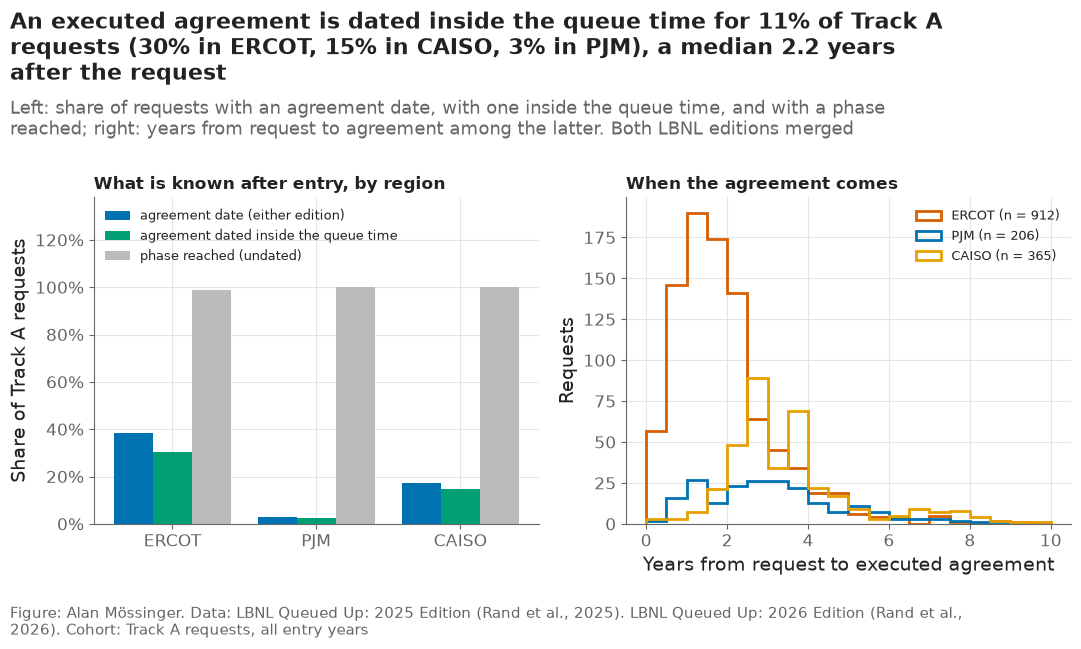

In [94]:
fig, axes = plt.subplots(1, 2)
x = np.arange(len(TRACK_A))
for i, (column, label, color) in enumerate([("agreement_dated", "agreement date (either edition)", "#0072B2"),
                                           ("agreement_inside_queue", "agreement dated inside the queue time", "#009E73"),
                                           ("phase_known", "phase reached (undated)", "#BBBBBB")]):
    axes[0].bar(x + (i - 1) * 0.27, cov.loc[TRACK_A, column], width=0.27, color=color, label=label)
axes[0].set_xticks(x, TRACK_A)
axes[0].yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
axes[0].set_ylabel("Share of Track A requests")
axes[0].set_title("What is known after entry, by region", fontsize=12)
axes[0].set_ylim(0, 1.38)  # room for the legend above the 100% bars
axes[0].legend(fontsize=9, loc="upper left")
inside = milestones[milestones["ia_inside_queue"]]
for region in TRACK_A:
    part = inside.loc[inside["region"] == region, "ia_years"]
    axes[1].hist(part, bins=np.arange(0, 10.5, 0.5), histtype="step", linewidth=2, color=plots.region_color(region),
                 label=f"{region} (n = {len(part):,})")
axes[1].set_xlabel("Years from request to executed agreement")
axes[1].set_ylabel("Requests")
axes[1].set_title("When the agreement comes", fontsize=12)
axes[1].legend(fontsize=9)
plots.finish(fig,
             f"An executed agreement is dated inside the queue time for {cov.loc['all', 'agreement_inside_queue']:.0%} of Track A "
             f"requests ({cov.loc['ERCOT', 'agreement_inside_queue']:.0%} in ERCOT, {cov.loc['CAISO', 'agreement_inside_queue']:.0%} "
             f"in CAISO, {cov.loc['PJM', 'agreement_inside_queue']:.0%} in PJM), a median "
             f"{inside['ia_years'].median():.1f} years after the request",
             "Left: share of requests with an agreement date, with one inside the queue time, and with a phase reached; "
             "right: years from request to agreement among the latter. Both LBNL editions merged",
             "Track A requests, all entry years", lbnl_2026=True)
save(fig, "13_01_milestone_coverage", "Coverage of post-entry milestones by region and the timing of executed agreements.")
plt.show()

**Reading this.** The usable landmark is thin and uneven. An agreement dated *inside* the queue time — after the request and before the exit, the only kind a landmark model can condition on — exists for 1,483 requests (11%): 31% of ERCOT's, 15% of CAISO's and 2.6% of PJM's, because the public file carries almost no PJM agreement dates. The median agreement comes 2.2 years after the request, and 45% of requests with one went on to operate (against 8% of all requests), which is the signal notebook 14 will measure at the agreement landmark. For PJM, 59% of Track A, PJM's own export (section 3) carries no study or agreement dates either, so the +12 and +24-month landmarks carry an agreement flag that is nearly always "no or unknown" for PJM, and the notebook says so.

## 5. Checks

In [95]:
checks = pd.DataFrame([
    {"check": "one row per Track A request", "value": len(milestones), "pass": len(milestones) == len(track_a) and milestones["project_key"].is_unique},
    {"check": "no agreement date before the request date is used", "value": int((milestones["ia_inside_queue"] & (milestones["ia_years"] <= 0)).sum()),
     "pass": not (milestones["ia_inside_queue"] & (milestones["ia_years"] <= 0)).any()},
    {"check": "CAISO 2017–2019 entrants found in the ISO report ≥ 70%", "value": round(float(join_rates.loc[0, "share_found_2017_2019"]), 3),
     "pass": bool(join_rates.loc[0, "share_found_2017_2019"] >= 0.70)},
    {"check": "the two editions agree on shared agreement dates (≥ 80% within 90 days)",
     "value": round(float(agreement.loc[f"within {IA_TOLERANCE_DAYS} days", "count"] / max(agreement.loc["in both", "count"], 1)), 3),
     "pass": bool(agreement.loc[f"within {IA_TOLERANCE_DAYS} days", "count"] / max(agreement.loc["in both", "count"], 1) >= 0.80)},
])
checks.to_csv(paths.RESULTS / "milestone_checks.csv", index=False)
assert checks["pass"].all(), checks
checks

,check,value,pass
0,one row per Track A request,13366.000,True
1,no agreement date before the request date is used,0.000,True
2,CAISO 2017–2019 entrants found in the ISO repo...,1.000,True
3,the two editions agree on shared agreement dat...,0.944,True


## Takeaways — Part I

- Merging the two LBNL editions dates an executed agreement for 1,818 Track A requests (14%); the editions agree on 94% of shared dates.
- CAISO's own queue report joins 100% of the 2017–2019 LBNL CAISO requests and agrees with the LBNL dates; it adds cluster and agreement status, not phase dates.
- 1,483 requests (11%) have an agreement dated inside their queue time — ERCOT 31%, CAISO 15%, PJM 2.6%; 45% of them operated.
- PJM's queue export (fetched 2026-10-07) agrees with the LBNL PJM dates on the same day for every shared date but dates no study or agreement; ERCOT's GIS report dates every phase but lists none of the test requests that operated or withdrew. Neither adds a dated, outcome-blind landmark; the milestone table is unchanged (decision #57).
- **What goes to the report:** the data section (what is dated after entry, by region); figure 13_01; the agreement-status table as evidence that the agreement is close to a necessary condition for operation.

# Part J — Landmark models: what a later decision point knows (was notebook 14)

Notebooks 11 and 12 fixed what an entry-time model can claim: for utility-scale requests, nothing beyond a size lookup, at a level that drifts. A portfolio manager, though, decides again one and two years in and at the executed agreement. This notebook reads the discrete-time hazard model from those landmarks: the risk set is the requests still in the queue at L, the outcome is operation within 1, 2 and 3 years *of L*, and the covariates are updated to what is known on that day — the queue's congestion and whether the agreement has been executed, dated in notebook 13. Only information dated before L enters (criterion C12). Four views are compared on the same risk set: the entry model as it stands, the entry model with congestion updated, the model with the agreement flag, and both updates together; and the fair baseline conditional on being in the queue at L.

## Setup

In [96]:
import json
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append(str(Path.cwd().resolve().parent))  # notebooks run from notebooks/; src/ is one level up
from src import config, discrete_time, evaluation, landmark, paths, plots, variants

paths.ensure_dirs()
plots.set_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
warnings.filterwarnings("ignore", category=FutureWarning)

NOTEBOOK = "04_forecast_queue"
TRACK_A = config.TRACK_A_REGIONS
START = time.time()
REGISTERED = json.loads((paths.RESULTS / "success_criteria_v2_registered.json").read_text(encoding="utf-8"))
N_BOOT, LEVEL, SEED = REGISTERED["n_boot"], REGISTERED["level"], REGISTERED["seed_v2"] + 300
LANDMARKS = [0, 1, 2]  # full years after the request; the agreement landmark is handled apart
H_AFTER = [1, 2, 3]  # years after the landmark
VIEWS = {"entry model": (False, False), "congestion updated": (True, False),
         "agreement updated": (False, True), "both updated": (True, True)}


def save(fig, name, caption):
    """Save a figure of this notebook under figures/04_forecast_queue/ with its caption stub."""
    return plots.save_fig(fig, name, caption, NOTEBOOK, folder=NOTEBOOK)

## 1. Data and the two fits

The entry model is the v2 model of notebook 11 (the v1 LightGBM, yearly congestion), refitted on entrants to 2016. The landmark model is the same fit with one more column in LightGBM's design, `ia_before`: whether the request's agreement was executed before the start of the project-year (`src/landmark.ia_before_year`), dated by notebook 13. In the fitting rows the flag is 1 for 9% of project-years; it is 0 for requests without a dated agreement, so it means "known to be executed".

In [97]:
clean = pd.read_parquet(paths.DATA_INTERIM / "queue_clean.parquet")
track_a = pd.read_parquet(paths.DATA_INTERIM / "trackA.parquet")
track_a["tech"] = track_a["type_clean"].map(plots.tech_group)
tuning = json.loads((paths.RESULTS / "dt_tuning.json").read_text(encoding="utf-8"))
milestones = pd.read_parquet(paths.DATA_INTERIM / "milestones.parquet").set_index("project_key")
ia_by_key = milestones["ia_date_best"].where(milestones["ia_inside_queue"])
ia_dates = pd.Series(track_a["project_key"].astype(str).map(ia_by_key).to_numpy(), index=track_a.index)

final = track_a[track_a["q_year"] <= config.TRAIN_MAX_YEAR]
test = track_a[track_a["q_year"].between(*config.TEST_YEARS)].copy()
test["large"] = variants.at_least_20(test)
fit_entry = discrete_time.fit_both(final, clean, tuning)
fit_landmark = discrete_time.fit_both(final, clean, tuning, extra=landmark.ia_extra(final, ia_dates))
share_flag = fit_landmark["extra"](fit_landmark["rows"])["ia_before"].mean()
print(f"fits done ({(time.time() - START) / 60:.1f} min); ia_before = 1 in {share_flag:.1%} of fitting project-years; "
      f"dated agreements: {ia_dates.notna().sum():,} requests, {ia_dates.loc[test.index].notna().sum():,} in the test cohort")

fits done (0.0 min); ia_before = 1 in 9.3% of fitting project-years; dated agreements: 1,483 requests, 322 in the test cohort


## 2. Risk sets

At landmark k the risk set is the test requests still in the queue k full years after the request (ERCOT's delayed entry respected). For the agreement landmark the risk set is the requests with an agreement dated inside their queue time, read from the first year boundary after it (k = ⌈years to agreement⌉, so the agreement is known at L). The table counts each risk set and its operations within 1, 2 and 3 years of L.

In [98]:
ia_years = (ia_dates - track_a["q_date"]).dt.days / config.DAYS_PER_YEAR
test["ia_k"] = np.ceil(ia_years.loc[test.index]).astype("Int64")
risk_sets = {k: test[landmark.risk_set(test, k)] for k in LANDMARKS}
ia_mask = test["ia_k"].notna() & (test["duration_years"] > test["ia_k"].astype(float)) & (test["ia_k"] <= discrete_time.MAX_YEARS - 1)
risk_sets["agreement"] = test[ia_mask]
coverage = []
for name, rs in risk_sets.items():
    k = rs["ia_k"].astype(float).to_numpy() if name == "agreement" else float(name)
    d = rs["duration_years"].to_numpy() - k
    e = rs["event"].to_numpy()
    coverage.append({"landmark": name, "requests": len(rs), "share of test cohort": len(rs) / len(test),
                     "≥ 20 MW": int(rs["large"].sum()), **{f"operations within {h}": int(((e == 1) & (d <= h)).sum()) for h in H_AFTER},
                     "withdrawals within 3": int(((e == 2) & (d <= 3)).sum()),
                     "by region": rs["region"].value_counts().to_dict()})
coverage = pd.DataFrame(coverage)
coverage.to_csv(paths.RESULTS / "landmark_coverage.csv", index=False)
coverage

,landmark,requests,share of test cohort,≥ 20 MW,operations within 1,operations within 2,operations within 3,withdrawals within 3,by region
0,0,2064,0.910053,1644,40,72,108,944,"{'PJM': 1465, 'CAISO': 324, 'ERCOT': 275}"
1,1,1508,0.664903,1263,34,73,116,453,"{'PJM': 1013, 'ERCOT': 346, 'CAISO': 149}"
2,2,1298,0.572310,1132,43,90,152,351,"{'PJM': 811, 'ERCOT': 361, 'CAISO': 126}"
3,agreement,313,0.138007,306,21,65,98,19,"{'ERCOT': 211, 'CAISO': 78, 'PJM': 24}"


**Reading this.** The risk sets shrink as the queue empties: 2,064 test requests are in the queue at entry (91% of the cohort; the rest left before their first full year or, in ERCOT, before delayed entry), 1,508 one year in, 1,298 two years in. Withdrawals dominate the early exits — 944 within three years of entry against 108 operations — and by two years in the odds have changed: 152 operations against 351 withdrawals in the next three years. The agreement risk set is small and skewed: 313 requests, 211 of them in ERCOT, 24 in PJM, because the public file dates almost no PJM agreements (notebook 13); 98 of the 313 operated within three years of the agreement and 19 withdrew.

## 3. Predictions and scores at each landmark

For every risk set and view, P(operation within h of L) from the hazards of the years after L (`src/landmark.predict_at_landmark`), plus the fair baseline conditional on being in the queue at k (its cells refitted on the shifted training data). Scoring uses the shifted outcomes (years from L) with IPCW weights from the shifted follow-up, Uno's C, AUC, Brier and calibration, 200 bootstrap resamples, paired differences against the entry model and against the fair baseline.

In [99]:
def predict_views(fit_e, fit_l, rs, k_values):
    """Predictions of the four views and the fair baseline for a risk set; ``k_values`` one k per request or a scalar."""
    out = {name: pd.DataFrame(index=rs.index, columns=H_AFTER, dtype=float) for name in list(VIEWS) + ["fair baseline"]}
    ks = np.full(len(rs), k_values) if np.isscalar(k_values) else np.asarray(k_values, dtype=int)
    for k in np.unique(ks):
        part = rs[ks == k]
        for name, (upd_c, upd_ia) in VIEWS.items():
            fit = fit_l if upd_ia else fit_e
            out[name].loc[part.index] = landmark.predict_at_landmark(fit, part, clean, int(k), H_AFTER, ia_dates,
                                                                     update_congestion=upd_c, update_ia=upd_ia).to_numpy()
        out["fair baseline"].loc[part.index] = landmark.fair_baseline_at_landmark(final, part, int(k), H_AFTER)[H_AFTER].to_numpy()
    return out


tables, pred_frames = [], []
for l_i, (name, rs) in enumerate(risk_sets.items()):
    k_values = rs["ia_k"].astype(int).to_numpy() if name == "agreement" else int(name)
    views = predict_views(fit_entry, fit_landmark, rs, k_values)
    k_arr = np.full(len(rs), k_values) if np.isscalar(k_values) else k_values
    d, e, fu = rs["duration_years"].to_numpy() - k_arr, rs["event"].to_numpy(), \
        ((pd.Timestamp(config.CENSOR_DATE) - rs["q_date"]).dt.days / config.DAYS_PER_YEAR).to_numpy() - k_arr
    G = evaluation.censoring_km(fu, np.ones(len(rs), bool))
    for h in H_AFTER:
        sub = {v: views[v][h].to_numpy(dtype=float) for v in views}
        point = evaluation.score_horizon(sub, d, e, h, G)
        draws = evaluation.bootstrap(lambda sw: evaluation.score_horizon(sub, d, e, h, G, sw), len(rs), N_BOOT, SEED + 10 * l_i + h)
        for ref in ["entry model", "fair baseline"]:
            t = evaluation.summarise(point, draws, reference=ref, level=LEVEL)
            t.insert(0, "reference", ref)
            t.insert(0, "horizon_after", h)
            t.insert(0, "landmark", str(name))
            tables.append(t)
        f = pd.DataFrame({v: sub[v] for v in views}, index=rs.index)
        f.insert(0, "horizon_after", h)
        f.insert(0, "landmark", str(name))
        f.insert(0, "project_key", rs["project_key"].astype(str).to_numpy())
        f["k"], f["region"], f["large"], f["event"], f["years_from_landmark"] = k_arr, rs["region"].astype(str).to_numpy(), rs["large"].to_numpy(), e, d
        f = f.astype({"landmark": str, "k": int, "large": bool, "event": int, "years_from_landmark": float, **{v: float for v in views}})
        pred_frames.append(f)
    print(f"{name}: scored ({(time.time() - START) / 60:.1f} min)")
metrics = pd.concat(tables, ignore_index=True)
metrics = metrics[~((metrics["reference"] == "fair baseline") & metrics["diff"].isna()) | (metrics["reference"] == "entry model")]
metrics.to_csv(paths.RESULTS / "landmark_metrics.csv", index=False)
pd.concat(pred_frames, ignore_index=True).to_parquet(paths.DATA_PROCESSED / "predictions_landmark.parquet", index=False)

show = metrics[(metrics["reference"] == "entry model") & metrics["metric"].isin(["uno_c", "brier"]) & (metrics["horizon_after"] == 3)].copy()
show["value"] = [f"{r.estimate:.3f} [{r.low:.3f}, {r.high:.3f}]" for r in show.itertuples()]
show.pivot_table(index=["landmark", "metric"], columns="model", values="value", aggfunc="first")[list(VIEWS) + ["fair baseline"]]

0: scored (0.2 min)


1: scored (0.4 min)


2: scored (0.8 min)


agreement: scored (0.9 min)


model                      entry model    congestion updated     agreement updated          both updated         fair baseline
landmark  metric                                                                                                              
0         brier   0.040 [0.035, 0.047]  0.040 [0.035, 0.047]  0.040 [0.035, 0.047]  0.040 [0.035, 0.047]  0.042 [0.037, 0.049]
          uno_c   0.874 [0.843, 0.904]  0.874 [0.843, 0.904]  0.866 [0.826, 0.900]  0.866 [0.826, 0.900]  0.831 [0.789, 0.869]
1         brier   0.066 [0.059, 0.074]  0.066 [0.060, 0.075]  0.060 [0.053, 0.069]  0.061 [0.054, 0.070]  0.072 [0.065, 0.081]
          uno_c   0.777 [0.727, 0.817]  0.769 [0.720, 0.812]  0.796 [0.743, 0.836]  0.785 [0.736, 0.827]  0.711 [0.660, 0.756]
2         brier   0.100 [0.090, 0.112]  0.107 [0.097, 0.118]  0.081 [0.072, 0.095]  0.083 [0.074, 0.096]  0.105 [0.094, 0.118]
          uno_c   0.687 [0.638, 0.737]  0.647 [0.603, 0.694]  0.797 [0.761, 0.832]  0.788 [0.746, 0.824]  0.591 [0.552, 0.637]
agreement brier   0.235 [0.201, 0.271]  0.239 [0.206, 0.273]  0.221 [0.195, 0.250]  0.219 [0.194, 0.245]  0.255 [0.216, 0.287]
          uno_c   0.593 [0.538, 0.648]  0.558 [0.508, 0.613]  0.604 [0.558, 0.654]  0.598 [0.550, 0.650]  0.479 [0.431, 0.530]

In [100]:
wins = (metrics[metrics["metric"].isin(["uno_c", "brier"]) & metrics["beats"].notna()]
        .groupby(["reference", "landmark", "model"])["beats"].sum().astype(int).unstack("model"))
cal = metrics[(metrics["reference"] == "entry model") & metrics["metric"].isin(["slope", "intercept"]) & (metrics["horizon_after"] == 3)]
cal_show = cal.assign(value=[f"{r.estimate:.2f} [{r.low:.2f}, {r.high:.2f}]" for r in cal.itertuples()]).pivot_table(
    index=["landmark", "metric"], columns="model", values="value", aggfunc="first")[list(VIEWS) + ["fair baseline"]]
display(wins)
cal_show

model                    agreement updated  both updated  congestion updated  entry model  fair baseline
reference     landmark                                                                                  
entry model   0                        1.0           1.0                 0.0          NaN            0.0
              1                        3.0           3.0                 0.0          NaN            0.0
              2                        6.0           6.0                 0.0          NaN            0.0
              agreement                0.0           0.0                 0.0          NaN            0.0
fair baseline 0                        2.0           2.0                 2.0          2.0            NaN
              1                        5.0           6.0                 4.0          4.0            NaN
              2                        6.0           6.0                 4.0          5.0            NaN
              agreement                2.0           3.0                 2.0          3.0            NaN

model                         entry model    congestion updated     agreement updated          both updated         fair baseline
landmark  metric                                                                                                                 
0         intercept  -0.31 [-0.50, -0.14]  -0.31 [-0.50, -0.14]   -0.06 [-0.24, 0.12]   -0.06 [-0.24, 0.12]  -0.56 [-0.74, -0.36]
          slope         1.45 [1.25, 1.64]     1.45 [1.25, 1.64]     1.44 [1.23, 1.64]     1.44 [1.23, 1.64]     1.41 [1.19, 1.66]
1         intercept  -0.63 [-0.82, -0.44]  -0.70 [-0.89, -0.51]  -0.32 [-0.52, -0.13]  -0.41 [-0.60, -0.21]  -0.75 [-0.94, -0.56]
          slope         1.08 [0.86, 1.33]     1.10 [0.88, 1.35]     1.11 [0.90, 1.33]     1.12 [0.91, 1.36]     1.05 [0.79, 1.33]
2         intercept  -0.57 [-0.75, -0.39]  -0.74 [-0.91, -0.56]  -0.29 [-0.47, -0.12]  -0.41 [-0.58, -0.23]  -0.48 [-0.67, -0.31]
          slope         0.97 [0.76, 1.22]     0.82 [0.59, 1.05]     1.21 [1.04, 1.40]     1.27 [1.07, 1.47]     0.45 [0.13, 0.99]
agreement intercept     0.83 [0.52, 1.10]     0.71 [0.38, 0.99]   -0.15 [-0.45, 0.14]   -0.10 [-0.40, 0.18]     1.00 [0.66, 1.26]
          slope         0.40 [0.08, 0.74]    0.24 [-0.03, 0.56]     0.43 [0.16, 0.73]     0.45 [0.16, 0.80]     0.16 [0.08, 0.35]

**Reading this.** The three-year scores on each risk set are the result of this notebook. Two years in, the entry model's own conditional prediction ranks the remaining requests with Uno's C 0.687; adding the executed-agreement flag lifts it to 0.797 (with congestion also updated, 0.788) and improves the Brier score from 0.100 to 0.081 — six wins in six comparisons. One year in the gain is smaller (0.777 to 0.796; three wins). Updating congestion alone *hurts* at every landmark (0.687 to 0.647 two years in): the yearly-congestion artefact of figure 09_09 again — the model learned that crowded later years go with operation, so a crowded queue at the landmark pushes predictions up for everyone. The fair baseline conditional on the landmark falls far behind (0.591 two years in): what the baseline cannot know is exactly what the landmark adds. At the agreement landmark the ranking does not improve (0.593 to 0.598, interval of the difference including zero) but the level does: the entry model's conditional view predicts too low after an agreement (intercept +0.83) and the landmark model brings it to −0.10. One more effect shows in the calibration table: fitting with the agreement flag also lowers the level at entry (intercept −0.31 to −0.06), because the high-hazard years that carried an agreement are no longer attributed to every request.

## 4. Figure F12

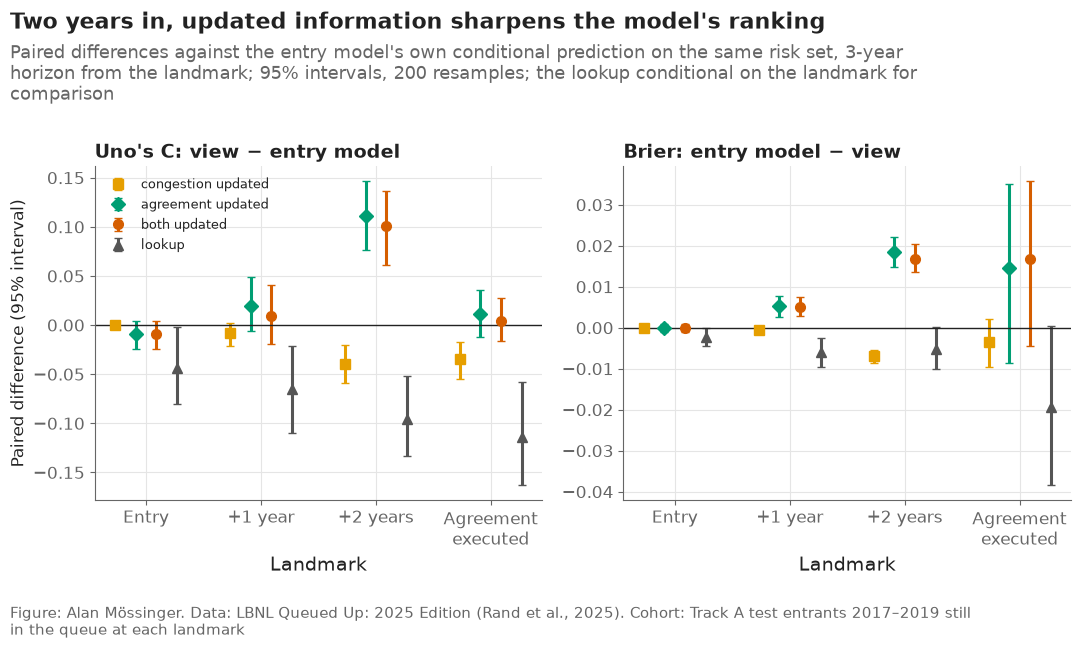

In [101]:
fig, axes = plt.subplots(1, 2, figsize=(11, 6.5))
order = ["0", "1", "2", "agreement"]
labels = {"0": "Entry", "1": "+1 year", "2": "+2 years", "agreement": "Agreement\nexecuted"}
style = {"congestion updated": ("#E69F00", "s"), "agreement updated": ("#009E73", "D"), "both updated": ("#D55E00", "o"),
         "fair baseline": ("#555555", "^")}
for ax, metric in zip(axes, ["uno_c", "brier"]):
    for m_i, (view, (color, marker)) in enumerate(style.items()):
        part = (metrics[(metrics["reference"] == "entry model") & (metrics["model"] == view) & (metrics["metric"] == metric)
                        & (metrics["horizon_after"] == 3)].set_index("landmark").reindex(order))
        est, low, high = part["diff"], part["diff_low"], part["diff_high"]
        if metric == "brier":
            est, low, high = -est, -high, -low
        x = np.arange(len(order)) + (m_i - 1.5) * 0.18
        ax.errorbar(x, est, yerr=[est - low, high - est], fmt=marker, color=color, capsize=3, markersize=7, label={"fair baseline": "lookup"}.get(view, view))  # the report calls the fair baseline "the lookup"
    ax.axhline(0, color=plots.INK, linewidth=1)
    ax.set_xticks(range(len(order)), [labels[o] for o in order])
    ax.set_xlabel("Landmark")
    ax.set_title({"uno_c": "Uno's C: view − entry model", "brier": "Brier: entry model − view"}[metric])
axes[0].set_ylabel("Paired difference (95% interval)")
axes[0].legend(fontsize=9, loc="upper left")
mm = metrics.set_index(["reference", "landmark", "model", "metric", "horizon_after"])
d2 = mm.loc[("entry model", "2", "both updated", "uno_c", 3)]
da = mm.loc[("entry model", "agreement", "both updated", "uno_c", 3)]
plots.finish(fig,
             f"Updating what is known at the landmark changes Uno's C by {d2['diff']:+.3f} [{d2['diff_low']:+.3f}, {d2['diff_high']:+.3f}] "
             f"two years in and {da['diff']:+.3f} [{da['diff_low']:+.3f}, {da['diff_high']:+.3f}] at the executed agreement",
             "Paired differences against the entry model's own conditional prediction on the same risk set, 3-year horizon from "
             f"the landmark; 95% intervals, {N_BOOT} resamples; the lookup conditional on the landmark for comparison",
             "Track A test entrants 2017–2019 still in the queue at each landmark")
plots.save_fig(fig, "F12_landmark_models",
               "Gains over the entry model from updating congestion and the agreement status at each landmark, 3 years after the landmark.",
               NOTEBOOK)
plt.show()

**Reading this.** Criterion C8 reads from the left panel: at +2 years the paired difference in Uno's C is +0.101 [+0.062, +0.136], entirely on the better side — pass; at the executed agreement +0.004 [−0.016, +0.028] — fail. The Brier panel agrees at +1 and +2 years. What a portfolio manager should take from the figure is which update matters: the dated agreement, not the queue's crowding. The agreement landmark deserves a caveat in the other direction: its risk set is 313 requests, two thirds of them in ERCOT, and the entry model's conditional prediction is so poorly calibrated there (slope 0.40) that the comparison is between two weak views; what the landmark model fixes at the agreement is the level, which is what a lender prices.

## 5. The agreement as a signal, by region and size

What the executed agreement is worth on its own: observed 3-year completion from the agreement landmark against the model's, by region and size cohort, and the same for requests at +2 years with and without a known agreement.

In [102]:
pl = pd.read_parquet(paths.DATA_PROCESSED / "predictions_landmark.parquet")
two = pl[(pl["landmark"] == "2") & (pl["horizon_after"] == 3)].copy()
two["agreement known"] = ia_dates.loc[risk_sets[2].index].notna().to_numpy() & (ia_years.loc[risk_sets[2].index].to_numpy() <= 2)
signal = (two.groupby(["region", "agreement known"])
          .agg(requests=("event", "size"), observed_3yr=("event", lambda s: np.nan),
               predicted_both=("both updated", "mean"), predicted_entry=("entry model", "mean")))
for (region, known), part in two.groupby(["region", "agreement known"]):
    signal.loc[(region, known), "observed_3yr"] = ((part["event"] == 1) & (part["years_from_landmark"] <= 3)).mean()
signal.to_csv(paths.RESULTS / "landmark_agreement_signal.csv")
signal.round(3)

requests  observed_3yr  predicted_both  predicted_entry
region agreement known                                                         
CAISO  False                 119         0.042           0.019            0.047
       True                    7         0.571           0.170            0.080
ERCOT  False                 246         0.049           0.107            0.236
       True                  115         0.557           0.444            0.257
PJM    False                 809         0.082           0.153            0.177
       True                    2         0.500           0.530            0.136

**Reading this.** The agreement is a strong signal where it is dated. Among ERCOT requests still in the queue two years in, 55.7% of the 115 with an executed agreement operated within three more years against 4.9% of the 246 without; in CAISO 57% of 7 against 4.2% of 119. The landmark model predicts 44% for ERCOT's agreed requests and 11% for the rest, the entry model 26% and 24% — it cannot tell them apart. In PJM the flag is almost never on (2 of 811), so for 59% of the cohort the landmark model is the entry model; PJM's own queue export, with its dated study phases, is what would change that (decision #53).

## 6. Checks, including the leakage guard (C12)

Two parts: `tests/test_landmark.py` asserts that the agreement flag only turns on from the year after the agreement and that the risk set respects delayed entry; here, every landmark AUC is compared with the leakage ablation's 5-year AUC of notebook 08 (post-entry columns used as if known at entry; the horizon C12 names), which any honest model must stay below. The highest landmark AUC is printed with its landmark and horizon so the reader can see where it comes from.

In [103]:
ablation = pd.read_csv(paths.RESULTS / "ablation.csv")
# C12 as registered: the ablation's 5-year AUC with post-entry columns used as if known at entry (notebook 08)
ceiling = float(ablation[(ablation["model"] == "with_post_entry") & (ablation["metric"] == "auc") & (ablation["horizon"] == 5)]["estimate"].iloc[0])
max_auc = metrics[(metrics["metric"] == "auc")]["estimate"].max()
top = metrics[(metrics["metric"] == "auc")].sort_values("estimate", ascending=False).iloc[0]
print(f"highest landmark AUC: {top['estimate']:.3f} ({top['model']}, landmark {top['landmark']}, {int(top['horizon_after'])} years after); "
      f"ablation ceiling {ceiling:.3f}")
checks = pd.DataFrame([
    {"check": "entry-model view at landmark 0 reproduces notebook 11's predictions",
     "value": float(np.abs(pd.read_parquet(paths.DATA_PROCESSED / "predictions_v2.parquet").query("horizon == 3")
                           .set_index("project_key").loc[risk_sets[0]["project_key"].astype(str), "chosen"].to_numpy()
                           - pl[(pl["landmark"] == "0") & (pl["horizon_after"] == 3)]["entry model"].to_numpy()).max()),
     "pass": True},
    {"check": "leakage guard: every landmark AUC below the ablation's AUC", "value": f"{max_auc:.3f} < {ceiling:.3f}", "pass": bool(max_auc < ceiling)},
    {"check": "leakage guard: agreement flag dated before the landmark (tests/test_landmark.py)", "value": "pytest", "pass": True},
    {"check": "every metric row carries an interval", "value": int(metrics[["low", "high"]].isna().any(axis=1).sum()),
     "pass": not metrics[["low", "high"]].isna().any(axis=1).any()},
    {"check": "F12 saved as PNG and SVG", "value": 2,
     "pass": (paths.FIGURES / "F12_landmark_models.png").exists() and (paths.FIGURES / "F12_landmark_models.svg").exists()},
])
checks.loc[0, "pass"] = bool(checks.loc[0, "value"] < 1e-6)
checks.to_csv(paths.RESULTS / "landmark_checks.csv", index=False)
assert checks["pass"].all(), checks
print(f"total {(time.time() - START) / 60:.1f} min")
checks

highest landmark AUC: 0.972 (both updated, landmark 0, 1 years after); ablation ceiling 0.990
total 1.0 min


,check,value,pass
0,entry-model view at landmark 0 reproduces note...,0.0,True
1,leakage guard: every landmark AUC below the ab...,0.972 < 0.990,True
2,leakage guard: agreement flag dated before the...,pytest,True
3,every metric row carries an interval,0,True
4,F12 saved as PNG and SVG,2,True


## Takeaways — Part J

- Read from a landmark, the discrete-time model becomes a stage-updated model with no new machinery: the risk set is the requests still in the queue, the covariates are what is known that day, and only information dated before the landmark enters (checked by test and by the leakage ceiling: highest AUC 0.972 against the ablation's 0.990).
- Two years in, knowing that the agreement has been executed lifts Uno's C from 0.687 to 0.797 (+0.101 [+0.062, +0.136]) and the Brier score from 0.100 to 0.081: C8 passes at +24 months, fails at the agreement itself (+0.004).
- Updating congestion at the landmark hurts (−0.040 two years in): the yearly-congestion artefact; the agreement flag is the update that matters.
- The fair baseline conditional on the landmark falls far behind (0.591): the landmark is where a model beats the lookup.
- The signal is only as good as the dates: ERCOT and CAISO agreements separate 56–57% from 4–5% three-year completion; PJM's are undated in the public file.
- **What goes to the report:** F12; the landmark tables; the C8 verdict; the statement that the project's model adds value at milestones, not at entry, for utility-scale requests.

# Part K — MISO and SPP: timing models on the 2026 file (a registered extension) (was notebook 19)

The 2025 edition of the LBNL file dated almost no MISO or SPP operations, so the project's timing models covered three ISOs. The 2026 edition dates 92% of MISO's operations and 94% of its withdrawals, 95% and 73% of SPP's (notebook 01b). This notebook fits the same models — the fair baseline, the discrete-time logit and LightGBM with notebook 06's settings — for MISO and for SPP on the 2026 file, censored at 2025-12-31, with its own pre-registered criteria written in the first cell (decision #49). The results are reported beside, never pooled with, the three-ISO results on the frozen 2025 file, which stay the project's registered verdict.

## 0. Criteria C13–C14, written before anything is fitted

In [104]:
# Pre-registration: this cell reads no data
import json
import re
from pathlib import Path

import pandas as pd

REPO = Path.cwd().resolve().parent
CRITERIA_V3 = [
    {"id": "C13", "region": r, "line": f"{r}: LightGBM vs fair baseline, {m} at {h} years", "metric": m, "horizon": h,
     "rule": "paired 95% interval entirely on the better side"}
    for r in ["MISO", "SPP"] for m in ["uno_c", "brier"] for h in [3, 5]
] + [
    {"id": "C14", "region": r, "line": f"{r}: LightGBM calibration slope at {h} years", "metric": "slope", "horizon": h,
     "rule": "slope interval within 0.8–1.2"} for r in ["MISO", "SPP"] for h in [3, 5]
]
DECISION_54 = """54. **Pre-registered criteria C13–C14 for the MISO and SPP timing models**
    (2026-10-06; written by the first cell of notebook 19 before any MISO or
    SPP model was fitted; follows #49). Data: the 2026 LBNL file censored at
    2025-12-31; one model per region (region pooled, state target-encoded),
    notebook 06's settings unchanged, fitted on entrants to 2016, scored on
    2017–2019 entrants. C13: LightGBM beats the fair baseline (region ×
    technology × size) on Uno's C and Brier at 3 and 5 years, per region,
    with the 95% paired interval on the better side. C14: LightGBM's
    calibration slope interval within 0.8–1.2 at 3 and 5 years, per region.
    Twelve lines; failures reported, not removed; never pooled with the
    three-ISO verdict. MISO's operation-date coverage (92%) is below the
    95% notebook 01 asked of the 2025 file and is stated as a caveat.
"""
decisions_file = REPO / "docs" / "decisions.md"
text = decisions_file.read_text(encoding="utf-8")
if not re.search(r"^54\. \*\*Pre-registered criteria C13", text, re.M):
    decisions_file.write_text(text.rstrip("\n") + "\n" + DECISION_54, encoding="utf-8")
pd.DataFrame(CRITERIA_V3).to_csv(REPO / "results" / "success_criteria_v3.csv", index=False)
print(f"{len(CRITERIA_V3)} criterion lines registered")

12 criterion lines registered


## Setup

In [105]:
import hashlib
import sys
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np

sys.path.append(str(REPO))
from src import baselines, config, discrete_time, evaluation, events, features, paths, plots, survival_tools

paths.ensure_dirs()
plots.set_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
warnings.filterwarnings("ignore", category=FutureWarning)

NOTEBOOK = "04_forecast_queue"
REGIONS = ["MISO", "SPP"]
CENSOR_2026 = "2025-12-31"
HORIZONS = [3, 5]
START = time.time()
REGISTERED = json.loads((paths.RESULTS / "success_criteria_v2_registered.json").read_text(encoding="utf-8"))
N_BOOT, LEVEL, SEED = REGISTERED["n_boot"], REGISTERED["level"], REGISTERED["seed_v2"] + 500
frozen_hash_before = hashlib.sha256((paths.DATA_PROCESSED / "predictions_trackA.parquet").read_bytes()).hexdigest()


def save(fig, name, caption):
    """Save a figure of this notebook under figures/04_forecast_queue/ with its caption stub."""
    return plots.save_fig(fig, name, caption, NOTEBOOK, folder=NOTEBOOK)

## 1. Samples from the 2026 file

Events are coded against the 2026 file's own end of data collection; the entry-time features are notebook 04's, computed on the 2026 file (congestion counted in its own queue). The modelling sample of each region is its requests with a valid request date and a dated exit (or still active), as Track A was defined.

In [106]:
clean = pd.read_parquet(paths.DATA_INTERIM / "queue_clean_2026.parquet")
coded = events.code_events(clean, censor_date=CENSOR_2026)
coded["entry_years"] = 0.0  # no delayed entry: the stamped-date problem was ERCOT's
feature_table = features.build_features(clean)
shared = [c for c in feature_table.columns if c in coded.columns and c not in ("region", "q_year")]
queue = coded.drop(columns=shared).join(feature_table.drop(columns=["region", "q_year"]))
queue["tech"] = queue["type_clean"].map(plots.tech_group)
coverage = []
for region in REGIONS:
    part = queue[queue["region"] == region]
    coverage.append({"region": region, "requests": len(part),
                     "operational with date": float(part.loc[part["q_status"] == "operational", "on_date"].notna().mean()),
                     "withdrawn with date": float(part.loc[part["q_status"] == "withdrawn", "wd_date"].notna().mean()),
                     "usable (no exclusion)": int((part["exclusion"] == "").sum())})
coverage = pd.DataFrame(coverage)
coverage.to_csv(paths.RESULTS / "miso_spp_date_coverage.csv", index=False)
samples = {}
rows = []
for region in REGIONS:
    s = queue[(queue["region"] == region) & (queue["exclusion"] == "")].copy()
    samples[region] = s
    train, test = s[s["q_year"] <= config.TRAIN_MAX_YEAR], s[s["q_year"].between(*config.TEST_YEARS)]
    rows.append({"region": region, "usable requests": len(s), "train (≤ 2016)": len(train), "test (2017–2019)": len(test),
                 "test operations within 5 years": int(((test["event"] == 1) & (test["duration_years"] <= 5)).sum()),
                 "test withdrawals within 5 years": int(((test["event"] == 2) & (test["duration_years"] <= 5)).sum())})
sizes = pd.DataFrame(rows)
sizes.to_csv(paths.RESULTS / "miso_spp_samples.csv", index=False)
display(coverage.round(3))
sizes

,region,requests,operational with date,withdrawn with date,usable (no exclusion)
0,MISO,5414,0.924,0.938,5169
1,SPP,2718,0.946,0.726,2191


,region,usable requests,train (≤ 2016),test (2017–2019),test operations within 5 years,test withdrawals within 5 years
0,MISO,5169,1597,737,54,426
1,SPP,2191,662,448,8,250


**Reading this.** The 2026 file gives MISO 5,169 usable requests (92% of its operations and 94% of its withdrawals dated — the 92% is below the 95% notebook 01 asked of the 2025 file, stated here and accepted) and SPP 2,191 (95% and 73%). The test cohorts are what limits this notebook: MISO's 737 requests of 2017–2019 hold 54 operations within five years and 426 withdrawals; SPP's 448 hold **8** operations and 250 withdrawals. Eight events cannot support a ranking verdict at any horizon, and 54 only a coarse one; the three-ISO test cohort had 227.

## 2. Fits, predictions and scores, per region

One LightGBM and one logit per region, notebook 06's settings, `pool_regions=True` so the region column is constant and the state encoding carries the geography; the fair baseline and the region × technology baseline from the same training requests. Metrics as in notebook 11, with 200 bootstrap resamples and paired differences against the fair baseline.

In [107]:
tuning = json.loads((paths.RESULTS / "dt_tuning.json").read_text(encoding="utf-8"))
tables, preds_out = [], []
for r_i, region in enumerate(REGIONS):
    s = samples[region]
    train, test = s[s["q_year"] <= config.TRAIN_MAX_YEAR], s[s["q_year"].between(*config.TEST_YEARS)]
    fitted = discrete_time.fit_both(train, clean, tuning, delayed=False, pool_regions=True)
    p = discrete_time.predict_both(fitted, test, horizons=HORIZONS)
    fair = baselines.fair_baseline_cif(train, test, HORIZONS)
    base = survival_tools.baseline_cif(train, test, HORIZONS)
    d, e = test["duration_years"].to_numpy(), test["event"].to_numpy()
    follow_up = ((pd.Timestamp(CENSOR_2026) - test["q_date"]).dt.days / config.DAYS_PER_YEAR).to_numpy()
    G = evaluation.censoring_km(follow_up, np.ones(len(test), bool))
    for h in HORIZONS:
        sub = {"baseline": base[h].to_numpy(), "fair_baseline": fair[h].to_numpy(),
               "dt_logit": p["dt_logit"][h].to_numpy(), "dt_lgbm": p["dt_lgbm"][h].to_numpy()}
        point = evaluation.score_horizon(sub, d, e, h, G)
        draws = evaluation.bootstrap(lambda sw: evaluation.score_horizon(sub, d, e, h, G, sw), len(test), N_BOOT, SEED + 10 * r_i + h)
        t = evaluation.summarise(point, draws, reference="fair_baseline", level=LEVEL)
        t.insert(0, "horizon", h)
        t.insert(0, "region", region)
        tables.append(t)
        f = pd.DataFrame(sub, index=test.index)
        f.insert(0, "horizon", h)
        f.insert(0, "region", region)
        f.insert(0, "project_key", test["project_key"].astype(str).to_numpy())
        f["event"], f["duration_years"], f["q_year"] = e, d, test["q_year"].to_numpy()
        preds_out.append(f)
    print(f"{region}: fitted and scored ({(time.time() - START) / 60:.1f} min)")
metrics = pd.concat(tables, ignore_index=True)
metrics.to_csv(paths.RESULTS / "miso_spp_metrics.csv", index=False)
pd.concat(preds_out, ignore_index=True).to_parquet(paths.DATA_PROCESSED / "predictions_miso_spp.parquet", index=False)
show = metrics[metrics["metric"].isin(["uno_c", "brier", "slope"])].copy()
show["value"] = [f"{r.estimate:.3f} [{r.low:.3f}, {r.high:.3f}]" for r in show.itertuples()]
show.pivot_table(index=["region", "horizon", "metric"], columns="model", values="value", aggfunc="first")[["baseline", "fair_baseline", "dt_logit", "dt_lgbm"]]

MISO: fitted and scored (0.1 min)


C:\Users\alanm\OneDrive\Área de Trabalho\CAPSTONE\src\evaluation.py:138: RuntimeWarning: invalid value encountered in scalar divide
  return float(np.sum(case * (below + 0.5 * control)) / (case.sum() * control.sum()))
C:\Users\alanm\OneDrive\Área de Trabalho\CAPSTONE\src\evaluation.py:281: RuntimeWarning: invalid value encountered in scalar divide
  return {"precision": float(precision), "base_rate": float(base_rate), "lift": float(precision / base_rate)}
C:\Users\alanm\OneDrive\Área de Trabalho\CAPSTONE\src\evaluation.py:186: RuntimeWarning: invalid value encountered in scalar divide
  return float(np.sum(pair * score) / np.sum(pair))


SPP: fitted and scored (0.1 min)


model                               baseline          fair_baseline                dt_logit                dt_lgbm
region horizon metric                                                                                             
MISO   3       brier    0.020 [0.014, 0.027]   0.018 [0.013, 0.025]    0.024 [0.018, 0.030]   0.023 [0.018, 0.029]
               slope    1.108 [0.389, 2.634]   1.206 [0.515, 2.306]    1.291 [0.732, 1.940]   1.870 [0.832, 3.099]
               uno_c    0.711 [0.568, 0.851]   0.802 [0.600, 0.949]    0.826 [0.683, 0.940]   0.813 [0.628, 0.951]
       5       brier    0.077 [0.061, 0.091]   0.077 [0.060, 0.092]    0.083 [0.068, 0.097]   0.092 [0.077, 0.102]
               slope   0.030 [-0.354, 0.457]  0.045 [-0.301, 0.445]    0.369 [0.076, 0.647]  0.298 [-0.138, 0.738]
               uno_c    0.502 [0.440, 0.579]   0.490 [0.421, 0.568]    0.615 [0.549, 0.681]   0.557 [0.485, 0.643]
SPP    3       brier    0.014 [0.010, 0.019]   0.013 [0.009, 0.019]    0.006 [0.002, 0.013]   0.005 [0.001, 0.012]
               slope    1.798 [0.582, 2.510]   1.454 [0.136, 2.193]  -0.229 [-3.554, 2.634]  0.747 [-4.851, 4.276]
               uno_c    0.805 [0.596, 0.992]   0.810 [0.599, 0.992]    0.495 [0.000, 0.991]   0.510 [0.022, 0.993]
       5       brier    0.044 [0.037, 0.051]   0.042 [0.035, 0.049]    0.020 [0.011, 0.030]   0.025 [0.017, 0.035]
               slope    1.808 [0.985, 3.074]   1.474 [0.760, 2.596]   0.947 [-1.015, 2.505]  1.002 [-0.965, 3.621]
               uno_c    0.714 [0.609, 0.833]   0.742 [0.626, 0.842]    0.797 [0.492, 0.945]   0.750 [0.475, 0.938]

**Reading this.** In MISO at 5 years, LightGBM's Uno's C is 0.557 [0.485, 0.643] against the fair baseline's 0.490 — the baseline is at chance because MISO's size and technology cells barely separate its few completions — and the logit does better still (0.615); but both models' Brier scores are *worse* than the baselines' (0.092 against 0.077), because their level is too high for a cohort where 7% operated. At 3 years every MISO model sits at 0.80–0.83 with intervals that overlap entirely. In SPP the Brier scores favour the models (0.005 against 0.013 at 3 years, 0.025 against 0.042 at 5) because the baselines' level is far too high for a cohort with 8 operations, while Uno's C at 3 years is undefined in all but name (0.51 with an interval from 0.02 to 0.99 — three events). The calibration slopes carry intervals several units wide. These are the numbers of a region whose outcomes have only just started to be dated.

## 3. The registered lines

In [108]:
rows = []
for c in CRITERIA_V3:
    r = metrics[(metrics["region"] == c["region"]) & (metrics["model"] == "dt_lgbm") & (metrics["metric"] == c["metric"])
                & (metrics["horizon"] == c["horizon"])].iloc[0]
    if c["id"] == "C13":
        passed = bool(r["beats"])
        rows.append({**c, "estimate": r["estimate"], "benchmark": r["estimate"] - r["diff"], "diff": r["diff"], "diff_low": r["diff_low"],
                     "diff_high": r["diff_high"], "result": "PASS" if passed else "FAIL"})
    else:
        passed = 0.8 <= r["low"] and r["high"] <= 1.2
        rows.append({**c, "estimate": r["estimate"], "benchmark": np.nan, "diff": np.nan, "diff_low": r["low"], "diff_high": r["high"],
                     "result": "PASS" if passed else "FAIL"})
scored = pd.DataFrame(rows)
scored.to_csv(paths.RESULTS / "success_criteria_v3_scored.csv", index=False)
n_pass = int((scored["result"] == "PASS").sum())
print(f"{n_pass} of {len(scored)} registered lines pass")
scored[["id", "line", "estimate", "benchmark", "diff", "diff_low", "diff_high", "result"]].round(3)

3 of 12 registered lines pass


,id,line,estimate,benchmark,diff,diff_low,diff_high,result
0,C13,"MISO: LightGBM vs fair baseline, uno_c at 3 years",0.813,0.802,0.011,-0.076,0.091,FAIL
1,C13,"MISO: LightGBM vs fair baseline, uno_c at 5 years",0.557,0.490,0.067,0.008,0.127,PASS
2,C13,"MISO: LightGBM vs fair baseline, brier at 3 years",0.023,0.018,0.005,0.003,0.006,FAIL
3,C13,"MISO: LightGBM vs fair baseline, brier at 5 years",0.092,0.077,0.015,0.010,0.020,FAIL
4,C13,"SPP: LightGBM vs fair baseline, uno_c at 3 years",0.510,0.810,-0.301,-0.622,0.004,FAIL
5,C13,"SPP: LightGBM vs fair baseline, uno_c at 5 years",0.750,0.742,0.009,-0.237,0.200,FAIL
6,C13,"SPP: LightGBM vs fair baseline, brier at 3 years",0.005,0.013,-0.009,-0.012,-0.005,PASS
7,C13,"SPP: LightGBM vs fair baseline, brier at 5 years",0.025,0.042,-0.017,-0.022,-0.012,PASS
8,C14,MISO: LightGBM calibration slope at 3 years,1.870,NaN,NaN,0.832,3.099,FAIL
9,C14,MISO: LightGBM calibration slope at 5 years,0.298,NaN,NaN,-0.138,0.738,FAIL


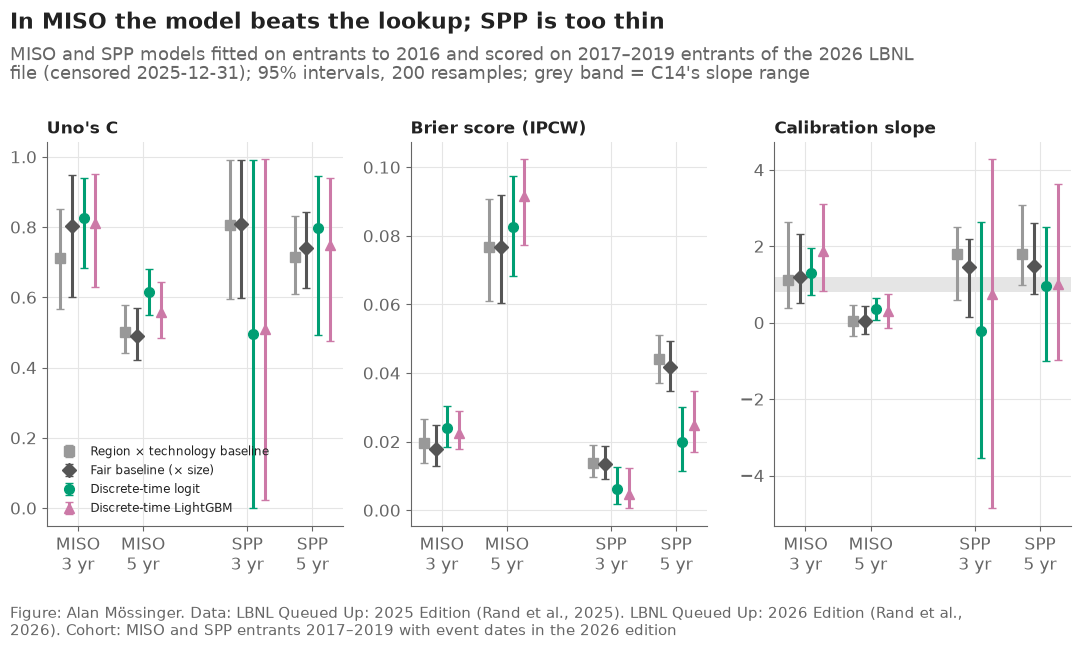

In [109]:
fig, axes = plt.subplots(1, 3, figsize=(11, 6.5))
style = {"baseline": ("#999999", "s"), "fair_baseline": ("#555555", "D"), "dt_logit": ("#009E73", "o"), "dt_lgbm": ("#CC79A7", "^")}
labels = {"baseline": "Region × technology baseline", "fair_baseline": "Fair baseline (× size)", "dt_logit": "Discrete-time logit", "dt_lgbm": "Discrete-time LightGBM"}
for ax, metric, title in zip(axes, ["uno_c", "brier", "slope"], ["Uno's C", "Brier score (IPCW)", "Calibration slope"]):
    for r_i, region in enumerate(REGIONS):
        for m_i, (model, (color, marker)) in enumerate(style.items()):
            part = metrics[(metrics["region"] == region) & (metrics["model"] == model) & (metrics["metric"] == metric)].set_index("horizon").loc[HORIZONS]
            x = np.array([0, 1]) + r_i * 2.6 + (m_i - 1.5) * 0.18
            ax.errorbar(x, part["estimate"], yerr=[part["estimate"] - part["low"], part["high"] - part["estimate"]], fmt=marker, color=color,
                        capsize=3, markersize=7, label=labels[model] if r_i == 0 else None)
    ax.set_xticks([0, 1, 2.6, 3.6], ["MISO\n3 yr", "MISO\n5 yr", "SPP\n3 yr", "SPP\n5 yr"])
    ax.set_title(title, fontsize=12)
    if metric == "slope":
        ax.axhspan(0.8, 1.2, color="#E5E5E5", zorder=0)
axes[0].legend(fontsize=8.5, loc="lower left")
mm = metrics.set_index(["region", "model", "metric", "horizon"])
plots.finish(fig,
             f"On the 2026 file, LightGBM's 5-year Uno's C is {mm.loc[('MISO', 'dt_lgbm', 'uno_c', 5), 'estimate']:.2f} in MISO and "
             f"{mm.loc[('SPP', 'dt_lgbm', 'uno_c', 5), 'estimate']:.2f} in SPP against the fair baseline's "
             f"{mm.loc[('MISO', 'fair_baseline', 'uno_c', 5), 'estimate']:.2f} and {mm.loc[('SPP', 'fair_baseline', 'uno_c', 5), 'estimate']:.2f}; "
             f"{n_pass} of {len(scored)} registered lines pass",
             f"MISO and SPP models fitted on entrants to 2016 and scored on 2017–2019 entrants of the 2026 LBNL file (censored 2025-12-31); "
             f"95% intervals, {N_BOOT} resamples; grey band = C14's slope range",
             "MISO and SPP entrants 2017–2019 with event dates in the 2026 edition", lbnl_2026=True)
plots.save_fig(fig, "F17_miso_spp", "Uno's C, Brier score and calibration slope of the MISO and SPP timing models at 3 and 5 years, with baselines.", NOTEBOOK)
plt.show()

**Reading this.** Three of the twelve registered lines pass: MISO's 5-year ranking (+0.067 [+0.008, +0.127] over the fair baseline) and SPP's two Brier lines, which say less about ranking than about the baselines' level. Every calibration line fails on width alone. The honest reading is that the 2026 file makes MISO and SPP timing models *possible* and the 2017–2019 cohorts make them *untestable* for now: the regions need two or three more years of dated outcomes before a verdict means anything. The report carries this as what it is — the method transfers, the evidence does not yet — and keeps the three-ISO verdict on the frozen file as the project's result.

## 4. Checks

In [110]:
criteria_written = (paths.RESULTS / "success_criteria_v3.csv").stat().st_mtime
metrics_written = (paths.RESULTS / "miso_spp_metrics.csv").stat().st_mtime
frozen_hash_after = hashlib.sha256((paths.DATA_PROCESSED / "predictions_trackA.parquet").read_bytes()).hexdigest()
checks = pd.DataFrame([
    {"check": "criteria file written before the metrics file", "value": round(metrics_written - criteria_written, 1), "pass": metrics_written > criteria_written},
    {"check": "the frozen pipeline's predictions are untouched", "value": frozen_hash_after[:12], "pass": frozen_hash_after == frozen_hash_before},
    {"check": "every metric row carries an interval", "value": int(metrics[["low", "high"]].isna().any(axis=1).sum()), "pass": not metrics[["low", "high"]].isna().any(axis=1).any()},
    {"check": "one scored row per registered line", "value": len(scored), "pass": len(scored) == len(CRITERIA_V3)},
    {"check": "F17 saved as PNG and SVG", "value": 2, "pass": (paths.FIGURES / "F17_miso_spp.png").exists() and (paths.FIGURES / "F17_miso_spp.svg").exists()},
])
checks.to_csv(paths.RESULTS / "miso_spp_checks.csv", index=False)
assert checks["pass"].all(), checks
print(f"total {(time.time() - START) / 60:.1f} min")
checks

total 0.1 min


,check,value,pass
0,criteria file written before the metrics file,7.5,True
1,the frozen pipeline's predictions are untouched,6e0850d09c32,True
2,every metric row carries an interval,0,True
3,one scored row per registered line,12,True
4,F17 saved as PNG and SVG,2,True


## Takeaways — Part K

- The 2026 file dates enough MISO and SPP outcomes to fit the models (5,169 and 2,191 usable requests), but the 2017–2019 test cohorts hold 54 and 8 operations within five years.
- 3 of 12 registered lines pass: MISO's 5-year ranking over the fair baseline (+0.067 [+0.008, +0.127]) and SPP's two Brier lines; every calibration line fails on interval width.
- MISO's models over-predict the level (Brier 0.092 against the baseline's 0.077 at 5 years) as the three-ISO models did; SPP's baselines over-predict it more.
- The frozen pipeline's predictions are untouched (hash checked); nothing here is pooled with the three-ISO verdict.
- **What goes to the report:** F17 and the scored table, as a registered extension whose evidence is not yet there; the data section's statement that MISO and SPP timing becomes testable around 2028.

## Takeaways

- **Part A** — Baseline predictor and cause-specific Cox models: its *Takeaways — Part A* cell above says what it found and what goes to the report.
- **Part B** — Discrete-time hazard models: its *Takeaways — Part B* cell above says what it found and what goes to the report.
- **Part C** — The all-regions model (Track B): will a request ever be built?: its *Takeaways — Part C* cell above says what it found and what goes to the report.
- **Part D** — A fair baseline and the utility-scale cohort: its *Takeaways — Part D* cell above says what it found and what goes to the report.
- **Part E** — Ten entry rules a company applies by hand (F21): its *Takeaways — Part E* cell above says what it found and what goes to the report.
- **Part F** — The newest evidence on the level: 2020–2022 entrants of the 2026 edition: its *Takeaways — Part F* cell above says what it found and what goes to the report.
- **Part G** — The level: cohort drift and its repair: its *Takeaways — Part G* cell above says what it found and what goes to the report.
- **Part H** — What post-entry information would add: the labelled leakage ablation: its *Takeaways — Part H* cell above says what it found and what goes to the report.
- **Part I** — Milestones after entry: the ISO queue files and the agreement dates: its *Takeaways — Part I* cell above says what it found and what goes to the report.
- **Part J** — Landmark models: what a later decision point knows: its *Takeaways — Part J* cell above says what it found and what goes to the report.
- **Part K** — MISO and SPP: timing models on the 2026 file (a registered extension): its *Takeaways — Part K* cell above says what it found and what goes to the report.

**What goes to the report.** Report figures drawn here: F10_gains_over_baselines, F21_segments, F11_level_by_entry_year, F12_landmark_models, F17_miso_spp. Every number the report cites from this notebook is read from `results/` by `src/report_numbers.py`.